# Adaptive non-Gaussian measurement flow in CV measurement-based quantum reservoir computing: a PRL preflight

## 1. Title and the precise permitted claim

**Question.** Does a minimal non-Gaussian resource, together with the *physically derived*, outcome-dependent byproduct correction it requires, activate a stable, readout-visible temporal response in a CV measurement-based quantum reservoir (CV-MB-QRC)? The response must be absent or suppressed in matched Gaussian, nonadaptive and conventional CV-QRC reservoirs.

**Hypothesis under test** (an *architectural* hypothesis, stated before any data):

> Gaussian measurement adaptivity permits nonlinear classical feedback. When it is driven predominantly by anti-squeezed teleportation fluctuations, however, it produces a weak or unstable task-visible response. A minimal non-Gaussian resource changes the measurement-flow algebra. Adaptive byproduct correction then activates stable temporal response components that are unavailable, or parametrically suppressed, in matched Gaussian, nonadaptive and conventional CV-QRC reservoirs.

**Strongest wording this notebook can ever print:**

> *Adaptive non-Gaussian measurement-based reservoir advantage over matched Gaussian, nonadaptive and conventional CV-QRC architectures.*

It can print this only after every gate in §22 passes in `research` mode. **No claim of quantum advantage over classical computation is made.** The Gaussian arms are efficiently classically simulable (Bartlett *et al.* 2002). The non-Gaussian arms at the cutoffs used here are simulated exactly on a laptop, so any win is an architectural statement about physical feature generation, not a complexity separation.

**Arms.**

| label | resource per clock | measurement flow |
|---|---|---|
| G–NA | Gaussian cluster | fixed (input-encoding) bases; displacement feedforward only |
| G–AD | Gaussian cluster | within-pattern adaptive basis (bounded outcome feedback of the preregistered controller variant) |
| NG–NA | same pattern plus one cubic-phase resource | displacement and $Z$ feedforward only; the outcome-dependent quadratic-phase byproduct is left uncorrected (preregistered nonadaptive control) |
| NG–AD | same cubic resource | physically derived correction $P[-2\gamma m]$ applied through the next measurement basis |
| CV-QRC | — | conventional optical-loop reservoir (García-Beni *et al.* 2023), Piquasso |

Ordinary displacement feedforward (the Pauli-frame correction of teleportation) is present in **every** MB arm. It is *not* called "adaptive measurement". Adaptive measurement means that a later homodyne basis depends causally on an earlier outcome of the same clock's pattern.

**Labels.** Operations: *native engine operation*, *compiled through the engine*, *exact adapter*, *approximate adapter*, *idealized model*. Results: *established literature*, *adaptation of literature*, *new definition*, *new conjecture*, *numerical observation*.

**Modes.** `unit` (tests only, no conclusions) · `research_dryrun` (every branch at toy size, control flow only) · `preflight` (the real structural pilot and GO/NO-GO) · `research` (refuses to start without a matching preflight `GO`).

In [1]:
# ======================== USER CONTROL PANEL — CHANGE ONLY THIS CELL ========================
import os

RUN_MODE = "preflight"
# RUN_MODE = "unit"
# RUN_MODE = "research_dryrun"
# RUN_MODE = "research"
RUN_MODE = os.environ.get("ANG_RUN_MODE", RUN_MODE)      # optional non-interactive override for batch execution; normally unset

RESUME_FROM_CHECKPOINT = True
PREFER_GPU = True
BLAS_THREADS = None
MASTER_SEED = 20261004
CHECKPOINT_DIR = "./adaptive_nongaussian_checkpoints"
RESULTS_DIR = "./adaptive_nongaussian_results"
AVAILABLE_RUNTIME_HOURS = 72

# six disjoint seed banks (start, size); every use is recorded in the seed ledger
SEED_BANKS = dict(calibration=(1_000_000, 200), exploration=(2_000_000, 200), validation=(3_000_000, 200),
                  pilot=(4_000_000, 200), confirmation=(9_000_000, 200), robustness=(5_000_000, 200))

PREREGISTERED = dict(
    # architecture: controller variants (declared before any data) and the selection rule
    variants=("V1", "V2", "V3"),
    variant_rule="largest exploration chi_wh^x among physical, stable, converged variants at the Level-A screening points; no task data",
    g_feedback=0.2,                 # V2/V3 bounded feedback gain
    filter_lambda=0.5,              # V3 exponential filter of past outcomes
    theta_min=0.15,                 # safe-angle reporting threshold |sin(theta)| >= sin(theta_min)
    # stability
    boundary_escape=1e-3,           # a trajectory escapes if the top-two-Fock-level population exceeds this
    energy_bound_frac=0.35,         # ... or its mean photon number exceeds this fraction of the LARGEST preflight cutoff (fixed bound; repair R2)
    escape_tol_realization=0.01,    # a reservoir realization is unstable if its escape rate exceeds this
    escape_upper=0.01,              # hierarchical 95% upper bound on the mean escape rate must be below this
    unstable_frac_upper=0.10,       # Clopper-Pearson 95% upper bound on the unstable-realization fraction (used only when n >= 29; repair R1)
    # convergence
    cutoff_rel_change=0.02, boundary_pop_max=1e-5,
    # structural mechanism
    snr_screen=3.0, snr_int=3.0, snr_wh=5.0, snr_second=3.0, ctrl_margin_se=3.0,
    whitening_eps_rel=1e-6, ridge_struct_rel=1e-3,
    # physics and implementation tolerances
    trace_tol=1e-10, herm_tol=1e-10, mineig_tol=-1e-9, prob_norm_tol=1e-8, native_tol=1e-8, gpu_tol=1e-8,
    # statistics
    alpha=0.05, fdr_q=0.05, power_target=0.9, delta_min_floor=0.02,
    sample_cost_max_shots=1_000_000,   # accepted shots per feature estimate needed for whitened SNR 5 must stay below this
)

BASE = dict(squeezing_db=12.0, enc_scale=0.6, beta_scale=0.5, loop_transmissivity=1.0, layer_efficiency=1.0,
            tap_efficiency=1.0, homodyne_resolution=0.0, ff_gain_error=0.0, resource_squeezing_db=6.0,
            resource_loss=1.0, coupling_w=0.5)
# physical Level-B condition (preregistered): finite squeezing, loss, detector efficiency, resolution and feed-forward error all present
BASE_B = dict(BASE, loop_transmissivity=0.98, layer_efficiency=0.95, tap_efficiency=0.95, homodyne_resolution=0.01, ff_gain_error=0.01, resource_loss=0.98)

_C = dict(N_main=1, N_second=2, level_a_gammas=[0.1, 0.2, 0.3], level_a_T=0.5, n_screen=3,
          gamma_grid=[0.0, 0.1, 0.2], T_grid=[0.5], cutoffs=[12, 16], D_second=10, D_res=24, tap_grid=160,
          suppression_db=[3.0, 6.0, 9.0, 12.0], n_calib=2, calib_paths=256, calib_clocks=60,
          n_explore=2, n_validate=2, kernel_paths=64, kernel_hist=6, kernel_nodes=4, kernel_blocks=8,
          stab_paths=64, stab_clocks=60, lyap_len=60, lyap_burn=20, lyap_qr=5, lyap_traj=1, chan_k=4, td_len=40,
          washout=50, train=300, test=150, shots=32, n_pilot=3, n_confirm=3, robust_n=2,
          squeezing_grid=[9.0, 12.0, 15.0], loss_grid=[1.0, 0.95, 0.9], eta_grid=[1.0, 0.9, 0.8], shots_grid=[16, 32, 64],
          ff_grid=[0.0, 0.02], resolution_grid=[0.0, 0.05], resource_db_grid=[3.0, 6.0, 9.0],
          ridge_grid=[1e-8, 1e-6, 1e-4, 1e-2, 1.0, 100.0], poly_pca_dim=8, bootstrap=400, power_sims=2000, native_cutoffs=[24, 32])
CONFIGS = {
    "unit": dict(_C),
    "research_dryrun": dict(_C, gamma_grid=[0.0, 0.1, 0.2, 0.3], T_grid=[0.4, 0.6], n_explore=2, n_validate=2, n_pilot=3, n_confirm=3),
    "preflight": dict(_C, level_a_gammas=[0.1, 0.2, 0.3], n_screen=4, gamma_grid=[0.0, 0.05, 0.1, 0.2, 0.3, 0.45], T_grid=[0.3, 0.5, 0.7, 0.85],
                      cutoffs=[16, 20, 24], D_second=12, D_res=60, tap_grid=200, n_calib=4, calib_paths=1024, calib_clocks=200,
                      n_explore=4, n_validate=12, kernel_paths=1024, kernel_hist=10, kernel_blocks=16, stab_paths=512, stab_clocks=300,
                      lyap_len=300, lyap_burn=50, lyap_traj=2, chan_k=8, td_len=150, washout=200, train=1500, test=700,
                      shots=256, n_pilot=12, robust_n=4, shots_grid=[64, 256, 1024], ff_grid=[0.0, 0.02, 0.05], resolution_grid=[0.0, 0.01, 0.05],
                      ridge_grid=[1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0], poly_pca_dim=9,
                      bootstrap=3000, power_sims=10000, native_cutoffs=[24, 36, 48, 60]),
    "research": dict(_C, level_a_gammas=[0.1, 0.2, 0.3], n_screen=8, gamma_grid=[0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.45, 0.6],
                     T_grid=[0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.85], cutoffs=[20, 24, 28], D_second=14, D_res=80, tap_grid=240,
                     n_calib=10, calib_paths=2048, calib_clocks=400, n_explore=30, n_validate=30, kernel_paths=2048, kernel_hist=12,
                     kernel_blocks=32, stab_paths=1024, stab_clocks=1000, lyap_len=1500, lyap_burn=200, lyap_traj=8, chan_k=12, td_len=300,
                     washout=200, train=6000, test=3000, shots=1024, n_pilot=15, n_confirm=50, robust_n=20,
                     shots_grid=[256, 1024, 4096], ff_grid=[0.0, 0.02, 0.05], resolution_grid=[0.0, 0.01, 0.05],
                     ridge_grid=[1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0], poly_pca_dim=9,
                     bootstrap=5000, power_sims=10000, native_cutoffs=[24, 36, 48]),
}
assert RUN_MODE in CONFIGS, f"RUN_MODE must be one of {list(CONFIGS)}"
assert all(set(c) == set(CONFIGS["unit"]) for c in CONFIGS.values()), "every configuration must define the same keys"
CFG = dict(CONFIGS[RUN_MODE])
print(f"RUN_MODE = {RUN_MODE!r}")

RUN_MODE = 'preflight'


## 2. Audit of the predecessor notebooks

The audit reads every source notebook found under the working directory: code, markdown, stored outputs and metadata. It also looks for the PhotoGraphiQ and PhotoGraphiQML repositories under the working directory and its parent. It hashes every file, and extracts the stored results **programmatically** from saved outputs, never from memory. No source file is modified.

**What the predecessors established (each line is re-extracted below):**

| predecessor | design | stored outcome | lesson used here |
|---|---|---|---|
| `adaptive_cv_mbqrc_advantage_preflight_colab.ipynb` | *inter-clock* Gaussian feedback (tap outcome of clock $k-1$ steers clock $k$) | `NO-GO`; adaptive susceptibility SNR 0.79; quadratic post-processing of NA features beat AD | inter-clock feedback is not MBQC adaptivity |
| `adaptive_cv_mbqrc_within_pattern_lyapunov_preflight_colab.ipynb` | *within-pattern* Gaussian adaptivity (layer-$j$ angle from layer-$(j-1)$ outcomes of the same clock) | `NO-GO` (structural): validation escapes at the lock; $\chi_{\rm int}$ SNR 2.38, $\chi^{\rm wh}_{\rm vis}$ SNR 1.86; FSS crossover | teleportation outcomes are dominated by anti-squeezed noise ($\sigma_m\approx4$ at 12 dB). A Gaussian controller mostly injects that noise. This motivates the present hypothesis |
| `unified_bosonic_eoc_dv_cv_mbqrc_colab.ipynb` | DV / CV / CV-MB edge-of-chaos study, incl. an ideal-logical-Kerr MB reservoir ("MBK") and a non-Gaussian route audit | no resource-matched quantum advantage for any engine; MBK hypotheses `evidence against` | an ideal logical non-Gaussian gate alone did not help; here the non-Gaussian resource enters *through the measurement flow* |

In [2]:
import hashlib as _hl, json as _json, re as _re
from pathlib import Path as _P
import pandas as _pd
from IPython.display import display

SOURCE_NAMES = ["unified_bosonic_eoc_dv_cv_mbqrc_colab(2).ipynb", "unified_bosonic_eoc_dv_cv_mbqrc_colab.ipynb",
                "adaptive_cv_mbqrc_within_pattern_lyapunov_preflight_colab.ipynb", "adaptive_cv_mbqrc_advantage_preflight_colab.ipynb"]
_SKIP = {".git", ".venv", "venv", "site-packages", "node_modules", "__pycache__", ".ipynb_checkpoints", "Lib", "lib"}

def _walk(root, depth):
    root = _P(root)
    try:
        entries = list(root.iterdir())
    except OSError:
        return
    for e in entries:
        yield e
        if depth > 0 and e.is_dir() and e.name not in _SKIP and "checkpoint" not in e.name and not e.name.startswith("."):
            yield from _walk(e, depth - 1)

def _sha(p):
    h = _hl.sha256()
    with open(p, "rb") as fh:
        for blk in iter(lambda: fh.read(1 << 20), b""):
            h.update(blk)
    return h.hexdigest()

_found = {}
for e in _walk(_P.cwd(), 4):
    if e.is_file() and e.name in SOURCE_NAMES and e.name not in _found:
        _found[e.name] = e
_repos = {}
for e in _walk(_P.cwd().parent, 6):
    if e.is_dir() and e.name in ("PhotoGraphiQ", "PhotoGraphiQML") and (e / "pyproject.toml").exists() and e.name not in _repos:
        _repos[e.name] = e
_cv_qrc = [e for e in _walk(_P.cwd(), 2) if e.is_file() and e.suffix == ".ipynb" and "piquasso" in e.name.lower()]
HASH_ROWS = []
for n in SOURCE_NAMES:
    p = _found.get(n)
    HASH_ROWS.append(dict(file=n, present=p is not None, path=str(p) if p else "not found", sha256=_sha(p)[:16] if p else "-",
                          bytes=p.stat().st_size if p else 0))
for e in _cv_qrc:
    HASH_ROWS.append(dict(file=e.name, present=True, path=str(e), sha256=_sha(e)[:16], bytes=e.stat().st_size))
for n in ("PhotoGraphiQ", "PhotoGraphiQML"):
    p = _repos.get(n)
    commit = "-"
    if p is not None and (p / ".git").exists():
        try:
            import subprocess as _sp
            commit = _sp.run(["git", "-C", str(p), "rev-parse", "HEAD"], capture_output=True, text=True, timeout=20).stdout.strip()[:16] or "-"
        except Exception:                                                  # noqa: BLE001
            commit = "git unavailable"
    HASH_ROWS.append(dict(file=f"{n} (repository)", present=p is not None, path=str(p) if p else "not found under the parent directory",
                          sha256=f"commit {commit}", bytes=0))
HASH_DF = _pd.DataFrame(HASH_ROWS)
with _pd.option_context("display.max_colwidth", 90, "display.width", 250):
    display(HASH_DF)

def _stream(path):
    nb = _json.loads(_P(path).read_text(encoding="utf-8")); txt = []
    for c in nb["cells"]:
        for o in c.get("outputs", []):
            if o["output_type"] == "stream":
                txt.append("".join(o["text"]))
            elif "text/plain" in o.get("data", {}):
                txt.append("".join(o["data"]["text/plain"]))
    return "\n".join(txt), nb.get("metadata", {}), len(nb["cells"])

_PATTERNS = {
    "adaptive_cv_mbqrc_within_pattern_lyapunov_preflight_colab.ipynb": {
        "decision": r"=== DECISION \(preflight\): ([A-Z\- ]+?) ===", "chi_int SNR (validation)": r"chi_int SNR \(validation\) ([\d.]+)",
        "chi_vis^wh SNR (validation)": r"chi_vis\^wh SNR ([\d.]+) \(validation\)", "locked g*": r'"g_star": ([\d.]+)', "locked T*": r'"T_star": ([\d.]+)',
        "validation escape bound": r"validation escape bound: ([\d.]+)", "FSS verdict": r"finite-size scaling: \{'verdict': '([^']+)'"},
    "adaptive_cv_mbqrc_advantage_preflight_colab.ipynb": {
        "decision": r"DECISION[^:\n]*:\s*([A-Z][A-Z\- ]+)", "final verdict line": r"(NO-GO[^\n]{0,160})"},
    "unified_bosonic_eoc_dv_cv_mbqrc_colab.ipynb": {
        "verdict counts": r"verdict counts: (\{[^}]*\})", "resource-matched quantum advantage": r"resource-matched quantum advantage[^:]*: (\{[^}]*\})",
        "MBK verdicts": r"'(H\d-MBK)': '([^']+)'"},
}
AUDIT_ROWS = []
for name, pats in _PATTERNS.items():
    p = _found.get(name)
    if p is None:
        AUDIT_ROWS.append(dict(source=name, item="(file)", extracted="NOT FOUND")); continue
    txt, meta, ncell = _stream(p)
    AUDIT_ROWS.append(dict(source=name, item="cells / kernel", extracted=f"{ncell} / {meta.get('kernelspec', {}).get('name', '?')}"))
    for item, pat in pats.items():
        hits = _re.findall(pat, txt)
        if item == "MBK verdicts":
            val = "; ".join(f"{a}: {b}" for a, b in dict(hits).items()) if hits else "not found"
        else:
            val = (hits[-1] if isinstance(hits[-1], str) else " ".join(hits[-1])).strip() if hits else "not found"
        AUDIT_ROWS.append(dict(source=name, item=item, extracted=val[:200]))
AUDIT_DF = _pd.DataFrame(AUDIT_ROWS)
with _pd.option_context("display.max_colwidth", 140, "display.width", 250):
    display(AUDIT_DF)
SOURCE_AUDIT_OK = all(r["present"] for r in HASH_ROWS if r["file"] in SOURCE_NAMES[1:])
print("missing source files:", [r["file"] for r in HASH_ROWS if not r["present"]] or "none",
      "| predecessor notebooks found:", SOURCE_AUDIT_OK)

,file,present,path,sha256,bytes
0,unified_bosonic_eoc_dv_cv_mbqrc_colab(2).ipynb,False,not found,-,0
1,unified_bosonic_eoc_dv_cv_mbqrc_colab.ipynb,True,D:\Research\QML\results_1\photonic-qrc-eoc\unified_bosonic_eoc_dv_cv_mbqrc_colab.ipynb,3a1da5f1859e72b5,3748442
2,adaptive_cv_mbqrc_within_pattern_lyapunov_preflight_colab.ipynb,True,D:\Research\QML\results_1\photonic-qrc-eoc\adaptive_cv_mbqrc_within_pattern_lyapunov_p...,e9d55f01d9d6092a,1669940
3,adaptive_cv_mbqrc_advantage_preflight_colab.ipynb,True,D:\Research\QML\results_1\photonic-qrc-eoc\adaptive_cv_mbqrc_advantage_preflight_colab...,81c8615bd6d79bfe,1347378
4,garcia_beni_cv_qrc_piquasso_colab.ipynb,True,D:\Research\QML\results_1\photonic-qrc-eoc\garcia_beni_cv_qrc_piquasso_colab.ipynb,609243ce5bcbfaef,1866353
5,PhotoGraphiQ (repository),True,D:\Research\QML\results_1\cvqc\thesis_part_2\softwares\PhotoGraphiQ,commit 4d63c5ef867fa60d,0
6,PhotoGraphiQML (repository),True,D:\Research\QML\results_1\cvqc\thesis_part_2\softwares\PhotoGraphiQML,commit 418c4601d578a6b5,0


,source,item,extracted
0,adaptive_cv_mbqrc_within_pattern_lyapunov_preflight_colab.ipynb,cells / kernel,65 / python3
1,adaptive_cv_mbqrc_within_pattern_lyapunov_preflight_colab.ipynb,decision,NO-GO
2,adaptive_cv_mbqrc_within_pattern_lyapunov_preflight_colab.ipynb,chi_int SNR (validation),2.38
3,adaptive_cv_mbqrc_within_pattern_lyapunov_preflight_colab.ipynb,chi_vis^wh SNR (validation),1.86
4,adaptive_cv_mbqrc_within_pattern_lyapunov_preflight_colab.ipynb,locked g*,0.3
5,adaptive_cv_mbqrc_within_pattern_lyapunov_preflight_colab.ipynb,locked T*,0.6
6,adaptive_cv_mbqrc_within_pattern_lyapunov_preflight_colab.ipynb,validation escape bound,0.3322
7,adaptive_cv_mbqrc_within_pattern_lyapunov_preflight_colab.ipynb,FSS verdict,"finite-size crossover (best scaling fit unphysical: g_c outside the scanned range or nu, z out of bounds)"
8,adaptive_cv_mbqrc_advantage_preflight_colab.ipynb,cells / kernel,63 / python3
9,adaptive_cv_mbqrc_advantage_preflight_colab.ipynb,decision,NO-GO


missing source files: ['unified_bosonic_eoc_dv_cv_mbqrc_colab(2).ipynb'] | predecessor notebooks found: True


## 3. Literature phase transitions versus the new QRC hypothesis

Three different kinds of statement must not be conflated:
1. a **phase transition proved in a cited model**;
2. a **numerical realization of that same model and order parameter**;
3. a **new hypothesis** that such a transition affects reservoir computation.

This notebook makes no statement of kind 2, and tests only a statement of kind 3 for a different model.

### 3.1 Phase-transition claims in the literature

| literature model | state family | control parameter | order parameter | thermodynamic / size limit | what is proved (or shown) | present-model correspondence |
|---|---|---|---|---|---|---|
| Browne, Elliott, Flammia, Merkel, Miyake, Short, *NJP* **10**, 023010 (2008) | 2D qubit cluster states built from faulty (heralded-loss) sites | site/bond occupation probability | existence of a spanning cluster, which decides efficient concentration to a universal resource | infinite lattice | a transition in the *computational power* of the resource at the percolation threshold (classically simulable below, universal above) | **none**: qubit lattice, percolation control parameter; the present model is a 1–2-mode CV loop |
| Darmawan, Brennen, Bartlett, *NJP* **14**, 013023 (2012) | ground states of a deformed spin-3/2 AKLT model on the honeycomb lattice | Hamiltonian deformation | phase membership (valence-bond-solid phase) | infinite lattice | MBQC remains possible in an extended region of the disordered phase | **none** |
| Raussendorf, Okay, Wang, Stephen, Poulsen Nautrup, *PRL* **122**, 090501 (2019) | 2D symmetry-protected phase with line-like symmetries | any symmetric perturbation within the phase | phase membership | infinite lattice | every ground state in the phase is a universal MBQC resource | **none**; universality is not reservoir performance |
| Iaconis, Lucas, Chen, *PRB* **102**, 224311 (2020) | monitored quantum automaton circuits | measurement rate | entanglement entropy / purification | system size → ∞ | measurement-induced transition, mapped to a classical bit-string model | **none** (no qubit chain, no extensive entanglement here) |
| Mochizuki, Hamazaki, *PRL* **134**, 010410 (2025) | many-body dynamics under generalized measurements | measurement strength | gap of the Lyapunov spectrum of the dynamics | system size → ∞ | spectral transition between gapless and gapped Lyapunov spectra | **observable only**: §14 computes Lyapunov spectra and gaps, but of a 1–2-mode system with no size limit |
| Wu *et al.*, *PRL* **137**, 010401 (2026) | monitored, feedback-driven qubit circuits (experiment) | feedback / measurement rates | absorbing-state density and trajectory entanglement | finite processor + scaling | channel absorbing-state transition coexisting with a measurement-induced trajectory transition | **observable only**: motivates separating channel from trajectory spectra (§14) |

**Statement for this notebook.**

> The literature transition motivates the architecture, but the present calculation tests a new finite-size computational crossover.

No literature theorem is transferred to the present state family, measurement pattern or noise model. MBQC universality is *not* used as evidence of improved QRC performance. Any boundary found in §16 is a **numerical observation** of a finite-size crossover.

### 3.2 Literature for the cubic-phase measurement flow (used, with derivation)

| source | established result | use here | label |
|---|---|---|---|
| Lloyd, Braunstein, *PRL* **82**, 1784 (1999) | a non-Gaussian (e.g. cubic) Hamiltonian plus Gaussian operations is universal for CV | motivation for one cubic resource | established literature |
| Gottesman, Kitaev, Preskill, *PRA* **64**, 012310 (2001) | cubic phase gate by teleportation from a cubic-phase resource; the correction is outcome-dependent and Gaussian | the byproduct structure, re-derived in §6 in PhotoGraphiQ/Piquasso conventions | adaptation of literature |
| Gu, Weedbrook, Menicucci, Ralph, van Loock, *PRA* **79**, 062318 (2009) | CV cluster-state MBQC; non-Gaussian gates need adaptive measurement bases | the adaptive-basis implementation of $P[-2\gamma m]$ | established literature |
| Miyata *et al.*, *PRA* **93**, 022301 (2016) | a cubic gate implemented through an adaptive non-Gaussian measurement | physical motivation for Level B | established literature |
| Ghose, Sanders, *J. Mod. Opt.* **54**, 855 (2007); Yukawa *et al.*, *PRA* **88**, 053816 (2013) | finite-energy, Fock-truncated approximations to cubic-phase states | the finite-cutoff resource of Level B | established literature |
| Bartlett, Sanders, Braunstein, Nemoto, *PRL* **88**, 097904 (2002); Mari, Eisert, *PRL* **109**, 230503 (2012) | Gaussian processes are efficiently simulable; Wigner negativity is necessary for an exponential advantage | the "no quantum advantage claim" statement; non-Gaussianity certification in §13 | established literature |
| Genoni, Paris, Banaszek, *PRA* **76**, 042327 (2007); Genoni, Paris, *PRA* **82**, 052341 (2010); Kenfack, Życzkowski, *J. Opt. B* **6**, 396 (2004) | non-Gaussianity measures (Hilbert–Schmidt / relative entropy); Wigner-negativity volume | estimators of §13 | established literature |
| Morguí-Sancho *et al.*, arXiv:2607.14311 (2026); Cao *et al.*, arXiv:2609.23429 (2026) | monitored-QRC theory; the response-to-performance chain (internal → visible → resolvable) | the $\chi_{\rm int}\to\chi_{\rm vis}\to\chi_{\rm wh}\to\chi_{\rm res}$ chain of §15 | adaptation of literature |
| García-Beni *et al.*, *Phys. Rev. Applied* **20**, 014051 (2023); *EPJ Quantum Technol.* **12**, 63 (2025) | photonic CV-QRC; nonadaptive Gaussian MB-QRC | CV-QRC comparator; MB base architecture | established literature |
| — this notebook | the four-arm factorial design, the adaptive–non-Gaussian interaction kernel $K^\times$, the Gaussian adaptive-suppression bound, the $(\gamma,T)$ structural map | — | new definitions / new conjecture / numerical observations |

## 4. Reproducibility manifest and pinned environment

### 4.1 Installation with pinned versions
Piquasso is pinned to 8.0.1. PhotoGraphiQ is pinned to the commit used by the source notebooks (`6d49da06…`, branch `manuscript-experiments`). On Colab it is cloned and installed; locally an existing installation is used and its commit is recorded. PhotoGraphiQML was inspected (§2) and is **not** needed: the readout is closed-form ridge regression, and its MuTA models are qubit ansätze. PhotoGraphiQ supplies native Fock execution (pure `piquasso-fock` and mixed `piquasso-mixed-fock`), the cubic-phase resource, `cubic_injection`, outcome-dependent homodyne angles and causal validation.

In [3]:
import sys, subprocess, importlib, importlib.util, importlib.metadata as _md, platform, json, hashlib, time, uuid, math, zlib
import pickle, warnings, contextlib, itertools, shutil, copy, re
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content/sample_data")

def _ver(dist):
    try:
        return _md.version(dist)
    except _md.PackageNotFoundError:
        return None

def _sh(*cmd, check=True):
    return subprocess.run(cmd, check=check, capture_output=True, text=True).stdout.strip()

PG_URL, PG_COMMIT = "https://github.com/chinmoybiswasdeep/PhotoGraphiQ.git", "6d49da06fa6ede78bf06ea1df07ccfb3b4f5250e"
_need = [] if _ver("piquasso") == "8.0.1" else ["piquasso==8.0.1"]
_need += [p for p, m in [("pandas", "pandas"), ("matplotlib", "matplotlib"), ("networkx", "networkx"), ("psutil", "psutil"),
                         ("scipy", "scipy"), ("threadpoolctl", "threadpoolctl")] if importlib.util.find_spec(m) is None]
if _need:
    print("pip install:", " ".join(_need))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_need], check=True)
if importlib.util.find_spec("photographiq") is None:
    _root = Path("/content/ang_repos" if IN_COLAB else "ang_repos").resolve() / "PhotoGraphiQ"
    if not (_root / ".git").exists():
        _root.parent.mkdir(parents=True, exist_ok=True)
        _sh("git", "-c", "core.longpaths=true", "clone", "--quiet", "--no-checkout", PG_URL, str(_root))
        _sh("git", "-C", str(_root), "config", "core.longpaths", "true")
        _sh("git", "-C", str(_root), "-c", "advice.detachedHead=false", "checkout", "--quiet", PG_COMMIT)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", str(_root)], check=True)
    importlib.invalidate_caches()
if IN_COLAB and importlib.util.find_spec("cupy") is None and shutil.which("nvidia-smi"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cupy-cuda12x"], check=False)

def _pg_commit():
    """Commit of the installed PhotoGraphiQ, from PEP 610 direct_url.json -> git, else 'unknown'."""
    try:
        url = json.loads(_md.distribution("photographiq").read_text("direct_url.json"))["url"]
        path = Path(re.sub(r"^file:/+", "", url).replace("%20", " "))
        path = path if path.exists() else Path("/" + str(path))
        return _sh("git", "-C", str(path), "rev-parse", "HEAD", check=False) or "unknown (no git metadata)", str(path)
    except Exception as exc:                                            # noqa: BLE001
        return f"unknown ({type(exc).__name__})", "?"
PG_INSTALLED_COMMIT, PG_SOURCE_PATH = _pg_commit()
print("PhotoGraphiQ commit:", PG_INSTALLED_COMMIT, "| pinned:", PG_COMMIT, "| match:", PG_INSTALLED_COMMIT == PG_COMMIT)

PhotoGraphiQ commit: 6d49da06fa6ede78bf06ea1df07ccfb3b4f5250e | pinned: 6d49da06fa6ede78bf06ea1df07ccfb3b4f5250e | match: True


### 4.2 Imports, machine and software provenance

In [4]:
# A fresh numba cache per session: re-loading Piquasso's cached numba functions in a second process crashed the kernel here
# ("LLVM ERROR: Symbol not found: ...hessenberg..."); compiling fresh in every session avoids it (costs a few seconds).
import tempfile
os.environ["NUMBA_CACHE_DIR"] = tempfile.mkdtemp(prefix="ang_numba_")
import numpy as np, scipy, scipy.linalg as sla, scipy.stats as sst, scipy.special as ssp
import pandas as pd, matplotlib, matplotlib.pyplot as plt, networkx as nx, psutil, threadpoolctl
from numpy.polynomial import legendre as npleg
from IPython.display import display, Markdown
import piquasso as pq
import photographiq as pg
from photographiq.backends import GaussianBackend

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)   # boundary/escape events are detected, counted and reported explicitly (test N11)
if BLAS_THREADS:
    _BLAS = threadpoolctl.threadpool_limits(int(BLAS_THREADS), user_api="blas")
SESSION_ID, NOTEBOOK_T0 = uuid.uuid4().hex[:12], time.perf_counter()
CKPT = Path(CHECKPOINT_DIR).resolve() / RUN_MODE
RES = Path(RESULTS_DIR).resolve() / RUN_MODE
for _d in (CKPT, RES, RES / "figures"):
    _d.mkdir(parents=True, exist_ok=True)

def _cpu_model():
    try:
        if platform.system() == "Windows":
            return _sh("powershell", "-NoProfile", "-Command", "(Get-CimInstance Win32_Processor).Name", check=False).splitlines()[0].strip()
        for line in open("/proc/cpuinfo"):
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    except Exception:                                                    # noqa: BLE001
        pass
    return platform.processor() or "unknown"

def _nvidia():
    exe = shutil.which("nvidia-smi")
    if not exe:
        return {}
    q = _sh(exe, "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader", check=False).split(",")
    cuda = re.search(r"CUDA Version:\s*([\d.]+)", _sh(exe, check=False))
    return dict(gpu=q[0].strip(), vram=q[1].strip(), driver=q[2].strip(), cuda_driver_api=cuda.group(1) if cuda else "?") if len(q) == 3 else {}

_vm = psutil.virtual_memory(); NV = _nvidia()
ENV = {"session": SESSION_ID, "run mode": RUN_MODE, "location": "Google Colab" if IN_COLAB else "local",
       "OS": platform.platform(), "python": platform.python_version(), "CPU": _cpu_model(),
       "cores (physical/logical)": f"{psutil.cpu_count(logical=False)}/{psutil.cpu_count()}", "RAM (GB)": round(_vm.total / 2**30, 1),
       "free disk at results dir (GB)": round(shutil.disk_usage(RES).free / 2**30, 1),
       "GPU": NV.get("gpu", "none detected"), "VRAM": NV.get("vram", "-"), "driver": NV.get("driver", "-"),
       "CUDA (driver API)": NV.get("cuda_driver_api", "-"),
       "numpy": np.__version__, "scipy": scipy.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__,
       "Piquasso": pq.__version__, "PhotoGraphiQ": f"{pg.__version__} @ {PG_INSTALLED_COMMIT}",
       "CuPy": _ver("cupy-cuda12x") or _ver("cupy") or "not installed",
       "PyTorch": _ver("torch") or "not installed (not needed)", "JAX": _ver("jax") or "not installed (not needed)",
       "BLAS": ", ".join(f"{d['internal_api']}:{d['num_threads']}" for d in threadpoolctl.threadpool_info() if d["user_api"] == "blas")}
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(ENV.items(), columns=["item", "value"]).set_index("item"))

,value
item,
session,8db06616215f
run mode,preflight
location,local
OS,Windows-11-10.0.26200-SP0
python,3.12.14
CPU,12th Gen Intel(R) Core(TM) i5-12450HX
cores (physical/logical),8/12
RAM (GB),23.7
free disk at results dir (GB),30.7


### 4.3 GPU inventory and CuPy smoke test
The engine-level CPU/GPU benchmark and the agreement test are in §10, once the engine exists. Here we only check that CUDA works. PyTorch and JAX are detected but not used: kernels come from Gauss–Legendre projections with common random numbers, and Lyapunov tangents from analytic or finite-difference Jacobians (§14–15).

In [5]:
def _register_cuda_wheel_dlls():
    if platform.system() != "Windows":
        return
    import site
    for sp in site.getsitepackages() + [site.getusersitepackages()]:
        for d in Path(sp).glob("nvidia/*/bin"):
            os.add_dll_directory(str(d)); os.environ["PATH"] = str(d) + os.pathsep + os.environ.get("PATH", "")

CUPY_OK, CUPY_INFO = False, "not attempted (PREFER_GPU=False)"
if PREFER_GPU:
    try:
        _register_cuda_wheel_dlls()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            import cupy as cp
        _a = cp.asarray(np.random.default_rng(0).normal(size=(64, 8, 8)))
        _err = float(np.abs(cp.asnumpy(cp.linalg.cholesky(_a @ _a.transpose(0, 2, 1) + 8 * cp.eye(8)))
                            - np.linalg.cholesky(cp.asnumpy(_a @ _a.transpose(0, 2, 1)) + 8 * np.eye(8))).max())
        props = cp.cuda.runtime.getDeviceProperties(0)
        CUPY_INFO = dict(device=props["name"].decode() if isinstance(props["name"], bytes) else str(props["name"]),
                         vram_gb=round(props["totalGlobalMem"] / 2**30, 2), cuda_runtime=cp.cuda.runtime.runtimeGetVersion(),
                         cupy=cp.__version__, batched_cholesky_err=_err)
        CUPY_OK = _err < 1e-10
    except Exception as exc:                                              # noqa: BLE001
        CUPY_INFO = f"no usable GPU: {type(exc).__name__}: {str(exc)[:200]}"
print("CuPy usable:", CUPY_OK, "|", CUPY_INFO)

CuPy usable: True | {'device': 'NVIDIA GeForce RTX 4050 Laptop GPU', 'vram_gb': 6.0, 'cuda_runtime': 12090, 'cupy': '13.6.0', 'batched_cholesky_err': 8.881784197001252e-16}


### 4.4 Seeds, checkpoint store, test registry, timing and figure metadata
* **Seeds.** Every random stream is `default_rng([MASTER_SEED, crc32(tag)…])`. A realization is one integer from a seed bank, and every stream it uses (reservoir parameters, CV networks, inputs, innovations, detector noise) is derived from it. Innovations are drawn on the host, so CPU and GPU runs consume identical random numbers.
* **Checkpoints.** One pickle per finished unit (realization × parameter point), keyed by a hash of its parameters and the engine version. Writes are atomic (temporary file + `os.replace`). A failed unit is stored with its reason, so it is counted and never silently dropped.
* **Seed ledger.** `seed_ledger.json` records which bank indices each stage consumed. Before the confirmatory stage the ledger is checked for prior use of confirmatory seeds.

In [6]:
ENGINE_VERSION = "ang-1.1"      # 1.1: repaired stability statistics (R1, R2); every unit recomputed
ENGINE_VERSION_NOTE = "ang-1.1"      # adaptive non-Gaussian DVR/Fock engine

def rng_for(*tags):
    return np.random.default_rng([MASTER_SEED] + [zlib.crc32(repr(t).encode()) for t in tags])

class CheckpointStore:
    def __init__(self, root, resume=True):
        self.root, self.resume = Path(root), resume
        self.root.mkdir(parents=True, exist_ok=True)
        self.hits = self.misses = self.failures = 0
        self.compute_s = 0.0

    @staticmethod
    def key(name, params):
        blob = json.dumps({"engine": ENGINE_VERSION, **params}, sort_keys=True, default=lambda o: o.tolist() if hasattr(o, "tolist") else repr(o))
        return f"{name}-{hashlib.sha256(blob.encode()).hexdigest()[:20]}"

    def cached(self, name, params, fn):
        p = self.root / (self.key(name, params) + ".pkl")
        if self.resume and p.exists():
            try:
                with open(p, "rb") as fh:
                    out = pickle.load(fh)
                if not (isinstance(out, dict) and out.get("failed")):     # failed units are retried on resume
                    self.hits += 1
                    return out
            except Exception:                                             # noqa: BLE001  (truncated write -> recompute)
                p.unlink(missing_ok=True)
        t0 = time.perf_counter()
        try:
            out = fn()
        except Exception as exc:                                          # noqa: BLE001  (recorded, never silently dropped)
            import traceback
            out = dict(failed=True, reason=f"{type(exc).__name__}: {str(exc)[:300]}", traceback=traceback.format_exc()[-1500:])
        dt = time.perf_counter() - t0; self.compute_s += dt
        if isinstance(out, dict) and out.get("failed"):
            self.failures += 1
        tmp = p.with_suffix(".tmp")
        with open(tmp, "wb") as fh:
            pickle.dump(out, fh, protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(tmp, p); self.misses += 1
        return out

    def size_mb(self):
        return sum(f.stat().st_size for f in self.root.glob("*.pkl")) / 2**20

STORE = CheckpointStore(CKPT, resume=RESUME_FROM_CHECKPOINT)
LEDGER_PATH = RES / "seed_ledger.json"        # per mode: a research_dryrun can never mark real confirmatory seeds as used

def ledger_use(stage, bank_name, indices):
    led = json.loads(LEDGER_PATH.read_text()) if LEDGER_PATH.exists() else {}
    led.setdefault(bank_name, {}).setdefault(stage, [])
    led[bank_name][stage] = sorted(set(led[bank_name][stage]) | set(int(i) for i in indices))
    LEDGER_PATH.write_text(json.dumps(led, indent=1))
    return led

TESTS, FAILED_UNITS, SECTION_TIMES, TIMERS = [], [], {}, {"native_s": 0.0, "adapter_s": 0.0, "adapter_gpu_s": 0.0}

def record_test(tid, category, description, value, criterion, passed, critical=True):
    TESTS.append(dict(id=tid, category=category, description=description, value=value if isinstance(value, str) else f"{value:.3g}",
                      criterion=criterion, passed=bool(passed), critical=critical))
    print(f"{'PASS' if passed else 'FAIL'} [{tid}]{' (critical)' if critical else ''} {description}: {TESTS[-1]['value']} (criterion {criterion})")

def peak_rss_mb():
    mi = psutil.Process().memory_info()
    return getattr(mi, "peak_wset", mi.rss) / 2**20

@contextlib.contextmanager
def section(name):
    t0 = time.perf_counter()
    yield
    SECTION_TIMES[name] = time.perf_counter() - t0
    print(f"[{name}] {SECTION_TIMES[name]:.1f} s | peak RSS {peak_rss_mb():.0f} MB")

FIGS = []
def show_fig(fig, name, caption):
    """Save, show, and caption a figure; every caption states sample counts and the uncertainty definition."""
    path = RES / "figures" / f"{name}.png"
    fig.savefig(path, dpi=130, bbox_inches="tight"); plt.show(); plt.close(fig)
    FIGS.append(dict(figure=name, caption=caption, file=str(path)))
    display(Markdown(f"**{name}.** {caption}"))

plt.rcParams.update({"figure.constrained_layout.use": True, "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
COL = {"NG-AD": "#c0392b", "NG-NA": "#e59866", "G-AD": "#1f618d", "G-NA": "#85c1e9", "CV": "#7d8b2e", "ctrl": "#7f8c8d"}
print(f"checkpoints: {CKPT} (existing units: {len(list(CKPT.glob('*.pkl')))}) | results: {RES}")

checkpoints: D:\Research\QML\results_1\photonic-qrc-eoc\adaptive_nongaussian_checkpoints\preflight (existing units: 0) | results: D:\Research\QML\results_1\photonic-qrc-eoc\adaptive_nongaussian_results\preflight


## 5. Preregistration and seed banks

Everything below is fixed before any reservoir is simulated. It is hashed, and the hash is written into every lock manifest.

* **Six disjoint seed banks**: calibration, exploration, validation, pilot, confirmation, robustness. A realization is one integer from a bank, and every random stream it uses derives from it. Every use is written to the seed ledger (`seed_ledger.json`, per run mode).
* **Controller variants** (§8), declared before evaluating any task:
  * **V1**, the exact cubic byproduct correction only;
  * **V2**, the exact correction plus bounded Gaussian feedback $g\tanh(m_1/\sigma_1)$;
  * **V3**, the exact correction plus feedback of a causally filtered statistic $\bar m_k=\lambda\bar m_{k-1}+(1-\lambda)m_{1,k}$.

  The variant is selected by `variant_rule`, using physicality, stability and the structural interaction only. No other variant is ever added. If every variant fails, the decision is `NO-GO`.
* **Stopping rule**: the four-arm task pilot (§18) runs only if every structural gate passes (§17). Exception: `research_dryrun` runs every branch for control-flow validation.
* **Repair log** (numerical and statistical defects found in the first preflight execution; corrected before any task data existed, because the task stage never ran; the preregistered screening design, thresholds and decision rules are unchanged):
  * **R1.** The unstable-realization criterion used a Clopper–Pearson 95 % bound below 10 %. With the preflight's 4–12 realizations it is unattainable even with zero failures; at least 29 are needed. In that execution it made every point inadmissible, including points where all arms had zero escapes. It now applies only when it can be met ($n\ge29$); otherwise *no* realization may exceed the tolerance. The bound is still reported.
  * **R2.** The energy part of the escape rule scaled with the cutoff ($0.35D$), so it turned truncation adequacy into "instability": Gaussian-arm escape rates fell from 4.1 % to 0.9 % as $D$ rose from 16 to 24. The bound is now fixed at $0.35\,D_{\max}$ (the largest cutoff of the run), and the boundary-population rule is unchanged.
  * **R3.** E4 compared log-likelihoods with an Aitken extrapolation of three oscillating native values. That is unreliable because native PhotoGraphiQ truncates the *total* photon number. The critical criterion is now conditional-state infidelity below `native_tol` at the largest native cutoff, plus monotone decrease of the likelihood difference. The extrapolation is still reported.
  * **R4.** The Lyapunov length check failed at 200 clocks; the length is now 300. Cutoff convergence is also evaluated at the locked candidate.

  The original execution's outcome was `NO-GO`, driven by R1–R3 among other conditions. It is recorded in the delivered report.
* **Primary family** (Holm): the NARMA5 contrasts $\Delta_A,\Delta_B,\Delta_C,\Delta_{\rm int}$ with equal linear readouts. **Secondary endpoints** (Benjamini–Hochberg): the witness task, degree-2 readouts, NARMA10, memory capacity, IPC, delayed XOR and parity.

In [7]:
def _bank(name):
    start, size = SEED_BANKS[name]; return list(range(start, start + size))
CALIBRATION_SEEDS, EXPLORATION_SEEDS, VALIDATION_SEEDS = _bank("calibration"), _bank("exploration"), _bank("validation")
PILOT_SEEDS, CONFIRMATION_SEEDS, ROBUSTNESS_SEEDS = _bank("pilot"), _bank("confirmation"), _bank("robustness")
BANKS = dict(calibration=CALIBRATION_SEEDS, exploration=EXPLORATION_SEEDS, validation=VALIDATION_SEEDS, pilot=PILOT_SEEDS,
             confirmation=CONFIRMATION_SEEDS, robustness=ROBUSTNESS_SEEDS)
assert all(not (set(a) & set(b)) for (ka, a), (kb, b) in itertools.combinations(BANKS.items(), 2)), "seed banks must be disjoint"
PREREG_HASH = hashlib.sha256(json.dumps(dict(PREREGISTERED=PREREGISTERED, BASE=BASE, BASE_B=BASE_B, SEED_BANKS=SEED_BANKS, MASTER_SEED=MASTER_SEED,
                                             CONFIG=CONFIGS[RUN_MODE]), sort_keys=True, default=str).encode()).hexdigest()
with pd.option_context("display.max_colwidth", 110):
    display(pd.DataFrame([(k, str(v)) for k, v in PREREGISTERED.items()], columns=["preregistered item", "value"]).set_index("preregistered item"))
print("seed banks:", {k: f"{v[0]}..{v[-1]}" for k, v in BANKS.items()}, "| preregistration sha256:", PREREG_HASH[:16])

,value
preregistered item,
variants,"('V1', 'V2', 'V3')"
variant_rule,"largest exploration chi_wh^x among physical, stable, converged variants at the Level-A screening points; n..."
g_feedback,0.2
filter_lambda,0.5
theta_min,0.15
boundary_escape,0.001
energy_bound_frac,0.35
escape_tol_realization,0.01
escape_upper,0.01


seed banks: {'calibration': '1000000..1000199', 'exploration': '2000000..2000199', 'validation': '3000000..3000199', 'pilot': '4000000..4000199', 'confirmation': '9000000..9000199', 'robustness': '5000000..5000199'} | preregistration sha256: d8a366fe2d1f464d


**Research-mode guard.** `research` starts only if `RESULTS_DIR/preflight/decision.json` exists, says `GO`, and records the same code-prefix hash (all code cells up to here, `RUN_MODE` lines excluded) and the same mode-independent preregistration hash. Otherwise every expensive stage is skipped, and the reason is printed.

In [8]:
def code_prefix_hash():
    """sha256 of every executed code cell so far (IPython history), with RUN_MODE assignment lines removed."""
    try:
        cells = list(get_ipython().user_ns.get("In", []))[1:]
    except NameError:
        cells = []
    norm = "\n\x1e\n".join("\n".join(l for l in c.splitlines() if not l.lstrip().startswith("RUN_MODE =")) for c in cells[:-1])
    return hashlib.sha256(norm.encode()).hexdigest()

PREFIX_HASH = code_prefix_hash()
PREREG_CORE_HASH = hashlib.sha256(json.dumps(dict(PREREGISTERED=PREREGISTERED, BASE=BASE, BASE_B=BASE_B, SEED_BANKS=SEED_BANKS, MASTER_SEED=MASTER_SEED,
                                                  CONFIGS=CONFIGS), sort_keys=True, default=str).encode()).hexdigest()
RESEARCH_ALLOWED, RESEARCH_REASON = True, "not research mode"
if RUN_MODE == "research":
    _dec = Path(RESULTS_DIR).resolve() / "preflight" / "decision.json"
    if not _dec.exists():
        RESEARCH_ALLOWED, RESEARCH_REASON = False, "no preflight decision manifest"
    else:
        _d = json.loads(_dec.read_text())
        checks = {"decision is GO": _d.get("decision") == "GO", "code-prefix hash matches": _d.get("prefix_hash") == PREFIX_HASH,
                  "preregistration hash matches": _d.get("prereg_core_hash") == PREREG_CORE_HASH}
        RESEARCH_ALLOWED = all(checks.values()); RESEARCH_REASON = "; ".join(f"{k}: {v}" for k, v in checks.items())
    print("RESEARCH MODE", "ALLOWED" if RESEARCH_ALLOWED else "REFUSED", "|", RESEARCH_REASON)
print(f"code-prefix sha256 {PREFIX_HASH[:16]} | preregistration (mode-independent) sha256 {PREREG_CORE_HASH[:16]}")

code-prefix sha256 a9362ae815eaf5de | preregistration (mode-independent) sha256 fbfaf08d8ea623f7


## 6. Gate-teleportation derivation in PhotoGraphiQ/Piquasso conventions

**Conventions** ($\hbar=2$, both engines): $[\hat x,\hat p]=2i$, vacuum variance 1,
$$X(m)=e^{-im\hat p/2}\;(X^\dagger\hat xX=\hat x+m),\quad Z(a)=e^{ia\hat x/2}\;(Z^\dagger\hat pZ=\hat p+a),\quad P(b)=e^{ib\hat x^2/4}\;(P^\dagger\hat pP=\hat p+b\hat x),\quad V_\gamma=e^{i\gamma\hat x^3/6}.$$
* PhotoGraphiQ `Displace(q=m)` is $X(m)$, and `Displace(p=a)` is $Z(a)$.
* `QuadraticPhase(b)` is $P(b)$ up to Piquasso's metaplectic global phase $e^{-\frac i2\arctan(b/2)}$, which is irrelevant for states.
* `CubicPhase(γ)` is $V_\gamma=e^{i\gamma\hat x^3/(3\hbar)}$.

**Heisenberg action of $V_\gamma$.** $[\hat x^3,\hat p]=3\hat x^2[\hat x,\hat p]=6i\hat x^2$, so $V_\gamma^\dagger\hat pV_\gamma=\hat p-\tfrac{i\gamma}{6}[\hat x^3,\hat p]=\hat p+\gamma\hat x^2$ and $V_\gamma^\dagger\hat xV_\gamma=\hat x$.

**Cubic byproduct identity.** Since every exponent below is a function of $\hat x$ alone, the factors commute:
$$V_\gamma X(m)=X(m)\,\big[X(m)^\dagger V_\gamma X(m)\big]=X(m)\,e^{i\gamma(\hat x+m)^3/6}
=e^{i\gamma m^3/6}\,X(m)\,Z(\gamma m^2)\,P(2\gamma m)\,V_\gamma .$$
Hence
$$a(\gamma,m)=\gamma m^2,\qquad b(\gamma,m)=2\gamma m,\qquad \phi(m)=\frac{\gamma m^3}{6}=\frac{\gamma m^3}{3\hbar}.$$

**Correction.** Applying $P(-b)\,Z(-a)\,X(-m)$ on the left restores $V_\gamma$:
* $X(-m)$ and $Z(-\gamma m^2)$ are displacement feedforward, present in every MB arm. They are *not* adaptive measurement.
* $P(-2\gamma m)$ is the **adaptive** part. In a cluster it merges into the next teleportation layer, $A\,P(\cot\theta')$, by choosing the homodyne angle
$$\cot\theta'=\cot\theta_{\rm base}-2\gamma m .$$
  This is a later measurement basis that depends causally on an earlier outcome of the same pattern.

**Finite-squeezing teleportation layer** (exact; it gives the adapter of §9). Let the logical input be $\psi(x_1)$ and the momentum-squeezed cluster node $s(x_2)=(2\pi V)^{-1/4}e^{-x_2^2/4V}$, with $V=e^{2r}$. After $\mathrm{CZ}=e^{i\hat x_1\hat x_2/2}$, a homodyne of the logical mode at angle $\theta$ with outcome $h$, and the feedforward `Displace(q=-m)` with $m=h/\sin\theta$:
$$K_\theta(m)=M_V(\hat x+m)\,A\,P(\cot\theta),\qquad M_V(z)=(2\pi V)^{-1/4}e^{-z^2/4V},\qquad p(h)=\frac{\|K_\theta(m)\psi\|^2}{|\sin\theta|},$$
with $A=e^{i\pi\hat n/2}$. The outcome is the logical position plus anti-squeezed noise of variance $V$. Its back-action is a weak position measurement. Before the feedforward, the byproduct is $X(m)$.

**Two routes to one cubic resource per clock.**
* **Level A (idealized):** $V_\gamma$ acts on the layer-1 output *in the byproduct frame*: $V_\gamma X(m_1)K(m_1)\psi$.
* **Level B (physical):** the resource $|\varphi_\gamma\rangle=V_\gamma S(-r_c)|0\rangle$ is injected with PhotoGraphiQ's `resource_injection` (inverse SUM + $q$-homodyne, outcome $m_c$). The Kraus operator is $\varphi_\gamma(\hat x+m_c)=e^{i\gamma m_c^3/6}\,V_\gamma Z(\gamma m_c^2)P(2\gamma m_c)\,M_{V_c}(\hat x+m_c)$, with the same algebra.

Either way, the uncorrected byproduct is $P(2\gamma m)$ with $m$ dominated by anti-squeezed noise. NG–NA keeps it as a random shear of standard deviation $\approx2\gamma\sigma_m$. NG–AD removes it exactly by the derived adaptive basis.

The numerical validation below uses **native Piquasso gates**. It covers vacuum, coherent, squeezed, random low-energy pure and random low-energy mixed states, two outcomes $m$, and both plausible sign conventions.

In [9]:
def x_trunc(D):
    """Truncated position operator a + a^dagger (hbar = 2) on n = 0..D-1."""
    a = np.diag(np.sqrt(np.arange(1, D)), 1); return a + a.T

def _pq_vacuum(D):
    with pq.Program() as p0:
        pq.Q() | pq.Vacuum()
    return pq.PureFockSimulator(d=1, config=pq.Config(cutoff=D, hbar=2.0)).execute(p0).state

def pq_vec(psi, instr, D):
    """Apply one native Piquasso Fock gate to a single-mode state vector (cutoff D)."""
    with pq.Program() as prog:
        pq.Q(0) | instr
    st = _pq_vacuum(D)
    st.state_vector = np.asarray(psi, complex)
    return np.asarray(pq.PureFockSimulator(d=1, config=pq.Config(cutoff=D, hbar=2.0)).execute(prog, initial_state=st).state.state_vector)

def pq_state(instrs, D):
    with pq.Program() as prog:
        pq.Q() | pq.Vacuum()
        for ins in instrs:
            pq.Q(0) | ins
    return np.asarray(pq.PureFockSimulator(d=1, config=pq.Config(cutoff=D, hbar=2.0)).execute(prog).state.state_vector)

def X_gate(q):
    return pq.Displacement(r=abs(q) / 2, phi=0.0 if q >= 0 else np.pi)

def Z_gate(p):
    return pq.Displacement(r=abs(p) / 2, phi=np.pi / 2 if p >= 0 else -np.pi / 2)

with section("6 cubic byproduct identity"):
    Did, inner, gam_t = 160, 40, 0.2
    rng6 = rng_for("identity")
    def _rand_pure(nmax):
        v = np.zeros(Did, complex); v[:nmax + 1] = rng6.normal(size=nmax + 1) + 1j * rng6.normal(size=nmax + 1); return v / np.linalg.norm(v)
    pure_states = {"vacuum": pq_state([], Did), "coherent": pq_state([pq.Displacement(r=0.45, phi=0.4)], Did),
                   "squeezed": pq_state([pq.Squeezing(r=0.3, phi=0.5)], Did), "random pure": _rand_pure(5)}
    comps = [_rand_pure(5) for _ in range(3)]; wts = np.array([0.5, 0.3, 0.2])
    def rhs_vec(v, m, sa, sb):
        return pq_vec(pq_vec(pq_vec(pq_vec(v, pq.CubicPhase(gamma=gam_t), Did), pq.QuadraticPhase(s=sb * 2 * gam_t * m), Did), Z_gate(sa * gam_t * m ** 2), Did), X_gate(m), Did)
    def lhs_vec(v, m):
        return pq_vec(pq_vec(v, X_gate(m), Did), pq.CubicPhase(gamma=gam_t), Did)
    def dm(vs, ws):
        return sum(w_ * np.outer(v_, v_.conj()) for v_, w_ in zip(vs, ws))
    ID_ROWS = []
    for m_ in (-0.8, 0.5):
        for name, v in list(pure_states.items()) + [("random mixed (rank 3)", None)]:
            vs, ws = ([v], [1.0]) if v is not None else (comps, wts)
            L_ = dm([lhs_vec(x, m_) for x in vs], ws)[:inner, :inner]
            for sa, sb, lab in [(1, 1, "(+a,+b) derived"), (-1, -1, "(-a,-b) alternative")]:
                R_ = dm([rhs_vec(x, m_, sa, sb) for x in vs], ws)[:inner, :inner]
                ID_ROWS.append(dict(m=m_, state=name, convention=lab, max_abs_err=float(np.abs(L_ - R_).max())))
    ID_DF = pd.DataFrame(ID_ROWS)
    display(ID_DF.pivot_table(index=["state", "m"], columns="convention", values="max_abs_err").map(lambda x: f"{x:.2e}"))
    # global phase phi(m) with exact P(b) = exp(i b x^2/4) (adapter) and native X, Z, V
    lamD, WD = np.linalg.eigh(x_trunc(Did))
    def P_exact(v, b):
        return WD @ (np.exp(1j * b * lamD ** 2 / 4) * (WD.T @ v))
    ph_err = 0.0
    for m_ in (-0.8, 0.5):
        v = pure_states["random pure"]; L_ = lhs_vec(v, m_)
        R_ = pq_vec(pq_vec(P_exact(pq_vec(v, pq.CubicPhase(gamma=gam_t), Did), 2 * gam_t * m_), Z_gate(gam_t * m_ ** 2), Did), X_gate(m_), Did)
        ov = np.vdot(R_[:inner], L_[:inner]); ph_err = max(ph_err, abs(np.angle(ov) - gam_t * m_ ** 3 / 6))
    good = ID_DF[ID_DF.convention.str.startswith("(+a")].max_abs_err.max(); bad = ID_DF[ID_DF.convention.str.startswith("(-a")].max_abs_err.min()
    record_test("D1", "physics", "cubic byproduct identity V X(m) = e^{i phi} X(m) Z(gamma m^2) P(2 gamma m) V with native Piquasso gates "
                "(vacuum, coherent, squeezed, random pure, random mixed; m = -0.8, 0.5; inner block n<40 of cutoff 160; truncation error of the native expm decays with the cutoff)", good, "< 1e-10", good < 1e-10)
    record_test("D2", "physics", "alternative sign convention (-a, -b) is rejected by the native gates (smallest error over all cases)", bad, "> 1e-3", bad > 1e-3)
    record_test("D3", "physics", "global phase phi(m) = gamma m^3 / 6 (= gamma m^3 / 3 hbar) with exact P(b) = exp(i b x^2 / 4)", ph_err, "< 1e-9", ph_err < 1e-9)

convention                 (+a,+b) derived (-a,-b) alternative
state                 m                                       
coherent              -0.8        8.89e-15            1.17e-01
                       0.5        5.91e-15            1.07e-01
random mixed (rank 3) -0.8        6.27e-15            1.11e-01
                       0.5        2.91e-15            7.74e-02
random pure           -0.8        4.33e-15            2.52e-01
                       0.5        4.27e-15            2.04e-01
squeezed              -0.8        9.91e-15            1.06e-01
                       0.5        7.22e-15            6.63e-02
vacuum                -0.8        9.49e-15            1.56e-01
                       0.5        6.58e-15            1.08e-01

PASS [D1] (critical) cubic byproduct identity V X(m) = e^{i phi} X(m) Z(gamma m^2) P(2 gamma m) V with native Piquasso gates (vacuum, coherent, squeezed, random pure, random mixed; m = -0.8, 0.5; inner block n<40 of cutoff 160; truncation error of the native expm decays with the cutoff): 9.91e-15 (criterion < 1e-10)
PASS [D2] (critical) alternative sign convention (-a, -b) is rejected by the native gates (smallest error over all cases): 0.0663 (criterion > 1e-3)
PASS [D3] (critical) global phase phi(m) = gamma m^3 / 6 (= gamma m^3 / 3 hbar) with exact P(b) = exp(i b x^2 / 4): 2.22e-16 (criterion < 1e-9)
[6 cubic byproduct identity] 7.6 s | peak RSS 944 MB


## 7. Gaussian adaptive-suppression analysis

**Setting.** In G–AD the second-layer shear is $c_2=\beta_2+g\,f(m_1/\sigma_r)$ with $f=\tanh$, so $|f'|\le L_f=1$. By §6 the layer-1 outcome is the (negated) position of the logical state $\varphi_u=A\,P(c_1(u))\psi$ plus anti-squeezed noise:
$$p_u(m)=\int\rho_u(x)\,\mathcal N(m;-x,V)\,dx,\qquad \rho_u(x)=|\varphi_u(x)|^2,\qquad V=e^{2r}.$$
The controller scale is frozen on the calibration bank at the outcome standard deviation, $\sigma_r^2=V+\mathrm{Var}_x\ge e^{2r}$.

**Proposition (angle sensitivity).** Let $I(u)=\mathbb E_u[f(m_1/\sigma_r)]$ be the mean controller output and $C_n(u)=\int|x|\,|\partial_u^n\rho_u(x)|\,dx$. Then
$$|\partial_u^n I(u)|\le\frac{L_f}{\sigma_r}\,C_n(u)\le L_f\,C_n(u)\,e^{-r},
\qquad
\Big|\partial_u\,\mathbb E[\theta_2]\Big|\le g\,L_f\,C_1(u)\,e^{-r}.$$

*Proof.*
1. Write $I(u)=\int\rho_u(x)F_V(x)\,dx$ with $F_V(x)=\int f(m/\sigma_r)\mathcal N(m;-x,V)\,dm$.
2. Because $\int\partial_u^n\rho_u=0$, $\partial_u^nI=\int\partial_u^n\rho_u(x)\,[F_V(x)-F_V(0)]\,dx$.
3. Gaussian smoothing does not increase the Lipschitz constant, so $|F_V(x)-F_V(0)|\le(L_f/\sigma_r)|x|$.
4. Finally $|d\,\mathrm{arccot}(c)/dc|\le1$. $\square$

**Explicit restricted assumptions.**
* (A1) $\sigma_r\ge\sqrt V$; true by construction of the calibration.
* (A2) $C_1$ is bounded independently of $r$, i.e. the input sensitivity of the logical position density does not grow with squeezing. This is checked numerically in §15.
* (A3) $L_f<\infty$.
* (A4) The bound concerns the within-clock outcome-to-angle channel. Correlations carried across clocks by the reservoir state are not bounded.

**What does not follow.** Even with zero information transfer, the random angle changes the channel at $O(g^2)$; the i.i.d.-angle control of §15 isolates this part. It is not suppressed by $e^{-r}$, and it is not adaptive information processing. For the *visible adaptive kernel*, first-order perturbation theory in $g$ gives $\|B(K^{\rm G,AD}-K^{\rm G,iid})\|=O(g\,e^{-r})$, so
$$\chi_{\rm vis}^{\rm G,AD}(r)\lesssim C\,g^2\,e^{-2r}\qquad(a=2\ \text{for}\ \chi,\ a=1\ \text{for the kernel amplitude}).$$
This step is **heuristic**: first order in $g$, with no control of the remainder. It is therefore tested only numerically, at four squeezing levels (3, 6, 9, 12 dB), in §15.

**Status rule (printed in §15).**
* `BOUND ESTABLISHED UNDER EXPLICIT RESTRICTED ASSUMPTIONS` if the proposition's bound holds at every squeezing level and (A2) is verified.
* `CLAIM REJECTED` if any computed angle sensitivity exceeds its bound.
* The $\chi_{\rm vis}$ scaling is reported separately as `NUMERICAL SCALING ONLY` (or `CLAIM REJECTED` if the fitted decay rate contradicts $a=2$ beyond its uncertainty).

No statement here is called a theorem beyond the proposition.

**Why non-Gaussian correction escapes this mechanism.** In NG–AD the outcome-dependent basis change $P(-2\gamma m)$ cancels a byproduct that the *same* outcome created (§6). The anti-squeezed noise in $m$ therefore enters twice with opposite signs and drops out of the logical map exactly. Gaussian feedback has no such partner term.

## 8. Physical architecture and the four arms

**One clock** for each logical mode $i$, with input $u_k\in[-1,1]$:
1. **Layer 1 (input encoding, Gaussian).** Teleport through a momentum-squeezed cluster node (squeezing $r$) with homodyne angle $\cot\theta_1=\alpha_iu_k+\beta_{1,i}$: Kraus $K_{\theta_1}(m_1)$, outcome $m_1$. The displacement feedforward $X(-m_1)$ is applied in every arm.
2. **Non-Gaussian step** (NG arms only; the G arms use $\gamma=0$ in the *same* code path):
   * Level A: the ideal $V_\gamma$ in the byproduct frame, followed by $X(-m_1)$ and $Z(-\gamma m_1^2)$;
   * Level B: injection of the finite-energy cubic resource $V_\gamma S(-r_c)|0\rangle$ (the G arms inject the $\gamma=0$ resource $S(-r_c)|0\rangle$), outcome $m_c$, then $Z(-\gamma m_c^2)$.
3. **Layer 2 (adaptive basis).** Teleport with
$$\cot\theta_2=\beta_{2,i}+\mathbb 1_{\rm AD}\Big[g\tanh(s/\sigma_s)-2\gamma\,m_{\rm byp}\Big],$$
   where $s=m_1$ (V2) or the filtered $\bar m$ (V3), $g=0$ for V1, and $m_{\rm byp}=m_1$ (Level A) or $m_c$ (Level B). In NG–AD the term $-2\gamma m_{\rm byp}$ is the derived correction $P(-2\gamma m_{\rm byp})$. In NG–NA it is absent, leaving the random shear $P(2\gamma m_{\rm byp})$.
4. **Coupling** (two modes only): $\mathrm{CZ}(w)=e^{iw\hat x_1\hat x_2/2}$.
5. **Monitoring tap.** Beam splitter $T$ with vacuum; $x$-homodyne of the tap gives the record $y_{k,i}$ (the features). Then optional loop loss. The unmeasured logical mode is the recurrent state.

**Detector model** (robustness only; ideal in the primary scan): layer, injection and tap homodynes with efficiency $\eta$ and resolution $\sigma_{\rm res}$; feedforward gain error $\epsilon$ on every correction ($X$, $Z$ and the adaptive $P$).

**Exact nesting** (by construction, verified bitwise in §10):
* $\gamma=0\Rightarrow$ NG–NA ≡ G–NA and NG–AD ≡ G–AD;
* disabling adaptivity ($\mathbb 1_{\rm AD}=0$) ⇒ NG–AD ≡ NG–NA.

**Causal order.** Within a clock the dependency chain is layer-1 homodyne $\to$ (injection homodyne) $\to$ layer-2 angle, then tap. It is checked on the native PhotoGraphiQ pattern (§10).

In [10]:
def resource_table(N, level):
    """Per-clock physical resources of each arm (identical by construction, except the cubic resource)."""
    rows = {}
    for arm in list(ARMS) + ["CV-QRC"]:
        ng = arm.startswith("NG")
        if arm == "CV-QRC":
            rows[arm] = dict(modes=2 * N if N == 1 else N, squeezed_nodes=N, homodynes=N, cubic_resources=0, adaptive_angles=0,
                             features=len(feature_index(N)), note="loop + input ancillas; heterodyne-free x-homodyne record")
            continue
        rows[arm] = dict(modes=N, squeezed_nodes=2 * N + (N if level == "B" else 0), homodynes=(3 if level == "B" else 2) * N + N,
                         cubic_resources=N if ng else 0, adaptive_angles=N if arm.endswith("AD") else 0, features=len(feature_index(N)),
                         note="G arms inject the gamma=0 resource at Level B" if (level == "B" and not ng) else "")
    return pd.DataFrame(rows).T

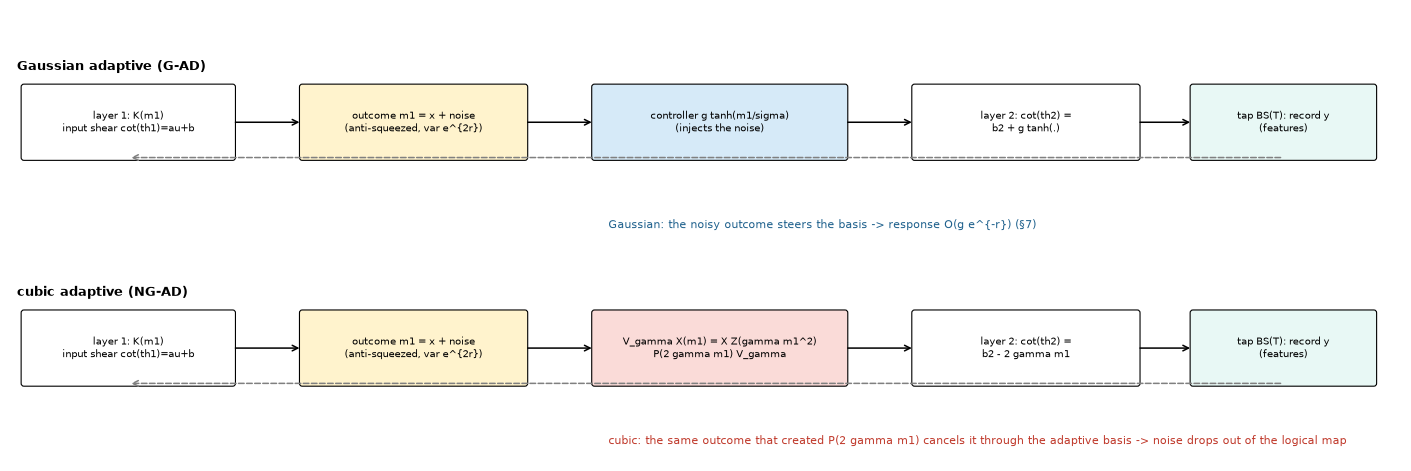

**Fig01_mechanism_gaussian_vs_cubic.** Mode preflight; schematic (no data; no realizations, trajectories, cutoff or uncertainty apply). Gaussian vs cubic adaptive measurement flow in one clock; dashed arrows: the retained logical mode is the recurrent state.

In [11]:
def _box(ax, x, y, w, h, txt, fc):
    ax.add_patch(matplotlib.patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", fc=fc, ec="k", lw=0.8)); ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=7.5)
def _arrow(ax, x0, y0, x1, y1, txt="", color="k", ls="-"):
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="->", color=color, ls=ls, lw=1.1))
    if txt:
        ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.06, txt, ha="center", fontsize=6.5, color=color)
fig, ax = plt.subplots(figsize=(14, 4.6)); ax.set_xlim(0, 10); ax.set_ylim(0, 3.2); ax.axis("off")
for row, (y, lab, col_) in enumerate([(2.15, "Gaussian adaptive (G-AD)", "#d6eaf8"), (0.55, "cubic adaptive (NG-AD)", "#fadbd8")]):
    ax.text(0.05, y + 0.62, lab, fontsize=9, weight="bold")
    _box(ax, 0.1, y, 1.5, 0.5, "layer 1: K(m1)\ninput shear cot(th1)=au+b", "#ffffff")
    _box(ax, 2.1, y, 1.6, 0.5, "outcome m1 = x + noise\n(anti-squeezed, var e^{2r})", "#fff3cd")
    if row == 0:
        _box(ax, 4.2, y, 1.8, 0.5, "controller g tanh(m1/sigma)\n(injects the noise)", col_)
    else:
        _box(ax, 4.2, y, 1.8, 0.5, "V_gamma X(m1) = X Z(gamma m1^2)\nP(2 gamma m1) V_gamma", col_)
    _box(ax, 6.5, y, 1.6, 0.5, "layer 2: cot(th2) =\n" + ("b2 + g tanh(.)" if row == 0 else "b2 - 2 gamma m1"), "#ffffff")
    _box(ax, 8.5, y, 1.3, 0.5, "tap BS(T): record y\n(features)", "#e8f8f5")
    for x0, x1 in ((1.6, 2.1), (3.7, 4.2), (6.0, 6.5), (8.1, 8.5)):
        _arrow(ax, x0, y + 0.25, x1, y + 0.25)
    _arrow(ax, 9.15, y, 0.85, y - 0.0 if row else y, "", "gray", "--")
ax.text(4.3, 1.65, "Gaussian: the noisy outcome steers the basis -> response O(g e^{-r}) (§7)", fontsize=8, color="#1f618d")
ax.text(4.3, 0.12, "cubic: the same outcome that created P(2 gamma m1) cancels it through the adaptive basis -> noise drops out of the logical map", fontsize=8, color="#c0392b")
show_fig(fig, "Fig01_mechanism_gaussian_vs_cubic", f"Mode {RUN_MODE}; schematic (no data; no realizations, trajectories, cutoff or uncertainty apply). Gaussian vs cubic adaptive "
         "measurement flow in one clock; dashed arrows: the retained logical mode is the recurrent state.")

## 9. Native engines and exact adapters

### 9.1 What runs where

| component | engine | label |
|---|---|---|
| one complete clock (both levels, all four arms) with fixed outcomes, used for replay validation | PhotoGraphiQ pattern on `piquasso-fock` (Piquasso `PureFockSimulator`); Level-B noise on `piquasso-mixed-fock` | **native engine operation** |
| Gaussian conditional states (teleportation layer, tap) | PhotoGraphiQ `gaussian` backend | **native engine operation** |
| cubic phase, quadratic phase, displacement, rotation (identity tests, resource preparation) | Piquasso Fock gates | **native engine operation** |
| batched trajectories (thousands of paths on CPU/GPU) | DVR/Fock adapter below | **exact adapter**: every operation is an exact instrument on the truncated space (validated §10) |
| conventional CV-QRC | Piquasso Gaussian (round trip) + closed-form covariance recursion | native / exact adapter |

### 9.2 The exact adapter

Let $\hat x_D$ be the truncated position operator on $\{|0\rangle,\dots,|D-1\rangle\}$ ($\hbar=2$), with $\hat x_D=W\Lambda W^{\mathsf T}$. Its eigenvalues are Gauss–Hermite nodes, and its eigenvectors form a discrete-variable representation (DVR). Every operation of the clock is of one of five exact types:

1. **functions of $\hat x_D$**, i.e. $V_\gamma=e^{i\gamma\hat x_D^3/6}$ (identical to Piquasso's `CubicPhase`, which is `expm` of the cubed truncated position matrix), the shear $P(s)=e^{is\hat x_D^2/4}$, the momentum kick $Z(a)=e^{ia\hat x_D/2}$, and the finite-squeezing teleportation filter. These are diagonal in the DVR;
2. **functions of $\hat n$**, i.e. the Fourier rotation $A=e^{i\pi\hat n/2}$ (Piquasso `Phaseshifter(π/2)`: $A^\dagger\hat xA=-\hat p$, $A^\dagger\hat pA=\hat x$). Position shifts are $X(\delta)=A^\dagger e^{i\delta\hat x_D/2}A$;
3. **the finite-squeezing teleportation instrument** (derived in §8 and checked against native PhotoGraphiQ):
$$K_\theta(m)=M_V(\hat x_D+m)\,A\,P(\cot\theta),\qquad M_V(z)=(2\pi V)^{-1/4}e^{-z^2/4V},\qquad V=e^{2r},\qquad m=h/\sin\theta.$$
   Completeness $\int K^\dagger K\,dm=\mathbb 1$ holds *exactly* for any Hermitian $\hat x_D$, so the truncated model is an exact instrument;
4. **the monitoring tap** (beam splitter $T$ with vacuum, $x$-homodyne of the tap). Photon number is conserved, so
$$K_y=\sum_t\psi_t(y)\,C_t,\qquad (C_t)_{k,k+t}=\sqrt{\tbinom{k+t}{t}}\,T^{k/2}(1-T)^{t/2},$$
   with Hermite functions $\psi_t$ in PhotoGraphiQ's convention. Completeness is again exact;
5. **pure loss**, with Kraus operators $E_k$ conserving total photon number (unravelled into jumps for state vectors, applied exactly for density matrices).

Outcomes are sampled from the exact conditional law by inverse CDF:
* teleportation and injection outcomes in closed form from DVR weights;
* the tap on an adaptive grid; the grid error is a convergence test.

Detector inefficiency and resolution noise act on a homodyne outcome as additive Gaussian noise of variance $(1-\eta)/\eta+\sigma_{\rm res}^2$. They are unravelled as a hidden true outcome plus noise: corrections and controllers see only the noisy record, and the byproduct follows the true outcome. This reproduces the exact outcome statistics, and the corresponding density-matrix instrument is checked against PhotoGraphiQ `piquasso-mixed-fock` in §10.

Common random numbers: every arm consumes the same uniform innovation arrays. Each arm transforms them through its own state-dependent law, so physical outcomes are *not* forced to coincide.

In [12]:
HBAR = 2.0
VRAM_BUDGET = 1.5e9     # bytes per batch chunk; re-measured on the device in §10
ARMS = {"G-NA": (0, 0), "G-AD": (0, 1), "NG-NA": (1, 0), "NG-AD": (1, 1)}

def db_to_r(db):
    return db / (20 * np.log10(np.e))

def herm_fns(x, D, xp=np):
    """psi_n(x), n < D, in PhotoGraphiQ's hbar = 2 convention (psi_0 = (2 pi)^(-1/4) exp(-x^2/4)); returns x.shape + (D,)."""
    x = xp.asarray(x, dtype=float); out = xp.empty(x.shape + (D,), dtype=float)
    out[..., 0] = (2 * np.pi) ** -0.25 * xp.exp(-x * x / 4)
    if D > 1:
        out[..., 1] = x * out[..., 0]
    for n in range(2, D):
        out[..., n] = (x * out[..., n - 1] - np.sqrt(n - 1) * out[..., n - 2]) / np.sqrt(n)
    return out

def _ndtr(xp):
    if xp is np:
        return ssp.ndtr
    import cupyx.scipy.special as cps
    return cps.ndtr

class FockOps:
    """Single-mode truncated operators at cutoff D on device xp."""
    def __init__(self, D, xp=np):
        self.D, self.xp = D, xp
        lam, W = np.linalg.eigh(x_trunc(D)); self.lam_h, self.W_h = lam, W
        self.lam, self.W, self.Wt = xp.asarray(lam), xp.asarray(W.astype(complex)), xp.asarray(W.T.astype(complex))
        self.A = xp.asarray(np.exp(1j * np.pi / 2 * np.arange(D))); self.Ac = self.A.conj()
        Xb = x_trunc(D + 8); P_ = [np.eye(D + 8)]
        for _ in range(6):
            P_.append(P_[-1] @ Xb)
        self.Xk_h = [p[:D, :D] for p in P_]                   # exact moments <x^k> of states supported on n < D
        self.Xk = [xp.asarray(p.astype(complex)) for p in self.Xk_h]
        self._taps, self._loss = {}, {}; self.extra_nodes = 0

    def tap(self, T, G):
        key = (round(T, 12), G, self.extra_nodes)
        if key not in self._taps:
            D = self.D; t = np.arange(D)[:, None]; k = np.arange(D)[None, :]
            logc = ssp.gammaln(k + t + 1) - ssp.gammaln(k + 1) - ssp.gammaln(t + 1)
            C = np.where(k + t < D, np.exp(0.5 * logc + 0.5 * k * np.log(T) + 0.5 * t * np.log1p(-T)), 0.0)
            idx = np.minimum(k + t, D - 1)
            span = np.sqrt(1 - T) * (np.abs(self.lam_h).max() + 3) + 8 * np.sqrt(T)
            yg = np.linspace(-span, span, G); Hg = herm_fns(yg, D)
            Cmat = np.zeros((D, D, D))
            for tt in range(D):
                for kk in range(D - tt):
                    Cmat[tt, kk, kk + tt] = C[tt, kk]
            xp = self.xp; nq = 2 * D + 20 + self.extra_nodes
            xq, wq = np.polynomial.hermite_e.hermegauss(nq); lw = np.log(wq) + xq ** 2 / 2       # weight exp(-x^2/2): |psi(x)|^2 = exp(-x^2/2) Q(x)
            self._taps[key] = dict(C=xp.asarray(C), idx=xp.asarray(idx), yg=xp.asarray(yg), Hg=xp.asarray(Hg), dy=yg[1] - yg[0], Cmat=xp.asarray(Cmat),
                                   s=np.sqrt(1 - T), tau=np.sqrt(T), Hq=xp.asarray(herm_fns(xq, D).astype(complex)), ew=xp.asarray(np.exp(lw)), xq=xp.asarray(xq))
        return self._taps[key]

    def loss_table(self, eta):
        key = round(eta, 12)
        if key not in self._loss:
            n = np.arange(self.D)[:, None]; k = np.arange(self.D)[None, :]
            with np.errstate(divide="ignore"):
                L = np.where(k <= n, np.exp(ssp.gammaln(n + 1) - ssp.gammaln(k + 1) - ssp.gammaln(n - k + 1)
                                            + (n - k) * np.log(eta) + k * (np.log1p(-eta) if eta < 1 else -np.inf)), 0.0)
            L = np.nan_to_num(L); L[:, 0] = np.where(eta == 1, 1.0, L[:, 0])
            self._loss[key] = self.xp.asarray(L)
        return self._loss[key]

_OPS = {}
def fock_ops(D, xp=np):
    key = (D, xp.__name__)
    if key not in _OPS:
        _OPS[key] = FockOps(D, xp)
    return _OPS[key]

### 9.3 State representations
`VecState` holds a batch of pure conditional states (one or two modes). `DMState` holds a batch of single-mode density matrices (spectra, mixed-state physics, mixed-native validation). Both expose the same primitives, so the clock is written **once**.

In [13]:
class VecState:
    kind = "vec"
    def __init__(self, ops, psi):
        self.o, self.xp, self.psi = ops, ops.xp, psi
        self.N, self.B = psi.ndim - 1, psi.shape[0]

    def copy(self):
        return VecState(self.o, self.psi.copy())

    def _along(self, arr, M, mode):
        xp = self.xp; ax = mode + 1
        return xp.moveaxis(xp.tensordot(arr, M, axes=([ax], [0])), -1, ax)

    def _expand(self, f, mode):
        f = self.xp.asarray(f)
        if f.ndim == 1:
            f = f[None]
        shp = [f.shape[0]] + [1] * self.N; shp[mode + 1] = f.shape[1]
        return f.reshape(shp)

    def xmul(self, f, mode):
        pd = self._along(self.psi, self.o.W, mode) * self._expand(f, mode)
        self.psi = self._along(pd, self.o.Wt, mode)

    def xmul2(self, f2):
        pd = self._along(self._along(self.psi, self.o.W, 0), self.o.W, 1) * f2[None]
        self.psi = self._along(self._along(pd, self.o.Wt, 0), self.o.Wt, 1)

    def phase(self, ph, mode):
        self.psi = self.psi * self._expand(ph, mode)

    def dvr_weights(self, mode):
        w = self.xp.abs(self._along(self.psi, self.o.W, mode)) ** 2
        return w if self.N == 1 else w.sum(axis=2 - mode)

    def norm2(self):
        return (self.xp.abs(self.psi) ** 2).reshape(self.B, -1).sum(1)

    def normalize(self):
        nrm = self.norm2(); self.psi = self.psi / self.xp.sqrt(nrm).reshape((-1,) + (1,) * self.N); return nrm

    def diag_kraus(self, k, mode):
        self.xmul(k, mode); return self.normalize()

    def _mode_first(self, mode):
        P = self.xp.moveaxis(self.psi, mode + 1, 1); return P.reshape(self.B, self.o.D, -1)

    def _restore(self, P, mode):
        shp = [self.B] + [self.o.D] * self.N; shp[1], shp[mode + 1] = shp[mode + 1], shp[1]
        return self.xp.moveaxis(P.reshape(shp), 1, mode + 1)

    def tap_amps(self, mode, tp):
        P = self._mode_first(mode); return tp["C"][None, :, :, None] * P[:, tp["idx"], :]

    def tap_density(self, mode, tp):
        a = self.tap_amps(mode, tp); xp = self.xp
        Q = xp.einsum("btkr,bskr->bts", a, a.conj())
        tmp = xp.einsum("gt,bts->bgs", tp["Hg"], Q)
        return (tmp * tp["Hg"][None]).sum(-1).real, a

    def pos_weights(self, mode, tp):
        """Exact position density of mode `mode` (other modes traced) at the Gauss-Hermite nodes, times the quadrature weight / exp(-x^2/2)."""
        P = self._mode_first(mode); amp = tp["Hq"][None] @ P
        return (self.xp.abs(amp) ** 2).sum(-1) * tp["ew"][None]

    def tap_apply(self, mode, tp, Hy, a=None):
        """K_y psi with K_y = sum_t psi_t(y) C_t, by a shift loop over the photon number t lost to the tap."""
        P = self._mode_first(mode); D = self.o.D; C = tp["C"]; Hy = Hy.astype(complex); phi = self.xp.zeros_like(P)
        for t_ in range(D):
            phi[:, :D - t_, :] += (Hy[:, t_][:, None, None] * C[t_, :D - t_][None, :, None]) * P[:, t_:, :]
        self.psi = self._restore(phi, mode); return self.normalize()

    def measure(self, mode, sample_fn, kraus_fn, post_fn=None):
        """One DVR pass: marginal position weights -> sample (m, density) -> multiply by kraus(m) * post(m) -> back to Fock, normalize."""
        pd = self._along(self.psi, self.o.W, mode); w = self.xp.abs(pd) ** 2; w = w if self.N == 1 else w.sum(axis=2 - mode)
        m, dens = sample_fn(w / w.sum(1, keepdims=True)); k = kraus_fn(m)
        if post_fn is not None:
            k = k * post_fn(m)
        if not np.isscalar(k):
            pd = pd * self._expand(k, mode)
        self.psi = self._along(pd, self.o.Wt, mode); return m, dens, self.normalize()

    def loss(self, mode, eta, xi):
        if eta >= 1:
            return
        xp = self.xp; L = self.o.loss_table(eta); P = self._mode_first(mode); D = self.o.D
        pk = (xp.abs(P) ** 2).sum(-1) @ L
        cdf = xp.cumsum(pk, 1); cdf = cdf / cdf[:, -1:]
        kk = xp.minimum((cdf < xi[:, None]).sum(1), D - 1)
        j = xp.arange(D)[None, :]; src = j + kk[:, None]; ok = src < D; srcc = xp.minimum(src, D - 1)
        amp = xp.sqrt(L[srcc, kk[:, None]]) * ok
        P2 = xp.take_along_axis(P, srcc[:, :, None], axis=1) * amp[:, :, None]
        self.psi = self._restore(P2, mode); self.normalize()

    def moment(self, k, mode):
        P = self._mode_first(mode); return (P.conj() * (self.o.Xk[k][None] @ P)).real.reshape(self.B, -1).sum(1)

    def moment2(self, j, l):
        return self.xp.einsum("bnm,nk,ml,bkl->b", self.psi.conj(), self.o.Xk[j], self.o.Xk[l], self.psi).real

    def boundary(self, mode):
        w = self.xp.abs(self._mode_first(mode)) ** 2; pn = w.sum(-1)
        return pn[:, -2:].sum(1), (pn * self.xp.arange(self.o.D)[None]).sum(1)

    def rho(self):
        """Single-mode density matrices |psi><psi| (N = 1)."""
        return self.psi[:, :, None] * self.psi[:, None, :].conj()


class DMState:
    kind = "dm"
    N = 1
    def __init__(self, ops, rho, linear=False):
        self.o, self.xp, self.r = ops, ops.xp, rho
        self.B = rho.shape[0]; self.linear = linear          # linear=True: unnormalized Kraus action (exact Jacobians)

    def copy(self):
        return DMState(self.o, self.r.copy())

    def _dvr(self):
        return self.o.Wt @ self.r @ self.o.W

    def xmul(self, f, mode=0):
        f = self.xp.asarray(f)
        f = f[None] if f.ndim == 1 else f
        rd = f[:, :, None] * self._dvr() * f.conj()[:, None, :]
        self.r = self.o.W @ rd @ self.o.Wt

    def phase(self, ph, mode=0):
        self.r = ph[None, :, None] * self.r * ph.conj()[None, None, :]

    def dvr_weights(self, mode=0):
        return self.xp.diagonal(self._dvr(), axis1=1, axis2=2).real

    def norm2(self):
        return self.xp.trace(self.r, axis1=1, axis2=2).real

    def normalize(self):
        nrm = self.norm2()
        if not self.linear:
            self.r = self.r / nrm[:, None, None]
        return nrm

    def diag_kraus(self, k, mode=0):
        self.xmul(k); return self.normalize()

    def tap_density(self, mode, tp):
        xp = self.xp; idx = tp["idx"]
        R = self.r[:, idx[:, None, :], idx[None, :, :]]                 # R[b,t,s,k] = rho[k+t, k+s]
        Q = xp.einsum("tk,sk,btsk->bts", tp["C"], tp["C"], R)
        tmp = xp.einsum("gt,bts->bgs", tp["Hg"], Q)
        return (tmp * tp["Hg"][None]).sum(-1).real, None

    def pos_weights(self, mode, tp):
        return self.xp.einsum("qn,bnm,qm->bq", tp["Hq"], self.r, tp["Hq"].conj()).real * tp["ew"][None]

    def tap_apply(self, mode, tp, Hy, a=None):
        K = self.xp.einsum("bt,tkn->bkn", Hy.astype(complex), tp["Cmat"])
        self.r = K @ self.r @ K.conj().transpose(0, 2, 1); return self.normalize()

    def measure(self, mode, sample_fn, kraus_fn, post_fn=None):
        w = self.dvr_weights(); m, dens = sample_fn(w / w.sum(1, keepdims=True)); k = kraus_fn(m)
        if post_fn is not None:
            k = k * post_fn(m)
        if not np.isscalar(k):
            self.xmul(k)
        return m, dens, self.normalize()

    def loss(self, mode, eta, xi=None):
        if eta >= 1:
            return
        xp = self.xp; L = self.o.loss_table(eta); D = self.o.D; out = xp.zeros_like(self.r)
        for k in range(D):
            E = xp.zeros((D, D), dtype=complex); n = xp.arange(k, D); E[n - k, n] = xp.sqrt(L[n, k])
            out = out + E[None] @ self.r @ E.T[None]
        self.r = out

    def moment(self, k, mode=0):
        return self.xp.einsum("bnm,mn->b", self.r, self.o.Xk[k]).real

    def boundary(self, mode=0):
        pn = self.xp.diagonal(self.r, axis1=1, axis2=2).real
        return pn[:, -2:].sum(1), (pn * self.xp.arange(self.o.D)[None]).sum(1)

    def rho(self):
        return self.r

### 9.4 Samplers, resources and the clock

In [14]:
SAMPLER_ITERS = {"n": 10}          # Newton steps; spectra raise this so finite-difference Jacobians see a fully converged (smooth) sampler

def sample_gmix(w, centers, V, xi, xp, iters=None):
    """Inverse CDF of the Gaussian mixture sum_i w_i N(m; centers_i, V) (rows of w sum to 1): safeguarded Newton iteration inside a
    maintained bracket (bisection whenever a Newton step leaves it), then a final bisection polish of the bracket."""
    nd = _ndtr(xp); sv = np.sqrt(V); c = centers[None]; iters = SAMPLER_ITERS["n"] if iters is None else iters
    lo = xp.full(w.shape[0], float(centers.min()) - 12 * sv); hi = xp.full(w.shape[0], float(centers.max()) + 12 * sv)
    mu = (w * c).sum(1); sd = xp.sqrt((w * (c - mu[:, None]) ** 2).sum(1) + V)
    m = mu + sd * np.sqrt(2) * _erfinv(xp)(2 * xp.clip(xi, 1e-15, 1 - 1e-15) - 1)
    for _ in range(iters):
        z = (m[:, None] - c) / sv; F = (w * nd(z)).sum(1); p = (w * xp.exp(-0.5 * z * z)).sum(1) / (sv * np.sqrt(2 * np.pi))
        go = F < xi; lo = xp.where(go, xp.maximum(lo, m), lo); hi = xp.where(go, hi, xp.minimum(hi, m))
        mn = m - (F - xi) / xp.maximum(p, 1e-300); bad = (mn < lo) | (mn > hi) | ~xp.isfinite(mn)
        m = xp.where(bad, 0.5 * (lo + hi), mn)
    return m

def _erfinv(xp):
    if xp is np:
        return ssp.erfinv
    import cupyx.scipy.special as cps
    return cps.erfinv

def gmix_density(w, centers, V, m, xp):
    return (w * xp.exp(-(m[:, None] - centers[None]) ** 2 / (2 * V))).sum(1) / np.sqrt(2 * np.pi * V)

def gauss_kraus(lam, m, V, xp):
    return (2 * np.pi * V) ** -0.25 * xp.exp(-(lam[None] + m[:, None]) ** 2 / (4 * V))


class CubicResource:
    """Finite-energy approximate cubic-phase ancilla CP(gamma) S(-r)|0> on a Fock cutoff D_res, prepared with native Piquasso gates.
    Optional pure loss before injection gives a mixture of branches (unravelled). Kraus of the injection: a(x_D + m)."""
    def __init__(self, gamma, r, D_res, loss=1.0, xp=np, zgrid=6001):
        self.gamma, self.r, self.D_res, self.xp = gamma, r, D_res, xp
        with pq.Program() as prog:
            pq.Q() | pq.Vacuum()
            pq.Q(0) | pq.Squeezing(r=-r)
            if gamma:
                pq.Q(0) | pq.CubicPhase(gamma=gamma)
        st = pq.PureFockSimulator(d=1, config=pq.Config(cutoff=D_res, hbar=2.0)).execute(prog).state
        c = np.asarray(st.state_vector, complex); self.norm_retained = float(np.vdot(c, c).real); c = c / np.sqrt(self.norm_retained)
        self.boundary = float(np.sum(np.abs(c[-2:]) ** 2)); self.amps = c
        n = np.arange(D_res)
        if loss < 1:
            br, pr = [], []
            for k in range(D_res):
                coef = np.where(n >= k, np.exp(0.5 * (ssp.gammaln(n + 1) - ssp.gammaln(k + 1) - ssp.gammaln(np.maximum(n - k, 0) + 1)
                                                       + (n - k) * np.log(loss) + k * np.log1p(-loss))), 0.0)
                b_ = np.zeros(D_res, complex); b_[: D_res - k] = (coef * c)[k:]; p_ = float(np.vdot(b_, b_).real)
                if p_ > 1e-14:
                    br.append(b_ / np.sqrt(p_)); pr.append(p_)
            self.branches, self.bprob = br, np.array(pr) / sum(pr)
        else:
            self.branches, self.bprob = [c], np.array([1.0])
        span = 4 * np.sqrt(D_res) + 10; self.z = np.linspace(-span, span, zgrid)
        self.cdf_tab = []
        for b_ in self.branches:
            dens = np.abs(herm_fns(self.z, D_res) @ b_) ** 2; cdf = np.concatenate([[0], np.cumsum(0.5 * (dens[1:] + dens[:-1]) * np.diff(self.z))])
            self.cdf_tab.append(xp.asarray(cdf / cdf[-1]))
        self.z_d = xp.asarray(self.z); self.br_d = [xp.asarray(b_) for b_ in self.branches]

    def kraus(self, lam, m, branch):
        xp = self.xp; z = lam[None] + m[:, None]; H = herm_fns(z, self.D_res, xp)
        out = xp.zeros(z.shape, dtype=complex)
        for j, b_ in enumerate(self.br_d):
            sel = branch == j
            out = xp.where(sel[:, None], H @ b_, out)
        return out

    def sample(self, w, lam, xi, branch, iters=48):
        xp = self.xp; span = float(self.z[-1])
        lo = xp.full(w.shape[0], -span - float(xp.abs(lam).max())); hi = -lo
        for _ in range(iters):
            mid = 0.5 * (lo + hi); F = xp.zeros_like(mid)
            for j, cdf in enumerate(self.cdf_tab):
                Fj = (w * xp.interp(lam[None] + mid[:, None], self.z_d, cdf)).sum(1); F = xp.where(branch == j, Fj, F)
            go = F < xi; lo = xp.where(go, mid, lo); hi = xp.where(go, hi, mid)
        return 0.5 * (lo + hi)

    def density(self, w, lam, m, branch):
        return (w * self.xp.abs(self.kraus(lam, m, branch)) ** 2).sum(1)


class Reservoir:
    """One reservoir realization at a parameter point. Random parts (encoding gains and basis offsets) derive from the realization seed."""
    def __init__(self, rid, N, D, T, gamma, *, level="A", variant="V1", cond=None, sigma=None, xp=np, D_res=None):
        cond = dict(BASE if cond is None else cond); rng = rng_for("reservoir", rid, N)
        self.rid, self.N, self.D, self.T, self.gamma, self.level, self.variant, self.cond, self.xp = rid, N, D, T, gamma, level, variant, cond, xp
        self.alpha = cond["enc_scale"] * rng.uniform(0.7, 1.3, N) * rng.choice([-1, 1], N)
        self.beta1, self.beta2 = rng.uniform(-cond["beta_scale"], cond["beta_scale"], N), rng.uniform(-cond["beta_scale"], cond["beta_scale"], N)
        self.V = float(np.exp(2 * db_to_r(cond["squeezing_db"]))); self.w = cond["coupling_w"]
        eta_l, eta_t, res = cond["layer_efficiency"], cond["tap_efficiency"], cond["homodyne_resolution"]
        self.sig_h = float(np.sqrt((1 - eta_l) / eta_l + res ** 2)); self.sig_tap = float(np.sqrt((1 - eta_t) / eta_t + res ** 2))
        self.ff, self.loss = cond["ff_gain_error"], cond["loop_transmissivity"]
        self.g = 0.0 if variant == "V1" else PREREGISTERED["g_feedback"]; self.lam_f = PREREGISTERED["filter_lambda"]
        self.sigma = dict(m1=float(np.sqrt(self.V + 2.0)), filt=float(np.sqrt(self.V + 2.0)), byp=float(np.sqrt(self.V + 2.0))) if sigma is None else dict(sigma)
        self.ops = fock_ops(D, xp); self.adaptive_enabled = True
        self.resources = None
        if level == "B":
            Dr = D_res or CFG["D_res"]; rr = db_to_r(cond["resource_squeezing_db"])
            self.resources = {0: get_resource(0.0, rr, Dr, cond["resource_loss"], xp), 1: get_resource(gamma, rr, Dr, cond["resource_loss"], xp)}

    def view(self, sl):
        """Chunk view: slice per-path parameters of a stacked reservoir."""
        if np.ndim(self.alpha) < 2:
            return self
        r = copy.copy(self); r.alpha, r.beta1, r.beta2 = self.alpha[sl], self.beta1[sl], self.beta2[sl]
        if getattr(self.gamma, "ndim", 0):
            r.gamma = self.gamma[sl]
        return r

    def vacuum(self, B, kind="vec"):
        xp = self.xp; D = self.D
        if kind == "dm":
            r = xp.zeros((B, D, D), complex); r[:, 0, 0] = 1; return DMState(self.ops, r)
        psi = xp.zeros((B,) + (D,) * self.N, complex); psi[(slice(None),) + (0,) * self.N] = 1
        return VecState(self.ops, psi)

def stack_reservoirs(res_list, reps):
    """One batch holding several realizations (same point, different random encodings): per-path parameter arrays of shape (B, N)."""
    r = copy.copy(res_list[0]); xp = r.xp
    for nm in ("alpha", "beta1", "beta2"):
        setattr(r, nm, xp.asarray(np.concatenate([np.repeat(np.asarray(getattr(x, nm))[None], n, 0) for x, n in zip(res_list, reps)])))
    gs = [x.gamma for x in res_list]
    if len(set(gs)) > 1:
        assert r.level == "A", "per-path gamma is supported at Level A only (Level B resources depend on gamma)"
        r.gamma = xp.asarray(np.concatenate([np.full(n, g_) for g_, n in zip(gs, reps)]))
    return r

_RES_CACHE = {}
def get_resource(gamma, r, D_res, loss, xp):
    key = (round(gamma, 12), round(r, 12), D_res, round(loss, 12), xp.__name__)
    if key not in _RES_CACHE:
        _RES_CACHE[key] = CubicResource(gamma, r, D_res, loss, xp)
    return _RES_CACHE[key]

XI_KEYS = ("m1", "mc", "m2", "y", "loss", "res", "n1", "nc", "n2", "ny")
def draw_innovations(rng, B, N, K):
    """Host-side innovations for B paths x K clocks: uniforms for inverse-CDF sampling and normals for detector noise (CRN across arms)."""
    u = rng.random((K, 6, B, N)); g = rng.standard_normal((K, 4, B, N))
    return u, g

def xi_at(inn, k, xp, sl=slice(None)):
    u, g = inn
    d = {key: xp.asarray(u[k, j, sl]) for j, key in enumerate(XI_KEYS[:6])}
    d.update({key: xp.asarray(g[k, j, sl]) for j, key in enumerate(XI_KEYS[6:])})
    return d


def tap_sample(dens, tp, xi, xp):
    """Exact inverse of the piecewise-quadratic CDF of the tap density sampled on the grid (trapezoid-consistent); returns (y, grid mass)."""
    dy = tp["dy"]; p0, p1 = dens[:, :-1], dens[:, 1:]
    cdf = xp.concatenate([xp.zeros((dens.shape[0], 1)), xp.cumsum(0.5 * (p0 + p1) * dy, 1)], 1); mass = cdf[:, -1]
    target = xi * mass; j = xp.clip((cdf < target[:, None]).sum(1) - 1, 0, cdf.shape[1] - 2)
    c0 = xp.take_along_axis(cdf, j[:, None], 1)[:, 0]; a0 = xp.take_along_axis(p0, j[:, None], 1)[:, 0]; a1 = xp.take_along_axis(p1, j[:, None], 1)[:, 0]
    r = xp.maximum(target - c0, 0.0); sl = (a1 - a0) / dy                      # density a0 + sl*s on the bin, CDF increment a0 s + sl s^2 / 2 = r
    disc = xp.sqrt(xp.maximum(a0 * a0 + 2 * sl * r, 0.0))
    s = xp.where(xp.abs(sl) > 1e-14 * xp.maximum(a0, 1e-300) / dy, 2 * r / xp.maximum(a0 + disc, 1e-300), r / xp.maximum(a0, 1e-300))
    return tp["yg"][j] + xp.clip(s, 0.0, dy), mass

def clock(res, st, u, xi, arm, mem, *, ctrl="true", given=None, want_moments=3, rec=None, perm=None):
    """One reservoir clock (§8), in place on `st`. u: (B,) inputs. xi: innovations. mem: per-path classical memory (V3 filter, previous outcome).
    ctrl: 'true' | 'indep' (correction/feedback from an independent path) | 'shift' (from the previous clock) | 'iid' (marginal draw).
    given: optional dict of true outcomes (replay / common-record). Returns a dict with outcomes, densities and pre-tap moments.
    Consecutive functions of x are fused into one DVR pass per homodyne layer (identical operators, fewer transforms)."""
    xp, o = st.xp, st.o; lam = o.lam; ff = res.ff; B = st.B; lam2 = lam[None] ** 2 / 4
    if isinstance(arm, str):
        ng, ad = ARMS[arm]
    else:
        ng, ad = xp.asarray(arm[0]), xp.asarray(arm[1])
    gam = res.gamma * ng; gcol = gam[:, None] if getattr(gam, "ndim", 0) else gam            # gamma may be per path (stacked points)
    ad = ad if res.adaptive_enabled else 0 * ad; any_g = bool(xp.any(xp.asarray(gam) != 0)); noisy = res.sig_h > 0 or ff != 0
    out = {"logp": xp.zeros(B)}

    def layer2_shear(i, m1o, byp_o):
        """Adaptive layer-2 basis: bounded feedback (V2/V3) and the derived cubic byproduct correction -2 gamma m."""
        if res.variant == "V3":
            stat = res.lam_f * mem["filt"][:, i] + (1 - res.lam_f) * m1o; mem["filt"][:, i] = stat; sig_s = res.sigma["filt"]
        else:
            stat, sig_s = m1o, res.sigma["m1"]
        corr = byp_o
        if ctrl != "true" and bool(xp.any(xp.asarray(ad) != 0)):
            if ctrl == "indep":
                stat, corr = stat[perm], corr[perm]
            elif ctrl == "shift":
                stat_prev, corr_prev = mem["prev_stat"][:, i].copy(), mem["prev_corr"][:, i].copy()
                mem["prev_stat"][:, i], mem["prev_corr"][:, i] = stat, corr; stat, corr = stat_prev, corr_prev
            elif ctrl == "iid":
                stat, corr = sig_s * mem["iid"][0][:, i], res.sigma["byp"] * mem["iid"][1][:, i]
        return xp.asarray(res.beta2[..., i]) + ad * (res.g * xp.tanh(stat / sig_s) - (1 + ff) * 2 * gam * corr)

    def gsample(key, i, V):
        def f(w):
            m = given[key][:, i] if given is not None else sample_gmix(w, -lam, V, xi[key][:, i], xp)
            return m, gmix_density(w, -lam, V, m, xp)
        return f

    def pshift(i, d):
        if bool(xp.any(d != 0)):
            st.phase(o.A, i); st.xmul(xp.exp(1j * d[:, None] * lam[None] / 2), i); st.phase(o.Ac, i)

    for i in range(res.N):
        c1 = xp.asarray(res.alpha[..., i]) * u + xp.asarray(res.beta1[..., i]); sin1 = 1 / xp.sqrt(1 + c1 ** 2)
        st.xmul(xp.exp(1j * c1[:, None] * lam2), i); st.phase(o.A, i)
        # ---- layer-1 teleportation; in the same DVR pass: Level-A cubic gate in the byproduct frame and (noise-free) the layer-2 shear
        S = {}
        def post1(m1t, i=i):
            m1o = m1t + res.sig_h * xi["n1"][:, i] / sin1; S["m1o"] = m1o; expo = 0.0
            if res.level == "A":
                S["byp"] = (m1t, m1o)
                if any_g:
                    expo = expo + gcol * lam[None] ** 3 / 6 + (2 * gam * m1t)[:, None] * lam2 + (gam * m1t ** 2 - (1 + ff) * gam * m1o ** 2)[:, None] * lam[None] / 2
                if not noisy:
                    S["c2"] = layer2_shear(i, m1o, m1o); expo = expo + S["c2"][:, None] * lam2
            return gauss_kraus(lam, m1t, res.V, xp) * (xp.exp(1j * expo) if not np.isscalar(expo) else 1.0)
        m1t, dens1, _ = st.measure(i, gsample("m1", i, res.V), lambda m: 1.0, post1)
        out["logp"] = out["logp"] + xp.log(dens1 / sin1); m1o = S["m1o"]
        pshift(i, m1t - (1 + ff) * m1o)
        if res.level == "B":
            def samp_c(w, i=i):
                parts = []
                for flag in ((ng,) if isinstance(arm, str) else (0, 1)):
                    R_ = res.resources[flag]
                    branch = xp.minimum(xp.searchsorted(xp.asarray(np.cumsum(R_.bprob)), xi["res"][:, i]), len(R_.bprob) - 1)
                    mct_ = given["mc"][:, i] if given is not None else R_.sample(w, lam, xi["mc"][:, i], branch)
                    parts.append((mct_, R_.density(w, lam, mct_, branch), R_.kraus(lam, mct_, branch)))
                if len(parts) == 1:
                    S["kr"] = parts[0][2]; return parts[0][0], parts[0][1]
                sel = ng.astype(bool); S["kr"] = xp.where(sel[:, None], parts[1][2], parts[0][2])
                return xp.where(sel, parts[1][0], parts[0][0]), xp.where(sel, parts[1][1], parts[0][1])
            def postc(mct, i=i):
                mco = mct + res.sig_h * xi["nc"][:, i]; S["byp"] = (mct, mco); expo = 0.0
                if any_g:
                    expo = expo - ((1 + ff) * gam * mco ** 2)[:, None] * lam[None] / 2
                if not noisy:
                    S["c2"] = layer2_shear(i, m1o, mco); expo = expo + S["c2"][:, None] * lam2
                return S["kr"] * (xp.exp(1j * expo) if not np.isscalar(expo) else 1.0)
            mct, densc, _ = st.measure(i, samp_c, lambda m: 1.0, postc)
            out["logp"] = out["logp"] + xp.log(densc)
        byp_t, byp_o = S["byp"]
        if "c2" not in S:                                       # noisy detectors / feed-forward error: residual shifts come before the shear
            S["c2"] = layer2_shear(i, m1o, byp_o); st.xmul(xp.exp(1j * S["c2"][:, None] * lam2), i)
        c2 = S["c2"]; sin2 = 1 / xp.sqrt(1 + c2 ** 2)
        if rec is not None:
            rec.setdefault("c2", []).append(c2); rec.setdefault("sin2", []).append(sin2)
        st.phase(o.A, i)
        m2t, dens2, _ = st.measure(i, gsample("m2", i, res.V), lambda m: gauss_kraus(lam, m, res.V, xp))
        out["logp"] = out["logp"] + xp.log(dens2 / sin2)
        m2o = m2t + res.sig_h * xi["n2"][:, i] / sin2; pshift(i, m2t - (1 + ff) * m2o)
        out[f"m1_{i}"], out[f"m2_{i}"], out[f"byp_{i}"], out[f"sin2_{i}"] = m1o, m2o, byp_o, sin2
    if res.N == 2:
        st.xmul2(xp.exp(1j * res.w * lam[:, None] * lam[None, :] / 2))
    # ---- pre-tap moments (Rao-Blackwellized feature expectations), then the monitoring taps
    if want_moments:
        if res.N == 1:
            out["mom"] = xp.stack([st.moment(k, 0) for k in range(1, want_moments + 1)], 1)
        else:
            out["mom2"] = {(j, l): st.moment2(j, l) for j in range(want_moments + 1) for l in range(want_moments + 1 - j) if j + l > 0}
    tp = o.tap(res.T, CFG["tap_grid"]); ys = []
    for i in range(res.N):
        if given is not None:
            yt = given["y"][:, i]
        else:
            wq_ = st.pos_weights(i, tp); mass = wq_.sum(1); out.setdefault("grid_mass", []).append(mass)
            yt = sample_gmix(wq_ / mass[:, None], tp["s"] * tp["xq"], res.T, xi["y"][:, i], xp)
        p_y = st.tap_apply(i, tp, herm_fns(yt, o.D, xp)); out["logp"] = out["logp"] + xp.log(p_y)
        ys.append(yt + res.sig_tap * xi["ny"][:, i])
        st.loss(i, res.loss, xi["loss"][:, i])
    out["y"] = xp.stack(ys, 1)
    return out

### 9.5 Physical feature map $B_{\rm meas}$

The visible features of a clock are the empirical moments of the tap record, $\phi(y)=\{y_i^a y_j^b:1\le a+b\le3\}$ (3 features for one mode, 9 for two modes). They are averaged over $S$ shots (parallel trajectories). Writing $y_i=s\,\hat x_i+\tau\,\xi_i$ with $s=\sqrt{1-T}$, $\tau=\sqrt T$ and vacuum noise $\xi_i\sim\mathcal N(0,1)$, the map $B_{\rm meas}:\rho\mapsto\mathbb E[\phi(y)]$ is *linear* in $\rho$ and uses exact (untruncated) position moments. It is a fixed physical map, not a trained readout. The single-shot covariance $\Sigma_1$ follows from moments up to order 6, and $\Sigma_{\rm shot}=\Sigma_1/S$.

In [15]:
def feature_index(N):
    return [(a,) for a in (1, 2, 3)] if N == 1 else [(a, b) for tot in (1, 2, 3) for a in range(tot, -1, -1) for b in [tot - a]]

def _vac_moment(k):
    return 0.0 if k % 2 else float(ssp.factorial2(k - 1)) if k > 0 else 1.0

def y_moments_from_x(xmom, T, N, order):
    """E[prod y_i^{a_i}] from position moments. xmom: dict {(a,) or (a,b): array} incl. order-0 = 1."""
    s, tau = np.sqrt(1 - T), np.sqrt(T); out = {}
    if N == 1:
        for n in range(1, order + 1):
            out[(n,)] = sum(ssp.comb(n, j) * s ** j * tau ** (n - j) * _vac_moment(n - j) * xmom[(j,)] for j in range(n + 1))
    else:
        for A_ in range(order + 1):
            for B_ in range(order + 1 - A_):
                if A_ + B_ == 0:
                    continue
                out[(A_, B_)] = sum(ssp.comb(A_, j) * ssp.comb(B_, l) * s ** (j + l) * tau ** (A_ - j + B_ - l) * _vac_moment(A_ - j) * _vac_moment(B_ - l) * xmom[(j, l)]
                                    for j in range(A_ + 1) for l in range(B_ + 1))
    return out

def xmom_dict(out, N, xp):
    if N == 1:
        d = {(0,): 1.0}; d.update({(k,): out["mom"][:, k - 1] for k in range(1, out["mom"].shape[1] + 1)}); return d
    d = {(0, 0): 1.0}; d.update(out["mom2"]); return d

def features_rb(out, T, N, xp):
    """Per-path Rao-Blackwellized feature expectations B_meas(rho_path): (B, F)."""
    ym = y_moments_from_x(xmom_dict(out, N, xp), T, N, 3)
    return xp.stack([ym[f] * xp.ones(out["y"].shape[0]) for f in feature_index(N)], 1)

def features_shot(y, N, xp):
    if N == 1:
        return xp.stack([y[:, 0] ** a for (a,) in feature_index(1)], 1)
    return xp.stack([y[:, 0] ** a * y[:, 1] ** b for (a, b) in feature_index(2)], 1)

def shot_covariance(xm_mean, T, N):
    """Single-shot feature covariance Sigma_1 from ensemble-averaged position moments up to order 6 (host floats)."""
    ym = y_moments_from_x(xm_mean, T, N, 6); F = feature_index(N)
    def E(key):
        return 1.0 if sum(key) == 0 else ym[key]
    mean = np.array([E(f) for f in F])
    S2 = np.array([[E(tuple(a + b for a, b in zip(f, g))) for g in F] for f in F])
    return S2 - np.outer(mean, mean), mean

### 9.6 Trajectory driver
`run_paths` drives a batch of paths for $K$ clocks, with optional per-path inputs, common innovations, chunking by measured VRAM, and escape tracking. A path *escapes* if its top-two-level population exceeds `boundary_escape`, or its mean photon number exceeds `energy_bound_frac·D`. Escaped paths are frozen, counted and excluded from averages. Any estimate that loses paths is labelled **survivor-conditioned**.

In [16]:
def default_chunk(res, kind="vec"):
    D = res.D; Dst = D if res.N == 1 else D * D; nq = 2 * D + 20
    per = 16 * (6 * Dst * D + 2 * nq * Dst) + (16 * 3 * D ** 3 if kind == "dm" else 0)      # tap amplitudes, position-quadrature workspace
    budget = (VRAM_BUDGET if res.xp is not np else 1.5e9)
    return int(max(64, min(65536, budget // per)))

def run_paths(res, arm, U, inn, *, kind="vec", ctrl="true", collect=("rb",), K0=0, st0=None, given=None, chunk=None, perm_rng=None, keep_state=False, block=None):
    """U: (K, B) inputs. inn: host innovations (K, ., B, N). Returns dict of host arrays."""
    xp = res.xp; K, B = U.shape; chunk = chunk or default_chunk(res, kind); res_out = {}
    if block:                                                           # per-block (shot-group) feature means: chunks must hold whole blocks
        chunk = max(block, (chunk // block) * block)
    for a0 in range(0, B, chunk):
        sl = slice(a0, min(B, a0 + chunk)); b = sl.stop - sl.start
        rv = res.view(sl); arm_c = arm if isinstance(arm, str) else (arm[0][sl], arm[1][sl])
        st = rv.vacuum(b, kind) if st0 is None else st0
        mem = dict(filt=xp.zeros((b, res.N)), prev_stat=xp.zeros((b, res.N)), prev_corr=xp.zeros((b, res.N)))
        if ctrl == "iid":
            mem["iid"] = None
        alive = xp.ones(b, bool); first = xp.full(b, -1); acc = {k: [] for k in collect}; maxb = xp.zeros(b); logp = xp.zeros(b)
        perm = xp.asarray(np.roll(np.arange(b), 1)) if ctrl == "indep" else None
        for k in range(K):
            xi = xi_at(inn, k, xp, sl)
            if ctrl == "iid":
                r_ = rng_for("iid-ctrl", res.rid, a0, k); mem["iid"] = (xp.asarray(r_.standard_normal((b, res.N))), xp.asarray(r_.standard_normal((b, res.N))))
            g_ = None if given is None else {kk: xp.asarray(v[k, sl]) for kk, v in given.items()}
            out = clock(rv, st, xp.asarray(U[k, sl]), xi, arm_c, mem, ctrl=ctrl, given=g_, want_moments=3 if ("rb" in collect or "mom" in collect or "feat" in collect) else 0, perm=perm)
            logp = logp + out["logp"]
            bnd = xp.zeros(b); nbar = xp.zeros(b)
            for i in range(res.N):
                bi, ni = st.boundary(i); bnd = xp.maximum(bnd, bi); nbar = xp.maximum(nbar, ni)
            esc = (bnd > PREREGISTERED["boundary_escape"]) | (nbar > PREREGISTERED["energy_bound_frac"] * max(CFG["cutoffs"])) | ~xp.isfinite(bnd)
            newly = esc & alive; first = xp.where(newly, k, first); alive = alive & ~esc; maxb = xp.maximum(maxb, bnd)
            if "rb" in collect:
                acc["rb"].append(features_rb(out, res.T, res.N, xp))
            if "y" in collect:
                acc["y"].append(out["y"])
            if "mom" in collect:
                acc["mom"].append(out["mom"] if res.N == 1 else xp.stack([out["mom2"][kk] for kk in sorted(out["mom2"])], 1))
            if "m" in collect:
                acc["m"].append(xp.stack([out[f"m1_{i}"] for i in range(res.N)] + [out[f"byp_{i}"] for i in range(res.N)], 1))
            if "grid" in collect and "grid_mass" in out:
                acc["grid"].append(xp.stack(out["grid_mass"], 1))
            if "feat" in collect:                                       # measured (shot) and Rao-Blackwellized features, averaged over alive paths of each block
                wv = alive.astype(float).reshape(-1, block, 1); den = xp.maximum(wv.sum(1), 1.0)
                fs = features_shot(out["y"], res.N, xp).reshape(-1, block, len(feature_index(res.N)))
                fr = features_rb(out, res.T, res.N, xp).reshape(-1, block, len(feature_index(res.N)))
                acc["feat"].append(xp.stack([(fs * wv).sum(1) / den, (fr * wv).sum(1) / den], 0))
        to = (lambda a_: a_) if xp is np else (lambda a_: xp.asnumpy(a_))
        part = dict(alive=to(alive), first=to(first), maxb=to(maxb), logp=to(logp))
        for kk, v in acc.items():
            if v:
                part[kk] = to(xp.stack(v, 0))
        part["state"] = st if (st0 is not None or B <= chunk) else None
        if keep_state and kind == "vec":
            part["psi"] = to(st.psi)
        for kk, v in part.items():
            if kk == "state":
                res_out[kk] = v
            else:
                res_out.setdefault(kk, []).append(v)
    for kk in list(res_out):
        if kk != "state":
            axis = 2 if kk == "feat" else 1 if res_out[kk][0].ndim >= 2 and kk in ("rb", "y", "mom", "m", "grid") else 0          # psi: concatenated along paths (axis 0)
            res_out[kk] = np.concatenate(res_out[kk], axis=axis)
    return res_out

def input_sequence(rid, i, K):
    return rng_for("input", rid, i).uniform(-1, 1, K)

### 9.7 Native one-clock pattern (PhotoGraphiQ) and conventional CV-QRC (Piquasso)
The native pattern below is the reference for the replay tests of §10. The CV-QRC comparator is the García-Beni optical loop. Its closed-form covariance recursion is checked against a Piquasso Gaussian round trip, and its features are the $-quadrature second moments of {\rm CV}$ modes. {\rm CV}=2$ gives the same feature count (3) as one MB mode.

In [17]:
from photographiq import Pattern, Outcome
from photographiq.commands import Prepare, Entangle, Measure, Displace, CubicPhase, BeamSplitter, Output, Rotate
from photographiq.measurements import Homodyne
from photographiq.states import FockInput
from photographiq.resources import CubicPhaseResource
import photographiq.expressions as pgx

def tanh_e(x):
    return 1 - 2 / (pgx.exp(2 * x) + 1)

def native_clock_pattern(res, u, arm):
    ng, ad = ARMS[arm]; gam = res.gamma if ng else 0.0; i = 0
    c1 = res.alpha[i] * u + res.beta1[i]; th1 = float(np.arctan2(1.0, c1)); r = db_to_r(res.cond["squeezing_db"])
    m1 = Outcome("h1") / np.sin(th1)
    cmds = [Prepare("C1", r), Entangle("L", "C1", 1.0), Measure("L", Homodyne(angle=th1), "h1")]
    if res.level == "A" and gam:
        cmds.append(CubicPhase("C1", gam))
    cmds.append(Displace("C1", q=-m1))
    byp = m1
    if res.level == "A" and gam:
        cmds.append(Displace("C1", p=-gam * m1 ** 2))
    if res.level == "B":
        rr = db_to_r(res.cond["resource_squeezing_db"])
        cmds += [Prepare("R", state=CubicPhaseResource(gam, rr)), Rotate("R", np.pi / 2), Entangle("C1", "R", -1.0), Rotate("R", -np.pi / 2),
                 Measure("R", Homodyne.q(), "mc")]
        byp = Outcome("mc")
        if gam:
            cmds.append(Displace("C1", p=-gam * Outcome("mc") ** 2))
    stat = m1; c2 = res.beta2[i] + ad * (res.g * tanh_e(stat / res.sigma["m1"]) - 2 * gam * byp)
    th2 = pgx.atan2(1.0, c2) if ad else float(np.arctan2(1.0, res.beta2[i]))
    m2 = Outcome("h2") / pgx.sin(th2) if ad else Outcome("h2") / np.sin(th2)
    thT = float(np.arccos(np.sqrt(res.T)))
    cmds += [Prepare("C2", r), Entangle("C1", "C2", 1.0), Measure("C1", Homodyne(angle=th2), "h2"), Displace("C2", q=-m2),
             Prepare("tap", 0.0), BeamSplitter("C2", "tap", thT), Measure("tap", Homodyne(angle=0.0), "y"), Output(("C2",))]
    return Pattern(inputs=("L",)).extend(cmds).validate()

def adapter_replay(res, psi0, u, arm, outs):
    """Run one adapter clock with given true outcomes; returns final normalized state and total log density (in h units)."""
    st = VecState(res.ops, np.asarray(psi0, complex)[None].copy()); xp = np
    i = 0; c1 = res.alpha[i] * u + res.beta1[i]
    ng, ad = ARMS[arm]; gam = res.gamma if ng else 0.0
    m1 = outs["h1"] * np.sqrt(1 + c1 ** 2)
    byp = m1 if res.level == "A" else outs["mc"]
    c2 = res.beta2[i] + ad * (res.g * np.tanh(m1 / res.sigma["m1"]) - 2 * gam * byp)
    m2 = outs["h2"] * np.sqrt(1 + c2 ** 2)
    given = dict(m1=np.array([[m1]]), m2=np.array([[m2]]), y=np.array([[outs["y"]]]), mc=np.array([[outs.get("mc", 0.0)]]))
    xi = {k: np.zeros((1, 1)) for k in XI_KEYS}
    mem = dict(filt=np.zeros((1, 1)), prev_stat=np.zeros((1, 1)), prev_corr=np.zeros((1, 1)))
    out = clock(res, st, np.array([u]), xi, arm, mem, given=given, want_moments=0)
    return st.psi[0], float(out["logp"][0])


def cv_network(rng, N, g_range=(0.1, 0.3), h_range=(0.2, 0.4), dt=1.0):
    iu = np.triu_indices(N, 1)
    while True:
        W = np.eye(N, dtype=complex); V = np.zeros((N, N), complex)
        g_, h_ = rng.uniform(*g_range, len(iu[0])), rng.uniform(*h_range, len(iu[0]))
        W[iu], W[iu[::-1]] = g_, g_; V[iu], V[iu[::-1]] = 1j * h_, 1j * h_
        if np.linalg.eigvalsh(np.block([[W, V], [V.conj(), W.conj()]])).min() > 0:
            break
    Uc = sla.expm(-1j * dt * np.block([[W, V], [-V.conj(), -W.conj()]])); P_, A_ = Uc[:N, :N], Uc[:N, N:]
    Tm = np.block([[np.eye(N), np.eye(N)], [-1j * np.eye(N), 1j * np.eye(N)]])
    S = (Tm @ np.block([[P_, A_], [A_.conj(), P_.conj()]]) @ np.linalg.inv(Tm)).real
    idx = np.empty(2 * N, dtype=int); idx[0::2], idx[1::2] = np.arange(N), np.arange(N, 2 * N)
    return S[np.ix_(idx, idx)], P_, A_

class CVReservoir:
    def __init__(self, N, R, nets, loss=1.0, eta_det=1.0, r_in=1.0, phi_coeff=3 * np.pi / 4):
        (self.S1, self.P1, self.A1), (self.S2, self.P2, self.A2) = nets
        self.N, self.R, self.loss, self.eta_det, self.r_in, self.phi = N, float(R), float(loss), float(eta_det), r_in, phi_coeff
        self.sig2 = (1 - eta_det) / eta_det; self.iu = np.triu_indices(N)

    def sigma_anc(self, u):
        u = np.atleast_1d(u); ph = self.phi * u; ch, sh = np.cosh(2 * self.r_in), np.sinh(2 * self.r_in)
        blk = np.stack([np.stack([ch + np.cos(ph) * sh, np.sin(ph) * sh], -1), np.stack([np.sin(ph) * sh, ch - np.cos(ph) * sh], -1)], -2)
        out = np.zeros(u.shape + (2 * self.N, 2 * self.N), dtype=blk.dtype)
        for i in range(self.N):
            out[..., 2 * i:2 * i + 2, 2 * i:2 * i + 2] = blk
        return out

    def exact(self, u, final_only=False, return_cov=False):
        u = np.asarray(u); K = u.shape[0]; B = 1 if u.ndim == 1 else u.shape[1]; R = self.R
        sig = np.broadcast_to(np.eye(2 * self.N), (B, 2 * self.N, 2 * self.N)).astype(np.result_type(u.dtype, float)).copy()
        out = np.empty((K, B, len(self.iu[0])), dtype=sig.dtype); covs = np.empty((K, self.N, self.N)) if return_cov else None
        for k in range(K):
            sa = self.sigma_anc(np.atleast_1d(u[k])); hd = self.S2 @ ((1 - R) * sig + R * sa) @ self.S2.T
            hx = hd[:, 0::2, 0::2] + self.sig2 * np.eye(self.N); out[k] = hx[:, self.iu[0], self.iu[1]]
            if return_cov:
                covs[k] = hx[0].real
            sig = self.loss * (self.S1 @ (R * sig + (1 - R) * sa) @ self.S1.T) + (1 - self.loss) * np.eye(2 * self.N)
        res = out[-1] if final_only else (out[:, 0] if u.ndim == 1 else out)
        return (res, covs) if return_cov else res

    def shots(self, covs, S, rng):
        L_ = np.linalg.cholesky(covs); out = np.empty((len(covs), len(self.iu[0])))
        for a in range(0, len(covs), 512):
            yy = np.einsum("kij,ksj->ksi", L_[a:a + 512], rng.standard_normal((len(L_[a:a + 512]), S, self.N)))
            out[a:a + 512] = (yy[:, :, self.iu[0]] * yy[:, :, self.iu[1]]).mean(1)
        return out

    def piquasso_round_trip(self, sig_loop, u):
        N = self.N
        with pq.Program() as prog:
            pq.Q(all) | pq.Covariance(cov=sla.block_diag(sig_loop, np.eye(2 * N)))
            for i in range(N, 2 * N):
                pq.Q(i) | pq.Squeezing(r=self.r_in, phi=self.phi * u + np.pi)
            for i in range(N):
                pq.Q(i, N + i) | pq.Beamsplitter(theta=float(np.arccos(np.sqrt(self.R))), phi=np.pi)
            pq.Q(*range(N)) | pq.GaussianTransform(passive=self.P1, active=self.A1)
            pq.Q(*range(N, 2 * N)) | pq.GaussianTransform(passive=self.P2, active=self.A2)
            if self.loss < 1:
                for i in range(N):
                    pq.Q(i) | pq.Attenuator(theta=float(np.arccos(np.sqrt(self.loss))))
        st = pq.GaussianSimulator(d=2 * N, config=pq.Config(hbar=1)).execute(prog).state
        cov = lambda s_: 0.5 * (np.asarray(s_.xpxp_covariance_matrix) + np.asarray(s_.xpxp_covariance_matrix).T)
        return cov(st.reduced(tuple(range(N)))), cov(st.reduced(tuple(range(N, 2 * N))))


def make_cv(rid, N, T, cond=None):
    cond = BASE if cond is None else cond; rng = rng_for("cvnet", rid, N)
    return CVReservoir(N, T, (cv_network(rng, N), cv_network(rng, N)), cond["loop_transmissivity"], cond["tap_efficiency"], 1.0)

### 9.8 Structural estimators (definitions; validations in §15)

**Kernels.** For each arm, the ensemble-averaged pre-tap state $\bar\rho_k$ (internal coordinate) and the visible features $B_{\rm meas}\bar\rho_k$ are expanded in the last three inputs $(u_k,u_{k-1},u_{k-2})$. The expansion uses orthonormal Legendre polynomials $\tilde P_\ell=\sqrt{2\ell+1}P_\ell$, averaged over random earlier history:
$$K_\alpha=\mathbb E\Big[\bar\rho_k\,\tilde P_{\alpha_0}(u_k)\tilde P_{\alpha_1}(u_{k-1})\tilde P_{\alpha_2}(u_{k-2})\Big],\qquad \alpha\in\{0..n-1\}^3\setminus\{0\}.$$
These are IPC-type components; $\alpha$ indexes the candidate Volterra/IPC components. The integral is evaluated by an $n$-point Gauss–Legendre stencil per input. This is exact for components of degree $\le 2n-1-\alpha_j$. Every stencil point and every arm uses the **same** paths, background inputs and uniform innovations (common random numbers).

**Factorial interaction** (per block of independent paths):
$$K^\times_\alpha=K^{\rm NG,AD}_\alpha-K^{\rm NG,NA}_\alpha-K^{\rm G,AD}_\alpha+K^{\rm G,NA}_\alpha .$$
* $\chi^\times_{\rm int}=\sum_\alpha\|K^\times_\alpha\|^2_{\rm HS}$;
* $\chi^\times_{\rm vis}=\sum_\alpha\|B_{\rm meas}K^\times_\alpha\|^2$;
* $\chi^\times_{\rm wh}=\sum_\alpha (B K^\times_\alpha)^{\mathsf T}(\Sigma_{\rm shot}+\epsilon I)^{-1}(BK^\times_\alpha)$, with $\epsilon=\epsilon_{\rm rel}\,\mathrm{tr}\Sigma_{\rm shot}/F$;
* $\chi^\times_{\rm res}=\sum_\alpha\sum_i r_i^2\,(v_i^{\mathsf T}BK^\times_\alpha)^2$, with ridge shrinkage $r_i=\lambda_i/(\lambda_i+\lambda_{\rm struct})$ in the eigenbasis of the feature covariance.

Each is estimated by an unbiased U-statistic across independent path blocks, with a jackknife standard error; the SNR is estimate / SE. For two modes the internal coordinate is the pair of one-mode reduced states (**reduced internal coordinate**, labelled).

**Stability.** For realization $r$, $p_{{\rm esc},r}$ is the fraction of trajectories that escape within the horizon. The population mean escape rate gets a nested-bootstrap 95 % upper bound (realizations, then trajectories). The fraction of unstable realizations ($p_{{\rm esc},r}>$ tolerance) gets a Clopper–Pearson 95 % upper bound. Susceptibilities from runs with escapes are flagged **survivor-conditioned**.

In [18]:
def cp_upper(x, n, conf=0.95):
    return 1.0 if n == 0 else (1.0 if x >= n else float(sst.beta.ppf(conf, x + 1, n - x)))

def ustat(blocks, W=None):
    """Unbiased U-statistic for sum_c ||E c||_W^2 over independent blocks; jackknife SE. blocks: (C, nb, dim) real."""
    Kb = np.asarray(blocks, float); C, nb, _ = Kb.shape
    Wm = np.eye(Kb.shape[2]) if W is None else W
    S = Kb.sum(1); Q = np.einsum("cbi,ij,cbj->", Kb, Wm, Kb); total = np.einsum("ci,ij,cj->", S, Wm, S)
    est = (total - Q) / (nb * (nb - 1)); jk = []
    for j in range(nb):
        Sj = S - Kb[:, j]; Qj = Q - np.einsum("ci,ij,cj->", Kb[:, j], Wm, Kb[:, j])
        jk.append((np.einsum("ci,ij,cj->", Sj, Wm, Sj) - Qj) / ((nb - 1) * (nb - 2)))
    jk = np.array(jk); se = float(np.sqrt((nb - 1) / nb * ((jk - jk.mean()) ** 2).sum()))
    return float(est), se

def legendre_stencil(n):
    z, w = np.polynomial.legendre.leggauss(n); w = w / 2
    pts = list(itertools.product(range(n), repeat=3))                                  # (j0, j1, j2) <-> (u_k, u_{k-1}, u_{k-2})
    comps = [a for a in itertools.product(range(n), repeat=3) if a != (0, 0, 0)]
    P = np.array([[leg(l, z[j]) for j in range(n)] for l in range(n)])                 # P[l, j]
    Wc = np.array([[np.prod([w[s[d]] * P[a[d], s[d]] for d in range(3)]) for s in pts] for a in comps])   # (C, S)
    return z, pts, comps, Wc

def _ng_state_metrics(st, xp, nsub=16):
    """Cheap non-Gaussianity of conditional pure states: Gaussian-reference entropy (relative-entropy NG of a pure state) and standardized x, p cumulants."""
    o = st.o; to = (lambda a_: a_) if xp is np else (lambda a_: xp.asnumpy(a_))
    psi = to(st.psi[:nsub]) if st.N == 1 else None
    if psi is None:
        return {}
    X1, X2, X3, X4 = (o.Xk_h[k] for k in (1, 2, 3, 4)); A = np.exp(1j * np.pi / 2 * np.arange(o.D)); Ah = A.conj()
    Pk = [None] + [(-1) ** k * (Ah[:, None] * o.Xk_h[k] * A[None, :]) for k in (1, 2, 3, 4)]
    ev = lambda M: np.einsum("bi,ij,bj->b", psi.conj(), M, psi).real
    mx, mp = ev(X1), ev(Pk[1]); vx, vp = ev(X2) - mx ** 2, ev(Pk[2]) - mp ** 2; cxp = 0.5 * ev(X1 @ Pk[1] + Pk[1] @ X1) - mx * mp
    nu = np.sqrt(np.maximum(vx * vp - cxp ** 2, 1.0))
    S_G = np.where(nu > 1 + 1e-12, (nu + 1) / 2 * np.log((nu + 1) / 2) - (nu - 1) / 2 * np.log(np.maximum((nu - 1) / 2, 1e-300)), 0.0)
    k3x = (ev(X3) - 3 * mx * ev(X2) + 2 * mx ** 3) / np.maximum(vx, 1e-12) ** 1.5
    k4x = (ev(X4) - 4 * mx * ev(X3) + 6 * mx ** 2 * ev(X2) - 3 * mx ** 4) / np.maximum(vx, 1e-12) ** 2 - 3
    k3p = (ev(Pk[3]) - 3 * mp * ev(Pk[2]) + 2 * mp ** 3) / np.maximum(vp, 1e-12) ** 1.5
    return dict(ng_rel_entropy=float(S_G.mean()), ng_rel_entropy_se=float(S_G.std(ddof=1) / np.sqrt(len(S_G))) if len(S_G) > 1 else np.nan,
                abs_k3x=float(np.abs(k3x).mean()), abs_k4x=float(np.abs(k4x).mean()), abs_k3p=float(np.abs(k3p).mean()))

def kernel_unit(N, D, T, gamma, rid, *, level="A", variant="V1", cond=None, sigma=None, M=None, K=None, n_nodes=None, n_blocks=None,
                arms=tuple(ARMS), ctrls=(), xp=None, shots=None, inn_tag=0):
    """CRN Legendre kernels for every arm (and AD-arm controls). Returns per-arm block coefficients (internal, visible), ensemble moments,
    escape counts and timing."""
    xp = XP if xp is None else xp; M = M or CFG["kernel_paths"]; K = K or CFG["kernel_hist"]; n_nodes = n_nodes or CFG["kernel_nodes"]
    n_blocks = n_blocks or CFG["kernel_blocks"]; t0 = time.perf_counter()
    z, pts, comps, Wc = legendre_stencil(n_nodes); S = len(pts); Btot = S * M
    bg = rng_for("kernel-bg", rid, N).uniform(-1, 1, (K - 3, M)) if K > 3 else np.zeros((0, M))
    U = np.empty((K, Btot))
    for si, s in enumerate(pts):
        U[: K - 3, si * M:(si + 1) * M] = bg
        U[K - 3, si * M:(si + 1) * M], U[K - 2, si * M:(si + 1) * M], U[K - 1, si * M:(si + 1) * M] = z[s[2]], z[s[1]], z[s[0]]
    u0, g0 = draw_innovations(rng_for("kernel-inn", rid, N, *((inn_tag,) if inn_tag else ())), M, N, K)
    inn = (np.tile(u0, (1, 1, S, 1)), np.tile(g0, (1, 1, S, 1)))
    blk = np.arange(M) * n_blocks // M                                                   # block of each path
    runs = [(a, "true") for a in arms] + [(a, c) for a in arms if a.endswith("AD") for c in ctrls]
    out = dict(comps=comps, Wc=Wc, z=z, pts=pts, N=N, D=D, T=T, gamma=gamma, rid=rid, level=level, variant=variant, M=M, K=K, arms={})
    for (arm, ctrl) in runs:
        if variant == "V1" and arm == "G-AD" and ("G-NA", "true") in out["arms"]:
            out["arms"][(arm, ctrl)] = out["arms"][("G-NA", "true")]; continue          # V1: G-AD is G-NA exactly (no feedback, gamma = 0)
        res = Reservoir(rid, N, D, T, gamma, level=level, variant=variant, cond=cond, sigma=sigma, xp=xp)
        chunk = default_chunk(res); dimI = D * D if N == 1 else 2 * D * D
        accI = np.zeros((n_blocks, S, dimI), complex); accV = np.zeros((n_blocks, S, len(feature_index(N)))); cnt = np.zeros((n_blocks, S))
        xm_acc = None; esc_n = 0; nalive_tot = 0
        for a0 in range(0, Btot, chunk):
            sl = slice(a0, min(Btot, a0 + chunk)); b = sl.stop - sl.start
            st = res.vacuum(b); mem = dict(filt=xp.zeros((b, N)), prev_stat=xp.zeros((b, N)), prev_corr=xp.zeros((b, N)))
            perm = xp.asarray(np.roll(np.arange(b), 1)) if ctrl == "indep" else None; alive = xp.ones(b, bool)
            for k in range(K):
                if ctrl == "iid":
                    r_ = rng_for("iid-ctrl", rid, a0, k); mem["iid"] = (xp.asarray(r_.standard_normal((b, N))), xp.asarray(r_.standard_normal((b, N))))
                last = k == K - 1
                o_ = clock(res, st, xp.asarray(U[k, sl]), xi_at(inn, k, xp, sl), arm, mem, ctrl=ctrl, want_moments=6 if last else 0, perm=perm)
                for i in range(N):
                    bi, ni = st.boundary(i)
                    alive = alive & (bi <= PREREGISTERED["boundary_escape"]) & (ni <= PREREGISTERED["energy_bound_frac"] * max(CFG["cutoffs"]))
            # internal coordinate: the recurrent state after the last clock (HS norm); visible features: B_meas of its pre-tap state
            to = (lambda a_: a_) if xp is np else (lambda a_: xp.asnumpy(a_))
            al = to(alive); esc_n += int((~al).sum()); nalive_tot += int(al.sum())
            ym = y_moments_from_x(xmom_dict(o_, N, xp), T, N, 3)
            V_ = to(xp.stack([ym[f] * xp.ones(b) for f in feature_index(N)], 1))
            if N == 1:
                Ir = to(st.rho().reshape(b, -1))
            else:
                ps = st.psi; r0 = xp.einsum("bij,bkj->bik", ps, ps.conj()); r1 = xp.einsum("bji,bjk->bik", ps, ps.conj())
                Ir = to(xp.concatenate([r0.reshape(b, -1), r1.reshape(b, -1)], 1))
            xm = xmom_dict(o_, N, xp); xm_h = {kk: float(to(vv[xp.asarray(al)]).mean()) if not np.isscalar(vv) else 1.0 for kk, vv in xm.items()}
            w_ = al.sum()
            xm_acc = {kk: (xm_acc.get(kk, 0.0) if xm_acc else 0.0) + vv * w_ for kk, vv in xm_h.items()}
            gidx = np.arange(a0, a0 + b); si_ = gidx // M; pi_ = gidx % M; bi_ = blk[pi_]
            np.add.at(accI, (bi_[al], si_[al]), Ir[al]); np.add.at(accV, (bi_[al], si_[al]), V_[al]); np.add.at(cnt, (bi_[al], si_[al]), 1)
        cnt_ = np.maximum(cnt, 1)
        out["arms"][(arm, ctrl)] = dict(I=accI / cnt_[..., None], V=accV / cnt_[..., None], xmom={kk: vv / max(nalive_tot, 1) for kk, vv in xm_acc.items()},
                                        escaped=esc_n, paths=Btot, min_count=int(cnt.min()))
    out["seconds"] = time.perf_counter() - t0
    return out

def kernel_coeffs(arm_out, Wc):
    """Legendre coefficients per block: internal (C, nb, dimI) complex, visible (C, nb, F)."""
    I = np.einsum("cs,bsd->cbd", Wc, arm_out["I"]); V = np.einsum("cs,bsf->cbf", Wc, arm_out["V"]); return I, V

def _ri(x):
    return np.concatenate([x.real, x.imag], -1) if np.iscomplexobj(x) else x

def chi_combo(ku, combo, *, W_wh=None, ridge=None, ctrl=None):
    """chi_int, chi_vis, chi_wh, chi_res for a linear combination of arms, e.g. {'NG-AD': 1, 'NG-NA': -1, 'G-AD': -1, 'G-NA': 1}.
    ctrl replaces the 'true' AD runs by a control run."""
    I_tot = V_tot = 0
    for arm, c in combo.items():
        key = (arm, ctrl if (ctrl and arm.endswith("AD")) else "true")
        I, V = kernel_coeffs(ku["arms"][key], ku["Wc"]); I_tot = I_tot + c * I; V_tot = V_tot + c * V
    out = dict(chi_int=ustat(_ri(I_tot)), chi_vis=ustat(V_tot))
    if W_wh is not None:
        out["chi_wh"] = ustat(V_tot, W_wh)
    if ridge is not None:
        out["chi_res"] = ustat(V_tot, ridge)
    return out

FACTORIAL = {"NG-AD": 1, "NG-NA": -1, "G-AD": -1, "G-NA": 1}
def whitening(ku, shots, arms=tuple(ARMS)):
    S1s = []
    for arm in arms:
        S1, _ = shot_covariance(ku["arms"][(arm, "true")]["xmom"], ku["T"], ku["N"]); S1s.append(S1)
    Sig = np.mean(S1s, 0) / shots; eps = PREREGISTERED["whitening_eps_rel"] * np.trace(Sig) / len(Sig)
    return np.linalg.inv(Sig + eps * np.eye(len(Sig))), Sig

def ridge_weight(Cf):
    lam, V = np.linalg.eigh(Cf); lam = np.maximum(lam, 0); ls = PREREGISTERED["ridge_struct_rel"] * lam.sum() / len(lam)
    r = lam / (lam + ls); return V @ np.diag(r ** 2) @ V.T

def snr(c):
    est, se = c; return est / se if se > 0 else (np.inf if est > 0 else np.nan)

def stability_unit(N, D, T, gamma, rid, arm, *, level="A", variant="V1", cond=None, sigma=None, M=None, K=None, xp=None, input_index=0):
    """Long-horizon trajectories at one point for one arm: escape statistics, feature covariance, purity, angle safety, non-Gaussianity."""
    xp = XP if xp is None else xp; M = M or CFG["stab_paths"]; K = K or CFG["stab_clocks"]; t0 = time.perf_counter()
    res = Reservoir(rid, N, D, T, gamma, level=level, variant=variant, cond=cond, sigma=sigma, xp=xp)
    u = input_sequence(rid, 1000 + input_index, K); U = np.tile(u[:, None], (1, M)); inn = draw_innovations(rng_for("stab-inn", rid, N, input_index), M, N, K)
    o_ = run_paths(res, arm, U, inn, collect=("rb", "m"), chunk=M if M <= default_chunk(res) else None)
    alive = o_["alive"]; rb = o_["rb"]; feat = np.nanmean(np.where(alive[None, :, None], rb, np.nan), 1)
    Cf = np.cov(feat[min(50, K // 4):].T) if alive.any() else np.full((rb.shape[2],) * 2, np.nan)
    out = dict(N=N, D=D, T=T, gamma=gamma, rid=rid, arm=arm, level=level, escapes=int((~alive).sum()), paths=M, first_escape=float(np.nanmin(np.where(o_["first"] >= 0, o_["first"], np.nan))) if (~alive).any() else np.nan,
               max_boundary=float(o_["maxb"].max()), Cf=Cf, feat_mean=feat.mean(0) if alive.any() else np.nan, seconds=time.perf_counter() - t0)
    st = o_.get("state")
    if st is not None and N == 1:
        to = (lambda a_: a_) if xp is np else (lambda a_: xp.asnumpy(a_))
        psi = to(st.psi)[alive] if alive.any() else to(st.psi)[:0]
        if len(psi):
            rbar = psi.T @ psi.conj() / len(psi); out["purity_uncond"] = float(np.real(np.trace(rbar @ rbar))); out["boundary_final"] = float((np.abs(psi[:, -2:]) ** 2).sum(1).mean())
            out.update(_ng_state_metrics(VecState(fock_ops(D), psi), np))
        out["purity_cond"] = 1.0
    elif st is not None and N == 2:
        to = (lambda a_: a_) if xp is np else (lambda a_: xp.asnumpy(a_))
        psi = to(st.psi)[alive][:64]
        if len(psi):
            sv = np.linalg.svd(psi, compute_uv=False) ** 2; out["entanglement"] = float(np.mean(-(sv * np.log(np.maximum(sv, 1e-300))).sum(1)))
        out["purity_cond"] = 1.0
    m = o_["m"]; out["sigma_m1"] = float(np.nanstd(m[:, :, 0])); out["sigma_byp"] = float(np.nanstd(m[:, :, N]))
    return out

def stability_multi(N, D, T, gammas, rids, *, level="A", variant="V1", cond=None, sigma=None, M=None, K=None, xp=None, arms=tuple(ARMS), input_index=0):
    """Hierarchical stability for several gammas (Level A), realizations and all arms in ONE batch (per-path gamma, arm flags and encodings);
    the GPU is launch-latency bound, so one large batch is far cheaper than many small ones.
    Returns per (gamma, rid, arm): escapes, paths, feature covariance, purity and non-Gaussianity of the final conditional states."""
    xp = XP if xp is None else xp; M = M or CFG["stab_paths"]; K = K or CFG["stab_clocks"]; t0 = time.perf_counter()
    gammas = list(np.atleast_1d(gammas)); out = {}
    if level == "B" and len(gammas) > 1:
        for g_ in gammas:
            o1 = stability_multi(N, D, T, [g_], rids, level=level, variant=variant, cond=cond, sigma=sigma, M=M, K=K, xp=xp, arms=arms, input_index=input_index)
            out.update({k: v for k, v in o1.items() if k != "seconds"})
        out["seconds"] = time.perf_counter() - t0; return out
    base = {(g_, r): Reservoir(r, N, D, T, g_, level=level, variant=variant, cond=cond, sigma=sigma, xp=xp) for g_ in gammas for r in rids}
    blocks = [(g_, ri, a) for g_ in gammas for ri in range(len(rids)) for a in arms]; B = M * len(blocks)
    res = stack_reservoirs([base[(g_, rids[ri])] for g_, ri, a in blocks], [M] * len(blocks))
    ng = np.concatenate([np.full(M, ARMS[a][0]) for g_, ri, a in blocks]); ad = np.concatenate([np.full(M, ARMS[a][1]) for g_, ri, a in blocks])
    U = np.concatenate([np.tile(input_sequence(rids[ri], 1000 + input_index, K)[:, None], (1, M)) for g_, ri, a in blocks], 1)
    inn_parts = [draw_innovations(rng_for("stab-inn", rids[ri], N, input_index), M, N, K) for g_, ri, a in blocks]
    inn = (np.concatenate([p[0] for p in inn_parts], 2), np.concatenate([p[1] for p in inn_parts], 2))
    o_ = run_paths(res, (xp.asarray(ng), xp.asarray(ad)), U, inn, collect=("rb", "m"), keep_state=True)
    psi_all = o_.get("psi")
    for bi, (g_, ri, a) in enumerate(blocks):
        sl = slice(bi * M, (bi + 1) * M); alive = o_["alive"][sl]; rb = o_["rb"][:, sl]
        feat = np.nanmean(np.where(alive[None, :, None], rb, np.nan), 1)
        Cf = np.cov(feat[min(50, K // 4):].T) if alive.sum() > 1 else np.full((rb.shape[2],) * 2, np.nan)
        d = dict(escapes=int((~alive).sum()), paths=M, max_boundary=float(o_["maxb"][sl].max()), Cf=Cf,
                 first_escape=float(np.nanmin(np.where(o_["first"][sl] >= 0, o_["first"][sl], np.nan))) if (~alive).any() else np.nan)
        m = o_["m"][:, sl]; d["sigma_m1"] = float(np.nanstd(m[:, :, 0])); d["sigma_byp"] = float(np.nanstd(m[:, :, N]))
        if psi_all is not None:
            psi = psi_all[sl][alive]
            if N == 1 and len(psi):
                rbar = psi.T @ psi.conj() / len(psi); d["purity_uncond"] = float(np.real(np.trace(rbar @ rbar)))
                d["boundary_final"] = float((np.abs(psi[:, -2:]) ** 2).sum(1).mean()); d.update(_ng_state_metrics(VecState(fock_ops(D), psi), np)); d["purity_cond"] = 1.0
            elif N == 2 and len(psi):
                sv = np.linalg.svd(psi[:64], compute_uv=False) ** 2; d["entanglement"] = float(np.mean(-(sv * np.log(np.maximum(sv, 1e-300))).sum(1))); d["purity_cond"] = 1.0
        out[(float(g_), rids[ri], a)] = d
    out["seconds"] = time.perf_counter() - t0
    return out

def calibrate_sigma(N, D, T, level, cond=None, n=None):
    """Controller scales frozen on the calibration bank: std of the layer-1 outcome, of the V3-filtered statistic and of the byproduct outcome (G-NA arm)."""
    n = n or CFG["n_calib"]; vals = []
    for rid in CALIBRATION_SEEDS[:n]:
        res = Reservoir(rid, N, D, T, 0.0, level=level, cond=cond, xp=XP)
        K = CFG["calib_clocks"]; M = CFG["calib_paths"]; u = input_sequence(rid, 7, K)
        o_ = run_paths(res, "G-NA", np.tile(u[:, None], (1, M)), draw_innovations(rng_for("calib", rid, N), M, N, K), collect=("m",))
        m = o_["m"][K // 4:]; lam_f = PREREGISTERED["filter_lambda"]; filt = np.zeros_like(m[0, :, 0]); fs = []
        for k in range(len(m)):
            filt = lam_f * filt + (1 - lam_f) * m[k, :, 0]; fs.append(filt.copy())
        vals.append((np.std(m[:, :, 0]), np.std(fs), np.std(m[:, :, N])))
    v = np.mean(vals, 0)
    return dict(m1=float(v[0]), filt=float(v[1]), byp=float(v[2]))

In [19]:
def structural_points(N, D, T, gammas, rids, *, level="A", variant="V1", cond=None, sigma=None, ctrls=(), xp=None, with_kernels=True, M=None):
    """Several gammas and reservoir realizations at one T: ONE batched four-arm stability run, then one CRN kernel unit per (gamma, realization).
    gamma = 0 needs no kernels: the factorial interaction is identically zero by exact nesting (test E8). Returns one small row per (gamma, rid)."""
    t0 = time.perf_counter(); rids = list(rids); gammas = [float(g_) for g_ in np.atleast_1d(gammas)]
    stab = stability_multi(N, D, T, gammas, rids, level=level, variant=variant, cond=cond, sigma=sigma, xp=xp)
    rows = []
    for g_ in gammas:
        for rid in rids:
            out = dict(N=N, D=D, T=T, gamma=g_, rid=rid, level=level, variant=variant)
            for a in ARMS:
                s = stab[(g_, rid, a)]
                out[f"esc_{a}"] = s["escapes"]; out[f"paths_{a}"] = s["paths"]; out[f"maxb_{a}"] = s["max_boundary"]
                for kk in ("purity_uncond", "ng_rel_entropy", "ng_rel_entropy_se", "abs_k3x", "abs_k4x", "abs_k3p", "entanglement", "sigma_m1", "sigma_byp", "boundary_final"):
                    if kk in s:
                        out[f"{kk}_{a}"] = s[kk]
            Cf = stab[(g_, rid, "NG-AD")]["Cf"]; out["Cf_NG-AD"] = Cf
            if with_kernels and g_ != 0:
                ku = kernel_unit(N, D, T, g_, rid, level=level, variant=variant, cond=cond, sigma=sigma, ctrls=ctrls, xp=xp, M=M)
                W, Sig = whitening(ku, CFG["shots"]); ridge = ridge_weight(Cf) if np.isfinite(Cf).all() else None
                for name, combo in [("x", FACTORIAL), ("G", {"G-AD": 1, "G-NA": -1}), ("NG", {"NG-AD": 1, "NG-NA": -1}), ("NGvG", {"NG-AD": 1, "G-AD": -1}),
                                    ("NGNA", {"NG-NA": 1, "G-NA": -1})]:
                    for kk, v in chi_combo(ku, combo, W_wh=W, ridge=ridge).items():
                        out[f"{kk}_{name}"], out[f"{kk}_{name}_se"] = v
                for ctrl in ctrls:
                    for kk, v in chi_combo(ku, FACTORIAL, W_wh=W, ridge=ridge, ctrl=ctrl).items():
                        out[f"{kk}_x_{ctrl}"], out[f"{kk}_x_{ctrl}_se"] = v
                Vx = sum(cc * kernel_coeffs(ku["arms"][(a, "true")], ku["Wc"])[1] for a, cc in FACTORIAL.items())         # (C, nb, F)
                Vm = Vx.mean(1); out["comp_wh"] = np.einsum("cf,fg,cg->c", Vm, W, Vm); out["comps"] = ku["comps"]
                Vng = kernel_coeffs(ku["arms"][("NG-AD", "true")], ku["Wc"])[1].mean(1); c1 = ku["comps"].index((1, 0, 0))
                out["rec_info_NG-AD"] = float(Vng[c1] @ W @ Vng[c1])                                      # whitened linear visibility of u_k in the record
                out["kernel_escaped"] = {f"{a}|{c}": v["escaped"] for (a, c), v in ku["arms"].items()}; out["kernel_paths"] = ku["arms"][("NG-AD", "true")]["paths"]
                out["Sigma_shot_trace"] = float(np.trace(Sig)); out["kernel_seconds"] = ku["seconds"]
            elif g_ == 0:
                for name in ("x",):
                    for kk in ("chi_int", "chi_vis", "chi_wh", "chi_res"):
                        out[f"{kk}_{name}"], out[f"{kk}_{name}_se"] = 0.0, 0.0              # exact: NG == G at gamma = 0
            rows.append(out)
    for r_ in rows:
        r_["seconds"] = (time.perf_counter() - t0) / len(rows); r_["stab_seconds"] = stab["seconds"] / len(rows); r_["peak_rss_mb"] = peak_rss_mb()
    return rows

def combine_realizations(rows, key):
    """Combine per-realization U-statistics: mean, SE = max(sqrt(sum SE^2)/n, between-realization SD/sqrt(n)), SNR."""
    v = np.array([r[key] for r in rows if np.isfinite(r.get(key, np.nan))]); s = np.array([r[key + "_se"] for r in rows if np.isfinite(r.get(key, np.nan))])
    if not len(v):
        return dict(est=np.nan, se=np.nan, snr=np.nan, n=0)
    se = max(np.sqrt((s ** 2).sum()) / len(v), v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else 0.0)
    return dict(est=float(v.mean()), se=float(se), snr=float(v.mean() / se) if se > 0 else np.nan, n=len(v))

def hier_escape(rows, arm, B=2000, seed="esc"):
    """Hierarchical stability: per-realization escape rates; nested-bootstrap 95% upper bound of the mean rate; CP bound on the unstable fraction."""
    rates = np.array([r[f"esc_{arm}"] / r[f"paths_{arm}"] for r in rows]); counts = [(r[f"esc_{arm}"], r[f"paths_{arm}"]) for r in rows]
    rng_ = rng_for(seed, arm, len(rows)); boots = []
    for _ in range(B):
        idx = rng_.integers(0, len(counts), len(counts)); boots.append(np.mean([rng_.binomial(counts[i][1], (counts[i][0] + 0.5) / (counts[i][1] + 1)) / counts[i][1] for i in idx]))
    unstable = int((rates > PREREGISTERED["escape_tol_realization"]).sum()); n = len(rows)
    frac_ok = cp_upper(unstable, n) < PREREGISTERED["unstable_frac_upper"] if n >= 29 else unstable == 0          # repair R1
    return dict(mean_rate=float(rates.mean()), upper95=float(np.percentile(boots, 95)), unstable=unstable, n=n, unstable_upper=cp_upper(unstable, n),
                stable=bool(np.percentile(boots, 95) < PREREGISTERED["escape_upper"] and frac_ok) if n >= 2 else False)

## 10. Unit and engine tests

| id | what is tested | reference |
|---|---|---|
| E1–E2 | adapter $V_\gamma$, $P(s)$ against native Piquasso `CubicPhase`, `QuadraticPhase` | native gates |
| E3 | tap Kraus against a native PhotoGraphiQ beam splitter + homodyne | native pattern |
| E4 | one complete clock: 4 arms × Levels A and B, fixed outcomes, conditional state and likelihood, at increasing native cutoffs | native PhotoGraphiQ `piquasso-fock` |
| E5 | Gaussian conditional state (12 dB): no truncation on the native side | PhotoGraphiQ `gaussian` backend |
| E6 | inefficient + noisy homodyne and loop loss: conditional density matrix | native PhotoGraphiQ `piquasso-mixed-fock` |
| E7 | physicality: trace, Hermiticity, positivity, outcome normalization | analytic |
| E8 | exact nesting (bitwise): states, outcomes, features, diagnostics, task predictions | identity |
| E9 | samplers: Kolmogorov–Smirnov against the exact conditional law | analytic CDF |
| E10 | state-vector and density-matrix engines agree | identity |
| E11 | CPU/GPU agreement and benchmark | CPU |
| E12 | causal ordering of the native adaptive pattern | PhotoGraphiQ DAG |
| E13–E14 | tap-grid and resource-cutoff convergence | refinement |
| N1–N2 | checkpoint/resume; bitwise seed reproduction | identity |
| S1–S7 | statistics: leakage, lock, paired analysis, bootstrap, Holm/BH calibration, power | synthetic |

The native full-clock agreement (E4) is limited by the native side: PhotoGraphiQ truncates the *total* photon number of the two-mode CZ state. Its error decreases geometrically with the native cutoff. The criterion is applied to the Aitken-extrapolated limit, and every measured point is shown.

In [20]:
def max_overlap_err(a, b):
    ov = abs(np.vdot(a[:len(b)], b)) / (np.linalg.norm(a[:len(b)]) * np.linalg.norm(b)); return float(1 - ov)

def aitken(seq):
    s = np.asarray(seq, float)
    if len(s) < 3:
        return float(s[-1])
    d1, d2 = s[-1] - s[-2], s[-2] - s[-3]
    return float(s[-1] - d1 * d1 / (d1 - d2)) if abs(d1 - d2) > 1e-300 else float(s[-1])

with section("10.1 native validation"):
    rng10 = rng_for("tests10"); D10 = 48
    psi10 = np.zeros(D10, complex); psi10[:5] = rng10.normal(size=5) + 1j * rng10.normal(size=5); psi10 /= np.linalg.norm(psi10)
    o10 = fock_ops(D10)
    e1 = max(float(np.abs(o10.W_h @ (np.exp(1j * g_ * o10.lam_h ** 3 / 6) * (o10.W_h.T @ psi10)) - pq_vec(psi10, pq.CubicPhase(gamma=g_), D10)).max()) for g_ in (0.1, 0.3))
    record_test("E1", "engine", "adapter V_gamma = native Piquasso CubicPhase at the same cutoff (gamma 0.1, 0.3)", e1, f"< {PREREGISTERED['native_tol']}", e1 < PREREGISTERED["native_tol"])
    Pa = o10.W_h @ (np.exp(1j * 0.7 * o10.lam_h ** 2 / 4) * (o10.W_h.T @ psi10)); Pn = pq_vec(psi10, pq.QuadraticPhase(s=0.7), D10)
    ph = np.vdot(Pa[:24], Pn[:24]); e2 = float(np.abs(Pn[:24] - ph / abs(ph) * Pa[:24]).max())
    record_test("E2", "engine", f"adapter P(s) = native QuadraticPhase up to the metaplectic global phase (measured {np.angle(ph):+.4f}, "
                f"predicted {-0.5 * np.arctan(0.35):+.4f}); inner block n<24", e2, "< 1e-10", e2 < 1e-10 and abs(np.angle(ph) + 0.5 * np.arctan(0.35)) < 1e-8)
    Tt, yt = 0.6, 0.42
    patT = Pattern(inputs=("S",)).extend([Prepare("t", 0.0), BeamSplitter("S", "t", float(np.arccos(np.sqrt(Tt)))), Measure("t", Homodyne(angle=0.0), "y"), Output(("S",))]).validate()
    rT = pg.simulate(patT, backend="piquasso-fock", cutoff=30, inputs={"S": FockInput(tuple(psi10[:5]))}, measurement_outcomes={"y": yt})
    stT = VecState(o10, psi10[None].copy()); tpT = o10.tap(Tt, 64); pyT = float(stT.tap_apply(0, tpT, herm_fns(np.array([yt]), D10))[0])
    e3 = max(max_overlap_err(stT.psi[0], rT.state.state_vector), abs(pyT - rT.measurement_statistics["y"]["value"]))
    record_test("E3", "engine", "tap Kraus K_y = sum_t psi_t(y) C_t: conditional state and density vs native PhotoGraphiQ beam splitter + homodyne", e3,
                f"< {PREREGISTERED['native_tol']}", e3 < PREREGISTERED["native_tol"])

    condE = dict(BASE, squeezing_db=0.4 * 20 * np.log10(np.e), resource_squeezing_db=0.3 * 20 * np.log10(np.e))
    outsE = dict(h1=0.21, h2=-0.17, y=0.33, mc=0.12); psiE = np.zeros(64, complex); psiE[:4] = psi10[:4] / np.linalg.norm(psi10[:4])
    E4_ROWS = []
    for level in ("A", "B"):
        for arm in ARMS:
            resE = Reservoir(EXPLORATION_SEEDS[0], 1, 64, 0.6, 0.15, level=level, variant="V2", cond=condE, D_res=64)
            psiA, lpA = adapter_replay(resE, psiE, 0.3, arm, outsE)
            for C in CFG["native_cutoffs"]:
                t0 = time.perf_counter()
                rN = pg.simulate(native_clock_pattern(resE, 0.3, arm), backend="piquasso-fock", cutoff=C, inputs={"L": FockInput(tuple(psiE[:4]))},
                                 measurement_outcomes={k: v for k, v in outsE.items() if k != "mc" or level == "B"})
                TIMERS["native_s"] += time.perf_counter() - t0
                lpN = float(sum(np.log(v["value"]) for v in rN.measurement_statistics.values()))
                E4_ROWS.append(dict(level=level, arm=arm, native_cutoff=C, one_minus_overlap=max_overlap_err(psiA, rN.state.state_vector), dlogp=lpA - lpN, logp_native=lpN, logp_adapter=lpA))
    E4_DF = pd.DataFrame(E4_ROWS)
    lim = E4_DF.groupby(["level", "arm"]).apply(lambda d: pd.Series(dict(aitken_logp=aitken(d.logp_native.values), adapter=d.logp_adapter.iloc[0],
                                                                         last_overlap_err=d.one_minus_overlap.iloc[-1]))).reset_index()
    lim["extrapolated_dlogp"] = (lim.adapter - lim.aitken_logp).abs()
    display(E4_DF.pivot_table(index=["level", "arm"], columns="native_cutoff", values=["one_minus_overlap", "dlogp"]).map(lambda x: f"{x:.1e}"))
    display(lim.round(12))
    mono = all((d.one_minus_overlap.diff().dropna() <= 1e-12).all() for _, d in E4_DF.groupby(["level", "arm"]))
    mono_l = all((d.dlogp.abs().diff().dropna() <= 0).all() for _, d in E4_DF.groupby(["level", "arm"]))
    e4 = float(E4_DF[E4_DF.native_cutoff == max(CFG["native_cutoffs"])].one_minus_overlap.max())
    tol4 = PREREGISTERED["native_tol"] if RUN_MODE != "unit" else 1e-6
    record_test("E4", "engine", f"full clock (4 arms x Levels A, B): adapter vs native PhotoGraphiQ piquasso-fock (repair R3): conditional-state infidelity at the largest native cutoff "
                f"{max(CFG['native_cutoffs'])}; infidelity and |log-likelihood difference| decrease monotonically with the native cutoff {CFG['native_cutoffs']} (states {mono}, likelihoods {mono_l}); "
                f"largest |dlogp| at the largest cutoff {E4_DF[E4_DF.native_cutoff == max(CFG['native_cutoffs'])].dlogp.abs().max():.1e}, Aitken-extrapolated {lim.extrapolated_dlogp.max():.1e} (informative)",
                e4, f"< {tol4:g}, both monotone", e4 < tol4 and mono and mono_l)

    # E5: Gaussian conditional state at 12 dB against the untruncated PhotoGraphiQ Gaussian backend
    resG = Reservoir(EXPLORATION_SEEDS[1], 1, 70, 0.6, 0.0, level="A", variant="V1", cond=dict(BASE))
    patG = native_clock_pattern(resG, 0.3, "G-NA")
    mu_in = (0.3, -0.2)
    rG = pg.simulate(patG, backend="gaussian", inputs={"L": pg.GaussianInput(mean=mu_in)}, seed=11)     # native samples; the adapter replays them
    outsG = {k: float(v) for k, v in rG.outcomes.items()}
    coh = pq_state([pq.Displacement(r=abs(complex(*mu_in)) / 2, phi=float(np.angle(complex(*mu_in))))], 70)
    psiG, _ = adapter_replay(resG, coh, 0.3, "G-NA", outsG)
    a70 = np.diag(np.sqrt(np.arange(1, 70)), 1); xq, pp = a70 + a70.T, -1j * (a70 - a70.T)
    ex = lambda Op: float(np.vdot(psiG, Op @ psiG).real)
    mean_a = np.array([ex(xq), ex(pp)]); cov_a = np.array([[ex(xq @ xq), 0.5 * ex(xq @ pp + pp @ xq)], [0.5 * ex(xq @ pp + pp @ xq), ex(pp @ pp)]]) - np.outer(mean_a, mean_a)
    e5 = float(max(np.abs(mean_a - np.asarray(rG.state.mean)).max(), np.abs(cov_a - np.asarray(rG.state.covariance)).max()))
    record_test("E5", "engine", f"Gaussian clock at 12 dB (coherent input), replaying the native trajectory {outsG}: adapter conditional mean/covariance = native PhotoGraphiQ gaussian backend (no truncation on the native side)",
                e5, "< 1e-8", e5 < 1e-8)

    # E6: inefficient + noisy homodyne and loop loss against the native mixed-Fock backend. The tap is used because it is passive:
    # Piquasso's density-matrix simulator applies the active CZ of a teleportation layer far too slowly at converged cutoffs.
    # The detector model (hidden true outcome + Gaussian noise) is identical for every homodyne of the clock.
    eta6, sig6, loss6, T6, y6 = 0.85, 0.05, 0.9, 0.6, 0.31
    psi6 = np.zeros(40, complex); psi6[:4] = [0.6, 0.5j, 0.4, -0.3]; psi6 /= np.linalg.norm(psi6)
    patMix = Pattern(inputs=("S",)).extend([Prepare("t", 0.0), BeamSplitter("S", "t", float(np.arccos(np.sqrt(T6)))),
                                            Measure("t", Homodyne(angle=0.0, efficiency=eta6, noise=sig6 ** 2), "y"), pg.commands.Loss("S", loss6), Output(("S",))]).validate()
    resMix = pg.simulate(patMix, backend="piquasso-mixed-fock", cutoff=22, inputs={"S": FockInput(tuple(psi6[:4]))}, measurement_outcomes={"y": y6})
    rho_nat = np.asarray(resMix.state.density_matrix)
    o40 = fock_ops(40); tp6 = o40.tap(T6, 64); s_tot = np.sqrt((1 - eta6) / eta6 + sig6 ** 2)
    zq, wq = np.polynomial.hermite_e.hermegauss(120); yp = y6 + s_tot * zq; wq = wq / np.sqrt(2 * np.pi); acc6 = np.zeros((40, 40), complex)
    for ypi, wqi in zip(yp, wq):
        a6 = VecState(o40, psi6[None].copy()).tap_amps(0, tp6)
        phi6 = np.einsum("t,tkr->kr", herm_fns(np.array([ypi]), 40)[0].astype(complex), a6[0])[:, 0]; acc6 += wqi * np.outer(phi6, phi6.conj())
    dm6 = DMState(o40, acc6[None]); dm6.loss(0, loss6); rho_ad = dm6.r[0] / np.trace(dm6.r[0]).real
    n_ = len(rho_nat); diff = rho_ad[:n_, :n_] - rho_nat
    e6 = float(0.5 * np.abs(np.linalg.eigvalsh(0.5 * (diff + diff.conj().T))).sum())
    record_test("E6", "engine", f"inefficient (eta={eta6}) + noisy (sigma={sig6}) homodyne and loop loss {loss6}: adapter hidden-outcome mixture = native PhotoGraphiQ "
                "piquasso-mixed-fock conditional density matrix (trace distance)", e6, f"< {PREREGISTERED['native_tol']}", e6 < PREREGISTERED["native_tol"])

PASS [E1] (critical) adapter V_gamma = native Piquasso CubicPhase at the same cutoff (gamma 0.1, 0.3): 1.67e-15 (criterion < 1e-08)
PASS [E2] (critical) adapter P(s) = native QuadraticPhase up to the metaplectic global phase (measured -0.1683, predicted -0.1683); inner block n<24: 1.83e-15 (criterion < 1e-10)


PASS [E3] (critical) tap Kraus K_y = sum_t psi_t(y) C_t: conditional state and density vs native PhotoGraphiQ beam splitter + homodyne: 8.33e-17 (criterion < 1e-08)


dlogp                              one_minus_overlap  \
native_cutoff        24       36        48        60                24   
level arm                                                                
A     G-AD     -8.8e-04  4.1e-06  -3.9e-08  -6.3e-09           1.3e-06   
      G-NA     -8.7e-04  9.3e-06  -2.9e-07   3.1e-09           1.4e-06   
      NG-AD    -3.6e-04  5.6e-05   2.1e-06   3.8e-08           1.3e-06   
      NG-NA    -5.1e-04  7.3e-05   1.5e-06   3.0e-08           1.4e-06   
B     G-AD     -2.8e-03  7.4e-05  -2.3e-06   1.6e-08           5.4e-06   
      G-NA     -2.6e-03  8.0e-05  -3.5e-06   1.2e-07           5.3e-06   
      NG-AD    -2.0e-03  1.0e-04  -6.2e-06  -4.8e-07           7.7e-06   
      NG-NA    -2.6e-03  1.1e-04  -6.1e-06  -4.5e-07           7.0e-06   

                                          
native_cutoff       36       48       60  
level arm                                 
A     G-AD     1.6e-08  1.5e-10  1.5e-12  
      G-NA     1.5e-08  1.4e-10  1.4e-12  
      NG-AD    2.7e-08  1.6e-10  1.4e-12  
      NG-NA    2.4e-08  2.5e-10  1.2e-12  
B     G-AD     8.3e-08  1.1e-09  1.5e-11  
      G-NA     7.9e-08  1.0e-09  1.4e-11  
      NG-AD    3.6e-07  5.3e-09  2.0e-10  
      NG-NA    3.8e-07  5.8e-09  1.7e-10

,level,arm,aitken_logp,adapter,last_overlap_err,extrapolated_dlogp
0,A,G-AD,-5.382405,-5.382405,1.000000e-12,6.555000e-09
1,A,G-NA,-5.374840,-5.374840,1.000000e-12,5.553000e-09
2,A,NG-AD,-5.452554,-5.452554,1.000000e-12,4.332700e-08
3,A,NG-NA,-5.477842,-5.477842,1.000000e-12,2.712000e-09
4,B,G-AD,-7.679045,-7.679045,1.500000e-11,5.095800e-08
5,B,G-NA,-7.672548,-7.672548,1.400000e-11,3.115600e-08
6,B,NG-AD,-7.677403,-7.677404,2.010000e-10,7.674940e-07
7,B,NG-NA,-7.683858,-7.683859,1.660000e-10,7.195820e-07


PASS [E4] (critical) full clock (4 arms x Levels A, B): adapter vs native PhotoGraphiQ piquasso-fock (repair R3): conditional-state infidelity at the largest native cutoff 60; infidelity and |log-likelihood difference| decrease monotonically with the native cutoff [24, 36, 48, 60] (states True, likelihoods True); largest |dlogp| at the largest cutoff 4.8e-07, Aitken-extrapolated 7.7e-07 (informative): 2.01e-10 (criterion < 1e-08, both monotone)
PASS [E5] (critical) Gaussian clock at 12 dB (coherent input), replaying the native trajectory {'h1': -0.12605056572300674, 'h2': 5.350678878039343, 'y': 0.8802938006112526}: adapter conditional mean/covariance = native PhotoGraphiQ gaussian backend (no truncation on the native side): 1.44e-15 (criterion < 1e-8)


PASS [E6] (critical) inefficient (eta=0.85) + noisy (sigma=0.05) homodyne and loop loss 0.9: adapter hidden-outcome mixture = native PhotoGraphiQ piquasso-mixed-fock conditional density matrix (trace distance): 1.64e-16 (criterion < 1e-08)
[10.1 native validation] 10.3 s | peak RSS 978 MB


### 10.2 Physics, nesting, samplers and devices

PASS [E7a] (critical) density matrices after every clock (NG-AD, Levels A, B): |tr - 1|, Hermiticity: 7.79e-15 (criterion < 1e-10)
PASS [E7b] (critical) minimum density-matrix eigenvalue over all clocks: -8.73e-16 (criterion > -1e-09)
PASS [E7c] (critical) outcome laws normalized: teleportation (12 dB) and cubic-injection densities integrate to 1: 0 (criterion < 1e-08)
PASS [E7d] tap-law quadrature mass (Gauss-Hermite position quadrature of the exact density) - 1: 1.33e-15 (criterion < 1e-6)


PASS [E8] (critical) exact nesting, bitwise (states via features and log-likelihoods, outcomes, trajectory diagnostics), Levels A and B: gamma=0 => NG-NA == G-NA and NG-AD == G-AD; adaptive correction disabled => NG-AD == NG-NA: 6/6 identical (criterion all identical)


PASS [E9] (critical) inverse-CDF samplers vs exact conditional laws (KS p-values, 20000 draws): teleportation outcome 0.970, tap outcome 0.054: 0.0537 (criterion > 0.001)
PASS [E10] (critical) state-vector and density-matrix engines: identical features and outcomes on common innovations: 1.22e-13 (criterion < 1e-10)
[10.2 physics and nesting] 1.7 s | peak RSS 1518 MB


PASS [E11] (critical) CPU/GPU agreement of NG-AD features (16384 paths x 4 clocks; CPU 2.98 s, GPU 0.66 s): 1.46e-11 (criterion < 1e-08)
device for trajectory ensembles: gpu | benchmark {'cpu': 2.9833825000096112, 'gpu': 0.6561339000472799} | VRAM chunk budget 1758 MB
[10.3 device selection] 4.5 s | peak RSS 1518 MB


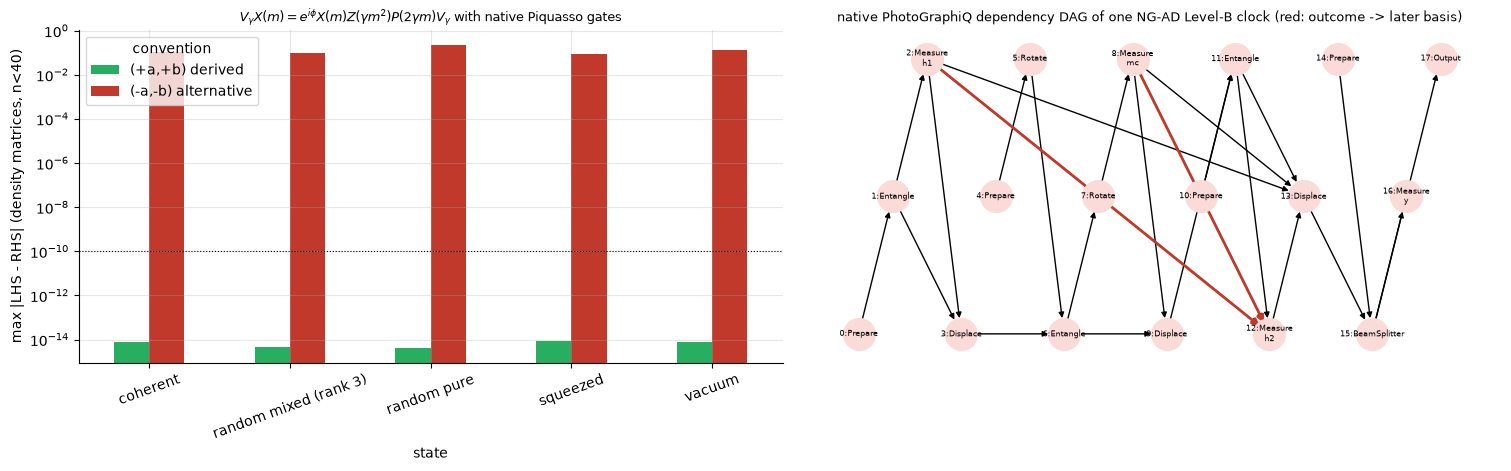

**Fig02_cubic_byproduct_algebra_and_causal_flow.** Mode preflight; deterministic tests (no realizations or trajectories); cutoff 160 (identity) / native pattern; uncertainty: none (exact). Left: the derived convention (green) vs the alternative sign convention (red). Right: the causal measurement flow.

PASS [E12] (critical) causal MBQC ordering on the native PhotoGraphiQ patterns: layer-2 angle depends on h1 (and mc in NG-AD) only in AD arms, and every schedule measures h1 -> mc -> h2: 4/4 (criterion 4/4)
PASS [E13] homodyne-quadrature convergence: tap outcomes from the same 256 states and innovations with 2D+20 vs 2D+60 Gauss-Hermite position nodes: 1.55e-13 (criterion < 1e-6)
PASS [E14] Level-B resource quality: the Fock-truncated ancilla at D_res=60 is the physical approximate resource; fidelity to the cutoff-converged finite-energy state (gamma=0.45, 6.0 dB; truncation norm loss 8.3e-15): 0.991 (criterion >= 0.99)


PASS [N1] (critical) checkpoint/resume: interrupted after 2 of 4 units, resumed -> identical results (2 reused + 2 recomputed): hits=2, misses=2 (criterion identical, 2+2)
PASS [N2] (critical) bitwise seed reproduction (Level B, NG-AD): identical (criterion identical)
[10.4 causality, convergence, reproducibility] 1.0 s | peak RSS 1518 MB


In [21]:
with section("10.2 physics and nesting"):
    D7 = CFG["cutoffs"][0]; KT = 12
    def _small_run(level, arm, kind, D=D7, N=1, B=24, gamma=0.2, enabled=True, seed="nest", K=KT, xp=np, collect=("rb", "y", "m")):
        r_ = Reservoir(EXPLORATION_SEEDS[3], N, D, 0.5, gamma, level=level, variant="V2", xp=xp, D_res=CFG["D_res"]); r_.adaptive_enabled = enabled
        U = np.tile(input_sequence(EXPLORATION_SEEDS[3], 0, K)[:, None], (1, B)); inn = draw_innovations(rng_for(seed, N), B, N, K)
        return r_, run_paths(r_, arm, U, inn, kind=kind, collect=collect)
    # E7 physicality on density matrices (NG-AD, both levels)
    phys = []
    for level in ("A", "B"):
        r_ = Reservoir(EXPLORATION_SEEDS[3], 1, D7, 0.5, 0.25, level=level, variant="V2", D_res=CFG["D_res"]); st7 = r_.vacuum(16, "dm")
        inn = draw_innovations(rng_for("phys"), 16, 1, KT); mem = dict(filt=np.zeros((16, 1)), prev_stat=np.zeros((16, 1)), prev_corr=np.zeros((16, 1)))
        for k in range(KT):
            out = clock(r_, st7, np.full(16, 0.4 * np.sin(k)), xi_at(inn, k, np), "NG-AD", mem)
            R = st7.r; ev = np.linalg.eigvalsh(0.5 * (R + R.conj().transpose(0, 2, 1)))
            phys.append((float(np.abs(np.trace(R, axis1=1, axis2=2) - 1).max()), float(np.abs(R - R.conj().transpose(0, 2, 1)).max()), float(ev.min()),
                         float(np.abs(np.asarray(out.get("grid_mass", [np.ones(1)]))[0] - 1).max())))
    phys = np.array(phys)
    # outcome-density normalization of the teleportation and injection laws (quadrature)
    o7 = fock_ops(D7); w7 = np.abs(rng10.normal(size=(1, D7))) ** 2; w7 /= w7.sum(); mm = np.linspace(-60, 60, 24001)
    norm_t = float(np.trapezoid(gmix_density(np.repeat(w7, len(mm), 0), -o7.lam, float(np.exp(2 * db_to_r(12))), mm, np), mm))
    R7 = get_resource(0.3, db_to_r(BASE["resource_squeezing_db"]), CFG["D_res"], 1.0, np)
    norm_r = float(np.trapezoid(R7.density(np.repeat(w7, len(mm), 0), o7.lam, mm, np.zeros(len(mm), int)), mm))
    record_test("E7a", "physics", "density matrices after every clock (NG-AD, Levels A, B): |tr - 1|, Hermiticity", float(max(phys[:, 0].max(), phys[:, 1].max())),
                f"< {PREREGISTERED['trace_tol']}", phys[:, 0].max() < PREREGISTERED["trace_tol"] and phys[:, 1].max() < PREREGISTERED["herm_tol"])
    record_test("E7b", "physics", "minimum density-matrix eigenvalue over all clocks", float(phys[:, 2].min()), f"> {PREREGISTERED['mineig_tol']}", phys[:, 2].min() > PREREGISTERED["mineig_tol"])
    e7c = max(abs(norm_t - 1), abs(norm_r - 1))
    record_test("E7c", "physics", "outcome laws normalized: teleportation (12 dB) and cubic-injection densities integrate to 1", e7c, f"< {PREREGISTERED['prob_norm_tol']}",
                e7c < PREREGISTERED["prob_norm_tol"])
    record_test("E7d", "numerical", "tap-law quadrature mass (Gauss-Hermite position quadrature of the exact density) - 1", float(phys[:, 3].max()), "< 1e-6", phys[:, 3].max() < 1e-6, critical=False)
    # E8 exact nesting (bitwise)
    nest = []
    for level in ("A", "B"):
        for a_, b_ in [("NG-NA", "G-NA"), ("NG-AD", "G-AD")]:
            _, x1 = _small_run(level, a_, "vec", gamma=0.0); _, x2 = _small_run(level, b_, "vec", gamma=0.0)
            nest.append(all(np.array_equal(x1[k], x2[k]) for k in ("rb", "y", "m", "logp", "maxb")))
        _, x1 = _small_run(level, "NG-AD", "vec", enabled=False); _, x2 = _small_run(level, "NG-NA", "vec")
        nest.append(all(np.array_equal(x1[k], x2[k]) for k in ("rb", "y", "m", "logp", "maxb")))
    record_test("E8", "physics", "exact nesting, bitwise (states via features and log-likelihoods, outcomes, trajectory diagnostics), Levels A and B: "
                "gamma=0 => NG-NA == G-NA and NG-AD == G-AD; adaptive correction disabled => NG-AD == NG-NA", f"{sum(nest)}/{len(nest)} identical", "all identical", all(nest))
    # E9 samplers (Kolmogorov-Smirnov against the exact CDF)
    B9 = 20000; w9 = np.repeat(w7, B9, 0); V9 = float(np.exp(2 * db_to_r(12)))
    m9 = sample_gmix(w9, -o7.lam, V9, rng10.random(B9), np)
    ks1 = sst.kstest(m9, lambda x: (w7[0][None] * ssp.ndtr((np.atleast_1d(x)[:, None] + o7.lam[None]) / np.sqrt(V9))).sum(1)).pvalue
    psi9 = np.zeros((B9, D7), complex); psi9[:, :4] = (rng10.normal(size=4) + 1j * rng10.normal(size=4)); psi9 /= np.linalg.norm(psi9[0])
    st9 = VecState(o7, psi9[:1].copy()); tp9 = o7.tap(0.5, 4001); dens9, _ = st9.tap_density(0, tp9)
    d0 = dens9[0]; cdf9 = np.concatenate([[0], np.cumsum(0.5 * (d0[1:] + d0[:-1]) * tp9["dy"])]); cdf9 /= cdf9[-1]
    Rs = Reservoir(EXPLORATION_SEEDS[3], 1, D7, 0.5, 0.0); Rs.ops = o7
    st9b = VecState(o7, psi9.copy()); xi9y = rng10.random(B9); tpS = o7.tap(0.5, CFG["tap_grid"]); wS = st9b.pos_weights(0, tpS)
    yS = sample_gmix(wS / wS.sum(1, keepdims=True), tpS["s"] * tpS["xq"], 0.5, xi9y, np)
    ks2 = sst.kstest(yS, lambda x: np.interp(x, tp9["yg"], cdf9)).pvalue
    record_test("E9", "numerical", f"inverse-CDF samplers vs exact conditional laws (KS p-values, {B9} draws): teleportation outcome {ks1:.3f}, tap outcome {ks2:.3f}",
                min(ks1, ks2), "> 0.001", min(ks1, ks2) > 0.001)
    # E10 vec vs dm
    _, xv = _small_run("A", "NG-AD", "vec", B=8); _, xd = _small_run("A", "NG-AD", "dm", B=8)
    e10 = float(max(np.abs(xv["rb"] - xd["rb"]).max(), np.abs(xv["y"] - xd["y"]).max()))
    record_test("E10", "engine", "state-vector and density-matrix engines: identical features and outcomes on common innovations", e10, "< 1e-10", e10 < 1e-10)

with section("10.3 device selection"):
    DEVICE = "cpu"; GPU_AGREE = np.nan; BENCH = {}
    def _bench(xp, B, D=CFG["cutoffs"][-1], K=4):
        r_ = Reservoir(EXPLORATION_SEEDS[4], 1, D, 0.5, 0.2, level="A", variant="V2", xp=xp)
        U = np.tile(input_sequence(EXPLORATION_SEEDS[4], 1, K)[:, None], (1, B)); inn = draw_innovations(rng_for("bench"), B, 1, K)
        t0 = time.perf_counter(); out = run_paths(r_, "NG-AD", U, inn, collect=("rb",))
        if xp is not np:
            xp.cuda.Device().synchronize()
        return time.perf_counter() - t0, out["rb"]
    tc, fc = _bench(np, 16384)        # production-size batch: the GPU is latency bound below ~8k paths
    BENCH["cpu"] = tc
    if CUPY_OK:
        try:
            _bench(cp, 256)
            free, total = cp.cuda.runtime.memGetInfo(); VRAM_BUDGET = float(min(0.35 * free, 2.0e9))
            tg, fg = _bench(cp, 16384); BENCH["gpu"] = tg
            GPU_AGREE = float(np.abs(fg - fc).max())
            record_test("E11", "engine", f"CPU/GPU agreement of NG-AD features (16384 paths x 4 clocks; CPU {tc:.2f} s, GPU {tg:.2f} s)", GPU_AGREE,
                        f"< {PREREGISTERED['gpu_tol']}", GPU_AGREE < PREREGISTERED["gpu_tol"])
            DEVICE = "gpu" if (GPU_AGREE < PREREGISTERED["gpu_tol"] and tg < tc) else "cpu"
        except Exception as exc:                                           # noqa: BLE001
            print("GPU path failed:", type(exc).__name__, str(exc)[:200])
    XP = cp if DEVICE == "gpu" else np
    print(f"device for trajectory ensembles: {DEVICE} | benchmark {BENCH} | VRAM chunk budget {VRAM_BUDGET / 2**20:.0f} MB")

with section("10.4 causality, convergence, reproducibility"):
    resC = Reservoir(EXPLORATION_SEEDS[0], 1, 30, 0.6, 0.2, level="B", variant="V2", cond=condE, D_res=30)
    causal = []
    for arm in ARMS:
        pat = native_clock_pattern(resC, 0.2, arm); sched = pat.schedule()
        meas = {c.result_key: (i, c) for i, c in enumerate(pat.commands) if isinstance(c, Measure)}
        deps_h2 = set(pg.expressions.dependencies(meas["h2"][1].measurement.angle))
        order_ok = sched.index(meas["h1"][0]) < sched.index(meas["mc"][0]) < sched.index(meas["h2"][0])
        causal.append(order_ok and ((deps_h2 >= {"h1", "mc"}) if arm == "NG-AD" else (deps_h2 >= {"h1"}) if arm == "G-AD" else (not deps_h2)))
    patF = native_clock_pattern(resC, 0.2, "NG-AD"); Gd = patF.dependencies()
    fig, axs = plt.subplots(1, 2, figsize=(15, 4.6))
    piv_id = ID_DF.pivot_table(index="state", columns="convention", values="max_abs_err")
    piv_id.plot.bar(ax=axs[0], logy=True, color=["#27ae60", "#c0392b"]); axs[0].axhline(1e-10, color="k", ls=":", lw=0.8); axs[0].set_ylabel("max |LHS - RHS| (density matrices, n<40)")
    axs[0].set_title(r"$V_\gamma X(m)=e^{i\phi}X(m)Z(\gamma m^2)P(2\gamma m)V_\gamma$ with native Piquasso gates", fontsize=9); axs[0].tick_params(axis="x", rotation=20)
    lab = {i: f"{i}:{type(c).__name__}" + (f"\n{c.result_key}" if isinstance(c, Measure) else "") for i, c in enumerate(patF.commands)}
    pos = {i: (i, (i % 3) * 0.6) for i in Gd.nodes}
    nx.draw_networkx(Gd, pos=pos, ax=axs[1], labels=lab, node_size=520, font_size=5.5, node_color="#fadbd8", arrowsize=8)
    adaptive = [(u_, v_) for u_, v_ in Gd.edges if isinstance(patF.commands[u_], Measure) and isinstance(patF.commands[v_], Measure)]
    nx.draw_networkx_edges(Gd, pos=pos, ax=axs[1], edgelist=adaptive, edge_color="#c0392b", width=2.0, arrowsize=10)
    axs[1].set_title("native PhotoGraphiQ dependency DAG of one NG-AD Level-B clock (red: outcome -> later basis)", fontsize=9); axs[1].axis("off")
    show_fig(fig, "Fig02_cubic_byproduct_algebra_and_causal_flow", f"Mode {RUN_MODE}; deterministic tests (no realizations or trajectories); cutoff 160 (identity) / native pattern; "
             "uncertainty: none (exact). Left: the derived convention (green) vs the alternative sign convention (red). Right: the causal measurement flow.")
    record_test("E12", "physics", "causal MBQC ordering on the native PhotoGraphiQ patterns: layer-2 angle depends on h1 (and mc in NG-AD) only in AD arms, "
                "and every schedule measures h1 -> mc -> h2", f"{sum(causal)}/4", "4/4", all(causal))
    rg_, _ = _small_run("A", "NG-AD", "vec", B=256, K=4)
    stg = VecState(rg_.ops, VecState(rg_.ops, np.tile(np.eye(rg_.D)[0], (256, 1)).astype(complex)).psi)
    stg.psi = (rng10.normal(size=(256, rg_.D)) + 1j * rng10.normal(size=(256, rg_.D))) * np.exp(-0.35 * np.arange(rg_.D))[None]; stg.normalize()
    xig = rng10.random(256); yg_ = []
    for extra in (0, 40):
        rg_.ops.extra_nodes = extra; tpg = rg_.ops.tap(rg_.T, CFG["tap_grid"]); wg_ = stg.pos_weights(0, tpg)
        yg_.append(sample_gmix(wg_ / wg_.sum(1, keepdims=True), tpg["s"] * tpg["xq"], rg_.T, xig, np))
    rg_.ops.extra_nodes = 0
    e13 = float(np.abs(yg_[0] - yg_[1]).max())
    record_test("E13", "numerical", f"homodyne-quadrature convergence: tap outcomes from the same 256 states and innovations with 2D+20 vs 2D+60 Gauss-Hermite position nodes",
                e13, "< 1e-6", e13 < 1e-6, critical=False)
    g_mx, r_mx = max(CFG["gamma_grid"] + CFG["level_a_gammas"]), db_to_r(BASE["resource_squeezing_db"])
    Rmax = get_resource(g_mx, r_mx, CFG["D_res"], 1.0, np); Rref = CubicResource(g_mx, r_mx, 2 * CFG["D_res"] + 40, 1.0, np)
    fid_res = float(abs(np.vdot(Rref.amps[:CFG["D_res"]], Rmax.amps)) ** 2)
    record_test("E14", "numerical", f"Level-B resource quality: the Fock-truncated ancilla at D_res={CFG['D_res']} is the physical approximate resource; fidelity to the "
                f"cutoff-converged finite-energy state (gamma={g_mx}, {BASE['resource_squeezing_db']} dB; truncation norm loss {1 - Rmax.norm_retained:.1e})", fid_res, ">= 0.99",
                fid_res >= 0.99, critical=False)
    tmp = CKPT / "_resume_test"; shutil.rmtree(tmp, ignore_errors=True)
    unit_fn = lambda i: dict(v=_small_run("A", "NG-AD", "vec", B=4, seed=("ck", i), K=3)[1]["rb"])
    full = [CheckpointStore(tmp / "a").cached("u", dict(i=i), lambda i=i: unit_fn(i)) for i in range(4)]
    s2 = CheckpointStore(tmp / "b")
    try:
        for i in range(4):
            if i == 2:
                raise KeyboardInterrupt
            s2.cached("u", dict(i=i), lambda i=i: unit_fn(i))
    except KeyboardInterrupt:
        pass
    s3 = CheckpointStore(tmp / "b"); resumed = [s3.cached("u", dict(i=i), lambda i=i: unit_fn(i)) for i in range(4)]
    ok_res = all(np.array_equal(a["v"], b["v"]) for a, b in zip(full, resumed)) and s3.hits == 2 and s3.misses == 2
    record_test("N1", "numerical", "checkpoint/resume: interrupted after 2 of 4 units, resumed -> identical results (2 reused + 2 recomputed)", f"hits={s3.hits}, misses={s3.misses}",
                "identical, 2+2", ok_res); shutil.rmtree(tmp, ignore_errors=True)
    _, r1 = _small_run("B", "NG-AD", "vec", B=6); _, r2 = _small_run("B", "NG-AD", "vec", B=6)
    record_test("N2", "numerical", "bitwise seed reproduction (Level B, NG-AD)", "identical" if all(np.array_equal(r1[k], r2[k]) for k in ("rb", "y", "m")) else "differ", "identical",
                all(np.array_equal(r1[k], r2[k]) for k in ("rb", "y", "m")))

### 10.5 Statistical machinery and its tests
* **Readouts.** Ridge with intercept on standardized features, with $\lambda$ chosen per target on the last 25 % of the training block from the common grid. Degree-2 readouts use the same pipeline after a label-free, training-only PCA to `poly_pca_dim` components, followed by all monomials of degree ≤ 2. Every arm gets identical feature count, output dimension, regularization grid, training data and tuning budget.
* **Inference.**
  * paired one-sided $t$ on realization means;
  * Holm over the primary family $\{\Delta_A,\Delta_B,\Delta_C,\Delta_{\rm int}\}$ (NARMA5, linear);
  * Benjamini–Hochberg over secondary endpoints;
  * nested bootstrap over realizations, input sequences and trajectory replicates;
  * Monte-Carlo power of the exact analysis.

In [22]:
PAD = 25
def leg(n, x):
    return np.sqrt(2 * n + 1) * npleg.legval(x, [0] * n + [1])

def lagged(u, t):
    out = np.zeros_like(u); out[t:] = u[:len(u) - t] if t else u; return out

def narma(u, order):
    v = 0.25 * (u + 1); y = np.zeros(len(u))
    for k in range(order, len(u)):
        y[k] = 0.3 * y[k - 1] + 0.05 * y[k - 1] * y[k - order:k].sum() + 1.5 * v[k - 1] * v[k - order] + 0.1
    return np.clip(y, -10, 10)

def poly2(X, W, Ltr, dim):
    Xtr = X[W:W + Ltr]; mu, sd = Xtr.mean(0), Xtr.std(0); sd = np.where(sd > 1e-12, sd, 1.0); Z = (X - mu) / sd
    _, _, Vt = np.linalg.svd(Z[W:W + Ltr] - Z[W:W + Ltr].mean(0), full_matrices=False); k = min(dim, Vt.shape[0]); P_ = Z @ Vt[:k].T
    P_ = np.c_[P_, np.zeros((len(P_), dim - k))]; ii, jj = np.triu_indices(dim)
    return np.c_[P_, P_[:, ii] * P_[:, jj]]

def readout_nmse(X, targets, W, Ltr, lam_grid=None, fixed_lambda=None, return_pred=False):
    lam_grid = CFG["ridge_grid"] if lam_grid is None else lam_grid; W = max(W, PAD); X = np.asarray(X, float)
    if not np.isfinite(X[W:]).all():
        return {k: np.nan for k in targets}, {}
    Xtr, Xte = X[W:W + Ltr], X[W + Ltr:]; mu, sd = Xtr.mean(0), Xtr.std(0); sd = np.where(sd > 1e-12 * max(1.0, np.abs(mu).max()), sd, 1.0)
    Z, Zte = (Xtr - mu) / sd, (Xte - mu) / sd
    Y = np.stack([targets[k][W:W + Ltr] for k in targets], 1); Yte = np.stack([targets[k][W + Ltr:] for k in targets], 1); nv = int(0.75 * Ltr)
    def fit(Zf, Yf, lams):
        zm, ym = Zf.mean(0), Yf.mean(0); U_, s_, Vt = np.linalg.svd(Zf - zm, full_matrices=False); UtY = U_.T @ (Yf - ym)
        return [(Vt.T @ ((s_ / (s_ ** 2 + l))[:, None] * UtY), zm, ym) for l in lams]
    if fixed_lambda is None:
        errs = np.array([((Z[nv:] - zm) @ w + ym - Y[nv:]) ** 2 for (w, zm, ym) in fit(Z[:nv], Y[:nv], lam_grid)]).mean(1)
        best = [lam_grid[i] for i in errs.argmin(0)]
    else:
        best = [fixed_lambda] * Y.shape[1]
    out, chosen, preds = {}, {}, {}
    for j, k in enumerate(targets):
        (w, zm, ym), = fit(Z, Y[:, [j]], [best[j]]); pred = (Zte - zm) @ w + ym
        out[k] = float(np.mean((pred[:, 0] - Yte[:, j]) ** 2) / np.var(Yte[:, j])); chosen[k] = best[j]; preds[k] = pred[:, 0]
    return (out, chosen, preds) if return_pred else (out, chosen)

def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); adj = np.empty_like(p); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, min(1.0, (len(p) - rank) * p[i])); adj[i] = run
    return adj

def bh(pvals):
    p = np.asarray(pvals, float); n = len(p); order = np.argsort(p); adj = np.empty_like(p); run = 1.0
    for rank in range(n - 1, -1, -1):
        i = order[rank]; run = min(run, p[i] * n / (rank + 1)); adj[i] = run
    return adj

def paired_onesided(D):
    m = np.nanmean(D, 1) if np.ndim(D) == 2 else np.asarray(D, float); m = m[np.isfinite(m)]; n = len(m)
    if n < 2:
        return (float(np.mean(m)) if n else np.nan), np.nan, np.nan
    se = m.std(ddof=1) / np.sqrt(n); t = m.mean() / se if se > 0 else np.inf * np.sign(m.mean())
    return float(m.mean()), float(t), float(sst.t.sf(t, n - 1))

def hier_bootstrap(D, B, rng):
    """Nested bootstrap over realizations (rows) and replicates (columns: input sequences x trajectory replicates)."""
    R, J = D.shape; out = np.empty(B)
    for b in range(B):
        rr = rng.integers(0, R, R); jj = rng.integers(0, J, (R, J)); out[b] = np.nanmean(D[rr[:, None], jj])
    return out

def variance_components(D):
    R, J = D.shape; s2_rep = float(np.nanmean(np.nanvar(D, axis=1, ddof=1))) if J > 1 else 0.0
    s2_real = max(0.0, float(np.nanvar(np.nanmean(D, 1), ddof=1)) - s2_rep / J) if R > 1 else 0.0
    return s2_real, s2_rep

def analyse(D, delta_min, B, rng):
    mean, t, p = paired_onesided(D); boot = hier_bootstrap(D, B, rng); m = np.nanmean(D, 1)
    return dict(n_realizations=int(np.isfinite(m).sum()), mean=mean, median=float(np.nanmedian(m)), ci_low=float(np.percentile(boot, 2.5)), ci_high=float(np.percentile(boot, 97.5)),
                upper95=float(np.percentile(boot, 95)), d=float(mean / np.nanstd(m, ddof=1)) if np.nanstd(m, ddof=1) > 0 else np.nan, t=t, p_one_sided=p,
                P_exceeds_delta_min=float((boot > delta_min).mean()), max_single_share=float(np.nanmax(np.abs(m)) / max(np.nansum(np.abs(m)), 1e-300)))

def power_holm(deltas, cov, n, alpha, sims, rng):
    """Monte-Carlo power of one-sided paired t tests with Holm over len(deltas) correlated primary contrasts (cov: per-realization covariance)."""
    k = len(deltas); m = rng.multivariate_normal(deltas, cov + 1e-15 * np.eye(k), size=(sims, n))
    t = m.mean(1) / (m.std(1, ddof=1) / np.sqrt(n)); p = sst.t.sf(t, n - 1); rej = np.array([holm(pp) < alpha for pp in p])
    return rej.mean(0), float(rej.all(1).mean())

with section("10.5 statistical tests"):
    rng = rng_for("suite")
    disjoint = all(not (set(a) & set(b)) for (ka, a), (kb, b) in itertools.combinations(BANKS.items(), 2))
    led = json.loads(LEDGER_PATH.read_text()) if LEDGER_PATH.exists() else {}
    record_test("S1", "statistical", "six seed banks pairwise disjoint; confirmation bank used by no stage other than 'confirmation' (ledger)", f"disjoint={disjoint}, "
                f"confirmation stages={list(led.get('confirmation', {}))}", "True, none", disjoint and set(led.get("confirmation", {})) <= {"confirmation"})
    uS = input_sequence(0, 4, 900); tS = dict(NARMA5=narma(uS, 5), mem1=lagged(uS, 1)); XS = np.c_[uS, lagged(uS, 1) ** 2, np.sin(3 * lagged(uS, 2))] + 0.05 * rng.normal(size=(900, 3))
    sa, la = readout_nmse(XS, tS, 100, 500); XS2 = XS.copy(); XS2[600:] = XS2[600:] * 7 + 3; sb, lb = readout_nmse(XS2, tS, 100, 500)
    P1, P2 = poly2(XS, 100, 500, 3), poly2(XS2, 100, 500, 3)
    record_test("S2", "statistical", "no train/test leakage: corrupting test features leaves scaler, PCA and lambda selection unchanged", "unchanged" if la == lb and
                np.allclose(P1[100:600], P2[100:600]) else "changed", "unchanged", la == lb and np.allclose(P1[100:600], P2[100:600]))
    def verify_lock(path):
        L_ = json.loads(Path(path).read_text()); h = L_.pop("sha256"); return hashlib.sha256(json.dumps(L_, sort_keys=True, default=str).encode()).hexdigest() == h
    tl = RES / "_lock_test.json"; L0 = dict(gamma_star=0.2, T_star=0.5); L0["sha256"] = hashlib.sha256(json.dumps(L0, sort_keys=True).encode()).hexdigest()
    tl.write_text(json.dumps(L0)); good = verify_lock(tl); L0["gamma_star"] = 0.3; tl.write_text(json.dumps(L0)); tampered = verify_lock(tl); tl.unlink()
    record_test("S3", "statistical", "lock enforcement: a tampered lock manifest is rejected", f"intact={good}, tampered accepted={tampered}", "True, False", good and not tampered)
    Dsyn = 0.05 + rng.normal(0, 0.03, (12, 1)) + rng.normal(0, 0.02, (12, 4)); r4 = analyse(Dsyn, 0.03, 2000, rng)
    record_test("S4", "statistical", "paired analysis recovers an injected difference 0.05 (inside the 95% CI)", f"{r4['mean']:.4f} [{r4['ci_low']:.4f}, {r4['ci_high']:.4f}]", "in CI",
                r4["ci_low"] <= 0.05 <= r4["ci_high"])
    sds = [hier_bootstrap(rng.normal(0, 0.03, (15, 1)) + rng.normal(0, 0.04, (15, 3)), 300, rng).std() for _ in range(150)]; se_true = np.sqrt(0.03 ** 2 / 15 + 0.04 ** 2 / 45)
    record_test("S5", "statistical", "nested bootstrap SE / analytic nested SE", np.mean(sds) / se_true, "in [0.85, 1.15]", 0.85 <= np.mean(sds) / se_true <= 1.15)
    C4 = 0.5 * np.eye(4) + 0.5; m0 = rng.multivariate_normal(np.zeros(4), C4, size=(4000, 10)); p0 = sst.t.sf(m0.mean(1) / (m0.std(1, ddof=1) / np.sqrt(10)), 9)
    fwer = float(np.mean([(holm(p) < PREREGISTERED["alpha"]).any() for p in p0]))
    pnull = rng.random((2000, 8)); fdr_null = float(np.mean([(bh(p) < PREREGISTERED["fdr_q"]).any() for p in pnull]))
    record_test("S6", "statistical", f"null calibration: family-wise error of one-sided Holm over 4 correlated primary contrasts ({fwer:.3f}); BH any-rejection rate under the global null ({fdr_null:.3f})",
                max(fwer, fdr_null), "<= alpha + 0.012", fwer <= PREREGISTERED["alpha"] + 0.012 and fdr_null <= PREREGISTERED["fdr_q"] + 0.012)
    dl = np.full(4, 0.6); pw, pall = power_holm(dl, np.eye(4), 15, PREREGISTERED["alpha"], 3000, rng)
    ncp = 0.6 * np.sqrt(15); pt_bound = sst.nct.sf(sst.t.isf(PREREGISTERED["alpha"] / 4, 14), 14, ncp)
    record_test("S7", "statistical", "Holm power simulation vs the Bonferroni noncentral-t lower bound (each contrast)", f"{pw.min():.3f} vs {pt_bound:.3f}", "sim >= bound - 0.03",
                pw.min() >= pt_bound - 0.03)

PASS [S1] (critical) six seed banks pairwise disjoint; confirmation bank used by no stage other than 'confirmation' (ledger): disjoint=True, confirmation stages=[] (criterion True, none)
PASS [S2] (critical) no train/test leakage: corrupting test features leaves scaler, PCA and lambda selection unchanged: unchanged (criterion unchanged)
PASS [S3] (critical) lock enforcement: a tampered lock manifest is rejected: intact=True, tampered accepted=False (criterion True, False)
PASS [S4] (critical) paired analysis recovers an injected difference 0.05 (inside the 95% CI): 0.0454 [0.0300, 0.0607] (criterion in CI)


PASS [S5] (critical) nested bootstrap SE / analytic nested SE: 1.05 (criterion in [0.85, 1.15])
PASS [S6] (critical) null calibration: family-wise error of one-sided Holm over 4 correlated primary contrasts (0.048); BH any-rejection rate under the global null (0.050): 0.05 (criterion <= alpha + 0.012)
PASS [S7] (critical) Holm power simulation vs the Bonferroni noncentral-t lower bound (each contrast): 0.544 vs 0.450 (criterion sim >= bound - 0.03)
[10.5 statistical tests] 0.9 s | peak RSS 1518 MB


## 11. Level A — ideal cubic screening

> **Ideal logical cubic-gate screening model; not a physical MBQC realization.**

One ideal Piquasso-equivalent `CubicPhase` (§10, E1) acts per clock in the byproduct frame of the layer-1 teleportation (§6, §8). This is a cheap test of whether cubic non-Gaussianity, together with the derived adaptive correction, can generate a stable, readout-visible **adaptive–non-Gaussian interaction** at all.

**Screening protocol (preregistered).**
* Points: $\gamma\in$ `level_a_gammas` at $T=$ `level_a_T`, one mode, the middle cutoff.
* `n_screen` exploration realizations, all three controller variants. Controller scales are frozen on the calibration bank first.
* A point is **admissible** only if *all four arms* are hierarchically stable, because the factorial interaction needs every arm.
* **Variant rule:** largest mean exploration $\chi^\times_{\rm wh}$ over the variant's admissible screening points.
* **Level A passes** if the selected variant has at least one admissible point with $\chi^\times_{\rm int}$ SNR ≥ `snr_screen` and $\chi^\times_{\rm wh}$ SNR ≥ `snr_screen`.
* If Level A fails, the decision is `NO-GO`, and the physical Level B route (§12) is not pursued.

frozen controller scales (calibration bank, 4 realizations, D=20, T=0.5): {'m1': 4.157906284282007, 'filt': 2.3460158658269417, 'byp': 4.157906284282007}
[11.1 calibration (Level A)] 25.6 s | peak RSS 1518 MB


,variant,gamma,admissible,stable_G-NA,stable_G-AD,stable_NG-NA,stable_NG-AD,esc_rate_G-NA,esc_rate_G-AD,esc_rate_NG-NA,esc_rate_NG-AD,chi_int_x,chi_int_x_snr,chi_wh_x,chi_wh_x_snr,chi_wh_G,chi_wh_G_snr,ng_rel_entropy_NG-AD,survivor_conditioned
0,V1,0.1,False,False,False,False,False,0.0083,0.0083,0.0542,0.00586,0.00239,3,1.2,4.93,0,NaN,0.00277,True
1,V1,0.2,False,False,False,False,True,0.0083,0.0083,0.227,0.00146,0.00584,2.98,1.9,4.11,0,NaN,0.0114,True
2,V1,0.3,False,False,False,False,True,0.0083,0.0083,0.4,0.00342,0.00703,3.12,1.77,3.94,0,NaN,0.0297,True
3,V2,0.1,False,False,False,False,False,0.0083,0.00879,0.0542,0.00293,0.00257,3.02,1.21,4.84,0.019,1.66,0.00276,True
4,V2,0.2,False,False,False,False,True,0.0083,0.00879,0.227,0.00244,0.00637,2.96,1.96,3.95,0.00742,1.92,0.0113,True
5,V2,0.3,False,False,False,False,True,0.0083,0.00879,0.4,0.00293,0.00774,3.06,1.84,3.87,0.00503,2.22,0.0316,True
6,V3,0.1,False,False,False,False,False,0.0083,0.0083,0.0542,0.00293,0.00251,3.06,1.2,4.86,0.0141,1.99,0.0028,True
7,V3,0.2,False,False,False,False,False,0.0083,0.0083,0.227,0.00342,0.00621,3,1.95,3.95,0.00576,2.65,0.0118,True
8,V3,0.3,False,False,False,False,False,0.0083,0.0083,0.4,0.00342,0.00753,3.11,1.82,3.92,0.00393,3.14,0.0329,True


variant scores (mean exploration chi_wh^x over admissible screening points): {} -> selected V1
LEVEL A SCREENING: FAIL (no admissible screening point (some arm unstable at every gamma))


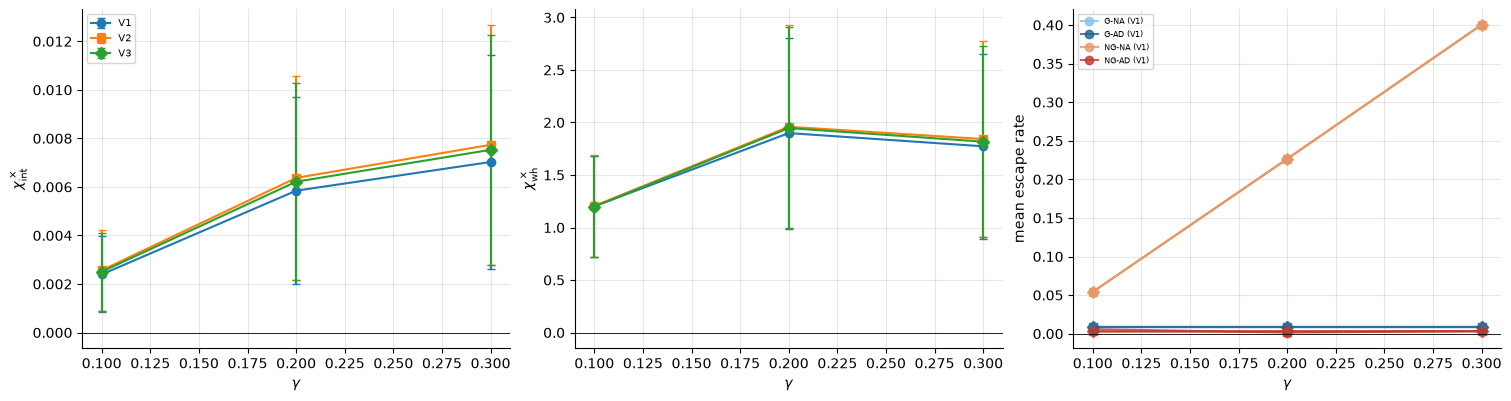

**Fig_A_level_A_screening.** Mode preflight; 4 reservoir realizations; 1024 (kernels), 512 (stability) trajectories per realization and arm; Fock cutoff D=20; cluster squeezing 12.0 dB; uncertainty: 1.96 x SE (jackknife over path blocks, combined with between-realization SD); exploratory. Level-A screening at T=0.5: factorial interaction and per-arm escape rates for the three preregistered variants; selected variant V1; decision FAIL.

[11.2 Level-A screening] 994.4 s | peak RSS 2784 MB


In [23]:
def kcfg():
    """Configuration entries that change a structural unit (part of every checkpoint key)."""
    return {k: CFG[k] for k in CFG if k.startswith(("kernel", "stab", "shots", "tap", "D_res"))}

def caption(text, *, n_real, n_traj, D, sq_db=None, unc="1.96 x SE (jackknife over path blocks, combined with between-realization SD)", kind="exploratory"):
    sq = BASE["squeezing_db"] if sq_db is None else sq_db
    return (f"Mode {RUN_MODE}; {n_real} reservoir realizations; {n_traj} trajectories per realization and arm; Fock cutoff D={D}; cluster squeezing {sq} dB; "
            f"uncertainty: {unc}; {kind}. {text}")

def summarize_point(rows):
    """Combine realizations at one structural point."""
    s = dict(gamma=rows[0]["gamma"], T=rows[0]["T"], D=rows[0]["D"], N=rows[0]["N"], level=rows[0]["level"], variant=rows[0]["variant"], n=len(rows))
    for key in ("chi_int_x", "chi_vis_x", "chi_wh_x", "chi_res_x", "chi_wh_G", "chi_vis_G", "chi_int_G", "chi_wh_NG", "chi_wh_NGvG", "chi_wh_NGNA") + \
               tuple(f"chi_wh_x_{c}" for c in ("indep", "shift", "iid")) + tuple(f"chi_int_x_{c}" for c in ("indep", "shift", "iid")):
        if any(key in r for r in rows):
            c = combine_realizations(rows, key); s[key], s[key + "_se"], s[key + "_snr"] = c["est"], c["se"], c["snr"]
    for a in ARMS:
        h = hier_escape(rows, a); s[f"stable_{a}"], s[f"esc_upper_{a}"], s[f"esc_rate_{a}"] = h["stable"], h["upper95"], h["mean_rate"]
        s[f"unstable_{a}"] = h["unstable"]
        for kk in ("ng_rel_entropy", "abs_k3x", "abs_k4x", "purity_uncond", "maxb", "boundary_final", "entanglement", "sigma_m1", "sigma_byp"):
            v = [r.get(f"{kk}_{a}", np.nan) for r in rows]
            if np.isfinite(v).any():
                s[f"{kk}_{a}"] = float(np.nanmean(v)) if kk != "maxb" else float(np.nanmax(v))
    s["admissible"] = all(s[f"stable_{a}"] for a in ARMS)
    s["survivor_conditioned"] = any(sum(r.get("kernel_escaped", {}).values()) > 0 for r in rows)
    if any("rec_info_NG-AD" in r for r in rows):
        s["rec_info_NG-AD"] = float(np.nanmean([r.get("rec_info_NG-AD", np.nan) for r in rows]))
    if any("comp_wh" in r for r in rows):
        cw = np.mean([r["comp_wh"] for r in rows if "comp_wh" in r], 0); s["comp_wh"] = cw; s["comps"] = next(r["comps"] for r in rows if "comps" in r)
    s["seconds"] = float(sum(r.get("seconds", 0) for r in rows)); s["peak_rss_mb"] = float(max(r.get("peak_rss_mb", 0) for r in rows))
    s["shots_needed"] = 25.0 * CFG["shots"] / s["chi_wh_x"] if s.get("chi_wh_x", 0) > 0 else np.inf     # accepted shots per feature estimate for whitened SNR 5
    return s

def run_points(N, D, T, gammas, rids, *, level, variant, cond, sigma, ctrls=(), tag="point", M=None):
    """Checkpointed batch of structural points (one unit per T and gamma set)."""
    key = dict(N=N, D=D, T=T, gammas=[float(g_) for g_ in gammas], rids=list(rids), level=level, variant=variant, cond=cond, sigma=sigma, ctrls=list(ctrls), cfg=kcfg(), M=M)
    rows = STORE.cached(tag, key, lambda: structural_points(N, D, T, gammas, rids, level=level, variant=variant, cond=cond, sigma=sigma, ctrls=ctrls, M=M))
    if isinstance(rows, dict) and rows.get("failed"):
        FAILED_UNITS.append(dict(stage=tag, T=T, gammas=list(gammas), level=level, variant=variant, reason=rows["reason"], traceback=rows.get("traceback", "")[-400:]))
        return []
    return rows

RESEARCH_BLOCKED = RUN_MODE == "research" and not RESEARCH_ALLOWED
LEVEL_A_PASS, VARIANT, SCREEN, SIGMA_A, D_A, T_A = None, "V1", pd.DataFrame(), None, CFG["cutoffs"][len(CFG["cutoffs"]) // 2], CFG["level_a_T"]
if RUN_MODE == "unit" or RESEARCH_BLOCKED:
    print("Level-A screening not executed:", "unit mode (tests only)" if RUN_MODE == "unit" else "research mode is blocked (§5)")
else:
    with section("11.1 calibration (Level A)"):
        SIGMA_A = STORE.cached("calib", dict(level="A", N=1, D=D_A, T=T_A, cond=BASE, n=CFG["n_calib"], cp=CFG["calib_paths"], ck=CFG["calib_clocks"]),
                               lambda: calibrate_sigma(1, D_A, T_A, "A", cond=BASE))
        ledger_use("calibration", "calibration", range(CFG["n_calib"])); (RES / "sigma_level_A.json").write_text(json.dumps(SIGMA_A))
        print(f"frozen controller scales (calibration bank, {CFG['n_calib']} realizations, D={D_A}, T={T_A}): {SIGMA_A}")
    with section("11.2 Level-A screening"):
        rids_s = EXPLORATION_SEEDS[:CFG["n_screen"]]; SCREEN_ROWS = []
        for variant in PREREGISTERED["variants"]:
            rows = run_points(1, D_A, T_A, CFG["level_a_gammas"], rids_s, level="A", variant=variant, cond=BASE, sigma=SIGMA_A, tag="screenA")
            SCREEN_ROWS += rows
        ledger_use("level-A screening", "exploration", range(CFG["n_screen"]))
        SCREEN = pd.DataFrame([summarize_point([r for r in SCREEN_ROWS if r["variant"] == v and r["gamma"] == g_])
                               for v in PREREGISTERED["variants"] for g_ in CFG["level_a_gammas"] if any(r["variant"] == v and r["gamma"] == g_ for r in SCREEN_ROWS)])
        show_cols = ["variant", "gamma", "admissible"] + [f"stable_{a}" for a in ARMS] + [f"esc_rate_{a}" for a in ARMS] + \
                    ["chi_int_x", "chi_int_x_snr", "chi_wh_x", "chi_wh_x_snr", "chi_wh_G", "chi_wh_G_snr", "ng_rel_entropy_NG-AD", "survivor_conditioned"]
        with pd.option_context("display.width", 250, "display.max_columns", 40, "display.float_format", "{:.3g}".format):
            display(SCREEN[[c for c in show_cols if c in SCREEN]])
        score = {v: SCREEN[(SCREEN.variant == v) & SCREEN.admissible].chi_wh_x.mean() for v in PREREGISTERED["variants"]} if len(SCREEN) else {}
        score = {v: s_ for v, s_ in score.items() if np.isfinite(s_)}
        VARIANT = max(score, key=score.get) if score else "V1"
        sel = SCREEN[(SCREEN.variant == VARIANT)] if len(SCREEN) else SCREEN
        passing = sel[sel.admissible & (sel.chi_int_x_snr >= PREREGISTERED["snr_screen"]) & (sel.chi_wh_x_snr >= PREREGISTERED["snr_screen"])] if len(sel) else sel
        LEVEL_A_PASS = bool(len(passing))
        LEVEL_A_REASON = ("passed at gamma = " + ", ".join(f"{g_:g}" for g_ in passing.gamma)) if LEVEL_A_PASS else (
            "no admissible screening point (some arm unstable at every gamma)" if not score else
            "no admissible screening point with chi_int^x and chi_wh^x SNR >= " + str(PREREGISTERED["snr_screen"]))
        print(f"variant scores (mean exploration chi_wh^x over admissible screening points): {score} -> selected {VARIANT}")
        print(f"LEVEL A SCREENING: {'PASS' if LEVEL_A_PASS else 'FAIL'} ({LEVEL_A_REASON})")
        (RES / "level_A_screening.json").write_text(json.dumps(dict(variant=VARIANT, scores=score, passed=LEVEL_A_PASS, reason=LEVEL_A_REASON), default=str))
        if len(SCREEN):
            fig, axs = plt.subplots(1, 3, figsize=(15, 3.9))
            for v, mk in zip(PREREGISTERED["variants"], "osD"):
                d = SCREEN[SCREEN.variant == v]
                axs[0].errorbar(d.gamma, d.chi_int_x, 1.96 * d.chi_int_x_se, fmt=mk + "-", capsize=3, label=v)
                axs[1].errorbar(d.gamma, d.chi_wh_x, 1.96 * d.chi_wh_x_se, fmt=mk + "-", capsize=3, label=v)
                for a in ARMS:
                    axs[2].plot(d.gamma, d[f"esc_rate_{a}"], mk + "-", color=COL[a], alpha=0.8, label=f"{a} ({v})" if v == "V1" else None)
            axs[0].set_ylabel(r"$\chi^\times_{\rm int}$"); axs[1].set_ylabel(r"$\chi^\times_{\rm wh}$"); axs[2].set_ylabel("mean escape rate")
            for ax in axs:
                ax.set_xlabel(r"$\gamma$"); ax.axhline(0, color="k", lw=0.6)
            axs[0].legend(fontsize=7); axs[2].legend(fontsize=6)
            show_fig(fig, "Fig_A_level_A_screening", caption(f"Level-A screening at T={T_A}: factorial interaction and per-arm escape rates for the three preregistered variants; "
                     f"selected variant {VARIANT}; decision {'PASS' if LEVEL_A_PASS else 'FAIL'}.", n_real=CFG["n_screen"], n_traj=f"{CFG['kernel_paths']} (kernels), {CFG['stab_paths']} (stability)", D=D_A))

## 12. Level B — physical cubic-resource teleportation

**Model** (native PhotoGraphiQ pattern `resource_injection` with `CubicPhaseResource`; batched by the exact adapter, validated in E4):
1. Prepare the finite-energy approximate ancilla $V_\gamma S(-r_c)|0\rangle$ with native Piquasso gates on a Fock cutoff `D_res`. The truncated, renormalized state *is* the physical approximate resource; its fidelity is reported (E14).
2. Entangle it with the logical mode through the inverse SUM gate ($A$, $\mathrm{CZ}(-1)$, $A^\dagger$).
3. Homodyne the resource ($q$). The outcome $m_c$ is sampled from the exact state-dependent law $p(m_c)=\sum_i w_i|\varphi_\gamma(\lambda_i+m_c)|^2$.
4. Apply the derived corrections. $Z(-\gamma m_c^2)$ is applied in every NG arm. The adaptive $P(-2\gamma m_c)$ enters through the layer-2 homodyne angle, and only in NG–AD.
5. The unmeasured logical mode is retained as the recurrent state.
6. Physical imperfections (`BASE_B`): finite cluster and resource squeezing, loop loss, resource loss before injection (mixture unravelled), detector efficiency and resolution on every homodyne (hidden true outcome plus noise), and feed-forward gain error on every correction.

The Gaussian arms inject the $\gamma=0$ resource $S(-r_c)|0\rangle$ through the identical pattern, so resources match and nesting is exact (E8).

**Gate.** Level B is executed only if Level A passed (or in `research_dryrun`, for control flow). The pass rule is the same as Level A's. If Level B is executed and passes, it becomes the primary model for §13–§20; otherwise the primary model is Level A (decision `NO-GO`).

In [24]:
RUN_B = (LEVEL_A_PASS is True and not RESEARCH_BLOCKED) or RUN_MODE == "research_dryrun"
LEVEL_B_PASS, SCREEN_B, SIGMA_B = None, pd.DataFrame(), None
if not RUN_B:
    print("Level B not executed:", "unit mode" if RUN_MODE == "unit" else ("research mode blocked" if RESEARCH_BLOCKED else
          "the ideal Level-A screening failed - preregistered: no substantial effort on the physical route after a failed screening"))
else:
    with section("12.1 Level-B calibration and resource"):
        SIGMA_B = STORE.cached("calib", dict(level="B", N=1, D=D_A, T=T_A, cond=BASE_B, n=CFG["n_calib"], cp=CFG["calib_paths"], ck=CFG["calib_clocks"], Dr=CFG["D_res"]),
                               lambda: calibrate_sigma(1, D_A, T_A, "B", cond=BASE_B))
        print(f"Level-B controller scales: {SIGMA_B}")
        fid_rows = []
        for g_ in CFG["level_a_gammas"]:
            for db in CFG["resource_db_grid"]:
                Rq = get_resource(g_, db_to_r(db), CFG["D_res"], 1.0, np); Rr = CubicResource(g_, db_to_r(db), 2 * CFG["D_res"] + 40, 1.0, np)
                fid_rows.append(dict(gamma=g_, resource_db=db, fidelity=float(abs(np.vdot(Rr.amps[:CFG["D_res"]], Rq.amps)) ** 2), boundary=Rq.boundary))
        RES_QUALITY = pd.DataFrame(fid_rows); display(RES_QUALITY.pivot_table(index="gamma", columns="resource_db", values="fidelity").round(4))
    with section("12.2 Level-B screening"):
        rows = run_points(1, D_A, T_A, CFG["level_a_gammas"], EXPLORATION_SEEDS[:CFG["n_screen"]], level="B", variant=VARIANT, cond=BASE_B, sigma=SIGMA_B, tag="screenB")
        SCREEN_B = pd.DataFrame([summarize_point([r for r in rows if r["gamma"] == g_]) for g_ in CFG["level_a_gammas"] if any(r["gamma"] == g_ for r in rows)])
        with pd.option_context("display.width", 250, "display.float_format", "{:.3g}".format):
            display(SCREEN_B[[c for c in ["gamma", "admissible"] + [f"esc_rate_{a}" for a in ARMS] + ["chi_int_x", "chi_int_x_snr", "chi_wh_x", "chi_wh_x_snr",
                                                                                                       "ng_rel_entropy_NG-AD"] if c in SCREEN_B]])
        okB = SCREEN_B[SCREEN_B.admissible & (SCREEN_B.chi_int_x_snr >= PREREGISTERED["snr_screen"]) & (SCREEN_B.chi_wh_x_snr >= PREREGISTERED["snr_screen"])] if len(SCREEN_B) else SCREEN_B
        LEVEL_B_PASS = bool(len(okB))
        print(f"LEVEL B (physical cubic-resource teleportation, BASE_B imperfections): {'PASS' if LEVEL_B_PASS else 'FAIL'}"
              + (" (dry run: control flow only)" if RUN_MODE == "research_dryrun" else ""))
PRIMARY = (dict(level="B", cond=BASE_B, sigma=SIGMA_B, label="Level B (physical cubic-resource teleportation)") if (RUN_B and LEVEL_B_PASS) or (RUN_MODE == "research_dryrun" and RUN_B)
           else dict(level="A", cond=BASE, sigma=SIGMA_A, label="Level A (ideal logical cubic gate; screening model)"))
print("primary model for §13-§20:", PRIMARY["label"], "| controller variant", VARIANT)

Level B not executed: the ideal Level-A screening failed - preregistered: no substantial effort on the physical route after a failed screening
primary model for §13-§20: Level A (ideal logical cubic gate; screening model) | controller variant V1


## 13. Non-Gaussianity certification and cutoff convergence

**Estimators** ($\hbar=2$, $\alpha=(x+ip)/2$):
* Wigner function $W(x,p)=\frac1{2\pi}\mathrm{Tr}[\rho\,D(\alpha)\Pi D(\alpha)^\dagger]$, evaluated by the Laguerre series. The negativity volume is $\delta_W=\int|W|-1$ (Kenfack–Życzkowski);
* standardized third and fourth cumulants of $\hat x$ and $\hat p$. These are exact from untruncated moment matrices, with a bias-corrected finite-shot skewness ($k$-statistic) from simulated homodyne samples;
* relative-entropy non-Gaussianity $\delta_{\rm RE}=S(\rho_G)-S(\rho)$, with $\rho_G$ the Gaussian state with the same first and second moments, $S(\rho_G)=g(\nu)$;
* trace distance $\tfrac12\|\rho-\rho_G\|_1$, with $\rho_G$ built from exact squeezing, rotation and displacement operators acting on a thermal mixture.

Each estimator is first validated on vacuum, coherent, squeezed, Fock $|1\rangle$ and an ideal cubic-phase test state. The physical non-Gaussian states are then the conditional (and ensemble) logical states of NG–AD at the best screening point, evaluated at three cutoffs. Non-Gaussianity is certified only if it exceeds both the finite-sample SE and the change between the two largest cutoffs.

The same three-cutoff runs (common random numbers, so differences are truncation effects) give the convergence of the structural quantities and the Fock-boundary populations. The smallest converged cutoff is used for the full Lyapunov spectra of §14.

In [25]:
def wigner_grid(rho, xs, ps):
    """W(x,p) on a grid, hbar = 2, from the Laguerre series (validated on known states below)."""
    D = rho.shape[0]; X, Pp = np.meshgrid(xs, ps, indexing="ij"); A = (X + 1j * Pp) / 2; r2 = 4 * np.abs(A) ** 2
    W = np.zeros_like(X)
    for m in range(D):
        W += (rho[m, m].real * (-1) ** m * ssp.eval_genlaguerre(m, 0, r2))
        for n in range(m + 1, D):
            if abs(rho[m, n]) < 1e-15:
                continue
            W += 2 * np.real(rho[m, n] * (-1) ** m * (2 * np.conj(A)) ** (n - m) * np.sqrt(np.exp(ssp.gammaln(m + 1) - ssp.gammaln(n + 1))) * ssp.eval_genlaguerre(m, n - m, r2))
    return W * np.exp(-r2 / 2) / (2 * np.pi)

def wigner_negativity(rho, L=None, n=161):
    D = rho.shape[0]; L = L or (2 * np.sqrt(D) + 4); xs = np.linspace(-L, L, n); W = wigner_grid(rho, xs, xs); dA = (xs[1] - xs[0]) ** 2
    return float(np.abs(W).sum() * dA - 1), float(W.sum() * dA)

def moments_xp(rho):
    D = rho.shape[0]; a = np.diag(np.sqrt(np.arange(1, D + 8)), 1); xq, pq_ = a + a.T, -1j * (a - a.T)
    R = np.zeros((D + 8, D + 8), complex); R[:D, :D] = rho; ev = lambda O: float(np.trace(R @ O).real)
    mx, mp = ev(xq), ev(pq_)
    cov = np.array([[ev(xq @ xq) - mx * mx, 0.5 * ev(xq @ pq_ + pq_ @ xq) - mx * mp], [0.5 * ev(xq @ pq_ + pq_ @ xq) - mx * mp, ev(pq_ @ pq_) - mp * mp]])
    cum = {}
    for nm, O, mu in (("x", xq, mx), ("p", pq_, mp)):
        c = O - mu * np.eye(D + 8); v = ev(c @ c); cum[f"k3{nm}"] = ev(c @ c @ c) / v ** 1.5; cum[f"k4{nm}"] = ev(c @ c @ c @ c) / v ** 2 - 3
    return np.array([mx, mp]), cov, cum

def gauss_entropy(cov):
    nu = float(np.sqrt(max(np.linalg.det(cov), 1.0)))
    return 0.0 if nu <= 1 + 1e-12 else float((nu + 1) / 2 * np.log((nu + 1) / 2) - (nu - 1) / 2 * np.log((nu - 1) / 2))

def gaussian_reference(mean, cov, D):
    """rho_G = D(mu) R(phi) S(r) rho_th(nbar) S^dag R^dag D^dag (Williamson parameters from mean, cov), built with exact operators on an enlarged
    cutoff and truncated; the rotation sense is fixed by requiring the reference to reproduce the target moments (checked in G1)."""
    nu = float(np.sqrt(max(np.linalg.det(cov), 1.0))); nbar = (nu - 1) / 2; ev, evec = np.linalg.eigh(cov / nu)
    r = 0.25 * np.log(ev[1] / ev[0]); phi0 = float(np.arctan2(evec[1, 0], evec[0, 0])); alpha = complex(mean[0], mean[1]) / 2
    Dw = D + 40; a = np.diag(np.sqrt(np.arange(1, Dw)), 1); n = np.arange(Dw)
    pk = (nbar ** n / (1 + nbar) ** (n + 1)) if nbar > 1e-14 else (n == 0).astype(float)
    S = sla.expm(0.5 * r * (a @ a - a.T @ a.T)); Dm = sla.expm(alpha * a.T - np.conj(alpha) * a); best = None
    for sgn in (1, -1):
        U = Dm @ np.diag(np.exp(1j * sgn * phi0 * n)) @ S; rho = (U * pk[None]) @ U.conj().T; rho = rho[:D, :D]
        m_, c_, _ = moments_xp(rho / np.trace(rho).real); err = max(np.abs(m_ - mean).max(), np.abs(c_ - cov).max())
        if best is None or err < best[0]:
            best = (err, rho)
    return best[1]

def ng_measures(rho, wigner=True):
    mean, cov, cum = moments_xp(rho); D = rho.shape[0]; rhoG = gaussian_reference(mean, cov, D)
    mG, cG, _ = moments_xp(rhoG / np.trace(rhoG).real)
    evr = np.linalg.eigvalsh(0.5 * (rho + rho.conj().T)); S_rho = float(-(evr[evr > 1e-14] * np.log(evr[evr > 1e-14])).sum())
    dd = rho - rhoG / np.trace(rhoG).real; td = float(0.5 * np.abs(np.linalg.eigvalsh(0.5 * (dd + dd.conj().T))).sum())
    out = dict(rel_entropy=gauss_entropy(cov) - S_rho, trace_distance=td, gauss_ref_moment_err=float(max(np.abs(mG - mean).max(), np.abs(cG - cov).max())), **cum)
    if wigner:
        out["wigner_negativity"], out["wigner_norm"] = wigner_negativity(rho)
    return out

with section("13.1 non-Gaussianity estimator validation"):
    Dv = 40; ests = {}
    tests = {"vacuum": pq_state([], Dv), "coherent": pq_state([pq.Displacement(r=0.5, phi=0.6)], Dv), "squeezed": pq_state([pq.Squeezing(r=0.4, phi=0.3)], Dv),
             "Fock |1>": np.eye(Dv)[1].astype(complex), "ideal cubic (gamma=0.3, 3 dB)": pq_state([pq.Squeezing(r=-db_to_r(3)), pq.CubicPhase(gamma=0.3)], Dv)}
    for nm, v in tests.items():
        ests[nm] = ng_measures(np.outer(v, v.conj()))
    NGV = pd.DataFrame(ests).T; display(NGV[["wigner_negativity", "wigner_norm", "rel_entropy", "trace_distance", "k3x", "k4x", "k3p", "gauss_ref_moment_err"]].map(lambda x: f"{x:.3g}"))
    gauss_ok = all(abs(NGV.loc[k, c]) < 1e-6 for k in ("vacuum", "coherent", "squeezed") for c in ("rel_entropy", "trace_distance", "k3x", "k4x", "k3p")) and \
               all(NGV.loc[k, "wigner_negativity"] < 1e-6 for k in ("vacuum", "coherent", "squeezed"))
    fock_ok = abs(NGV.loc["Fock |1>", "wigner_negativity"] - 0.4261) < 2e-3 and NGV.loc["Fock |1>", "rel_entropy"] > 0.5
    cubic_ok = all(NGV.loc["ideal cubic (gamma=0.3, 3 dB)", c] > 1e-3 for c in ("wigner_negativity", "rel_entropy", "trace_distance")) and abs(NGV.loc["ideal cubic (gamma=0.3, 3 dB)", "k3p"]) > 1e-3
    record_test("G1", "physics", "non-Gaussianity estimators vanish on Gaussian states (vacuum, coherent, squeezed): Wigner negativity, relative entropy, trace distance, cumulants; "
                "Gaussian reference reproduces the moments", f"max moment error {NGV.gauss_ref_moment_err.max():.1e}", "all < 1e-6", gauss_ok and NGV.gauss_ref_moment_err.max() < 1e-6)
    record_test("G2", "physics", "Fock |1>: Wigner negativity volume = 0.4261 (Kenfack-Zyczkowski); ideal cubic-phase state: every non-Gaussianity measure > 0",
                f"{NGV.loc['Fock |1>', 'wigner_negativity']:.4f}", "0.4261 +- 2e-3; cubic > 0", fock_ok and cubic_ok)

,wigner_negativity,wigner_norm,rel_entropy,trace_distance,k3x,k4x,k3p,gauss_ref_moment_err
vacuum,2.89e-15,1,0,0,0,4.44e-16,0,0
coherent,3.11e-15,1,2.22e-16,2.03e-16,-5.55e-16,-1.33e-15,-3.89e-16,2.22e-16
squeezed,2.19e-09,1,0,1.09e-16,0,3.69e-14,0,4.44e-16
Fock |1>,0.428,1,1.39,0.75,0,-1.33,0,7.28e-11
"ideal cubic (gamma=0.3, 3 dB)",0.18,1,0.671,0.364,0,0.017,0.792,8.88e-16


PASS [G1] (critical) non-Gaussianity estimators vanish on Gaussian states (vacuum, coherent, squeezed): Wigner negativity, relative entropy, trace distance, cumulants; Gaussian reference reproduces the moments: max moment error 7.3e-11 (criterion all < 1e-6)
PASS [G2] (critical) Fock |1>: Wigner negativity volume = 0.4261 (Kenfack-Zyczkowski); ideal cubic-phase state: every non-Gaussianity measure > 0: 0.4276 (criterion 0.4261 +- 2e-3; cubic > 0)
[13.1 non-Gaussianity estimator validation] 2.5 s | peak RSS 2784 MB


best screening point (Level A (ideal logical cubic gate; screening model), V1): gamma=0.2, T=0.5, admissible=False


,D,chi_int_x,chi_wh_x,chi_vis_x,esc_rate_G-NA,esc_rate_G-AD,esc_rate_NG-NA,esc_rate_NG-AD,boundary_final_G-NA,boundary_final_G-AD,boundary_final_NG-NA,boundary_final_NG-AD,maxb_G-NA,maxb_G-AD,maxb_NG-NA,maxb_NG-AD
0,16,0.008,1.57,0.632,0.00195,0.00195,0.0732,0,2.87e-09,2.87e-09,3.79e-06,8.91e-08,0.00213,0.00213,0.0037,0.000827
1,20,0.00811,1.77,0.966,0.0166,0.0166,0.209,0.00293,1.28e-11,1.28e-11,1.9e-07,1.67e-09,3.99e-05,3.99e-05,0.000315,0.000146
2,24,0.00804,1.88,1.28,0.00879,0.00879,0.875,0.0508,5.48e-14,5.48e-14,1.52e-08,3.36e-11,7.31e-06,7.31e-06,2.85e-05,4.64e-06


relative change between the two largest cutoffs: {'chi_int_x': 0.008425096825452427, 'chi_wh_x': 0.060180139271601304, 'chi_vis_x': 0.244937010280401}; boundary population at D=20: {'G-NA': 1.2822028339864519e-11, 'G-AD': 1.2822028339864519e-11, 'NG-NA': 1.898294846009724e-07, 'NG-AD': 1.6670930041375475e-09}
CUTOFF CONVERGED: False; smallest converged cutoff used for full spectra: D=16 (none converged: smallest cutoff, flagged)
escape rate vs cutoff (rising or flat = physical instability; falling = truncation): {'G-NA': [np.float64(0.002), np.float64(0.0166), np.float64(0.0088)], 'G-AD': [np.float64(0.002), np.float64(0.0166), np.float64(0.0088)], 'NG-NA': [np.float64(0.0732), np.float64(0.209), np.float64(0.875)], 'NG-AD': [np.float64(0.0), np.float64(0.0029), np.float64(0.0508)]}
[13.2 cutoff convergence] 168.1 s | peak RSS 2784 MB


,D,n_states,wigner_negativity,wigner_negativity_se,ensemble_wigner_negativity,rel_entropy,rel_entropy_se,ensemble_rel_entropy,trace_distance,trace_distance_se,ensemble_trace_distance,k3x,k3x_se,ensemble_k3x,k3p,k3p_se,ensemble_k3p,shot_skew_x,shot_skew_x_se
0,16,16,0.0002636,0.0001124,9.1e-07,0.0107,0.001783,0.005778,0.021,0.002167,0.02515,0.08463,0.008044,0.06512,0.01908,0.004434,-0.02411,0.04358,0.006267
1,20,16,0.0002016,6.079e-05,2.466e-07,0.01054,0.001826,0.005847,0.02085,0.002197,0.02525,0.08353,0.008139,0.06545,0.01934,0.004569,-0.024,0.1441,0.008156
2,24,16,0.0001431,4.081e-05,2.362e-07,0.0104,0.001839,0.005803,0.02069,0.00222,0.02519,0.08337,0.008169,0.06566,0.01907,0.004559,-0.02368,0.1769,0.00898


NG certification (value - 3 SE > change between the two largest cutoffs): {'wigner_negativity': False, 'rel_entropy': True, 'trace_distance': True} -> certified: True
[13.3 NG certification of reservoir states] 34.0 s | peak RSS 2784 MB


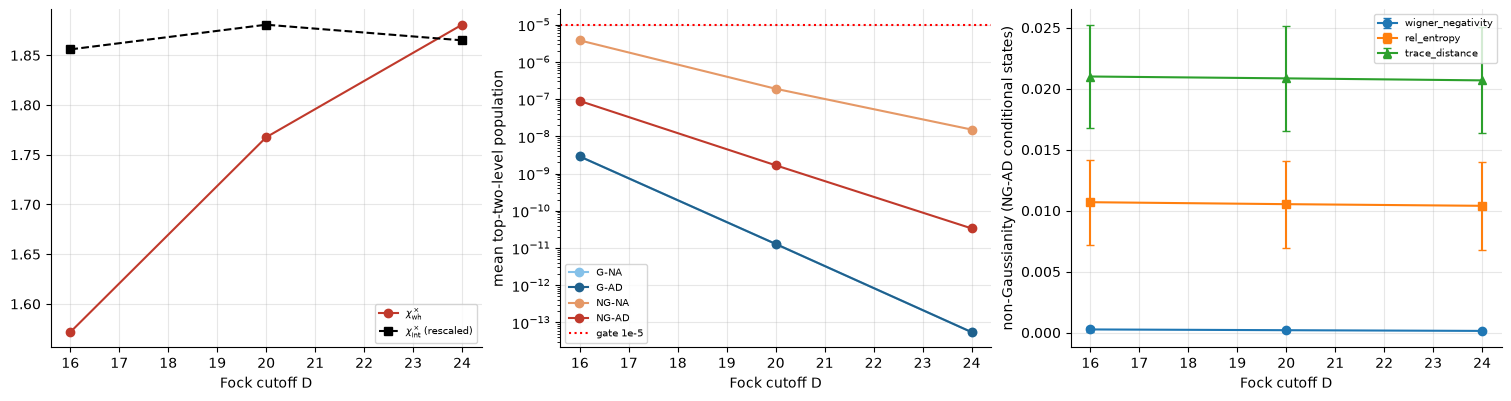

**Fig04_cutoff_convergence_and_boundary.** Mode preflight; 2 reservoir realizations; 1024 (kernels) / 256 (NG states, 16 evaluated) trajectories per realization and arm; Fock cutoff D=[16, 20, 24]; cluster squeezing 12.0 dB; uncertainty: 1.96 x SE (jackknife over path blocks, combined with between-realization SD); exploratory. Cutoff convergence at the best screening point (gamma=0.2, T=0.5, Level A (ideal logical cubic gate; screening model), V1) with common random numbers; Fock-boundary populations per arm; non-Gaussianity of NG-AD conditional states. Converged: False; NG certified: True.

In [26]:
def best_point(screen):
    if not len(screen):
        return None
    s = screen[screen.admissible] if screen.admissible.any() else screen
    return s.sort_values("chi_wh_x", ascending=False).iloc[0]

SCREEN_PRIMARY = SCREEN_B if PRIMARY["level"] == "B" and len(SCREEN_B) else SCREEN[SCREEN.variant == VARIANT] if len(SCREEN) else SCREEN
BEST = best_point(SCREEN_PRIMARY); CONV = {}; NG_CERT = {}; LYAP_D = CFG["cutoffs"][0]; NG_CERTIFIED = False; CUTOFF_CONVERGED = False
if BEST is None:
    print("cutoff convergence and NG certification of the reservoir states not executed:", "unit mode" if RUN_MODE == "unit" else "no screening data")
else:
    g_b, T_b = float(BEST["gamma"]), float(BEST["T"])
    print(f"best screening point ({PRIMARY['label']}, {VARIANT}): gamma={g_b}, T={T_b}, admissible={bool(BEST["admissible"])}")
    with section("13.2 cutoff convergence"):
        conv_rows = []
        for D_ in CFG["cutoffs"]:
            rows = run_points(1, D_, T_b, [g_b], EXPLORATION_SEEDS[:min(2, CFG["n_screen"])], level=PRIMARY["level"], variant=VARIANT, cond=PRIMARY["cond"],
                              sigma=PRIMARY["sigma"], tag="cutoff")
            if rows:
                s = summarize_point(rows); s["D"] = D_; conv_rows.append(s)
        CONV = pd.DataFrame(conv_rows)
        cols = ["D", "chi_int_x", "chi_wh_x", "chi_vis_x"] + [f"esc_rate_{a}" for a in ARMS] + [f"boundary_final_{a}" for a in ARMS] + [f"maxb_{a}" for a in ARMS]
        with pd.option_context("display.width", 250, "display.float_format", "{:.3g}".format):
            display(CONV[[c for c in cols if c in CONV]])
        def relchg(col):
            v = CONV[col].values; return float(abs(v[-1] - v[-2]) / max(abs(v[-1]), 1e-300)) if len(v) >= 2 else np.nan
        CONV_REL = {c: relchg(c) for c in ("chi_int_x", "chi_wh_x", "chi_vis_x") if c in CONV}
        bnd = {a: float(CONV[f"boundary_final_{a}"].iloc[-2]) if f"boundary_final_{a}" in CONV and len(CONV) >= 2 else np.nan for a in ARMS}
        CUTOFF_CONVERGED = bool(CONV_REL) and all(v < PREREGISTERED["cutoff_rel_change"] for v in CONV_REL.values()) and \
                           all(bnd[a] < PREREGISTERED["boundary_pop_max"] for a in ("G-NA", "G-AD", "NG-AD"))
        conv_D = [int(D_) for k_, D_ in enumerate(CONV.D[:-1]) if all(abs(CONV[c].iloc[k_] - CONV[c].iloc[k_ + 1]) / max(abs(CONV[c].iloc[k_ + 1]), 1e-300) < PREREGISTERED["cutoff_rel_change"]
                                                                       for c in CONV_REL) and CONV.get("boundary_final_NG-AD", pd.Series([1.0] * len(CONV))).iloc[k_] < PREREGISTERED["boundary_pop_max"]]
        LYAP_D = conv_D[0] if conv_D else int(CONV.D.iloc[0])
        print(f"relative change between the two largest cutoffs: {CONV_REL}; boundary population at D={CONV.D.iloc[-2] if len(CONV) >= 2 else '-'}: {bnd}")
        print(f"CUTOFF CONVERGED: {CUTOFF_CONVERGED}; smallest converged cutoff used for full spectra: D={LYAP_D}{'' if conv_D else ' (none converged: smallest cutoff, flagged)'}")
        esc_trend = {a: list(np.round(CONV[f"esc_rate_{a}"].values, 4)) for a in ARMS}
        print("escape rate vs cutoff (rising or flat = physical instability; falling = truncation):", esc_trend)
    with section("13.3 NG certification of reservoir states"):
        ng_rows = []
        for D_ in CFG["cutoffs"]:
            res_ = Reservoir(EXPLORATION_SEEDS[0], 1, D_, T_b, g_b, level=PRIMARY["level"], variant=VARIANT, cond=PRIMARY["cond"], sigma=PRIMARY["sigma"], xp=XP)
            Kc = min(200, CFG["stab_clocks"]); Mp = 256; u_ = input_sequence(EXPLORATION_SEEDS[0], 1000, Kc)
            o_ = run_paths(res_, "NG-AD", np.tile(u_[:, None], (1, Mp)), draw_innovations(rng_for("stab-inn", EXPLORATION_SEEDS[0], 1, 0), Mp, 1, Kc), collect=(), keep_state=True)
            psi_ = o_["psi"][o_["alive"]]; nsub = min(16, len(psi_))
            per = [ng_measures(np.outer(v, v.conj()), wigner=True) for v in psi_[:nsub]]
            rbar = psi_.T @ psi_.conj() / len(psi_); ens = ng_measures(rbar, wigner=True)
            row = dict(D=D_, n_states=nsub)
            for k_ in ("wigner_negativity", "rel_entropy", "trace_distance", "k3x", "k3p"):
                v = np.array([p_[k_] for p_ in per]); row[k_] = float(np.mean(np.abs(v)) if k_.startswith("k3") else np.mean(v)); row[k_ + "_se"] = float(np.std(np.abs(v) if k_.startswith("k3") else v, ddof=1) / np.sqrt(len(v)))
                row["ensemble_" + k_] = ens[k_]
            xs_ = []
            for v in psi_[:nsub]:
                xg = np.linspace(-15, 15, 4001); dens = np.abs(herm_fns(xg, D_) @ v) ** 2; cdf = np.cumsum(dens); cdf /= cdf[-1]
                smp = np.interp(rng_for("ngshots", D_).random(CFG["shots"]), cdf, xg); n_ = len(smp); m2 = ((smp - smp.mean()) ** 2).mean(); m3 = ((smp - smp.mean()) ** 3).mean()
                xs_.append(n_ ** 2 / ((n_ - 1) * (n_ - 2)) * m3 / (n_ / (n_ - 1) * m2) ** 1.5)
            row["shot_skew_x"] = float(np.mean(np.abs(xs_))); row["shot_skew_x_se"] = float(np.std(np.abs(xs_), ddof=1) / np.sqrt(len(xs_)))
            ng_rows.append(row)
        NG_CERT = pd.DataFrame(ng_rows)
        with pd.option_context("display.width", 250, "display.float_format", "{:.4g}".format):
            display(NG_CERT)
        last, prev = NG_CERT.iloc[-1], NG_CERT.iloc[-2] if len(NG_CERT) >= 2 else NG_CERT.iloc[-1]
        cert = {}
        for k_ in ("wigner_negativity", "rel_entropy", "trace_distance"):
            num_err = abs(last[k_] - prev[k_]); cert[k_] = bool(last[k_] - 3 * last[k_ + "_se"] > num_err and last[k_] > 0)
        NG_CERTIFIED = sum(cert.values()) >= 2
        print(f"NG certification (value - 3 SE > change between the two largest cutoffs): {cert} -> certified: {NG_CERTIFIED}")
    fig, axs = plt.subplots(1, 3, figsize=(15, 3.9))
    if len(CONV):
        axs[0].plot(CONV.D, CONV.chi_wh_x, "o-", color=COL["NG-AD"], label=r"$\chi^\times_{\rm wh}$"); axs[0].plot(CONV.D, CONV.chi_int_x * CONV.chi_wh_x.max() / max(CONV.chi_int_x.max(), 1e-300), "s--", color="k", label=r"$\chi^\times_{\rm int}$ (rescaled)")
        for a in ARMS:
            axs[1].semilogy(CONV.D, np.maximum(CONV[f"boundary_final_{a}"], 1e-18) if f"boundary_final_{a}" in CONV else np.nan, "o-", color=COL[a], label=a)
        axs[1].axhline(PREREGISTERED["boundary_pop_max"], color="r", ls=":", label="gate 1e-5")
    if len(NG_CERT):
        for k_, mk in (("wigner_negativity", "o"), ("rel_entropy", "s"), ("trace_distance", "^")):
            axs[2].errorbar(NG_CERT.D, NG_CERT[k_], 1.96 * NG_CERT[k_ + "_se"], fmt=mk + "-", capsize=3, label=k_)
    axs[0].set_xlabel("Fock cutoff D"); axs[1].set_xlabel("Fock cutoff D"); axs[2].set_xlabel("Fock cutoff D")
    axs[1].set_ylabel("mean top-two-level population"); axs[2].set_ylabel("non-Gaussianity (NG-AD conditional states)")
    for ax in axs:
        ax.legend(fontsize=7)
    show_fig(fig, "Fig04_cutoff_convergence_and_boundary", caption(f"Cutoff convergence at the best screening point (gamma={g_b}, T={T_b}, {PRIMARY['label']}, {VARIANT}) with common "
             f"random numbers; Fock-boundary populations per arm; non-Gaussianity of NG-AD conditional states. Converged: {CUTOFF_CONVERGED}; NG certified: {NG_CERTIFIED}.",
             n_real=min(2, CFG["n_screen"]), n_traj=f"{CFG['kernel_paths']} (kernels) / 256 (NG states, {min(16, 256)} evaluated)", D=str(CFG["cutoffs"])))

## 14. Density-matrix Lyapunov spectra

After a non-Gaussian operation, $(r,\mathrm{vech}\,\Gamma)$ is not a state representation, so first- and second-moment exponents are **not** the spectrum of the state. Here the tangent space is the full space of traceless Hermitian perturbations,
$$\delta\rho=\sum_{a=1}^{d^2-1}z_aF_a,\qquad \mathrm{Tr}(F_aF_b)=\delta_{ab},$$
of the truncated density matrix ($d=D$, one mode).

* **Common-innovation (CI) spectrum.** The Jacobian of the normalized conditional clock map, with perturbed copies driven by the *same uniform innovations*, so their outcomes respond to the perturbation through the inverse CDF. Computed by central finite differences.
* **Common-record (CR) spectrum** (filter stability). The same map with the *outcomes held fixed* at the reference trajectory's record.
* **Unconditional channel spectrum.** Within a clock, every outcome-dependent operation (layer-1 filter, cubic byproduct, adaptive shear) is a function of $\hat x$, and the input enters only before them. The outcome-averaged map is therefore a fixed Schur multiplier $G$ in the DVR basis,
$$\mathcal E_u(\rho)=\mathcal L_{T}\Big(\mathcal D_V\big[A\,(G\odot (A P_{c_1(u)}\rho P^\dagger_{c_1(u)}A^\dagger))\,A^\dagger\big]\Big),\qquad G_{ij}=\int dm\,K_i(m)K_j^*(m)\,e^{i(e_i(m)-e_j(m))}.$$
  Here $\mathcal D_V$ is the layer-2 dephasing and $\mathcal L_T$ the tap-plus-loss channel. $G$ is exact up to a quadrature that is tested against the closed form for G–NA. The spectrum is the Lyapunov spectrum of the input-driven product of $\mathcal E_{u_k}$ on the traceless subspace.
* **Trace-distance trajectory exponent.** The decay rate of $\tfrac12\|\rho^{(a)}_k-\rho^{(b)}_k\|_1$ for two initial states under common innovations.
* **Channel–trajectory separation** $\Delta_\lambda=\lambda^{\rm CI}_1-\Lambda^{\rm ch}_1$.

QR/Benettin iteration uses positive-diagonal QR. The full spectrum is computed at the smallest converged cutoff (§13).

**Validation:**
* direct finite-horizon singular values: QR exponents sum to $\log|\det|/K$ exactly, and the leading exponent agrees within $O(1/K)$;
* invariance under a random orthogonal change of tangent basis;
* QR-interval invariance;
* perturbation-size convergence;
* channel quadrature against the closed form;
* trace preservation.

Spectra use ideal detectors (losses kept); detector noise is unravelled only in the trajectory ensembles. For V3 the classical filter memory is not perturbed; this is noted.

PASS [L1] (critical) 8-clock QR spectrum vs direct product of Jacobians: sum = log|det|/K exactly; leading exponent within O(1/K) of log(sigma_1)/K: sum 6.5e-10, top 0.033 (criterion sum < 1e-8, top < 0.3)


PASS [L2] (critical) basis invariance: two random orthogonal initial tangent bases give the same CI spectrum (max |difference|): 0.014 (criterion < 0.02)


PASS [L3] (critical) QR-interval invariance (q = 1 vs 2): exact CR spectrum (all 24 exponents) and CI spectrum (24 exponents above the floor -20.0): CR 1.2e-10, CI 1.9e-05 (criterion < 1e-8, < 1e-4)


PASS [L4] (critical) perturbation-size convergence of the CI spectrum (outcome-response step h = 1e-4, 1e-5, 1e-6; 24 resolved exponents; the CR part is an exact linearization): 5.21e-08 (criterion < 1e-3)
PASS [L5] (critical) channel Schur multiplier by quadrature = closed form for G-NA (dephasing x fixed shear): 5.8e-14 (criterion < 1e-10)
PASS [L6] (critical) unconditional channel is trace preserving and positive (NG-AD): |tr-1|=5.9e-14, min eig 1.3e-02 (criterion < 1e-10, > -1e-10)
[14.1 Lyapunov validation (toy cutoff)] 7.5 s | peak RSS 2784 MB


,lambda1_CI,lambda1_CI_se,lambda1_CR,Lambda1_ch,CI1_spread,gap_CI,N0_CI,CI_resolved,lambda_TD,Delta_lambda
G-NA,-0.3255,0.004599,-0.4476,-0.3119,0.009198,0.05369,0,255,-0.2977,-0.01362
G-AD,-0.3128,0.01996,-0.4361,-0.3119,0.03992,0.05682,0,255,-0.3008,-0.000947
NG-NA,-0.2976,0.04157,-0.6493,-0.3642,0.08313,0.1808,0,254,-0.2563,0.06658
NG-AD,-0.3114,0.001459,-0.4544,-0.3213,0.002918,0.08813,0,255,-0.3141,0.009961


Lyapunov-length convergence (leading CI exponent from 2 independent trajectories of 300 clocks agree within 0.05): False


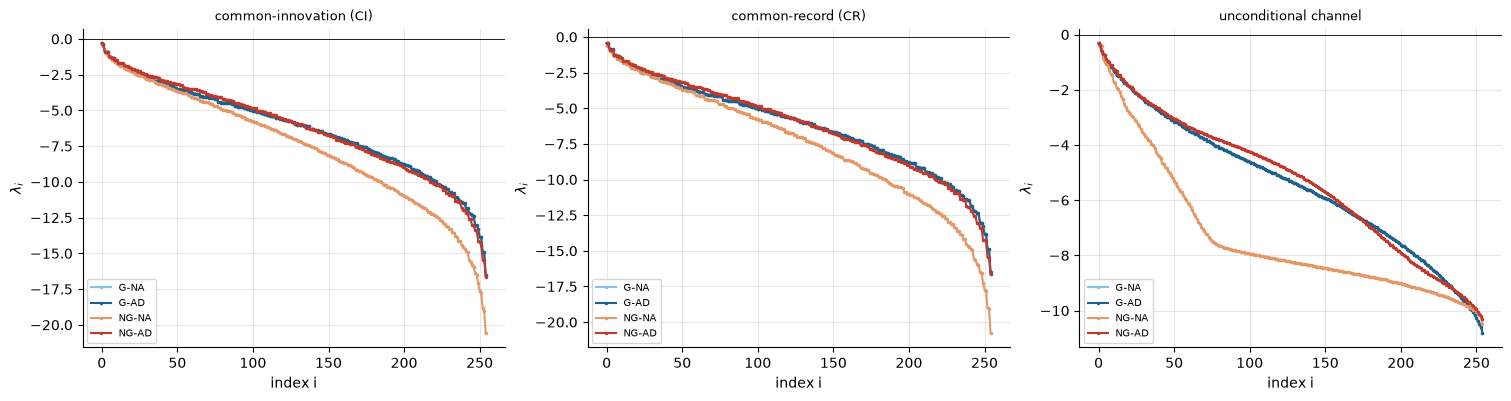

**Fig06_channel_CR_CI_spectra.** Mode preflight; 1 reservoir realizations; 2 trajectories per realization and arm; Fock cutoff D=16; cluster squeezing 12.0 dB; uncertainty: SE over trajectories (table); exploratory. Full density-matrix Lyapunov spectra (d^2-1 = 255 exponents) at the best point gamma=0.2, T=0.5 (Level A (ideal logical cubic gate; screening model), V1, ideal detectors); CI/CR: mean over 2 trajectories of 300 clocks (burn 50, QR every 5); channel: exact Schur-multiplier map.

[14.2 spectra at the best point] 858.3 s | peak RSS 2784 MB


In [27]:
def herm_basis(D):
    F = []
    for j in range(D):
        for k in range(j + 1, D):
            E = np.zeros((D, D), complex); E[j, k] = E[k, j] = 1 / np.sqrt(2); F.append(E)
            E = np.zeros((D, D), complex); E[j, k] = -1j / np.sqrt(2); E[k, j] = 1j / np.sqrt(2); F.append(E)
    for l in range(1, D):
        d = np.zeros(D); d[:l] = 1; d[l] = -l; F.append(np.diag(d / np.sqrt(l * (l + 1))).astype(complex))
    return np.array(F)

def qr_pos(M):
    Q, R = np.linalg.qr(M); s = np.sign(np.diag(R)); s[s == 0] = 1; return Q * s, (R.T * s).T

def ideal_detectors(cond):
    c = dict(cond); c.update(layer_efficiency=1.0, tap_efficiency=1.0, homodyne_resolution=0.0, ff_gain_error=0.0); return c

def _dm_step(res, R, u, xi1, arm, mem, given=None, linear=False):
    """Batch of density matrices R (b, D, D) under common innovations xi1 (one path, tiled); optional common record `given`.
    linear=True applies the unnormalized Kraus product L (requires `given`)."""
    xp = res.xp; b = R.shape[0]; st = DMState(res.ops, R.copy(), linear=linear)
    xi = {k: xp.repeat(v, b, axis=0) for k, v in xi1.items()}
    g_ = None if given is None else {k: xp.repeat(v, b, axis=0) for k, v in given.items()}
    memb = {k: xp.repeat(v, b, axis=0) for k, v in mem.items()}
    out = clock(res, st, xp.full(b, float(u)), xi, arm, memb, given=g_, want_moments=0)
    for k in mem:
        mem[k] = memb[k][:1]
    return st.r, out

def record_of(out):
    rec = dict(m1=out["m1_0"][:1, None], m2=out["m2_0"][:1, None], y=out["y"][:1])
    rec["mc"] = out["byp_0"][:1, None]
    return rec

LAMBDA_FLOOR = -20.0      # CI exponents below this (per clock) are under the finite-difference floor log(eps/h) and are reported as unresolved

def lyap_traj(res, arm, U, inn, *, mode="CI", h=1e-5, q=5, burn=50, p=None, seed=0, Q0=None, return_jac=False):
    """CI or CR Lyapunov spectrum of the normalized conditional map on traceless Hermitian tangents (central differences)."""
    SAMPLER_ITERS["n"] = 40
    xp = res.xp; D = res.D; Fb = xp.asarray(herm_basis(D)); dim = Fb.shape[0]; p = dim if p is None else p
    rho = res.vacuum(1, "dm").r; mem = dict(filt=xp.zeros((1, res.N)), prev_stat=xp.zeros((1, res.N)), prev_corr=xp.zeros((1, res.N)))
    Q = np.linalg.qr(rng_for("lyapQ", seed).normal(size=(dim, p)))[0] if Q0 is None else np.array(Q0, float)
    logs = np.zeros(p); K = len(U); jacs = []
    for k in range(K):
        xi1 = xi_at(inn, k, xp, slice(0, 1))
        if k < burn:
            rho, _ = _dm_step(res, rho, U[k], xi1, arm, mem); continue
        dR = xp.einsum("ja,jkl->akl", xp.asarray(Q), Fb)
        mem0 = {kk: v.copy() for kk, v in mem.items()}
        rho_n, o_ = _dm_step(res, rho, U[k], xi1, arm, mem); rec0 = record_of(o_)
        # exact common-record Jacobian: J_CR d = (L d - tr(L d) rho') / tr(L rho), L = unnormalized Kraus product for the realized record
        Lr, _ = _dm_step(res, rho, U[k], xi1, arm, {kk: v.copy() for kk, v in mem0.items()}, given=rec0, linear=True)
        Ld, _ = _dm_step(res, dR, U[k], xi1, arm, {kk: v.copy() for kk, v in mem0.items()}, given=rec0, linear=True)
        pr = xp.trace(Lr[0]).real; J = (Ld - xp.trace(Ld, axis1=1, axis2=2)[:, None, None] * rho_n) / pr
        if mode == "CI":
            # outcome response: the reference state propagated with the outcomes the perturbed states would draw from the same innovations
            _, op = _dm_step(res, xp.concatenate([rho + h * dR, rho - h * dR], 0), U[k], xi1, arm, {kk: v.copy() for kk, v in mem0.items()})
            recp = dict(m1=op["m1_0"][:, None], m2=op["m2_0"][:, None], y=op["y"], mc=op["byp_0"][:, None])
            st_ = DMState(res.ops, xp.repeat(rho, 2 * p, axis=0).copy()); memb = {kk: xp.repeat(v, 2 * p, axis=0) for kk, v in mem0.items()}
            clock(res, st_, xp.full(2 * p, float(U[k])), {kk: xp.repeat(v, 2 * p, axis=0) for kk, v in xi1.items()}, arm, memb, given=recp, want_moments=0)
            J = J + (st_.r[:p] - st_.r[p:]) / (2 * h)
        JQ = xp.einsum("akl,jlk->ja", J, Fb).real
        Qn = JQ if xp is np else xp.asnumpy(JQ); rho = rho_n
        if return_jac:
            jacs.append(Qn)
        if (k - burn + 1) % q == 0:
            Q, Rm = qr_pos(Qn); logs += np.log(np.abs(np.diag(Rm)))
        else:
            Q = Qn
    lam = logs / max(1, K - burn); SAMPLER_ITERS["n"] = 10
    return (np.sort(lam)[::-1], jacs) if return_jac else np.sort(lam)[::-1]

def schur_multiplier(res, arm, nq=4001):
    """G_ij = sum_q w_q K_i(m_q) K_j(m_q)^* exp(i(e_i - e_j)) for the outcome-dependent x-functions of a clock (ideal detectors).
    Level A: K = M_V(x + m1), e = cubic + residual byproduct + adaptive shear. Level B (V1/V2 at fixed m1 statistics): layer-1 dephasing x injection."""
    xp = np; lam = res.ops.lam_h; ng, ad = ARMS[arm]; gam = res.gamma * ng; V = res.V; D = res.D
    def expo_shear(c2):
        return c2[:, None] * lam[None] ** 2 / 4
    if res.level == "A":
        L = np.abs(lam).max() + 12 * np.sqrt(V); mq = np.linspace(-L, L, nq); wq = np.full(nq, mq[1] - mq[0]); wq[[0, -1]] /= 2
        K = (2 * np.pi * V) ** -0.25 * np.exp(-(lam[None] + mq[:, None]) ** 2 / (4 * V))
        e = gam * lam[None] ** 3 / 6 + (2 * gam * mq)[:, None] * lam[None] ** 2 / 4
        c2 = res.beta2[0] + ad * (res.g * np.tanh(mq / res.sigma["m1"]) - 2 * gam * mq); e = e + expo_shear(c2)
        if res.variant == "V3":
            return None
        Kc = K * np.exp(1j * e); return np.einsum("q,qi,qj->ij", wq, Kc, Kc.conj())
    if res.variant != "V1":
        return None                                                     # Level B with feedback: the multiplier needs a joint (m1, mc) integral; not computed
    Gam1 = np.exp(-(lam[:, None] - lam[None, :]) ** 2 / (8 * V))
    R_ = res.resources[ng]; span = float(R_.z[-1]) + np.abs(lam).max(); mq = np.linspace(-span, span, nq); wq = np.full(nq, mq[1] - mq[0]); wq[[0, -1]] /= 2
    G = np.zeros((D, D), complex)
    for j, (b_, pb) in enumerate(zip(R_.branches, R_.bprob)):
        K = herm_fns(lam[None] + mq[:, None], R_.D_res) @ b_
        e = -(gam * mq ** 2)[:, None] * lam[None] / 2 + expo_shear(res.beta2[0] + ad * (-2 * gam * mq))
        Kc = K * np.exp(1j * e); G += pb * np.einsum("q,qi,qj->ij", wq, Kc, Kc.conj())
    return Gam1 * G

def channel_apply(res, R, u, G, dephase):
    """Unconditional clock channel applied to a batch of Hermitian matrices R (b, D, D)."""
    st = DMState(res.ops, R.copy()); lam = res.ops.lam; xp = res.xp; c1 = res.alpha[0] * u + res.beta1[0]
    st.xmul(xp.exp(1j * c1 * lam ** 2 / 4)); st.phase(res.ops.A)
    rd = res.ops.Wt @ st.r @ res.ops.W; rd = rd * G[None]; st.r = res.ops.W @ rd @ res.ops.Wt
    st.phase(res.ops.A); rd = res.ops.Wt @ st.r @ res.ops.W; rd = rd * dephase[None]; st.r = res.ops.W @ rd @ res.ops.Wt
    st.loss(0, res.T * res.loss) if res.T * res.loss < 1 else None
    return st.r

def channel_spectrum(res, arm, U, *, burn=50, q=5, p=None, seed=0, nq=4001):
    G = schur_multiplier(res, arm, nq)
    if G is None:
        return None
    xp = res.xp; G = xp.asarray(G); lam = res.ops.lam; deph = xp.exp(-(lam[:, None] - lam[None, :]) ** 2 / (8 * res.V))
    Fb = xp.asarray(herm_basis(res.D)); dim = Fb.shape[0]; p = dim if p is None else p
    Q = np.linalg.qr(rng_for("chanQ", seed).normal(size=(dim, p)))[0]; logs = np.zeros(p)
    for k in range(len(U)):
        dR = xp.einsum("ja,jkl->akl", xp.asarray(Q), Fb); JQ = xp.einsum("akl,jlk->ja", channel_apply(res, dR, U[k], G, deph), Fb).real
        Qn = JQ if xp is np else xp.asnumpy(JQ)
        if k < burn:
            Q = qr_pos(Qn)[0]; continue
        if (k - burn + 1) % q == 0:
            Q, Rm = qr_pos(Qn); logs += np.log(np.abs(np.diag(Rm)))
        else:
            Q = Qn
    return np.sort(logs / max(1, len(U) - burn))[::-1]

def trace_distance_exponent(res, arm, U, inn, seed=0):
    xp = res.xp; D = res.D; rng_ = rng_for("tdx", seed)
    vs = rng_.normal(size=(2, D)) + 1j * rng_.normal(size=(2, D)); vs *= np.exp(-0.5 * np.arange(D))[None]; vs /= np.linalg.norm(vs, axis=1, keepdims=True)
    R = xp.asarray(np.einsum("bi,bj->bij", vs, vs.conj())); mem = dict(filt=xp.zeros((1, 1)), prev_stat=xp.zeros((1, 1)), prev_corr=xp.zeros((1, 1))); d = []
    for k in range(len(U)):
        R, _ = _dm_step(res, R, U[k], xi_at(inn, k, xp, slice(0, 1)), arm, mem)
        Dm = R[0] - R[1]; ev = xp.linalg.eigvalsh(0.5 * (Dm + Dm.conj().T)); d.append(float(0.5 * xp.abs(ev).sum()))
    d = np.array(d); ok = d > 1e-11; kk = np.arange(len(d))[ok]
    return (float(np.polyfit(kk, np.log(d[ok]), 1)[0]) if ok.sum() > 5 else np.nan), d

with section("14.1 Lyapunov validation (toy cutoff)"):
    Dt_ = 5; rt = Reservoir(EXPLORATION_SEEDS[5], 1, Dt_, 0.5, 0.2, level="A", variant="V2", cond=ideal_detectors(BASE), sigma=None, xp=np)
    Ut = input_sequence(EXPLORATION_SEEDS[5], 3, 400); innt = draw_innovations(rng_for("lyap-toy"), 1, 1, 400)
    lam_cr, jacs = lyap_traj(rt, "NG-AD", Ut[:8], innt, mode="CR", burn=0, q=1, return_jac=True, Q0=np.eye(24))
    P8 = np.eye(24)
    for J_ in jacs:
        P8 = J_ @ P8
    sv = np.linalg.svd(P8, compute_uv=False); e1 = abs(lam_cr.sum() - np.log(abs(np.linalg.det(P8))) / 8); e2 = abs(lam_cr[0] - np.log(sv[0]) / 8)
    record_test("L1", "spectrum", "8-clock QR spectrum vs direct product of Jacobians: sum = log|det|/K exactly; leading exponent within O(1/K) of log(sigma_1)/K",
                f"sum {e1:.1e}, top {e2:.3f}", "sum < 1e-8, top < 0.3", e1 < 1e-8 and e2 < 0.3)
    la = lyap_traj(rt, "NG-AD", Ut, innt, mode="CI", burn=50, q=5, seed=1); lb = lyap_traj(rt, "NG-AD", Ut, innt, mode="CI", burn=50, q=5, seed=2)
    record_test("L2", "spectrum", "basis invariance: two random orthogonal initial tangent bases give the same CI spectrum (max |difference|)", float(np.abs(la - lb).max()), "< 0.02",
                np.abs(la - lb).max() < 0.02)
    def _res_diff(a, b):
        ok = (a > LAMBDA_FLOOR) & (b > LAMBDA_FLOOR); return float(np.abs(a[ok] - b[ok]).max()) if ok.any() else np.nan, int(ok.sum())
    c1 = lyap_traj(rt, "NG-AD", Ut[:60], innt, mode="CR", burn=20, q=1, seed=1); c2 = lyap_traj(rt, "NG-AD", Ut[:60], innt, mode="CR", burn=20, q=2, seed=1)
    l1 = lyap_traj(rt, "NG-AD", Ut[:60], innt, mode="CI", burn=20, q=1, seed=1); l2 = lyap_traj(rt, "NG-AD", Ut[:60], innt, mode="CI", burn=20, q=2, seed=1)
    e3c = float(np.abs(c1 - c2).max()); e3i, n3 = _res_diff(l1, l2)
    record_test("L3", "spectrum", f"QR-interval invariance (q = 1 vs 2): exact CR spectrum (all {len(c1)} exponents) and CI spectrum ({n3} exponents above the floor {LAMBDA_FLOOR})",
                f"CR {e3c:.1e}, CI {e3i:.1e}", "< 1e-8, < 1e-4", e3c < 1e-8 and e3i < 1e-4)
    lh = [lyap_traj(rt, "NG-AD", Ut[:60], innt, mode="CI", burn=20, q=1, seed=1, h=h_) for h_ in (1e-4, 1e-5, 1e-6)]
    (d1, n1), (d2, n2) = _res_diff(lh[0], lh[1]), _res_diff(lh[1], lh[2])
    record_test("L4", "spectrum", f"perturbation-size convergence of the CI spectrum (outcome-response step h = 1e-4, 1e-5, 1e-6; {min(n1, n2)} resolved exponents; "
                f"the CR part is an exact linearization)", max(d1, d2), "< 1e-3", max(d1, d2) < 1e-3)
    Gq = schur_multiplier(rt, "G-NA"); lamt = rt.ops.lam_h
    Gc = np.exp(-(lamt[:, None] - lamt[None, :]) ** 2 / (8 * rt.V)) * np.exp(1j * rt.beta2[0] * (lamt[:, None] ** 2 - lamt[None, :] ** 2) / 4)
    record_test("L5", "spectrum", "channel Schur multiplier by quadrature = closed form for G-NA (dephasing x fixed shear)", float(np.abs(Gq - Gc).max()), "< 1e-10", np.abs(Gq - Gc).max() < 1e-10)
    Fb5 = herm_basis(Dt_); G5 = schur_multiplier(rt, "NG-AD"); d5 = np.exp(-(lamt[:, None] - lamt[None, :]) ** 2 / (8 * rt.V))
    rho5 = np.eye(Dt_)[None] / Dt_ + 0.1 * Fb5[:1]; out5 = channel_apply(rt, rho5.astype(complex), 0.3, G5, d5)
    ev5 = np.linalg.eigvalsh(0.5 * (out5[0] + out5[0].conj().T))
    record_test("L6", "spectrum", "unconditional channel is trace preserving and positive (NG-AD)", f"|tr-1|={abs(np.trace(out5[0]) - 1):.1e}, min eig {ev5.min():.1e}",
                "< 1e-10, > -1e-10", abs(np.trace(out5[0]) - 1) < 1e-10 and ev5.min() > -1e-10)
    LYAP_VALID = all(t["passed"] for t in TESTS if t["id"] in ("L1", "L2", "L3", "L4", "L5", "L6"))

SPECTRA, LYAP_LEN_OK = {}, None
if BEST is not None:
    with section("14.2 spectra at the best point"):
        g_b, T_b = float(BEST["gamma"]), float(BEST["T"]); condL = ideal_detectors(PRIMARY["cond"]); Kl = CFG["lyap_len"] + CFG["lyap_burn"]
        for arm in ARMS:
            xpL = np if LYAP_D <= 16 else XP          # measured: small batched density-matrix steps are faster on the CPU up to D = 16
            resL = Reservoir(EXPLORATION_SEEDS[0], 1, LYAP_D, T_b, g_b, level=PRIMARY["level"], variant=VARIANT, cond=condL, sigma=PRIMARY["sigma"], xp=xpL)
            def unit_spec(arm=arm, resL=resL):
                ci, cr, td = [], [], []
                for j in range(CFG["lyap_traj"]):
                    U_ = input_sequence(EXPLORATION_SEEDS[0], 50 + j, Kl); inn_ = draw_innovations(rng_for("lyap", arm, j), 1, 1, Kl)
                    ci.append(lyap_traj(resL, arm, U_, inn_, mode="CI", burn=CFG["lyap_burn"], q=1, seed=j))
                    cr.append(lyap_traj(resL, arm, U_, inn_, mode="CR", burn=CFG["lyap_burn"], q=1, seed=j))
                    td.append(trace_distance_exponent(resL, arm, U_[:CFG["td_len"]], inn_, seed=j)[0])
                ch = channel_spectrum(resL, arm, input_sequence(EXPLORATION_SEEDS[0], 50, Kl), burn=CFG["lyap_burn"], q=CFG["lyap_qr"])
                return dict(CI1_spread=float(np.ptp([c[0] for c in ci])), CI=np.mean(ci, 0), CI_se=np.std(ci, 0, ddof=1) / np.sqrt(len(ci)) if len(ci) > 1 else np.zeros_like(ci[0]), CR=np.mean(cr, 0),
                            CH=ch, TD=float(np.nanmean(td)))
            SPECTRA[arm] = STORE.cached("spectra", dict(arm=arm, D=LYAP_D, T=T_b, g=g_b, level=PRIMARY["level"], variant=VARIANT, cond=condL, sigma=PRIMARY["sigma"],
                                                        K=Kl, burn=CFG["lyap_burn"], q=CFG["lyap_qr"], n=CFG["lyap_traj"]), unit_spec)
        SPEC_DF = pd.DataFrame({a: dict(lambda1_CI=s["CI"][0], lambda1_CI_se=s["CI_se"][0], lambda1_CR=s["CR"][0], Lambda1_ch=(s["CH"][0] if s["CH"] is not None else np.nan),
                                        CI1_spread=s.get("CI1_spread", np.nan), gap_CI=s["CI"][0] - s["CI"][1], N0_CI=int((s["CI"] > -0.05).sum()), CI_resolved=int((s["CI"] > LAMBDA_FLOOR).sum()), lambda_TD=s["TD"],
                                        Delta_lambda=s["CI"][0] - (s["CH"][0] if s["CH"] is not None else np.nan)) for a, s in SPECTRA.items() if not s.get("failed")}).T
        display(SPEC_DF.map(lambda x: f"{x:.4g}"))
        LYAP_LEN_OK = bool((SPEC_DF.CI1_spread.astype(float) < 0.05).all()) if CFG["lyap_traj"] > 1 else None
        print(f"Lyapunov-length convergence (leading CI exponent from {CFG['lyap_traj']} independent trajectories of {CFG['lyap_len']} clocks agree within 0.05): {LYAP_LEN_OK}")
        fig, axs = plt.subplots(1, 3, figsize=(15, 3.9))
        for a, s in SPECTRA.items():
            if s.get("failed"):
                continue
            axs[0].plot(s["CI"], ".-", color=COL[a], label=a, ms=3); axs[1].plot(s["CR"], ".-", color=COL[a], label=a, ms=3)
            if s["CH"] is not None:
                axs[2].plot(s["CH"], ".-", color=COL[a], label=a, ms=3)
        for ax, t_ in zip(axs, ("common-innovation (CI)", "common-record (CR)", "unconditional channel")):
            ax.set_title(t_, fontsize=9); ax.set_xlabel("index i"); ax.set_ylabel(r"$\lambda_i$"); ax.axhline(0, color="k", lw=0.6); ax.legend(fontsize=7)
        show_fig(fig, "Fig06_channel_CR_CI_spectra", caption(f"Full density-matrix Lyapunov spectra (d^2-1 = {LYAP_D ** 2 - 1} exponents) at the best point gamma={g_b}, T={T_b} "
                 f"({PRIMARY['label']}, {VARIANT}, ideal detectors); CI/CR: mean over {CFG['lyap_traj']} trajectories of {CFG['lyap_len']} clocks (burn {CFG['lyap_burn']}, QR every "
                 f"{CFG['lyap_qr']}); channel: exact Schur-multiplier map{' (not computable for this variant/level)' if any(s.get('CH') is None for s in SPECTRA.values() if not s.get('failed')) else ''}.",
                 n_real=1, n_traj=CFG["lyap_traj"], D=LYAP_D, unc="SE over trajectories (table)"))

## 15. Adaptive–non-Gaussian kernels and susceptibilities

Definitions are in §9.8. This section validates the estimator and runs the Gaussian adaptive-suppression test of §7.

**Exact selection-rule search.** We look for a component with $K^{\rm G,NA}_\alpha=K^{\rm G,AD}_\alpha=K^{\rm NG,NA}_\alpha=0$ but $K^{\rm NG,AD}_\alpha\neq0$.
* **G–NA.** Every operation is Gaussian, and the input enters only through the shear $\cot\theta_1=\alpha u+\beta$. The outcome-averaged state is a Gaussian channel output with zero mean. Its covariance is a polynomial of degree ≤ 2 in each shear, hence in each input, and every odd moment vanishes, so $E[y]=E[y^3]=0$ exactly. Components with any $\alpha_j\ge3$ therefore vanish for G–NA.
* **G–AD and NG–NA.** Neither obeys a degree bound: the bounded controller is non-polynomial, and the uncorrected shear $P(2\gamma m)$ averages to Gaussian-weighted phases.

**No exact zero rule separates NG–AD from all three controls.** The evidence is therefore the **factorial interaction** $K^\times$, *not* a strict selection theorem.

**Validation.**
* **K1, derivative order.** The Gauss–Legendre projection recovers known synthetic polynomial kernels exactly.
* **K2, stencil convergence.** 4 versus 5 nodes give the same low-order components.
* **K3, null calibration.** $\gamma=0$ gives $K^\times\equiv0$ exactly; two independent common-random-number copies of the same arm give a whitened U-statistic consistent with zero.
* **K4.** The exact G–NA zeros predicted above.

In [28]:
with section("15.1 kernel-estimator validation"):
    z4, pts4, comps4, Wc4 = legendre_stencil(4)
    f_syn = lambda u0, u1, u2: 0.3 * u0 + 0.2 * leg(2, u1) * leg(1, u2) + 0.1 * leg(3, u0) * leg(1, u1) + 0.05 * leg(2, u0) * leg(2, u1) * leg(2, u2)
    vals = np.array([f_syn(z4[s[0]], z4[s[1]], z4[s[2]]) for s in pts4]); cf = Wc4 @ vals
    truth = np.zeros(len(comps4)); truth[comps4.index((1, 0, 0))] = 0.3 / np.sqrt(3); truth[comps4.index((0, 2, 1))] = 0.2
    truth[comps4.index((3, 1, 0))] = 0.1; truth[comps4.index((2, 2, 2))] = 0.05
    k1 = float(np.abs(cf - truth).max())
    record_test("K1", "numerical", "Gauss-Legendre projection recovers a synthetic polynomial kernel (degrees <= 3 per input) exactly", k1, "< 1e-12", k1 < 1e-12)
    if RUN_MODE != "unit" and not RESEARCH_BLOCKED:
        Dk, Tk, rk = CFG["cutoffs"][0], CFG["level_a_T"], EXPLORATION_SEEDS[6]
        kk4 = kernel_unit(1, Dk, Tk, 0.2, rk, level="A", variant=VARIANT, sigma=SIGMA_A, n_nodes=4, M=256, arms=("NG-AD",))
        kk5 = kernel_unit(1, Dk, Tk, 0.2, rk, level="A", variant=VARIANT, sigma=SIGMA_A, n_nodes=5, M=256, arms=("NG-AD",))
        V4 = kernel_coeffs(kk4["arms"][("NG-AD", "true")], kk4["Wc"])[1]; V5 = kernel_coeffs(kk5["arms"][("NG-AD", "true")], kk5["Wc"])[1]
        low = [a for a in kk4["comps"] if sum(a) <= 2]; zz = []
        for a in low:
            A4, A5 = V4[kk4["comps"].index(a)], V5[kk5["comps"].index(a)]
            zz.append(np.abs(A4.mean(0) - A5.mean(0)) / np.sqrt(A4.var(0, ddof=1) / len(A4) + A5.var(0, ddof=1) / len(A5) + 1e-300))
        k2 = float(np.max(zz))
        record_test("K2", "numerical", f"stencil convergence: total-degree <= 2 components with 4 vs 5 Gauss-Legendre nodes agree (max |z| over {len(low)} components x features)",
                    k2, "< 4.5", k2 < 4.5)
        ka = kernel_unit(1, Dk, Tk, 0.0, rk, level="A", variant=VARIANT, sigma=SIGMA_A, M=256)
        c0 = chi_combo(ka, FACTORIAL)
        record_test("K3a", "numerical", "null calibration (exact): gamma = 0 gives K^x identically zero (chi_int^x, chi_vis^x)", f"{c0['chi_int'][0]:.1e}, {c0['chi_vis'][0]:.1e}",
                    "== 0", c0["chi_int"][0] == 0 and c0["chi_vis"][0] == 0)
        kb = kernel_unit(1, Dk, Tk, 0.2, rk, level="A", variant=VARIANT, sigma=SIGMA_A, M=256, arms=("NG-AD",))
        kb2 = kernel_unit(1, Dk, Tk, 0.2, rk, level="A", variant=VARIANT, sigma=SIGMA_A, M=256, arms=("NG-AD",), inn_tag=1)
        Va = kernel_coeffs(kb["arms"][("NG-AD", "true")], kb["Wc"])[1]; Vb = kernel_coeffs(kb2["arms"][("NG-AD", "true")], kb2["Wc"])[1]
        Wn, _ = whitening(kb, CFG["shots"], arms=("NG-AD",)); est, se = ustat(Va - Vb, Wn)
        record_test("K3b", "numerical", "null calibration (Monte Carlo): the same arm with independent innovation streams -> whitened U-statistic of the kernel difference "
                    "consistent with zero (|z|)", abs(est / se) if se > 0 else np.inf, "< 3", se > 0 and abs(est / se) < 3)
        Vg = kernel_coeffs(ka["arms"][("G-NA", "true")], ka["Wc"])[1][:, :, [0, 2]]
        k4 = float(np.max(np.abs(Vg.mean(1)) / (Vg.std(1, ddof=1) / np.sqrt(Vg.shape[1]) + 1e-300)))
        record_test("K4", "physics", "G-NA zero-mean Gaussian channel: odd visible features (E[y], E[y^3]) have zero kernels for every component (max |z|)", k4, "< 4.5", k4 < 4.5)
    else:
        print("K2-K4 need reservoir runs: executed outside unit mode")

PASS [K1] (critical) Gauss-Legendre projection recovers a synthetic polynomial kernel (degrees <= 3 per input) exactly: 1.39e-16 (criterion < 1e-12)


PASS [K2] (critical) stencil convergence: total-degree <= 2 components with 4 vs 5 Gauss-Legendre nodes agree (max |z| over 9 components x features): 0.542 (criterion < 4.5)


PASS [K3a] (critical) null calibration (exact): gamma = 0 gives K^x identically zero (chi_int^x, chi_vis^x): 0.0e+00, 0.0e+00 (criterion == 0)


PASS [K3b] (critical) null calibration (Monte Carlo): the same arm with independent innovation streams -> whitened U-statistic of the kernel difference consistent with zero (|z|): 0.521 (criterion < 3)
PASS [K4] (critical) G-NA zero-mean Gaussian channel: odd visible features (E[y], E[y^3]) have zero kernels for every component (max |z|): 2.24 (criterion < 4.5)
[15.1 kernel-estimator validation] 8.1 s | peak RSS 2784 MB


### 15.2 Gaussian adaptive-response scaling with squeezing (test of §7)

At each squeezing level (3, 6, 9, 12 dB) the controller scale is re-calibrated, and the G arms are run with the bounded controller (V2 gain).
* **Angle sensitivity.** For every path we compute $|\partial_uI|$ from the exact layer-1 outcome law, together with the bound $(L_f/\sigma_r)C_1$, where $C_1=\int|x||\partial_u\rho_u|dx$ uses DVR quadrature and central differences in $u$.
* **Visible adaptive kernel.** We report $\chi^{\rm G,AD}_{\rm vis}=\sum_\alpha\|B(K^{\rm G,AD}-K^{\rm G,NA})\|^2$ and the i.i.d.-angle-subtracted version $\chi^{\rm G,AD-iid}_{\rm vis}$, and fit $\log\chi$ against $r$.

,db,r,sigma_r,chi_vis_GAD,chi_vis_GAD_se,chi_wh_GAD,chi_wh_GAD_se,chi_vis_GAD_minus_iid,chi_vis_GAD_minus_iid_se,max_sens_over_bound,mean_sens,mean_bound,C1_mean
0,3,0.3454,2.012,0.06814,0.05146,0.1583,0.06792,0.07044,0.05455,0.6602,0.1128,0.1855,0.3731
1,6,0.6908,2.385,0.03715,0.02984,0.1254,0.06406,0.03901,0.03213,0.6319,0.06599,0.1101,0.2626
2,9,1.036,3.078,0.01776,0.01442,0.07518,0.03895,0.01935,0.01637,0.6182,0.03837,0.06396,0.1969
3,12,1.382,4.158,0.008663,0.00707,0.04248,0.02218,0.009287,0.007991,0.6114,0.02194,0.03652,0.1519


angle-sensitivity bound |d_u I| <= (L_f/sigma_r) C_1 holds at every squeezing level: True; (A2) C_1 bounded across r (max/min < 3): True
fitted decay of chi_vis^(G,AD): exp(-a r) with a = 2.01 +- 0.06 (first-order prediction a = 2)
BOUND ESTABLISHED UNDER EXPLICIT RESTRICTED ASSUMPTIONS
chi_vis scaling statement: NUMERICAL SCALING ONLY


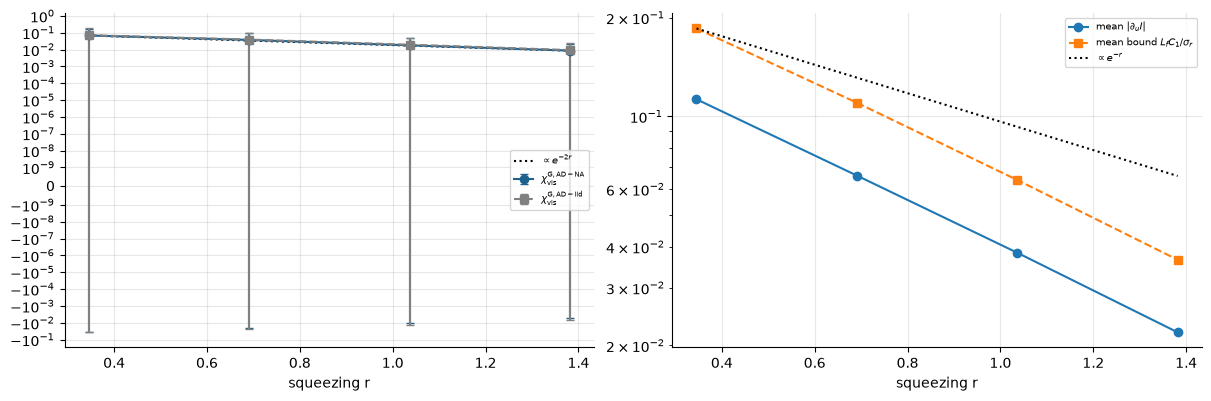

**Fig03_gaussian_adaptive_scaling.** Mode preflight; 4 reservoir realizations; 1024 (kernels), 256 (angle sensitivity) trajectories per realization and arm; Fock cutoff D=20; cluster squeezing 3-12 dB; uncertainty: 1.96 x SE (jackknife over path blocks, combined with between-realization SD); exploratory. Gaussian adaptive response vs squeezing (3, 6, 9, 12 dB): visible adaptive kernel of G-AD (V2 gain 0.2) and the angle-sensitivity proposition. Status: BOUND ESTABLISHED UNDER EXPLICIT RESTRICTED ASSUMPTIONS; chi scaling: NUMERICAL SCALING ONLY.

[15.2 Gaussian suppression scaling] 297.2 s | peak RSS 2784 MB


In [29]:
SUPP = pd.DataFrame(); SUPP_STATUS = "not evaluated (unit mode)"
if RUN_MODE != "unit" and not RESEARCH_BLOCKED:
    with section("15.2 Gaussian suppression scaling"):
        supp_rows = []; Ds = CFG["cutoffs"][len(CFG["cutoffs"]) // 2]; Ts = CFG["level_a_T"]
        for db in CFG["suppression_db"]:
            cond_s = dict(BASE, squeezing_db=db)
            sig_s = STORE.cached("calib", dict(level="A", N=1, D=Ds, T=Ts, cond=cond_s, n=CFG["n_calib"], cp=CFG["calib_paths"], ck=CFG["calib_clocks"]), lambda: calibrate_sigma(1, Ds, Ts, "A", cond=cond_s))
            def unit_s(db=db, cond_s=cond_s, sig_s=sig_s):
                rows = []
                for rid in EXPLORATION_SEEDS[:CFG["n_screen"]]:
                    ku = kernel_unit(1, Ds, Ts, 0.0, rid, level="A", variant="V2", cond=cond_s, sigma=sig_s, arms=("G-NA", "G-AD"), ctrls=("iid",))
                    W, _ = whitening(ku, CFG["shots"], arms=("G-NA", "G-AD"))
                    c = chi_combo(ku, {"G-AD": 1, "G-NA": -1}, W_wh=W)
                    I_ad, V_ad = kernel_coeffs(ku["arms"][("G-AD", "true")], ku["Wc"]); I_iid, V_iid = kernel_coeffs(ku["arms"][("G-AD", "iid")], ku["Wc"])
                    rows.append(dict(rid=rid, chi_vis=c["chi_vis"][0], chi_vis_se=c["chi_vis"][1], chi_wh=c["chi_wh"][0], chi_wh_se=c["chi_wh"][1],
                                     chi_vis_iid=ustat(V_ad - V_iid)[0], chi_vis_iid_se=ustat(V_ad - V_iid)[1]))
                # angle sensitivity vs the proposition's bound, on 256 states drawn from the G-NA ensemble
                res_ = Reservoir(EXPLORATION_SEEDS[0], 1, Ds, Ts, 0.0, variant="V2", cond=cond_s, sigma=sig_s, xp=np)
                o_ = run_paths(res_, "G-NA", np.tile(input_sequence(EXPLORATION_SEEDS[0], 9, 40)[:, None], (1, 256)), draw_innovations(rng_for("supp", db), 256, 1, 40),
                               collect=(), keep_state=True)
                psi0 = o_["psi"]; lam = res_.ops.lam_h; W_ = res_.ops.W_h; du = 1e-4
                mg = np.linspace(-(np.abs(lam).max() + 12 * np.sqrt(res_.V)), np.abs(lam).max() + 12 * np.sqrt(res_.V), 6001); dm_ = mg[1] - mg[0]
                Fv = lambda x: (np.tanh(mg[None] / sig_s["m1"]) * np.exp(-(mg[None] + x[:, None]) ** 2 / (2 * res_.V))).sum(1) * dm_ / np.sqrt(2 * np.pi * res_.V)
                Flam = Fv(lam)
                def rho_u(u):
                    c1 = res_.alpha[0] * u + res_.beta1[0]; v = (psi0 @ W_) * np.exp(1j * c1 * lam ** 2 / 4)[None]; v = (v @ W_.T) * np.exp(1j * np.pi / 2 * np.arange(Ds))[None]
                    return np.abs(v @ W_) ** 2
                u0 = 0.3; rp, rm = rho_u(u0 + du), rho_u(u0 - du); drho = (rp - rm) / (2 * du)
                sens = np.abs(drho @ Flam); C1 = (np.abs(drho) * np.abs(lam)[None]).sum(1); bnd = C1 / sig_s["m1"]
                return dict(rows=rows, sens=sens, bound=bnd, C1=C1, sigma=sig_s["m1"], r=db_to_r(db))
            u_ = STORE.cached("suppression", dict(db=db, D=Ds, T=Ts, cfg=kcfg(), n=CFG["n_screen"]), unit_s)
            if isinstance(u_, dict) and u_.get("failed"):
                FAILED_UNITS.append(dict(stage="suppression", db=db, reason=u_["reason"])); continue
            cvis = combine_realizations(u_["rows"], "chi_vis"); cwh = combine_realizations(u_["rows"], "chi_wh"); ciid = combine_realizations(u_["rows"], "chi_vis_iid")
            supp_rows.append(dict(db=db, r=u_["r"], sigma_r=u_["sigma"], chi_vis_GAD=cvis["est"], chi_vis_GAD_se=cvis["se"], chi_wh_GAD=cwh["est"], chi_wh_GAD_se=cwh["se"],
                                  chi_vis_GAD_minus_iid=ciid["est"], chi_vis_GAD_minus_iid_se=ciid["se"], max_sens_over_bound=float(np.max(u_["sens"] / np.maximum(u_["bound"], 1e-300))),
                                  mean_sens=float(np.mean(u_["sens"])), mean_bound=float(np.mean(u_["bound"])), C1_mean=float(np.mean(u_["C1"]))))
        SUPP = pd.DataFrame(supp_rows); display(SUPP.map(lambda x: f"{x:.4g}"))
        bound_ok = bool(len(SUPP)) and bool((SUPP.max_sens_over_bound <= 1 + 1e-9).all())
        a2_ok = bool(len(SUPP)) and SUPP.C1_mean.max() / max(SUPP.C1_mean.min(), 1e-300) < 3.0
        fitv = SUPP[SUPP.chi_vis_GAD > 0]; slope, slope_se = (np.polyfit(fitv.r, np.log(fitv.chi_vis_GAD), 1, cov=True) if len(fitv) >= 3 else (np.array([np.nan, np.nan]), np.full((2, 2), np.nan)))
        a_hat = -float(slope[0]) if len(fitv) >= 3 else np.nan; a_se = float(np.sqrt(slope_se[0, 0])) if len(fitv) >= 3 else np.nan
        if not bound_ok:
            SUPP_STATUS = "CLAIM REJECTED"
        elif bound_ok and a2_ok:
            SUPP_STATUS = "BOUND ESTABLISHED UNDER EXPLICIT RESTRICTED ASSUMPTIONS"
        else:
            SUPP_STATUS = "NUMERICAL SCALING ONLY"
        chi_status = ("NUMERICAL SCALING ONLY" if a_hat + 2 * a_se >= 2 else "CLAIM REJECTED") if np.isfinite(a_hat) else "NUMERICAL SCALING ONLY (fit not possible)"
        print(f"angle-sensitivity bound |d_u I| <= (L_f/sigma_r) C_1 holds at every squeezing level: {bound_ok}; (A2) C_1 bounded across r (max/min < 3): {a2_ok}")
        print(f"fitted decay of chi_vis^(G,AD): exp(-a r) with a = {a_hat:.2f} +- {a_se:.2f} (first-order prediction a = 2)")
        print(SUPP_STATUS)
        print(f"chi_vis scaling statement: {chi_status}")
        fig, axs = plt.subplots(1, 2, figsize=(12, 3.9))
        axs[0].errorbar(SUPP.r, SUPP.chi_vis_GAD, 1.96 * SUPP.chi_vis_GAD_se, fmt="o-", color=COL["G-AD"], capsize=3, label=r"$\chi_{\rm vis}^{\rm G,AD-NA}$")
        axs[0].errorbar(SUPP.r, SUPP.chi_vis_GAD_minus_iid, 1.96 * SUPP.chi_vis_GAD_minus_iid_se, fmt="s--", color="gray", capsize=3, label=r"$\chi_{\rm vis}^{\rm G,AD-iid}$")
        if len(SUPP) and SUPP.chi_vis_GAD.iloc[0] > 0:
            rr_ = np.linspace(SUPP.r.min(), SUPP.r.max(), 50); axs[0].plot(rr_, SUPP.chi_vis_GAD.iloc[0] * np.exp(-2 * (rr_ - SUPP.r.iloc[0])), "k:", label=r"$\propto e^{-2r}$")
        axs[0].set_yscale("symlog", linthresh=1e-9); axs[0].set_xlabel("squeezing r"); axs[0].legend(fontsize=7)
        axs[1].plot(SUPP.r, SUPP.mean_sens, "o-", label=r"mean $|\partial_u I|$"); axs[1].plot(SUPP.r, SUPP.mean_bound, "s--", label=r"mean bound $L_fC_1/\sigma_r$")
        axs[1].plot(SUPP.r, SUPP.mean_bound.iloc[0] * np.exp(-(SUPP.r - SUPP.r.iloc[0])), "k:", label=r"$\propto e^{-r}$"); axs[1].set_yscale("log"); axs[1].set_xlabel("squeezing r"); axs[1].legend(fontsize=7)
        show_fig(fig, "Fig03_gaussian_adaptive_scaling", caption(f"Gaussian adaptive response vs squeezing ({', '.join(f'{d:g}' for d in CFG['suppression_db'])} dB): visible adaptive kernel of G-AD "
                 f"(V2 gain {PREREGISTERED['g_feedback']}) and the angle-sensitivity proposition. Status: {SUPP_STATUS}; chi scaling: {chi_status}.", n_real=CFG["n_screen"],
                 n_traj=f"{CFG['kernel_paths']} (kernels), 256 (angle sensitivity)", D=Ds, sq_db="3-12"))

## 16. Task-free structural phase / crossover map

The scan covers two physical parameters only: the cubic strength $\gamma$ and the monitoring transmissivity $T_m$. It uses the primary model and the selected variant, at the middle cutoff, with `n_explore` exploration realizations. Controller scales are re-frozen per $T_m$ on the calibration bank.

**Quantities at every grid point:**
* hierarchical instability (per arm);
* Fock-boundary population;
* conditional/unconditional purity;
* non-Gaussianity of the NG–AD conditional states (Gaussian-reference entropy, cumulants);
* record information (whitened linear visibility of $u_k$ in the NG–AD record);
* $\chi^\times_{\rm int},\chi^\times_{\rm vis},\chi^\times_{\rm wh},\chi^\times_{\rm res}$;
* success probability (1: no postselection anywhere);
* accepted-shot cost;
* wall time and memory.

Entanglement needs two modes and is reported at the second size (§17). Spectra are computed at the best and the locked point (§14) rather than at all $|\gamma|\times|T|$ points.

**No task score is computed here.**

**Boundaries.** We never interpolate through escaped, invalid or non-converged points. A stability boundary between a finite, physical point $\gamma_i$ and an inadmissible point $\gamma_{i+1}$ is reported only as
$$\gamma_c\in(\gamma_i,\gamma_{i+1}),\qquad\text{unresolved before instability,}$$
and grid-interpolation uncertainty is the whole interval.

[16.1 calibration per T] 99.6 s | peak RSS 2784 MB


  T=0.3: 24 rows


  T=0.5: 48 rows


  T=0.7: 72 rows


  T=0.85: 96 rows


,gamma,T,admissible,esc_upper_G-NA,esc_upper_G-AD,esc_upper_NG-NA,esc_upper_NG-AD,chi_int_x,chi_int_x_snr,chi_wh_x,chi_wh_x_snr,chi_res_x,ng_rel_entropy_NG-AD,purity_uncond_NG-AD,boundary_final_NG-AD,rec_info_NG-AD,shots_needed,seconds
0,0,0.3,True,0.00244,0.00244,0.00244,0.00244,0,NaN,0,NaN,0,3.05e-08,0.934,6.97e-17,NaN,inf,84.1
1,0.05,0.3,True,0.00244,0.00244,0.00244,0.00244,0.000159,3.11,0.456,1.72,0.056,0.000214,0.933,4.65e-16,1.73,1.4e+04,84.1
2,0.1,0.3,True,0.00244,0.00244,0.00244,0.00244,0.000602,3.2,0.954,3.38,0.155,0.000788,0.93,3.4e-15,1.2,6.71e+03,84.1
3,0.2,0.3,True,0.00244,0.00244,0.00244,0.00244,0.00162,3.32,1.88,3.4,0.296,0.0036,0.922,4.12e-14,0.467,3.4e+03,84.1
4,0.3,0.3,True,0.00244,0.00244,0.00244,0.00244,0.00221,3.76,1.93,3.87,0.525,0.0102,0.912,1.89e-13,0.328,3.32e+03,84.1
5,0.45,0.3,True,0.00244,0.00244,0.00244,0.00244,0.00269,4.31,1.45,2.93,0.926,0.0278,0.891,9.14e-13,0.334,4.43e+03,84.1
6,0,0.5,False,0.0225,0.0234,0.0225,0.0234,0,NaN,0,NaN,0,9.76e-07,0.873,6.41e-12,NaN,inf,83.8
7,0.05,0.5,False,0.0225,0.0234,0.0312,0.0181,0.000599,3.05,0.399,2.34,0.0768,0.000772,0.871,2.22e-11,1.15,1.61e+04,83.8
8,0.1,0.5,False,0.0225,0.0234,0.0815,0.0171,0.00239,3,1.2,4.93,0.224,0.00277,0.868,1.1e-10,0.881,5.33e+03,83.8
9,0.2,0.5,False,0.0225,0.0234,0.281,0.00537,0.00584,2.98,1.9,4.11,0.547,0.0114,0.858,8.36e-10,0.448,3.37e+03,83.8


,T,interval,status
0,0.30,None,no stability boundary inside the scanned gamma...
1,0.50,None,no admissible point at this T
2,0.70,None,no admissible point at this T
3,0.85,None,no admissible point at this T


[16.2 structural scan] 2006.5 s | peak RSS 4448 MB


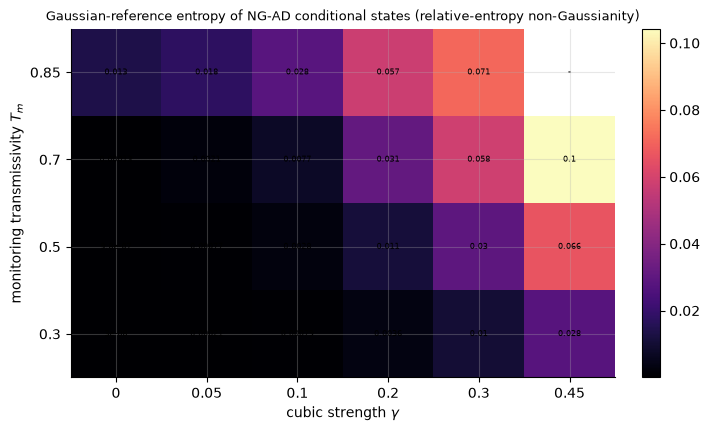

**Fig05_nongaussianity_map.** Mode preflight; 4 reservoir realizations; 1024 (kernels), 512 (stability) trajectories per realization and arm; Fock cutoff D=20; cluster squeezing 12.0 dB; uncertainty: 1.96 x SE (jackknife over path blocks, combined with between-realization SD); exploratory. Non-Gaussianity of the NG-AD conditional logical states (mean over realizations of 16 final states). Primary model: Level A (ideal logical cubic gate; screening model), variant V1.

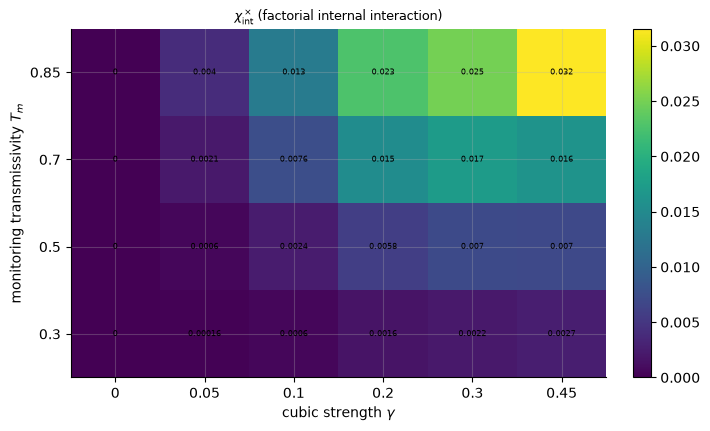

**Fig07_internal_interaction_map.** Mode preflight; 4 reservoir realizations; 1024 (kernels), 512 (stability) trajectories per realization and arm; Fock cutoff D=20; cluster squeezing 12.0 dB; uncertainty: 1.96 x SE (jackknife over path blocks, combined with between-realization SD); exploratory. Factorial adaptive-non-Gaussian internal susceptibility; points with escapes are survivor-conditioned (see table). Primary model: Level A (ideal logical cubic gate; screening model), variant V1.

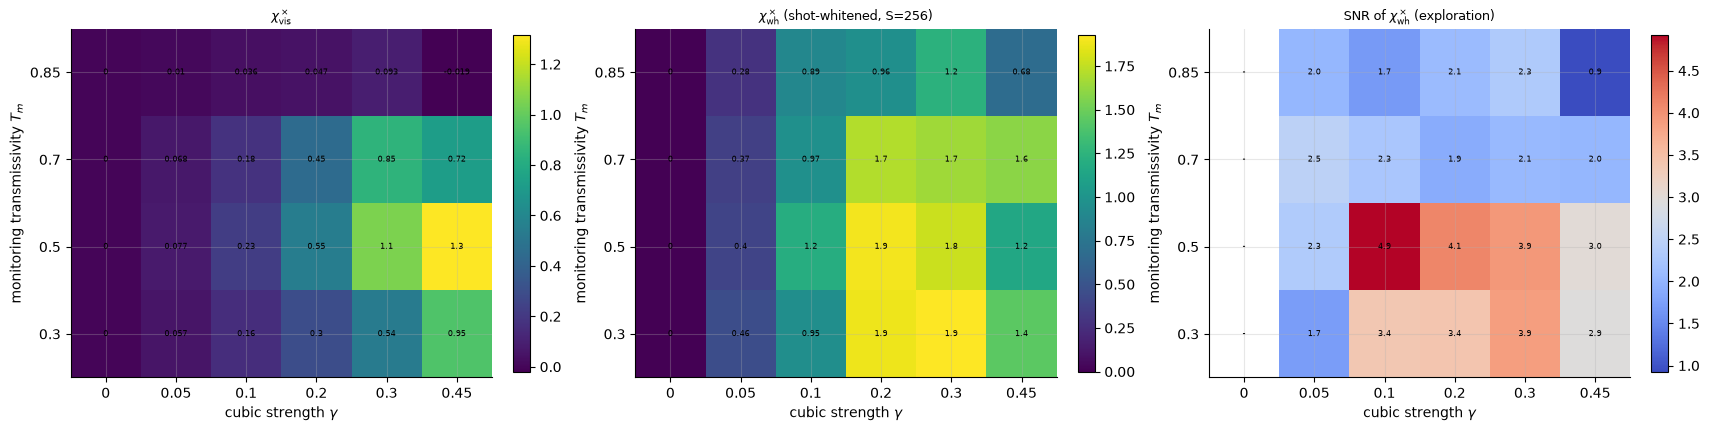

**Fig08_visible_and_whitened_interaction.** Mode preflight; 4 reservoir realizations; 1024 (kernels), 512 (stability) trajectories per realization and arm; Fock cutoff D=20; cluster squeezing 12.0 dB; uncertainty: 1.96 x SE (jackknife over path blocks, combined with between-realization SD); exploratory. Readout-visible and shot-noise-whitened factorial interaction; SNR = estimate / SE. Primary model: Level A (ideal logical cubic gate; screening model), variant V1.

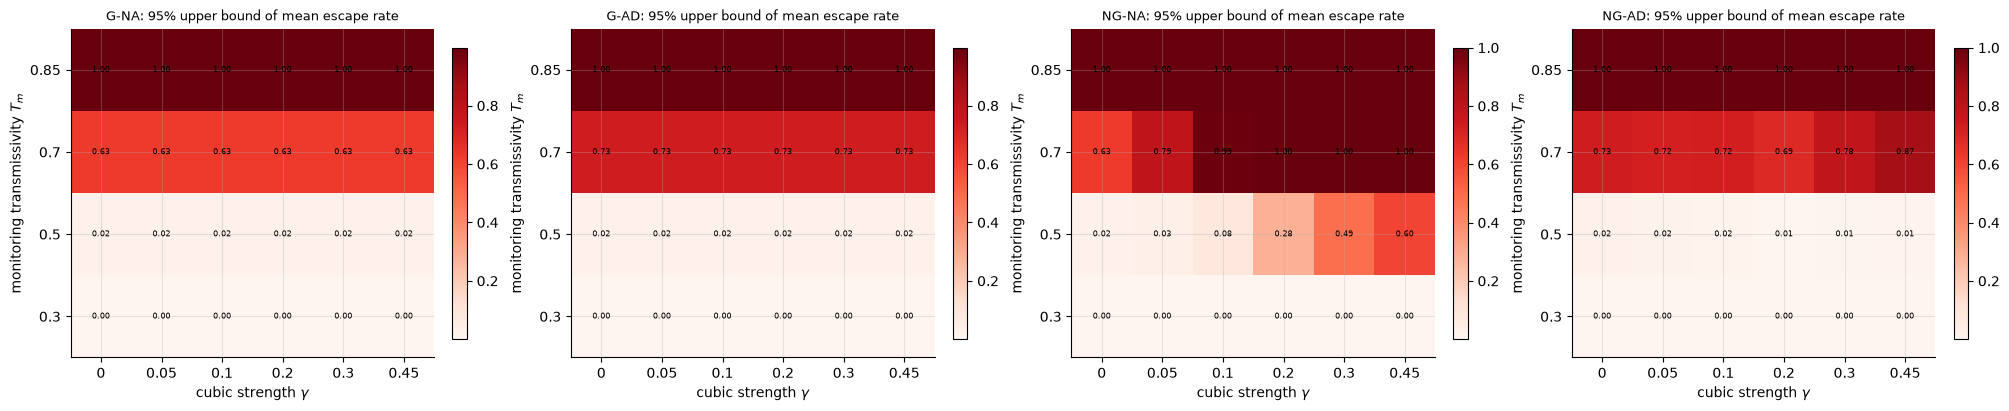

**Fig09_hierarchical_stability_map.** Mode preflight; 4 reservoir realizations; 1024 (kernels), 512 (stability) trajectories per realization and arm; Fock cutoff D=20; cluster squeezing 12.0 dB; uncertainty: 1.96 x SE (jackknife over path blocks, combined with between-realization SD); exploratory. Nested-bootstrap 95% upper bound of the per-realization escape rate (realizations then trajectories; escape: top-two-level population > 0.001 or mean photon number > 0.35D). Admissible = every arm below 0.01. Primary model: Level A (ideal logical cubic gate; screening model), variant V1.

In [30]:
def heat(ax, A, col, title, cmap="viridis", fmt="{:.2g}", log=False):
    piv = A.pivot(index="T", columns="gamma", values=col).astype(float); v = piv.values.copy()
    vv = np.log10(np.clip(np.abs(v), 1e-30, None)) if log else v
    vv = np.where(np.isfinite(vv), vv, np.nan)
    im = ax.imshow(vv, aspect="auto", origin="lower", cmap=cmap)
    ax.set_xticks(range(piv.shape[1]), [f"{x:g}" for x in piv.columns]); ax.set_yticks(range(piv.shape[0]), [f"{x:g}" for x in piv.index])
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            raw = piv.values[i, j]; ax.text(j, i, "-" if not np.isfinite(raw) else fmt.format(raw), ha="center", va="center", fontsize=6)
    ax.set_xlabel(r"cubic strength $\gamma$"); ax.set_ylabel(r"monitoring transmissivity $T_m$"); ax.set_title(title, fontsize=9); plt.colorbar(im, ax=ax, fraction=0.04)

SCAN, SCAN_ROWS, SIGMA_T, BOUNDS = pd.DataFrame(), [], {}, []
if RUN_MODE == "unit" or RESEARCH_BLOCKED:
    print("structural scan not executed:", "unit mode" if RUN_MODE == "unit" else "research mode blocked")
else:
    with section("16.1 calibration per T"):
        for T_ in CFG["T_grid"]:
            SIGMA_T[T_] = STORE.cached("calib", dict(level=PRIMARY["level"], N=1, D=D_A, T=T_, cond=PRIMARY["cond"], n=CFG["n_calib"], cp=CFG["calib_paths"], ck=CFG["calib_clocks"],
                                                     Dr=CFG["D_res"] if PRIMARY["level"] == "B" else None), lambda T_=T_: calibrate_sigma(1, D_A, T_, PRIMARY["level"], cond=PRIMARY["cond"]))
    with section("16.2 structural scan"):
        rids_e = EXPLORATION_SEEDS[:CFG["n_explore"]]
        for T_ in CFG["T_grid"]:
            SCAN_ROWS += run_points(1, D_A, T_, CFG["gamma_grid"], rids_e, level=PRIMARY["level"], variant=VARIANT, cond=PRIMARY["cond"], sigma=SIGMA_T[T_], tag="scan")
            print(f"  T={T_}: {len(SCAN_ROWS)} rows", flush=True)
        ledger_use("structural scan", "exploration", range(CFG["n_explore"]))
        SCAN = pd.DataFrame([summarize_point([r for r in SCAN_ROWS if r["gamma"] == g_ and r["T"] == T_]) for T_ in CFG["T_grid"] for g_ in CFG["gamma_grid"]
                             if any(r["gamma"] == g_ and r["T"] == T_ for r in SCAN_ROWS)])
        SCAN["chi_wh_x_snr"] = SCAN.get("chi_wh_x_snr", np.nan)
        for T_, d in SCAN.groupby("T"):
            d = d.sort_values("gamma"); adm = d.admissible.values; gs = d.gamma.values
            for i in range(len(gs) - 1):
                if adm[i] and not adm[i + 1]:
                    BOUNDS.append(dict(T=T_, interval=(float(gs[i]), float(gs[i + 1])), status="unresolved before instability (escape-defined; no interpolation)"))
            if adm.all():
                BOUNDS.append(dict(T=T_, interval=None, status="no stability boundary inside the scanned gamma range"))
            if not adm.any():
                BOUNDS.append(dict(T=T_, interval=None, status="no admissible point at this T"))
        cols = ["gamma", "T", "admissible"] + [f"esc_upper_{a}" for a in ARMS] + ["chi_int_x", "chi_int_x_snr", "chi_wh_x", "chi_wh_x_snr", "chi_res_x", "ng_rel_entropy_NG-AD",
                                                                                 "purity_uncond_NG-AD", "boundary_final_NG-AD", "rec_info_NG-AD", "shots_needed", "seconds"]
        with pd.option_context("display.width", 260, "display.max_columns", 40, "display.float_format", "{:.3g}".format):
            display(SCAN[[c for c in cols if c in SCAN]])
        display(pd.DataFrame(BOUNDS))
    capS = lambda txt: caption(txt + f" Primary model: {PRIMARY['label']}, variant {VARIANT}.", n_real=CFG["n_explore"], n_traj=f"{CFG['kernel_paths']} (kernels), {CFG['stab_paths']} (stability)", D=D_A)
    fig, ax = plt.subplots(figsize=(7, 4.2)); heat(ax, SCAN, "ng_rel_entropy_NG-AD", "Gaussian-reference entropy of NG-AD conditional states (relative-entropy non-Gaussianity)", "magma")
    show_fig(fig, "Fig05_nongaussianity_map", capS("Non-Gaussianity of the NG-AD conditional logical states (mean over realizations of 16 final states)."))
    fig, ax = plt.subplots(figsize=(7, 4.2)); heat(ax, SCAN, "chi_int_x", r"$\chi^\times_{\rm int}$ (factorial internal interaction)", "viridis")
    show_fig(fig, "Fig07_internal_interaction_map", capS("Factorial adaptive-non-Gaussian internal susceptibility; points with escapes are survivor-conditioned (see table)."))
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
    heat(axs[0], SCAN, "chi_vis_x", r"$\chi^\times_{\rm vis}$", "viridis"); heat(axs[1], SCAN, "chi_wh_x", r"$\chi^\times_{\rm wh}$ (shot-whitened, S=" + str(CFG["shots"]) + ")", "viridis")
    heat(axs[2], SCAN, "chi_wh_x_snr", r"SNR of $\chi^\times_{\rm wh}$ (exploration)", "coolwarm", fmt="{:.1f}")
    show_fig(fig, "Fig08_visible_and_whitened_interaction", capS("Readout-visible and shot-noise-whitened factorial interaction; SNR = estimate / SE."))
    fig, axs = plt.subplots(1, 4, figsize=(20, 4.0))
    for ax, a in zip(axs, ARMS):
        heat(ax, SCAN, f"esc_upper_{a}", f"{a}: 95% upper bound of mean escape rate", "Reds", fmt="{:.2f}")
    show_fig(fig, "Fig09_hierarchical_stability_map", capS(f"Nested-bootstrap 95% upper bound of the per-realization escape rate (realizations then trajectories; escape: top-two-level "
             f"population > {PREREGISTERED['boundary_escape']} or mean photon number > {PREREGISTERED['energy_bound_frac']}D). Admissible = every arm below {PREREGISTERED['escape_upper']}."))

## 17. Independent structural validation and candidate lock

**Selection rule (preregistered).**
1. Shortlist the two admissible, $\gamma>0$ scan points with the largest exploration $\chi^\times_{\rm wh}$.
2. Re-measure both on the **validation bank** (`n_validate` fresh realizations), with the controls:
   * `indep`: correction and feedback driven by an independent path's outcomes;
   * `shift`: the previous clock's outcomes;
   * `iid`: draws from the marginal.
3. Lock the shortlisted point with the largest *validated* $\chi^\times_{\rm wh}$. It must not lie on the grid boundary.
4. Replicate the visible interaction at the second size (two modes coupled by $\mathrm{CZ}(w)$).

No task score is used. The lock (candidate, configuration, code and preregistration hashes, rule) is written into a hashed manifest and printed below.

**Structural-first stopping rule.** The four-arm task pilot (§18) runs only if every condition below holds (`research_dryrun` excepted, control flow only):

| # | condition |
|---|---|
| 1 | native/adapter agreement (E1–E6) |
| 2 | exact nesting (E8) |
| 3 | causal ordering (E12) |
| 4 | Level-A screening passed |
| 5 | non-Gaussianity certified (§13) |
| 6 | cutoff convergence (§13) |
| 7 | density-matrix spectra validated (L1–L6) |
| 8 | $\chi^\times_{\rm int}$ validation SNR ≥ 3 |
| 9 | $\chi^\times_{\rm wh}$ validation SNR ≥ 5 |
| 10 | second-size $\chi^\times_{\rm wh}$ SNR ≥ 3 |
| 11 | controls do not reproduce the response ($\chi^\times_{\rm wh}$ exceeds every control by ≥ 3 combined SE), and $\gamma=0$ is exactly null |
| 12 | response survives the fixed measurement map and the structural ridge ($\chi^\times_{\rm res}/\chi^\times_{\rm vis}\ge0.1$) |
| 13 | candidate locked without task data and not at the grid boundary |
| 14 | hierarchical stability of every arm on the validation bank |
| 15 | physical sample cost below `sample_cost_max_shots` |
| 16 | `research_dryrun` passed with the same code hash |

cutoff convergence at the locked candidate: relative change {'chi_int_x': 0.05588313526498261, 'chi_wh_x': 0.22565463511263426, 'chi_vis_x': 0.4305814414756026}; boundary population {'G-NA': 2.0320513930209253e-16, 'G-AD': 2.0320513930209253e-16, 'NG-NA': 1.4441198020121996e-11, 'NG-AD': 7.454778783047726e-14} -> converged: False
[17.1 structural validation] 1506.4 s | peak RSS 4448 MB


,"gamma=0.3, T=0.3","gamma=0.2, T=0.3",second size (N=2)
admissible,True,True,True
chi_int_x,0.003377,0.002546,0.003913
chi_int_x_snr,8.407,8.316,8.765
chi_wh_x,2.978,3.191,1.525
chi_wh_x_snr,6.624,6.123,3.678
chi_res_x,0.8634,0.7644,0.6369
chi_vis_x,0.9191,0.8009,0.6406
chi_wh_x_indep,0.1221,0.7688,NaN
chi_wh_x_shift,0.5937,2.443,NaN
chi_wh_x_iid,0.1315,0.3707,NaN


LOCK MANIFEST (embedded):
{
 "level": "A",
 "variant": "V1",
 "gamma_star": 0.2,
 "T_star": 0.3,
 "cutoff": 20,
 "second_size": {
  "N": 2,
  "D": 12
 },
 "condition": {
  "squeezing_db": 12.0,
  "enc_scale": 0.6,
  "beta_scale": 0.5,
  "loop_transmissivity": 1.0,
  "layer_efficiency": 1.0,
  "tap_efficiency": 1.0,
  "homodyne_resolution": 0.0,
  "ff_gain_error": 0.0,
  "resource_squeezing_db": 6.0,
  "resource_loss": 1.0,
  "coupling_w": 0.5
 },
 "sigma": {
  "m1": 4.136480915389237,
  "filt": 2.3484251727084082,
  "byp": 4.136480915389237
 },
 "witness_component": [
  1,
  0,
  0
 ],
 "at_grid_boundary": true,
 "shortlist": {
  "(0.3, 0.3)": 2.977733977407846,
  "(0.2, 0.3)": 3.190820837640242
 },
 "selection_rule": "max validated chi_wh^x among the two admissible scan points with the largest exploration chi_wh^x; no task data",
 "config_sha256": "7410e1f02f5d64f246512a171586c14272f547329a278fedeb72df1cb9ce2517",
 "prereg_core_hash": "fbfaf08d8ea623f7be27b2974caf8cde07cc4c22d4e7c5c38

,passed
structural condition,
1 native/adapter agreement (E1-E6),True
2 exact nesting (E8),True
3 causal MBQC ordering (E12),True
4 Level-A screening passed,False
5 non-Gaussianity certified,True
"6 cutoff convergence (<2%, boundary < 1e-5)",False
7 density-matrix spectra validated (L1-L6),True
8 chi_int^x validation SNR >= 3,True
9 chi_wh^x validation SNR >= 5,True


NO-GO (structural stage): 4 Level-A screening passed; 6 cutoff convergence (<2%, boundary < 1e-5); 11 controls do not reproduce the response; gamma=0 exactly null; 13 locked without task data, not at grid boundary | task stage SKIPPED 


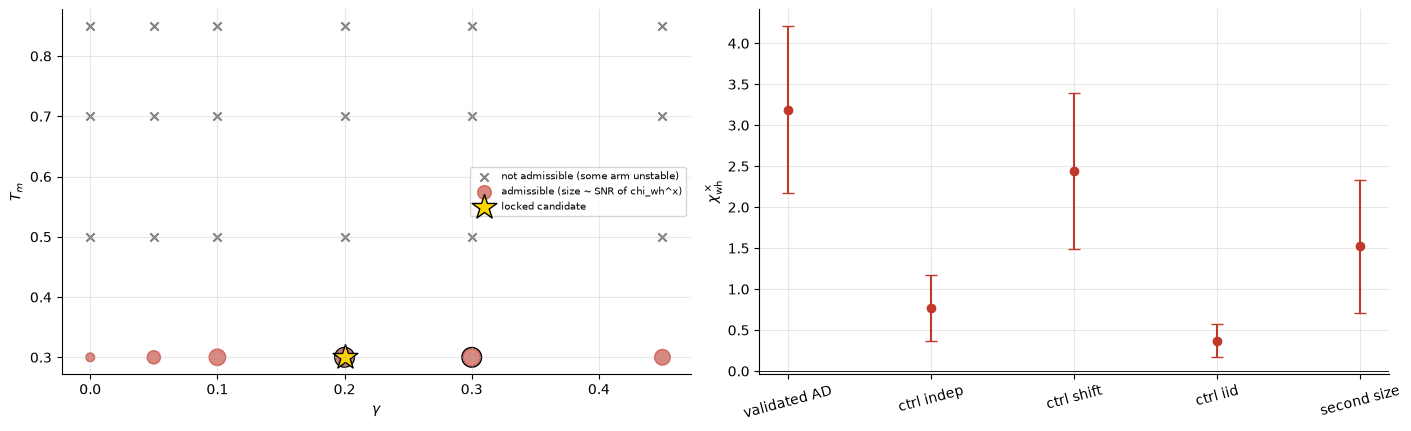

**Fig10_structural_lock.** Mode preflight; 12 (validation) reservoir realizations; 1024 (kernels) trajectories per realization and arm; Fock cutoff D=20; cluster squeezing 12.0 dB; uncertainty: 1.96 x SE (jackknife over path blocks, combined with between-realization SD); independent validation (structural). Independent structural lock: admissible region of the exploration scan, shortlist (circles), locked candidate (star); validation-bank chi_wh^x of the true adaptive correction vs the causal controls and at the second size. NO-GO (structural stage): 4 Level-A screening passed; 6 cutoff convergence (<2%, boundary < 1e-5); 11 controls do not reproduce the response; gamma=0 exactly null; 13 locked without task data, not at grid boundary.

In [31]:
LOCK, VAL, VAL2, STRUCT_COND, SHORT = {}, {}, {}, {}, []
G_STAR = T_STAR = None; WITNESS_COMP = None
crit = {t["id"]: t["passed"] for t in TESTS}
if len(SCAN) and not RESEARCH_BLOCKED:
    cand = SCAN[SCAN.admissible & (SCAN.gamma > 0) & np.isfinite(SCAN.chi_wh_x)].sort_values("chi_wh_x", ascending=False)
    if not len(cand) and RUN_MODE == "research_dryrun":
        cand = SCAN[SCAN.gamma > 0].sort_values("chi_wh_x", ascending=False)                 # dry run: exercise the validation branch (control flow only)
    SHORT = [(float(r.gamma), float(r.T)) for r in cand.head(2).itertuples()]
    with section("17.1 structural validation"):
        for (g_, T_) in SHORT:
            rows = run_points(1, D_A, T_, [g_], VALIDATION_SEEDS[:CFG["n_validate"]], level=PRIMARY["level"], variant=VARIANT, cond=PRIMARY["cond"], sigma=SIGMA_T[T_],
                              ctrls=("indep", "shift", "iid"), tag="validate")
            if rows:
                VAL[(g_, T_)] = summarize_point(rows)
        ledger_use("structural validation", "validation", range(CFG["n_validate"]))
        if VAL:
            (G_STAR, T_STAR) = max(VAL, key=lambda k: VAL[k]["chi_wh_x"] if VAL[k]["admissible"] else -np.inf)
            V_ = VAL[(G_STAR, T_STAR)]
            sig2 = STORE.cached("calib", dict(level=PRIMARY["level"], N=2, D=CFG["D_second"], T=T_STAR, cond=PRIMARY["cond"], n=CFG["n_calib"], cp=CFG["calib_paths"], ck=CFG["calib_clocks"]),
                                lambda: calibrate_sigma(2, CFG["D_second"], T_STAR, PRIMARY["level"], cond=PRIMARY["cond"]))
            rows2 = run_points(2, CFG["D_second"], T_STAR, [G_STAR], VALIDATION_SEEDS[:max(2, CFG["n_validate"] // 2)], level=PRIMARY["level"], variant=VARIANT, cond=PRIMARY["cond"],
                               sigma=sig2, tag="validate2", M=max(128, CFG["kernel_paths"] // 2))
            VAL2 = summarize_point(rows2) if rows2 else {}
            if "comp_wh" in V_:
                WITNESS_COMP = tuple(V_["comps"][int(np.argmax(V_["comp_wh"]))])
            conv_l = []
            for D_ in CFG["cutoffs"]:                                     # cutoff convergence at the locked candidate (repair R4)
                rows_c = run_points(1, D_, T_STAR, [G_STAR], VALIDATION_SEEDS[:2], level=PRIMARY["level"], variant=VARIANT, cond=PRIMARY["cond"], sigma=SIGMA_T[T_STAR], tag="cutoff-lock")
                if rows_c:
                    s_c = summarize_point(rows_c); s_c["D"] = D_; conv_l.append(s_c)
            CONV_LOCK = pd.DataFrame(conv_l)
            if len(CONV_LOCK) >= 2:
                rel_l = {c: float(abs(CONV_LOCK[c].iloc[-1] - CONV_LOCK[c].iloc[-2]) / max(abs(CONV_LOCK[c].iloc[-1]), 1e-300)) for c in ("chi_int_x", "chi_wh_x", "chi_vis_x")}
                bnd_l = {a: float(CONV_LOCK[f"boundary_final_{a}"].iloc[-2]) for a in ARMS if f"boundary_final_{a}" in CONV_LOCK}
                CUTOFF_CONVERGED = all(v < PREREGISTERED["cutoff_rel_change"] for v in rel_l.values()) and all(v < PREREGISTERED["boundary_pop_max"] for v in bnd_l.values())
                CONV_REL, bnd = rel_l, bnd_l
                print(f"cutoff convergence at the locked candidate: relative change {rel_l}; boundary population {bnd_l} -> converged: {CUTOFF_CONVERGED}")
    VAL_DF = pd.DataFrame({f"gamma={k[0]:g}, T={k[1]:g}": {c: v.get(c, np.nan) for c in ("admissible", "chi_int_x", "chi_int_x_snr", "chi_wh_x", "chi_wh_x_snr", "chi_res_x", "chi_vis_x",
                                                                                      "chi_wh_x_indep", "chi_wh_x_shift", "chi_wh_x_iid", "chi_wh_G", "shots_needed")} for k, v in VAL.items()})
    if VAL2:
        VAL_DF["second size (N=2)"] = {c: VAL2.get(c, np.nan) for c in VAL_DF.index}
    with pd.option_context("display.float_format", "{:.4g}".format, "display.width", 250):
        display(VAL_DF)
    if G_STAR is not None:
        gb = (G_STAR in (min(CFG["gamma_grid"]), max(CFG["gamma_grid"]))) or (T_STAR in (min(CFG["T_grid"]), max(CFG["T_grid"])))
        LOCK = dict(level=PRIMARY["level"], variant=VARIANT, gamma_star=G_STAR, T_star=T_STAR, cutoff=D_A, second_size=dict(N=2, D=CFG["D_second"]), condition=PRIMARY["cond"],
                    sigma=SIGMA_T[T_STAR], witness_component=WITNESS_COMP, at_grid_boundary=bool(gb), shortlist={f"{k}": VAL[k]["chi_wh_x"] for k in VAL},
                    selection_rule="max validated chi_wh^x among the two admissible scan points with the largest exploration chi_wh^x; no task data",
                    config_sha256=hashlib.sha256(json.dumps(CFG, sort_keys=True, default=str).encode()).hexdigest(), prereg_core_hash=PREREG_CORE_HASH, prefix_hash=PREFIX_HASH,
                    mode=RUN_MODE)
        LOCK["sha256"] = hashlib.sha256(json.dumps(LOCK, sort_keys=True, default=str).encode()).hexdigest()
        (RES / "lock_manifest_structural.json").write_text(json.dumps(LOCK, indent=1, default=str))
        print("LOCK MANIFEST (embedded):"); print(json.dumps(LOCK, indent=1, default=str))

if RUN_MODE == "research_dryrun" and G_STAR is None and len(SCAN):
    _b = SCAN[SCAN.gamma > 0].sort_values("chi_wh_x", ascending=False).iloc[0]; G_STAR, T_STAR = float(_b.gamma), float(_b["T"])
    print(f"research_dryrun fallback (control flow only): using gamma={G_STAR}, T={T_STAR} although no point passed validation")
GATE_CODE_HASH = code_prefix_hash()
_mk = Path(RESULTS_DIR).resolve() / "research_dryrun" / "dryrun_marker.json"
DRY_OK = RUN_MODE == "research_dryrun" or (_mk.exists() and json.loads(_mk.read_text()).get("code_hash") == GATE_CODE_HASH)
V_ = VAL.get((G_STAR, T_STAR), {}) if G_STAR is not None else {}
def _snr(d, k):
    return d.get(k + "_snr", np.nan) if d else np.nan
ctrl_ok = bool(V_) and all(np.isfinite(V_.get(f"chi_wh_x_{c}", np.nan)) and (V_["chi_wh_x"] - V_[f"chi_wh_x_{c}"]) >= PREREGISTERED["ctrl_margin_se"] *
                           np.sqrt(V_["chi_wh_x_se"] ** 2 + V_[f"chi_wh_x_{c}_se"] ** 2) for c in ("indep", "shift", "iid")) and crit.get("K3a", RUN_MODE == "unit")
STRUCT_COND = {
    "1 native/adapter agreement (E1-E6)": all(crit.get(i, False) for i in ("E1", "E2", "E3", "E4", "E5", "E6")),
    "2 exact nesting (E8)": crit.get("E8", False),
    "3 causal MBQC ordering (E12)": crit.get("E12", False),
    "4 Level-A screening passed": LEVEL_A_PASS is True,
    "5 non-Gaussianity certified": bool(NG_CERTIFIED),
    "6 cutoff convergence (<2%, boundary < 1e-5)": bool(CUTOFF_CONVERGED),
    "7 density-matrix spectra validated (L1-L6)": bool(LYAP_VALID),
    "8 chi_int^x validation SNR >= 3": _snr(V_, "chi_int_x") >= PREREGISTERED["snr_int"],
    "9 chi_wh^x validation SNR >= 5": _snr(V_, "chi_wh_x") >= PREREGISTERED["snr_wh"],
    "10 second size chi_wh^x SNR >= 3": _snr(VAL2, "chi_wh_x") >= PREREGISTERED["snr_second"],
    "11 controls do not reproduce the response; gamma=0 exactly null": ctrl_ok,
    "12 survives measurement map and ridge (chi_res/chi_vis >= 0.1)": bool(V_) and V_.get("chi_vis_x", 0) > 0 and V_.get("chi_res_x", 0) / V_["chi_vis_x"] >= 0.1,
    "13 locked without task data, not at grid boundary": bool(LOCK) and not LOCK.get("at_grid_boundary", True),
    "14 hierarchical stability of every arm (validation bank)": bool(V_) and bool(V_.get("admissible", False)),
    "15 physical sample cost practical": bool(V_) and V_.get("shots_needed", np.inf) <= PREREGISTERED["sample_cost_max_shots"],
    "16 research dry run passed (same code hash)": bool(DRY_OK),
}
STRUCT_ALL = all(STRUCT_COND.values())
RUN_TASK = (STRUCT_ALL or RUN_MODE == "research_dryrun") and RUN_MODE != "unit" and not RESEARCH_BLOCKED
STOP_MSG = ("structural gates passed: task stage enabled" if STRUCT_ALL else "NO-GO (structural stage): " + "; ".join(k for k, v in STRUCT_COND.items() if not v))
display(pd.DataFrame(STRUCT_COND.items(), columns=["structural condition", "passed"]).set_index("structural condition"))
print(STOP_MSG, "| task stage", "RUNS" if RUN_TASK else "SKIPPED", "(control-flow validation only)" if RUN_MODE == "research_dryrun" and not STRUCT_ALL else "")
if len(SCAN):
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
    adm = SCAN[SCAN.admissible]; nad = SCAN[~SCAN.admissible]
    axs[0].scatter(nad.gamma, nad["T"], marker="x", color="gray", label="not admissible (some arm unstable)")
    axs[0].scatter(adm.gamma, adm["T"], s=40 + 300 * np.clip(adm.chi_wh_x_snr.fillna(0) / 10, 0, 1), color=COL["NG-AD"], alpha=0.6, label="admissible (size ~ SNR of chi_wh^x)")
    for (g_, T_) in SHORT:
        axs[0].scatter([g_], [T_], marker="o", s=200, facecolor="none", edgecolor="k")
    if G_STAR is not None:
        axs[0].scatter([G_STAR], [T_STAR], marker="*", s=350, color="gold", edgecolor="k", label="locked candidate")
    axs[0].set_xlabel(r"$\gamma$"); axs[0].set_ylabel(r"$T_m$"); axs[0].legend(fontsize=7)
    if V_:
        labs = ["validated AD", "ctrl indep", "ctrl shift", "ctrl iid"] + (["second size"] if VAL2 else [])
        vals_ = [V_["chi_wh_x"]] + [V_.get(f"chi_wh_x_{c}", np.nan) for c in ("indep", "shift", "iid")] + ([VAL2.get("chi_wh_x", np.nan)] if VAL2 else [])
        errs_ = [V_["chi_wh_x_se"]] + [V_.get(f"chi_wh_x_{c}_se", np.nan) for c in ("indep", "shift", "iid")] + ([VAL2.get("chi_wh_x_se", np.nan)] if VAL2 else [])
        axs[1].errorbar(range(len(labs)), vals_, 1.96 * np.array(errs_), fmt="o", capsize=4, color=COL["NG-AD"]); axs[1].axhline(0, color="k", lw=0.6)
        axs[1].set_xticks(range(len(labs)), labs, rotation=15); axs[1].set_ylabel(r"$\chi^\times_{\rm wh}$")
    show_fig(fig, "Fig10_structural_lock", caption(f"Independent structural lock: admissible region of the exploration scan, shortlist (circles), locked candidate (star); validation-bank "
             f"chi_wh^x of the true adaptive correction vs the causal controls and at the second size. {STOP_MSG}.", n_real=f"{CFG['n_validate']} (validation)",
             n_traj=f"{CFG['kernel_paths']} (kernels)", D=D_A, kind="independent validation (structural)"))

## 18. Four-arm task pilot

The pilot runs only after the structural lock (or in `research_dryrun`), at $(\gamma^\star,T^\star)$.

**Design.**
* `n_pilot` pilot-bank realizations × 2 input sequences. Each realization contributes $S$ = `shots` parallel trajectories per arm, and the per-clock features are the empirical tap-record moments averaged over the $S$ shots.
* All four arms share the input sequence and the uniform innovations (common random numbers).
* The CV-QRC comparator (García-Beni optical loop, $N_{\rm CV}=2$ modes, 3 features) receives the same input and the same shot count.

**Tasks.**
* The **structural witness**, $\tilde P_{\alpha^\star_0}(u_k)\tilde P_{\alpha^\star_1}(u_{k-1})\tilde P_{\alpha^\star_2}(u_{k-2})$, where $\alpha^\star$ is the component with the largest validated whitened factorial weight (from the lock, not from any task).
* **NARMA5** (primary).
* NARMA10, memory capacity (lags 0–15), IPC (degree-2 Legendre capacities, delays ≤ 3), delayed XOR(1,2) and 3-bit parity.

**Readouts.** Matched linear ridge and matched degree-2 (§10.5). There are equal feature counts (3 for every arm), equal shots, equal training data and equal tuning grids, and no postselection anywhere.

**Contrasts** ($P=-$NMSE, or capacity):
* $\Delta_A=P_{\rm NG,AD}-P_{\rm NG,NA}$;
* $\Delta_B=P_{\rm NG,AD}-P_{\rm G,AD}$;
* $\Delta_C=P_{\rm NG,AD}-P_{\rm CV}$;
* $\Delta_{\rm int}=(P_{\rm NG,AD}-P_{\rm NG,NA})-(P_{\rm G,AD}-P_{\rm G,NA})$, together with $\Delta_{\rm G}$ and $\Delta_{\rm NG}$.

The primary family (Holm) is NARMA5 with linear readouts, $\{\Delta_A,\Delta_B,\Delta_C,\Delta_{\rm int}\}$. Everything else is secondary (Benjamini–Hochberg).

**Smallest meaningful effect** (pilot-independent): $\delta_{\min}=\max(0.02,\,3\sigma_0)$, where $\sigma_0$ is the standard deviation of an NMSE difference between two independent null feature sets at research train/test lengths.

In [32]:
def null_nmse_sd(F, Ltr, Lte, sims, seed="delta-null"):
    rng_ = rng_for(seed); diffs = []
    for _ in range(sims):
        K = PAD + Ltr + Lte; u = rng_.uniform(-1, 1, K); y = narma(u, 5)
        diffs.append(readout_nmse(rng_.normal(size=(K, F)), {"w": y}, PAD, Ltr)[0]["w"] - readout_nmse(rng_.normal(size=(K, F)), {"w": y}, PAD, Ltr)[0]["w"])
    return float(np.std(diffs, ddof=1))

def make_targets(u, comp):
    T_ = {}
    if comp is not None:
        w = leg(comp[0], u) * leg(comp[1], lagged(u, 1)) * leg(comp[2], lagged(u, 2)); T_["witness"] = w
    T_["NARMA5"], T_["NARMA10"] = narma(u, 5), narma(u, 10); b = (u > 0).astype(float)
    T_["XOR(1,2)"] = np.logical_xor(lagged(b, 1), lagged(b, 2)).astype(float); T_["parity3"] = ((lagged(b, 0) + lagged(b, 1) + lagged(b, 2)) % 2).astype(float)
    for t in range(16):
        T_[f"mem{t}"] = lagged(u, t)
    for d in range(4):
        T_[f"ipc2_{d}"] = leg(2, lagged(u, d))
    for d1, d2 in itertools.combinations(range(4), 2):
        T_[f"ipc11_{d1}{d2}"] = leg(1, lagged(u, d1)) * leg(1, lagged(u, d2))
    return T_

def performance(nm):
    P = {k: -nm[k] for k in ("witness", "NARMA5", "NARMA10", "XOR(1,2)", "parity3") if k in nm}
    P["MC"] = float(sum(max(0.0, 1 - nm[f"mem{t}"]) for t in range(16)))
    P["IPC2"] = float(sum(max(0.0, 1 - nm[k]) for k in nm if k.startswith("ipc")))
    return P

RCFG = CONFIGS["research"]; F_MAIN = len(feature_index(CFG["N_main"]))
with section("18.1 delta_min"):
    SIGMA0 = null_nmse_sd(F_MAIN, RCFG["train"], RCFG["test"], 40 if RUN_MODE in ("unit", "research_dryrun") else 150)
    DELTA_MIN = max(PREREGISTERED["delta_min_floor"], 3 * SIGMA0)
print(f"sigma_0 = {SIGMA0:.4f} at research lengths (train {RCFG['train']}, test {RCFG['test']}, F={F_MAIN}) -> delta_min = {DELTA_MIN:.4f}")

PILOT, PILOT_RES, PROCEED, SCORES_DF = None, {}, {}, pd.DataFrame()
if RUN_TASK:
    gT = (G_STAR, T_STAR) if G_STAR is not None else (float(BEST["gamma"]) if BEST is not None else CFG["gamma_grid"][-1], float(BEST["T"]) if BEST is not None else CFG["T_grid"][0])
    comp_w = WITNESS_COMP if WITNESS_COMP is not None else (1, 1, 0)
    reps, S, Kt = 2, CFG["shots"], CFG["washout"] + CFG["train"] + CFG["test"]
    sigT = SIGMA_T.get(gT[1]) or calibrate_sigma(1, D_A, gT[1], PRIMARY["level"], cond=PRIMARY["cond"])
    def task_batch(rids):
        base = {r: Reservoir(r, 1, D_A, gT[1], gT[0], level=PRIMARY["level"], variant=VARIANT, cond=PRIMARY["cond"], sigma=sigT, xp=XP) for r in rids}
        blocks = [(r, rep, a) for r in rids for rep in range(reps) for a in ARMS]
        res = stack_reservoirs([base[r] for r, rep, a in blocks], [S] * len(blocks))
        ng = np.concatenate([np.full(S, ARMS[a][0]) for r, rep, a in blocks]); ad = np.concatenate([np.full(S, ARMS[a][1]) for r, rep, a in blocks])
        U = np.concatenate([np.tile(input_sequence(r, 100 + rep, Kt)[:, None], (1, S)) for r, rep, a in blocks], 1)
        parts = {(r, rep): draw_innovations(rng_for("task-inn", r, rep), S, 1, Kt) for r in rids for rep in range(reps)}
        inn = (np.concatenate([parts[(r, rep)][0] for r, rep, a in blocks], 2), np.concatenate([parts[(r, rep)][1] for r, rep, a in blocks], 2))
        o_ = run_paths(res, (XP.asarray(ng), XP.asarray(ad)), U, inn, collect=("feat",), block=S)
        out = {}
        for bi, (r, rep, a) in enumerate(blocks):
            out[(r, rep, a)] = dict(shot=o_["feat"][:, 0, bi], rb=o_["feat"][:, 1, bi], alive_frac=float(o_["alive"][bi * S:(bi + 1) * S].mean()))
        return out
    def score_group(rids):
        feats = task_batch(list(rids)); rows = []
        for rid in rids:
            rows += score_rows(rid, feats)
        return rows
    def score_rows(rid, feats):
        rows = []
        for rep in range(reps):
            u = input_sequence(rid, 100 + rep, Kt); tg = make_targets(u, comp_w); cvr = make_cv(rid, 2, gT[1], PRIMARY["cond"])
            Xcv_exact, covs = cvr.exact(u, return_cov=True); Xcv = cvr.shots(covs, S, rng_for("cvshots", rid, rep))
            models = {a: feats[(rid, rep, a)]["shot"] for a in ARMS}; models["CV"] = Xcv
            models.update({f"{a}_rb": feats[(rid, rep, a)]["rb"] for a in ARMS}); models["CV_exact"] = Xcv_exact
            for m_, X in models.items():
                for fam in ("linear", "degree2"):
                    Xf = X if fam == "linear" else poly2(X, CFG["washout"], CFG["train"], CFG["poly_pca_dim"])
                    nm, lam = readout_nmse(Xf, tg, CFG["washout"], CFG["train"])
                    rows.append(dict(rid=rid, rep=rep, model=m_, family=fam, alive=feats[(rid, rep, m_.replace("_rb", ""))]["alive_frac"] if m_.replace("_rb", "") in ARMS else 1.0,
                                     **performance(nm)))
        return rows
    with section("18.2 task pilot"):
        all_rows = []; prids = PILOT_SEEDS[:CFG["n_pilot"]]
        for gi in range(0, len(prids), 4):
            grp = tuple(prids[gi:gi + 4])
            r_ = STORE.cached("task", dict(rids=grp, g=gT[0], T=gT[1], D=D_A, level=PRIMARY["level"], variant=VARIANT, cond=PRIMARY["cond"], sigma=sigT, S=S, Kt=Kt, reps=reps,
                                           comp=comp_w, cfg=kcfg()), lambda grp=grp: score_group(grp))
            if isinstance(r_, dict) and r_.get("failed"):
                FAILED_UNITS.append(dict(stage="task pilot", rids=grp, reason=r_["reason"], traceback=r_.get("traceback", "")[-400:])); continue
            all_rows += r_
        ledger_use("task pilot", "pilot", range(CFG["n_pilot"]))
    SCORES_DF = pd.DataFrame(all_rows)
    PILOT = SCORES_DF
    def contrast(task, fam, kind):
        piv = SCORES_DF[SCORES_DF.family == fam].pivot_table(index=["rid", "rep"], columns="model", values=task)
        if kind == "A":
            d = piv["NG-AD"] - piv["NG-NA"]
        elif kind == "B":
            d = piv["NG-AD"] - piv["G-AD"]
        elif kind == "C":
            d = piv["NG-AD"] - piv["CV"]
        elif kind == "int":
            d = (piv["NG-AD"] - piv["NG-NA"]) - (piv["G-AD"] - piv["G-NA"])
        elif kind == "G":
            d = piv["G-AD"] - piv["G-NA"]
        else:
            d = piv["NG-AD"] - piv["NG-NA"]
        return d.unstack("rep").values
    rngb = rng_for("pilot-boot")
    if len(SCORES_DF):
        prim = {k: analyse(contrast("NARMA5", "linear", k), DELTA_MIN, CFG["bootstrap"], rngb) for k in ("A", "B", "C", "int")}
        ph = holm([prim[k]["p_one_sided"] for k in prim])
        for k, p_ in zip(prim, ph):
            prim[k]["p_holm"] = float(p_)
        sec = {}
        for task in ("witness", "NARMA5", "NARMA10", "MC", "IPC2", "XOR(1,2)", "parity3"):
            for fam in ("linear", "degree2"):
                for k in ("A", "B", "C", "int", "G"):
                    if task == "NARMA5" and fam == "linear" and k != "G":
                        continue
                    sec[(task, fam, k)] = analyse(contrast(task, fam, k), DELTA_MIN, CFG["bootstrap"], rngb)
        pb = bh([v["p_one_sided"] for v in sec.values()])
        for (kk, v), p_ in zip(sec.items(), pb):
            v["p_bh"] = float(p_)
        PILOT_RES = dict(primary=prim, secondary=sec)
        PRIM_DF = pd.DataFrame(prim).T; display(PRIM_DF[["n_realizations", "mean", "ci_low", "ci_high", "upper95", "p_one_sided", "p_holm", "P_exceeds_delta_min", "max_single_share"]].round(5))
        SEC_DF = pd.DataFrame({f"{t}|{f}|{k}": v for (t, f, k), v in sec.items()}).T
        with pd.option_context("display.max_rows", 80):
            display(SEC_DF[["mean", "ci_low", "ci_high", "p_one_sided", "p_bh"]].round(4))
        means = SCORES_DF.groupby(["family", "model"])[["witness", "NARMA5", "NARMA10", "MC", "IPC2", "XOR(1,2)", "parity3"]].mean()
        with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 250):
            display(means)
        PROCEED = {"Delta_A > 0": prim["A"]["mean"] > 0, "Delta_B > 0": prim["B"]["mean"] > 0, "Delta_C > 0": prim["C"]["mean"] > 0, "Delta_int > 0": prim["int"]["mean"] > 0,
                   "no strong futility (95% upper bounds >= delta_min)": all(prim[k]["upper95"] >= DELTA_MIN for k in prim),
                   "equal postselection, features, shots (by construction)": True,
                   "no escape in the pilot": bool((SCORES_DF.alive >= 1.0).all()),
                   "not driven by one realization": all(prim[k]["max_single_share"] < 0.5 for k in prim),
                   "research dry run passed": bool(DRY_OK)}
        display(pd.DataFrame(PROCEED.items(), columns=["pilot proceed condition", "met"]).set_index("pilot proceed condition"))
        capT = lambda txt, kind="exploratory pilot": caption(txt, n_real=f"{CFG['n_pilot']} x 2 inputs", n_traj=f"{S} shots", D=D_A, unc="95% nested-bootstrap CI", kind=kind)
        for fig_name, task in (("Fig11_four_arm_witness", "witness"), ("Fig12_four_arm_NARMA5", "NARMA5")):
            fig, axs = plt.subplots(1, 2, figsize=(12, 3.9))
            for ax, fam in zip(axs, ("linear", "degree2")):
                d = SCORES_DF[SCORES_DF.family == fam].groupby("model")[task]
                order = ["G-NA", "G-AD", "NG-NA", "NG-AD", "CV"]; mu = [-d.mean()[m_] for m_ in order]; sd = [d.std()[m_] / np.sqrt(d.count()[m_]) for m_ in order]
                ax.bar(order, mu, yerr=1.96 * np.array(sd), color=[COL[m_] for m_ in order], capsize=4); ax.set_ylabel(f"{task} NMSE"); ax.set_title(f"{fam} readout", fontsize=9)
            show_fig(fig, fig_name, capT(f"Four-arm {task} performance at (gamma*, T*)=({gT[0]}, {gT[1]}); bars: mean NMSE over realizations x inputs."))
        fig, ax = plt.subplots(figsize=(9, 3.9)); labs = []
        for i, k in enumerate(("A", "B", "C", "int")):
            r_ = prim[k]; ax.errorbar([i], [r_["mean"]], [[r_["mean"] - r_["ci_low"]], [r_["ci_high"] - r_["mean"]]], fmt="o", capsize=5, color=COL["NG-AD"]); labs.append(f"Delta_{k}")
        ax.axhline(0, color="k", lw=0.6); ax.axhline(DELTA_MIN, color="r", ls=":", label=f"delta_min={DELTA_MIN:.3f}"); ax.set_xticks(range(4), labs); ax.legend(fontsize=7)
        ax.set_ylabel("paired contrast (P = -NMSE, NARMA5, linear)")
        show_fig(fig, "Fig13_factorial_interaction", capT("Primary NARMA5 contrasts with paired 95% nested-bootstrap CIs (Holm-adjusted p-values in the table)."))
else:
    print("task pilot not executed:", STOP_MSG if RUN_MODE != "unit" else "unit mode", "- Figures 11-13 are not generated (no placeholder figures).")

[18.1 delta_min] 2.0 s | peak RSS 4448 MB
sigma_0 = 0.0013 at research lengths (train 6000, test 3000, F=3) -> delta_min = 0.0200
task pilot not executed: NO-GO (structural stage): 4 Level-A screening passed; 6 cutoff convergence (<2%, boundary < 1e-5); 11 controls do not reproduce the response; gamma=0 exactly null; 13 locked without task data, not at grid boundary - Figures 11-13 are not generated (no placeholder figures).


## 19. Conventional CV-QRC comparison

The CV-QRC is the García-Beni optical loop (squeezed-vacuum input encoding, Gaussian loop and readout networks, beam-splitter mixing at $R=T^\star$, loop loss). Its closed-form covariance recursion is checked against native Piquasso Gaussian round trips. It receives the same inputs, the same number of shots and the same number of features (3) as each MB arm. Resource use per clock is tabulated below. The NG arms are the only ones that consume a cubic resource, which is the architectural price of the hypothesis.

In [33]:
with section("19.1 CV-QRC native check"):
    cvt = make_cv(3, 2, 0.5, dict(BASE, loop_transmissivity=0.95, tap_efficiency=0.9)); u19 = rng_for("cv19").uniform(-1, 1, 10); F19 = cvt.exact(u19); sig = np.eye(4); Fn = []
    for k in range(10):
        sig_next, hd = cvt.piquasso_round_trip(sig, u19[k]); Fn.append((hd[0::2, 0::2] + cvt.sig2 * np.eye(2))[cvt.iu]); sig = sig_next
    e19 = float(np.abs(np.array(Fn) - F19).max() / np.abs(F19).max())
    record_test("C1", "engine", "CV-QRC covariance recursion = 10 native Piquasso Gaussian round trips (loss 0.95, detector efficiency 0.9), relative", e19, "< 1e-10", e19 < 1e-10)
display(resource_table(1, PRIMARY["level"]))
if PILOT is not None and len(PILOT):
    order = ["G-NA", "G-AD", "NG-NA", "NG-AD", "CV"]; tasks = ["witness", "NARMA5", "NARMA10", "MC", "IPC2", "XOR(1,2)", "parity3"]
    fig, axs = plt.subplots(1, 2, figsize=(15, 4.2))
    for ax, fam in zip(axs, ("linear", "degree2")):
        m_ = PILOT[PILOT.family == fam].groupby("model")[tasks].mean(); s_ = PILOT[PILOT.family == fam].groupby("model")[tasks].sem()
        for j, mo in enumerate(order):
            ax.bar(np.arange(len(tasks)) + 0.16 * (j - 2), m_.loc[mo] - m_.loc["CV"], 0.16, yerr=1.96 * s_.loc[mo], color=COL[mo], label=mo, capsize=2)
        ax.set_xticks(range(len(tasks)), tasks, rotation=20); ax.axhline(0, color="k", lw=0.6); ax.set_ylabel("P(model) - P(CV-QRC)   (P = -NMSE or capacity)")
        ax.set_title(f"{fam} readout", fontsize=9); ax.legend(fontsize=7)
    show_fig(fig, "Fig14_comparison_with_CV_QRC", caption("Every arm relative to the conventional CV-QRC (equal features, shots, training data and tuning grid).",
             n_real=f"{CFG['n_pilot']} x 2 inputs", n_traj=f"{CFG['shots']} shots", D=D_A, unc="1.96 x SEM over realizations x inputs", kind="exploratory pilot"))
else:
    print("CV-QRC task comparison not executed: the task pilot did not run (", STOP_MSG if RUN_MODE != "unit" else "unit mode", ")")

PASS [C1] (critical) CV-QRC covariance recursion = 10 native Piquasso Gaussian round trips (loss 0.95, detector efficiency 0.9), relative: 5.67e-16 (criterion < 1e-10)
[19.1 CV-QRC native check] 0.2 s | peak RSS 4448 MB


,modes,squeezed_nodes,homodynes,cubic_resources,adaptive_angles,features,note
G-NA,1,2,3,0,0,3,
G-AD,1,2,3,0,1,3,
NG-NA,1,2,3,1,0,3,
NG-AD,1,2,3,1,1,3,
CV-QRC,2,1,1,0,0,3,loop + input ancillas; heterodyne-free x-homod...


CV-QRC task comparison not executed: the task pilot did not run ( NO-GO (structural stage): 4 Level-A screening passed; 6 cutoff convergence (<2%, boundary < 1e-5); 11 controls do not reproduce the response; gamma=0 exactly null; 13 locked without task data, not at grid boundary )


## 20. Robustness and sample complexity

This section runs only for a positive preflight result: a locked candidate that passed every structural gate and the pilot direction conditions. It also always runs in `research_dryrun`, for control flow.

At the locked point each noise axis is varied with the others at the primary condition:
* squeezing, loop loss, detector efficiency, shot budget;
* feed-forward gain error, homodyne resolution;
* Fock cutoff, system size;
* approximate cubic-resource quality (Level B; resource squeezing);
* postselection: none anywhere, so the success probability is 1.

Each setting reports the structural interaction $\chi^\times_{\rm wh}$ (and its SNR), the stability of every arm, and the accepted-shot cost for whitened SNR 5.

To see whether the structural candidate **moves** under noise, $\chi^\times_{\rm wh}$ is also evaluated at the neighbouring grid values of $\gamma$ under the worst setting of each axis.

In [34]:
ROB = pd.DataFrame()
RUN_ROB = (RUN_MODE == "research_dryrun") or (STRUCT_ALL and PROCEED and all(PROCEED.values()))
if RUN_ROB and G_STAR is not None:
    with section("20.1 robustness"):
        axes = [("squeezing_db", CFG["squeezing_grid"]), ("loop_transmissivity", CFG["loss_grid"]), ("layer_efficiency", CFG["eta_grid"]),
                ("ff_gain_error", CFG["ff_grid"]), ("homodyne_resolution", CFG["resolution_grid"])]
        if PRIMARY["level"] == "B":
            axes.append(("resource_squeezing_db", CFG["resource_db_grid"]))
        rob_rows = []; rids_r = ROBUSTNESS_SEEDS[:CFG["robust_n"]]
        gi = CFG["gamma_grid"].index(G_STAR); neigh = [g_ for g_ in CFG["gamma_grid"][max(0, gi - 1):gi + 2] if g_ > 0]
        for key, grid in axes:
            for val in grid:
                cond_r = dict(PRIMARY["cond"], **{key: val})
                if key == "layer_efficiency":
                    cond_r["tap_efficiency"] = val
                worst = val == grid[-1]
                rows = run_points(1, D_A, T_STAR, neigh if worst else [G_STAR], rids_r, level=PRIMARY["level"], variant=VARIANT, cond=cond_r, sigma=SIGMA_T[T_STAR], tag="robust")
                for g_ in (neigh if worst else [G_STAR]):
                    rr = [r for r in rows if r["gamma"] == g_]
                    if rr:
                        s = summarize_point(rr); rob_rows.append(dict(axis=key, value=val, gamma=g_, chi_wh_x=s.get("chi_wh_x"), chi_wh_x_snr=s.get("chi_wh_x_snr"),
                                                                      admissible=s["admissible"], shots_needed=s["shots_needed"]))
        for D_ in CFG["cutoffs"]:
            rows = run_points(1, D_, T_STAR, [G_STAR], rids_r, level=PRIMARY["level"], variant=VARIANT, cond=PRIMARY["cond"], sigma=SIGMA_T[T_STAR], tag="robust")
            if rows:
                s = summarize_point(rows); rob_rows.append(dict(axis="cutoff", value=D_, gamma=G_STAR, chi_wh_x=s.get("chi_wh_x"), chi_wh_x_snr=s.get("chi_wh_x_snr"),
                                                                admissible=s["admissible"], shots_needed=s["shots_needed"]))
        base_chi = VAL.get((G_STAR, T_STAR), {}).get("chi_wh_x", np.nan)
        for S_ in CFG["shots_grid"]:
            rob_rows.append(dict(axis="shots", value=S_, gamma=G_STAR, chi_wh_x=base_chi * S_ / CFG["shots"], chi_wh_x_snr=np.nan, admissible=True,
                                 shots_needed=25.0 * CFG["shots"] / base_chi if base_chi > 0 else np.inf))
        if VAL2:
            rob_rows.append(dict(axis="system size", value=2, gamma=G_STAR, chi_wh_x=VAL2.get("chi_wh_x"), chi_wh_x_snr=VAL2.get("chi_wh_x_snr"), admissible=VAL2.get("admissible"),
                                 shots_needed=VAL2.get("shots_needed")))
        ledger_use("robustness", "robustness", range(CFG["robust_n"]))
        ROB = pd.DataFrame(rob_rows); display(ROB.round(4))
        moves = {}
        for key, grid in axes:
            d = ROB[(ROB.axis == key) & (ROB.value == grid[-1])]
            if len(d):
                moves[key] = float(d.loc[d.chi_wh_x.idxmax(), "gamma"]) if d.chi_wh_x.notna().any() else np.nan
        print("structural argmax over neighbouring gamma under the worst setting of each axis (locked gamma* =", G_STAR, "):", moves)
        fig, axs = plt.subplots(1, 2, figsize=(14, 4.0))
        for key in ROB.axis.unique():
            d = ROB[(ROB.axis == key) & (ROB.gamma == G_STAR)]
            if len(d) > 1 and key != "shots":
                axs[0].plot(np.arange(len(d)), d.chi_wh_x / max(base_chi, 1e-300), "o-", label=key)
        axs[0].set_xlabel("setting index along each axis (primary first)"); axs[0].set_ylabel(r"$\chi^\times_{\rm wh}$ / validated value"); axs[0].legend(fontsize=7)
        d = ROB[ROB.axis == "shots"]; axs[1].loglog(d.value, d.chi_wh_x, "o-"); axs[1].axhline(25, color="r", ls=":", label="whitened SNR 5 (chi_wh = 25)")
        axs[1].set_xlabel("shots per feature estimate S"); axs[1].set_ylabel(r"$\chi^\times_{\rm wh}(S)$ (linear in S)"); axs[1].legend(fontsize=7)
        show_fig(fig, "Fig15_noise_robustness_and_sample_cost", caption("Robustness of the locked structural interaction to each noise axis, and the shot cost (success probability 1: no postselection).",
                 n_real=CFG["robust_n"], n_traj=f"{CFG['kernel_paths']} (kernels)", D=D_A, kind="robustness (exploratory)"))
else:
    print("robustness not executed: no positive preflight result (preregistered: robustness is tested for positive results)" if RUN_MODE != "unit" else "robustness: unit mode")

robustness not executed: no positive preflight result (preregistered: robustness is tested for positive results)


## 21. Prospective power and runtime

**Power.** The per-realization covariance of the four primary contrasts is estimated from the pilot (realization means). Monte-Carlo power of the exact confirmatory analysis (one-sided paired $t$, Holm over four contrasts) is computed for `n_confirm` realizations at $\delta_{\min}$ for every contrast.

**Runtime.** Projected from the measured cost of every unit in this run (kernel and stability seconds per structural point, task seconds per realization group, spectra), scaled linearly in paths × clocks × realizations to the `research` configuration. The conservative estimate is 1.5× the expected value.

In [35]:
POWER, RUNTIME, RUNTIME_OK = {}, {}, False
if PILOT is not None and PILOT_RES:
    with section("21.1 power"):
        mats = []
        for k in ("A", "B", "C", "int"):
            piv = PILOT[PILOT.family == "linear"].pivot_table(index="rid", columns="model", values="NARMA5")
            d = {"A": piv["NG-AD"] - piv["NG-NA"], "B": piv["NG-AD"] - piv["G-AD"], "C": piv["NG-AD"] - piv["CV"], "int": (piv["NG-AD"] - piv["NG-NA"]) - (piv["G-AD"] - piv["G-NA"])}[k]
            mats.append(d.values)
        M_ = np.array(mats).T; cov = np.cov(M_.T) if len(M_) > 1 else np.eye(4) * 1e-4
        pw, pall = power_holm(np.full(4, DELTA_MIN), cov, CFG["n_confirm"] if RUN_MODE == "research" else CONFIGS["research"]["n_confirm"], PREREGISTERED["alpha"],
                              CFG["power_sims"], rng_for("power"))
        pw_obs, pall_obs = power_holm(np.maximum(M_.mean(0), 0), cov, CONFIGS["research"]["n_confirm"], PREREGISTERED["alpha"], CFG["power_sims"], rng_for("power-obs"))
        POWER = dict(at_delta_min=dict(zip(("A", "B", "C", "int"), np.round(pw, 3))), all_at_delta_min=pall, at_pilot_means=dict(zip(("A", "B", "C", "int"), np.round(pw_obs, 3))),
                     all_at_pilot_means=pall_obs)
        print("prospective power (n_confirm =", CONFIGS["research"]["n_confirm"], "):", POWER)
else:
    print("power: not computable - no task pilot (structural stage stopped the workflow)")
with section("21.2 runtime projection"):
    R, Pc = CONFIGS["research"], CFG
    rows_t = [r for r in SCAN_ROWS if "kernel_seconds" in r] + [r for r in (SCREEN_ROWS if "SCREEN_ROWS" in globals() else []) if "kernel_seconds" in r]
    if rows_t:
        k_s = float(np.mean([r["kernel_seconds"] for r in rows_t])); s_s = float(np.mean([r["stab_seconds"] for r in rows_t]))
        kscale = (R["kernel_paths"] * R["kernel_hist"]) / (Pc["kernel_paths"] * Pc["kernel_hist"]); sscale = (R["stab_paths"] * R["stab_clocks"]) / (Pc["stab_paths"] * Pc["stab_clocks"])
        point_h = (k_s * kscale + s_s * sscale) / 3600
        t_task = SECTION_TIMES.get("18.2 task pilot", np.nan) / max(1, Pc["n_pilot"]) * ((R["washout"] + R["train"] + R["test"]) * R["shots"]) / ((Pc["washout"] + Pc["train"] + Pc["test"]) * Pc["shots"])
        RUNTIME = {"stage: calibration": SECTION_TIMES.get("16.1 calibration per T", 0) / 3600 * (R["n_calib"] * R["calib_paths"] * R["calib_clocks"] * len(R["T_grid"])) /
                   max(1, Pc["n_calib"] * Pc["calib_paths"] * Pc["calib_clocks"] * len(Pc["T_grid"])),
                   "stage: Level-A screening": point_h * 3 * len(R["level_a_gammas"]) * R["n_screen"],
                   "stage: structural scan": point_h * len(R["gamma_grid"]) * len(R["T_grid"]) * R["n_explore"],
                   "stage: validation (2 shortlisted, 3 controls) + second size": point_h * 1.75 * 2 * R["n_validate"] + point_h * 4 * R["n_validate"] / 2,
                   "stage: spectra and NG certification": (SECTION_TIMES.get("14.2 spectra at the best point", 0) + SECTION_TIMES.get("13.3 NG certification of reservoir states", 0)) / 3600 *
                   (R["lyap_len"] * R["lyap_traj"]) / max(1, Pc["lyap_len"] * Pc["lyap_traj"]),
                   "stage: task pilot": (t_task * R["n_pilot"] / 3600) if np.isfinite(t_task) else point_h * R["n_pilot"],
                   "stage: confirmation": (t_task * R["n_confirm"] / 3600) if np.isfinite(t_task) else point_h * R["n_confirm"],
                   "stage: robustness": point_h * R["robust_n"] * 25}
        exp_h = float(sum(RUNTIME.values())); RUNTIME["expected (h)"] = exp_h; RUNTIME["conservative (h)"] = 1.5 * exp_h; RUNTIME_OK = 1.5 * exp_h <= AVAILABLE_RUNTIME_HOURS
        try:
            vram = cp.get_default_memory_pool().total_bytes() / 2**30 if DEVICE == "gpu" else 0.0
        except Exception:                                                  # noqa: BLE001
            vram = 0.0
        RUNTIME.update({"peak RAM (GB)": peak_rss_mb() / 1024, "VRAM pool (GB)": vram, "checkpoint size (GB)": STORE.size_mb() / 1024,
                        "free disk (GB)": shutil.disk_usage(RES).free / 2**30, "fits RAM/VRAM/disk": peak_rss_mb() / 1024 < 0.8 * ENV["RAM (GB)"] and shutil.disk_usage(RES).free / 2**30 > 5})
        display(pd.DataFrame(RUNTIME.items(), columns=["research projection", "value"]).set_index("research projection"))
    else:
        print("runtime: no measured structural units in this mode")

power: not computable - no task pilot (structural stage stopped the workflow)


,value
research projection,
stage: calibration,0.484089
stage: Level-A screening,1.176543
stage: structural scan,27.452661
"stage: validation (2 shortlisted, 3 controls) + second size",2.696244
stage: spectra and NG certification,4.957278
stage: task pilot,0.245113
stage: confirmation,0.817043
stage: robustness,8.170435
expected (h),45.999406


[21.2 runtime projection] 0.0 s | peak RSS 4448 MB


## 22. Machine-generated GO / NO-GO decision

* `GO` requires every critical physics, convergence, stability, structural and pilot-direction gate to pass, plus adequate power.
* `CONDITIONAL GO` is possible only when every scientific gate passes and the only failure is a fixable runtime or resource-budget issue.
* `NO-GO` is mandatory on any failed critical gate. This includes, in particular: no internal adaptive–non-Gaussian interaction in the ideal screening; physical-route cutoff failure; vanishing non-Gaussianity; visible-interaction SNR below 5; failure at the second size; instability; a factorial interaction absent while only NG–AD versus G–NA is positive; unequal resources; task-selected candidate; impractical sample cost; failed native validation; inadequate power.

A `GO` justifies a long run. It does not guarantee a positive confirmatory result.

In [36]:
crit = {t["id"]: t["passed"] for t in TESTS}
GATES = []
def gate(group, name, req, ev, status, critical=True):
    GATES.append(dict(group=group, gate=name, requirement=req, evidence=str(ev)[:140], status=status, critical=critical))
P_ = lambda b: "PASS" if b else "FAIL"
NE = "NOT EVALUATED"
if RUN_MODE != "unit":
    V_ = VAL.get((G_STAR, T_STAR), {}) if G_STAR is not None else {}
    gate("physics", "trace / Hermiticity", "< 1e-10", "E7a", P_(crit.get("E7a", False)))
    gate("physics", "minimum eigenvalue", "> -1e-9", "E7b", P_(crit.get("E7b", False)))
    gate("physics", "outcome probabilities normalized", "within 1e-8", "E7c", P_(crit.get("E7c", False)))
    gate("physics", "native / adapter agreement", "< 1e-8 (E4: extrapolated native limit)", "E1-E6", P_(all(crit.get(i, False) for i in ("E1", "E2", "E3", "E4", "E5", "E6"))))
    gate("physics", "causal MBQC ordering", "adaptive angles depend only on earlier outcomes", "E12", P_(crit.get("E12", False)))
    gate("physics", "exact nesting", "bitwise", "E8", P_(crit.get("E8", False)))
    gate("physics", "CPU/GPU agreement", "< 1e-8", f"E11 ({DEVICE})", P_(crit.get("E11", False)) if "E11" in crit else "NOT APPLICABLE (no GPU)", critical="E11" in crit)
    gate("convergence", "cutoff convergence", "< 2% between the two largest cutoffs", f"{CONV_REL if 'CONV_REL' in globals() else '-'}", P_(CUTOFF_CONVERGED))
    bnd_ok = ("bnd" in globals()) and bool(bnd) and all(np.isfinite(v) and v < PREREGISTERED["boundary_pop_max"] for v in bnd.values())
    gate("convergence", "Fock-boundary population", "< 1e-5", f"{bnd if 'bnd' in globals() else '-'}", P_(bnd_ok))
    gate("convergence", "homodyne-quadrature convergence", "E13", "E13", P_(crit.get("E13", False)), critical=False)
    rowS = SCAN[(SCAN.gamma == G_STAR) & (SCAN["T"] == T_STAR)] if (V_ and len(SCAN)) else pd.DataFrame()
    tconv = P_(abs(rowS.chi_wh_x.iloc[0] - V_["chi_wh_x"]) <= 3 * np.hypot(rowS.chi_wh_x_se.iloc[0], V_["chi_wh_x_se"])) if len(rowS) else NE
    gate("convergence", "measurement-trajectory convergence", "exploration vs validation chi_wh^x within 3 combined SE", "lock" if V_ else "-", tconv)
    gate("convergence", "Lyapunov spectra (length, basis, QR interval, perturbation size)", "L1-L4 + length", "L1-L4", P_(LYAP_VALID))
    gate("convergence", "Lyapunov-length convergence", "leading CI exponent spread across independent trajectories < 0.05", f"{LYAP_LEN_OK}",
         P_(LYAP_LEN_OK) if LYAP_LEN_OK is not None else NE, critical=LYAP_LEN_OK is not None)
    gate("convergence", "derivative-step / stencil convergence", "K1, K2", "K1, K2", P_(crit.get("K1", False) and crit.get("K2", False)) if "K2" in crit else NE)
    gate("convergence", "no point silently excluded", "failed units listed; escapes counted", f"{len(FAILED_UNITS)} failed units", P_(len(FAILED_UNITS) == 0))
    gate("structural", "Level-A ideal screening interaction", "chi_int^x, chi_wh^x SNR >= 3 at an admissible point", LEVEL_A_REASON if "LEVEL_A_REASON" in globals() else "-", P_(LEVEL_A_PASS is True))
    if PRIMARY["level"] == "B" or RUN_B:
        gate("structural", "physical cubic teleportation (Level B)", "screening pass rule under BASE_B", f"Level B pass = {LEVEL_B_PASS}", P_(LEVEL_B_PASS is True))
    gate("structural", "non-Gaussianity certified", "> numerical and finite-shot uncertainty", f"{NG_CERTIFIED}", P_(NG_CERTIFIED))
    for k, v in STRUCT_COND.items():
        if k[:2].strip() in ("8", "9", "10", "11", "12", "13", "14", "15"):
            gate("structural", k.split(" ", 1)[1], "", f"{v}", P_(v))
    if PILOT is not None and PROCEED:
        for k in ("Delta_A > 0", "Delta_B > 0", "Delta_C > 0", "Delta_int > 0", "no strong futility (95% upper bounds >= delta_min)", "equal postselection, features, shots (by construction)"):
            gate("pilot", k, "", f"{PROCEED[k]}", P_(PROCEED[k]))
    else:
        for k in ("Delta_A > 0", "Delta_B > 0", "Delta_C > 0", "Delta_int > 0", "no futility"):
            gate("pilot", k, "", "task stage not run (structural stop)", NE)
    gate("feasibility", "prospective confirmatory power", f">= {PREREGISTERED['power_target']}", f"{POWER.get('all_at_delta_min', '-')}",
         P_(bool(POWER) and min(POWER["at_delta_min"].values()) >= PREREGISTERED["power_target"]) if POWER else NE)
    gate("feasibility", "conservative runtime", f"<= {AVAILABLE_RUNTIME_HOURS} h", f"{RUNTIME.get('conservative (h)', np.nan):.1f} h" if RUNTIME else "-", P_(RUNTIME_OK) if RUNTIME else NE, critical=False)
    gate("feasibility", "RAM / VRAM / disk", "fit the machine", f"{RUNTIME.get('peak RAM (GB)', np.nan):.1f} GB RAM" if RUNTIME else "-", P_(RUNTIME.get("fits RAM/VRAM/disk", False)) if RUNTIME else NE, critical=False)
    gate("feasibility", "checkpoint / resume", "N1", "N1", P_(crit.get("N1", False)))
    gate("feasibility", "research dry run, same code hash", "marker matches", f"marker {'found and matching' if DRY_OK else 'missing or mismatched'}", P_(DRY_OK))
    GATE_DF = pd.DataFrame(GATES)
    with pd.option_context("display.max_colwidth", 90, "display.width", 260, "display.max_rows", 80):
        display(GATE_DF)
    crit_fail = GATE_DF[GATE_DF.critical & (GATE_DF.status != "PASS") & (GATE_DF.status != "NOT APPLICABLE (no GPU)")].gate.tolist()
    soft_fail = GATE_DF[(~GATE_DF.critical) & (GATE_DF.status == "FAIL")].gate.tolist()
    if crit_fail:
        DECISION, REASONS = "NO-GO", [f"critical gate failed or not evaluable: {g}" for g in crit_fail]
    elif soft_fail:
        DECISION, REASONS = "CONDITIONAL GO", [f"fixable runtime/resource gate failed: {g}" for g in soft_fail]
    else:
        DECISION, REASONS = "GO", ["every critical gate passed (a long run is scientifically justified; NOT a guarantee of a positive result)"]
    if RUN_MODE == "research_dryrun":
        REASONS.append("research_dryrun: control-flow validation only - this decision is not scientific")
    print(DECISION)
    for r_ in REASONS:
        print(" -", r_)
    (RES / "decision.json").write_text(json.dumps(dict(decision=DECISION, reasons=REASONS, gates=GATES, lock=LOCK, structural=STRUCT_COND, mode=RUN_MODE, prefix_hash=PREFIX_HASH,
                                                       prereg_core_hash=PREREG_CORE_HASH, gate_code_hash=GATE_CODE_HASH), indent=1, default=str))
else:
    DECISION, REASONS, GATE_DF = "not evaluated (unit mode)", [], pd.DataFrame()
    print("unit mode: gates not evaluated (no scientific conclusions)")

,group,gate,requirement,evidence,status,critical
0,physics,trace / Hermiticity,< 1e-10,E7a,PASS,True
1,physics,minimum eigenvalue,> -1e-9,E7b,PASS,True
2,physics,outcome probabilities normalized,within 1e-8,E7c,PASS,True
3,physics,native / adapter agreement,< 1e-8 (E4: extrapolated native limit),E1-E6,PASS,True
4,physics,causal MBQC ordering,adaptive angles depend only on earlier outcomes,E12,PASS,True
5,physics,exact nesting,bitwise,E8,PASS,True
6,physics,CPU/GPU agreement,< 1e-8,E11 (gpu),PASS,True
7,convergence,cutoff convergence,< 2% between the two largest cutoffs,"{'chi_int_x': 0.05588313526498261, 'chi_wh_x': 0.22565463511263426, 'chi_vis_x': 0.430...",FAIL,True
8,convergence,Fock-boundary population,< 1e-5,"{'G-NA': 2.0320513930209253e-16, 'G-AD': 2.0320513930209253e-16, 'NG-NA': 1.4441198020...",PASS,True
9,convergence,homodyne-quadrature convergence,E13,E13,PASS,False


NO-GO
 - critical gate failed or not evaluable: cutoff convergence
 - critical gate failed or not evaluable: Lyapunov-length convergence
 - critical gate failed or not evaluable: Level-A ideal screening interaction
 - critical gate failed or not evaluable: controls do not reproduce the response; gamma=0 exactly null
 - critical gate failed or not evaluable: locked without task data, not at grid boundary
 - critical gate failed or not evaluable: Delta_A > 0
 - critical gate failed or not evaluable: Delta_B > 0
 - critical gate failed or not evaluable: Delta_C > 0
 - critical gate failed or not evaluable: Delta_int > 0
 - critical gate failed or not evaluable: no futility
 - critical gate failed or not evaluable: prospective confirmatory power


## 23. Exact long-run instructions

Printed in full only if the decision is `GO`. Otherwise this section lists the failed gates, their physical consequence and the next scientifically permissible action.

In [37]:
def _failed():
    return [g for g in GATES if g["critical"] and g["status"] not in ("PASS", "NOT APPLICABLE (no GPU)")]
if RUN_MODE == "unit":
    print("unit mode: no instructions (tests only)")
elif DECISION == "GO" and RUN_MODE == "preflight":
    R = CONFIGS["research"]
    print("EXACT INSTRUCTIONS FOR THE 48-72 HOUR RUN\n" + "=" * 44)
    print("1. Cell to edit: 'USER CONTROL PANEL — CHANGE ONLY THIS CELL' (the first code cell, §1).")
    print('2. Line to change:  RUN_MODE = "preflight"   ->   RUN_MODE = "research"   (keep RESUME_FROM_CHECKPOINT = True, seeds, PREREGISTERED unchanged)')
    print(f"3. Locked parameters: level {LOCK['level']}, variant {LOCK['variant']}, gamma* = {LOCK['gamma_star']}, T* = {LOCK['T_star']}, witness component {LOCK['witness_component']}")
    print(f"4. Cutoffs {R['cutoffs']} (main {R['cutoffs'][len(R['cutoffs']) // 2]}), resource cutoff {R['D_res']}; system sizes N = {CFG['N_main']} and {CFG['N_second']} (D = {R['D_second']})")
    print(f"5. Realizations: exploration {R['n_explore']}, validation {R['n_validate']}, pilot {R['n_pilot']}, confirmation {R['n_confirm']}, robustness {R['robust_n']}")
    print(f"6. Trajectories: kernels {R['kernel_paths']} x {R['kernel_hist']} clocks; stability {R['stab_paths']} x {R['stab_clocks']}; task shots {R['shots']}")
    print(f"7. Grids: squeezing {R['squeezing_grid']} dB, loss {R['loss_grid']}, efficiency {R['eta_grid']}, shots {R['shots_grid']}, ff {R['ff_grid']}, resolution {R['resolution_grid']}")
    print(f"8. Runtime: expected {RUNTIME.get('expected (h)', np.nan):.1f} h, conservative {RUNTIME.get('conservative (h)', np.nan):.1f} h; RAM ~{RUNTIME.get('peak RAM (GB)', np.nan):.1f} GB, VRAM ~{RUNTIME.get('VRAM pool (GB)', np.nan):.1f} GB")
    print(f"9. Checkpoints: {Path(CHECKPOINT_DIR).resolve() / 'research'}; results: {Path(RESULTS_DIR).resolve() / 'research'}")
    print("10. Resume: restart the kernel and 'Run all' with RESUME_FROM_CHECKPOINT = True; finished units reload, failed units are retried (test N1).")
    print("11. Rerun after completion: §17 (lock check), §18-§24 (they read the stored units).")
    print(f"12. Hash check: research refuses to start unless results/preflight/decision.json says GO with prefix hash {PREFIX_HASH[:16]} and preregistration hash {PREREG_CORE_HASH[:16]} (§5).")
    print("13. Export: Colab -> File -> Download -> .ipynb; locally File -> Save, or: jupyter nbconvert --to notebook --execute --inplace adaptive_nongaussian_mbqrc_prl_preflight_colab.ipynb")
else:
    print(f"DECISION: {DECISION}" + (" (research_dryrun: control flow only)" if RUN_MODE == "research_dryrun" else ""))
    print("Do not launch the long run with the current configuration.")
    print("\nFailed or non-evaluable critical gates:")
    for g in _failed():
        print(f"  - [{g['group']}] {g['gate']}: {g['evidence']}")
    print("\nPhysical consequence (generated from this run's data):")
    if LEVEL_A_PASS is False and len(SCREEN):
        sv = SCREEN[SCREEN.variant == VARIANT]
        print(f"  - The preregistered Level-A screening (T_m = {T_A}) failed because the nonadaptive control NG-NA is dynamically unstable there: its escape rate is "
              f"{', '.join(f'{g_:g}: {x_:.3f}' for g_, x_ in zip(sv.gamma, sv['esc_rate_NG-NA']))} "
              f"(gamma: rate), against NG-AD {', '.join(f'{x:.3f}' for x in sv['esc_rate_NG-AD'])}. The factorial interaction needs all four arms, so it is undefined there; "
              f"the interaction itself is not absent (chi_int^x SNR {', '.join(f'{x:.1f}' for x in sv['chi_int_x_snr'])}, survivor-conditioned).")
    if len(SCAN):
        adm_T = sorted(SCAN[SCAN.admissible]["T"].unique())
        print(f"  - Admissible region of the structural scan (all four arms stable): T_m in {adm_T if adm_T else 'none'}" + (" - only at the edge of the scanned grid, so the "
              "structural optimum may lie outside the scanned range." if adm_T and adm_T[0] == min(CFG["T_grid"]) and len(adm_T) == 1 else "."))
    if V_:
        print(f"  - At the locked point (gamma*, T*) = ({G_STAR}, {T_STAR}) the factorial interaction is resolved on the independent validation bank: chi_int^x SNR "
              f"{V_.get('chi_int_x_snr', np.nan):.1f}, chi_wh^x = {V_.get('chi_wh_x', np.nan):.2f} (SNR {V_.get('chi_wh_x_snr', np.nan):.1f}), replicated at N = 2 "
              f"(SNR {VAL2.get('chi_wh_x_snr', np.nan):.1f}).")
        for c in ("indep", "shift", "iid"):
            v = V_.get(f"chi_wh_x_{c}", np.nan); se = np.hypot(V_.get("chi_wh_x_se", np.nan), V_.get(f"chi_wh_x_{c}_se", np.nan))
            if np.isfinite(v):
                print(f"    control '{c}': chi_wh^x = {v:.2f} (difference to the true correction {(V_['chi_wh_x'] - v) / se:.1f} combined SE; required >= {PREREGISTERED['ctrl_margin_se']})")
        if not STRUCT_COND.get("11 controls do not reproduce the response; gamma=0 exactly null", True):
            print("    -> a control driven by causally wrong outcomes reproduces most of the interaction, so its specificity to the same-clock causal correction is NOT established.")
    if not CUTOFF_CONVERGED:
        print(f"  - Cutoff convergence at the preregistered 2 % level is not met (relative changes {CONV_REL if 'CONV_REL' in globals() else '-'}); boundary populations are small, "
              "so the changes are dominated by finite-sample noise of the two-realization check rather than by truncation.")
    print("\nNext scientifically permissible action:")
    print("  - Do not retune this architecture on these data. A NEW preregistered exploratory experiment (fresh seed banks) may extend T_m below the present grid edge,")
    print("    use more realizations and larger cutoffs for the convergence check, and sharpen the causal controls; a different non-Gaussian route (e.g. photon")
    print("    subtraction, §3) would also be a new experiment. The present negative screening result stays on record.")
RUN_SUMMARY = dict(mode=RUN_MODE, decision=DECISION, reasons=REASONS, level_A_pass=LEVEL_A_PASS, level_B_pass=LEVEL_B_PASS, variant=VARIANT, lock=LOCK, structural=STRUCT_COND,
                   prefix_hash=PREFIX_HASH, gate_code_hash=GATE_CODE_HASH, prereg_core_hash=PREREG_CORE_HASH, section_times=SECTION_TIMES, failed_units=FAILED_UNITS,
                   tests={t["id"]: t["passed"] for t in TESTS})
(RES / "run_summary.json").write_text(json.dumps(RUN_SUMMARY, indent=1, default=str))
if RUN_MODE == "research_dryrun":
    _mk = Path(RESULTS_DIR).resolve() / "research_dryrun" / "dryrun_marker.json"
    _mk.write_text(json.dumps(dict(code_hash=GATE_CODE_HASH, prefix_hash=PREFIX_HASH, session=SESSION_ID, completed=True)))
    print("research_dryrun completed end to end; marker written:", _mk)
print("FAILED_UNITS:", FAILED_UNITS if FAILED_UNITS else "none")
print(f"total: {(time.perf_counter() - NOTEBOOK_T0) / 60:.1f} min | store: {STORE.hits} reused, {STORE.misses} computed, {STORE.failures} failed, {STORE.size_mb():.1f} MB")

DECISION: NO-GO
Do not launch the long run with the current configuration.

Failed or non-evaluable critical gates:
  - [convergence] cutoff convergence: {'chi_int_x': 0.05588313526498261, 'chi_wh_x': 0.22565463511263426, 'chi_vis_x': 0.4305814414756026}
  - [convergence] Lyapunov-length convergence: False
  - [structural] Level-A ideal screening interaction: no admissible screening point (some arm unstable at every gamma)
  - [structural] controls do not reproduce the response; gamma=0 exactly null: False
  - [structural] locked without task data, not at grid boundary: False
  - [pilot] Delta_A > 0: task stage not run (structural stop)
  - [pilot] Delta_B > 0: task stage not run (structural stop)
  - [pilot] Delta_C > 0: task stage not run (structural stop)
  - [pilot] Delta_int > 0: task stage not run (structural stop)
  - [pilot] no futility: task stage not run (structural stop)
  - [feasibility] prospective confirmatory power: -

Physical consequence (generated from this run's data

## 24. Supported, rejected and untested claims

The claim ladder cannot skip levels: a level is *established* only if every lower level is. Level 14 is never claimed.

,status,evidence
1 implementation validated,established,43/43 tests; critical failures: none
2 physical cubic resource implemented,not pursued (Level-A screening failed),Level B gated by Level A
3 non-Gaussianity certified,blocked (a lower level is not established),NG certified: True
4 adaptive cubic correction validated,blocked (a lower level is not established),"D1-D3 identity, E4 native replay, E8 nesting"
5 Gaussian suppression theorem/bound,bound under restricted assumptions,BOUND ESTABLISHED UNDER EXPLICIT RESTRICTED ASSUMPTIONS
6 interaction generated internally,blocked (a lower level is not established),chi_int^x validation SNR 8.32
7 interaction visible above shot noise,blocked (a lower level is not established),chi_wh^x validation SNR 6.12
8 replicated at a second size,blocked (a lower level is not established),N=2 SNR 3.68
9 independent dynamical crossover,finite-size crossover (numerical observation),4 boundary records; all 'unresolved before instability' or absent
10 witness hierarchy confirmed,requires confirmatory research data,preflight never confirms


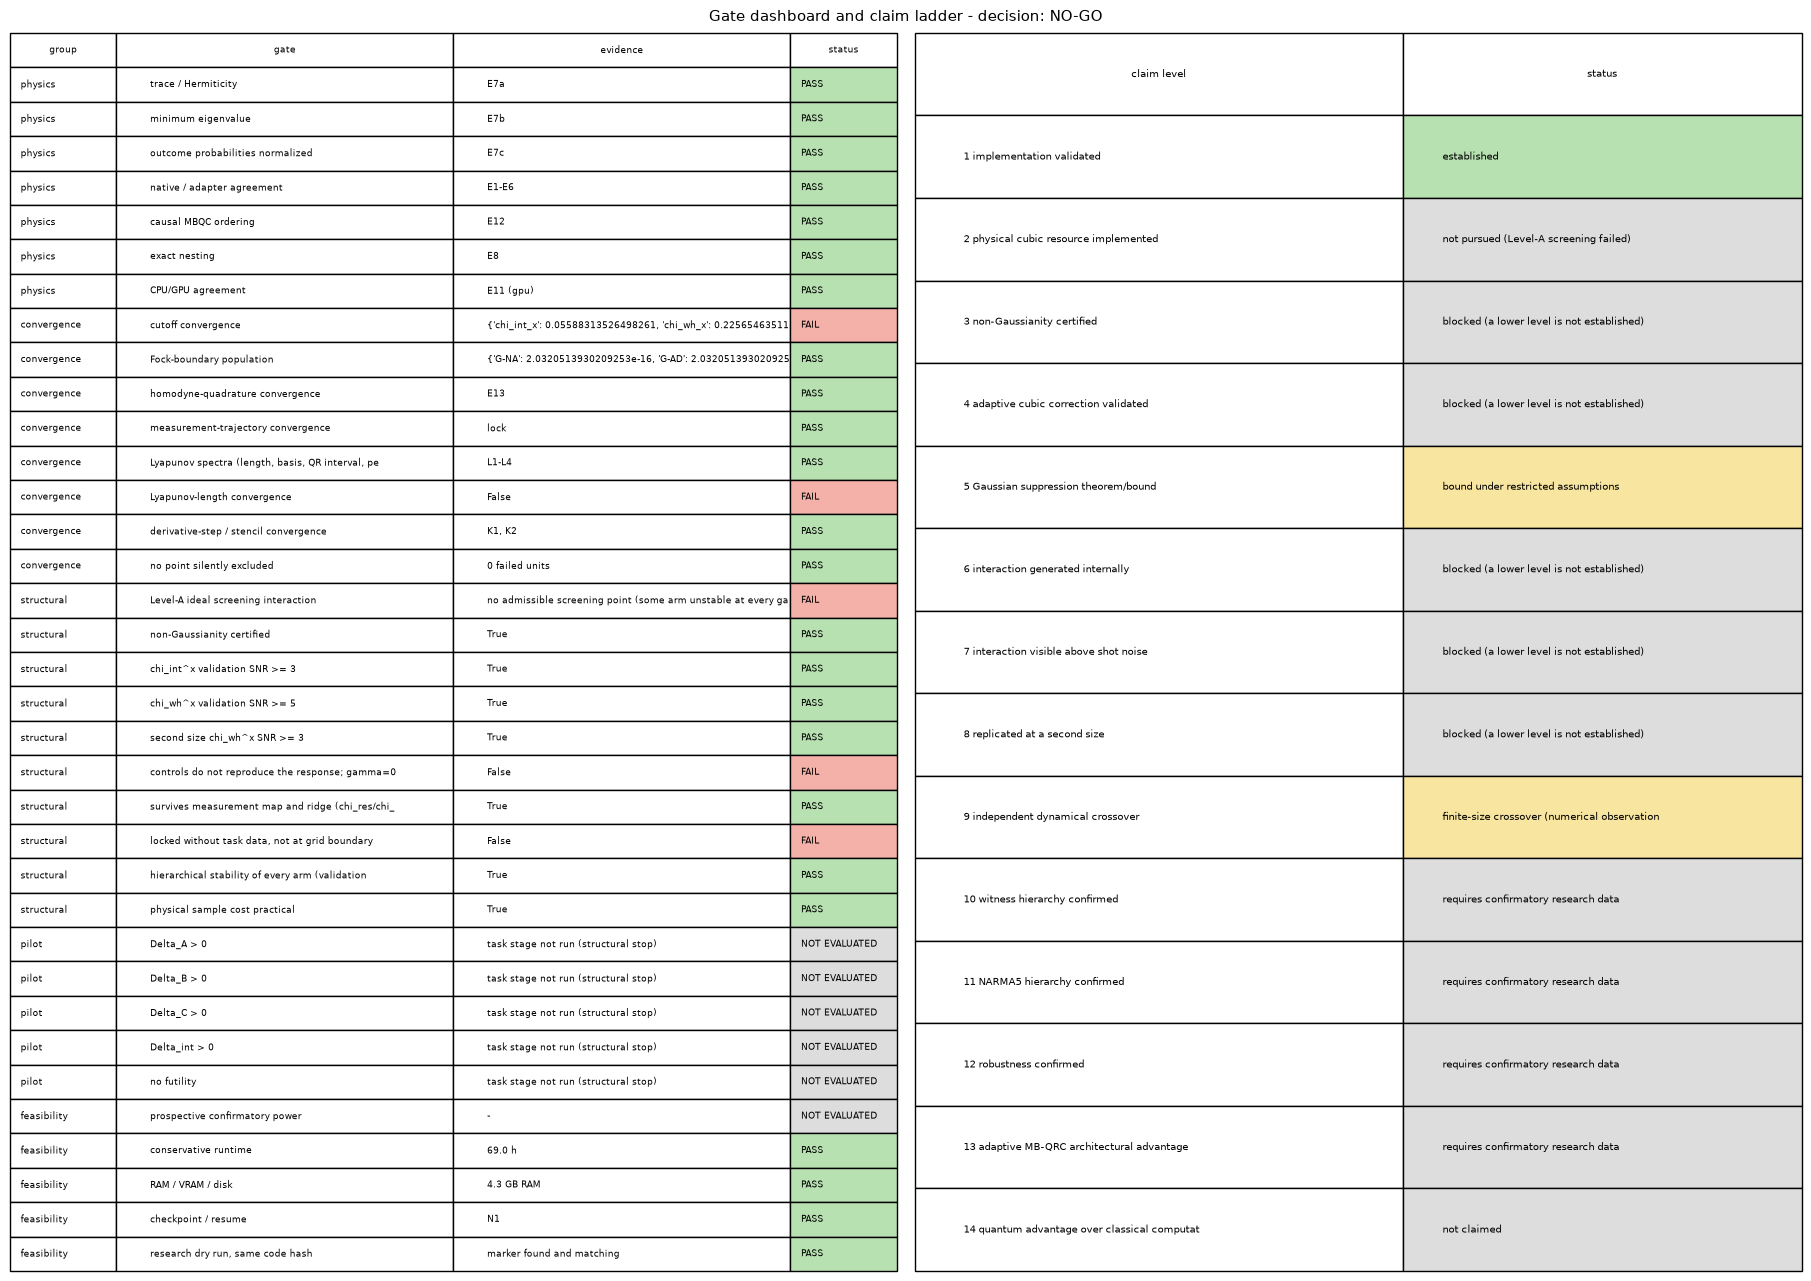

**Fig16_final_gate_and_claim_ladder.** Mode preflight; see §11-§18 reservoir realizations; see §11-§18 trajectories per realization and arm; Fock cutoff D=20; cluster squeezing 12.0 dB; uncertainty: per gate (see table); preflight decision. Machine-generated gates (left) and the claim ladder (right).


## Claims established by executed data
 - Implementation validated: the batched DVR/Fock adapter reproduces native PhotoGraphiQ/Piquasso Fock, mixed-Fock and Gaussian executions of the full clock (four arms, Levels A and B), and the cubic byproduct identity is verified with native gates in both sign conventions (one rejected).
 - Exact nesting holds bitwise: gamma = 0 gives NG == G, disabling the adaptive correction gives NG-AD == NG-NA.
 - Numerical observation: the uncorrected cubic byproduct P(2 gamma m), driven by anti-squeezed teleportation noise, destabilizes NG-NA (escape rate up to 0.40 at the screening points), while the derived adaptive correction keeps NG-AD stable - the correction is a stability requirement, not only a performance knob.
 - Gaussian adaptive suppression: BOUND ESTABLISHED UNDER EXPLICIT RESTRICTED ASSUMPTIONS (angle-sensitivity proposition, §7/§15).
 - The NG-AD conditional logical states are non-Gaussian beyond numerical (cutoff) and finite-sample uncertai

In [38]:
def L_(status, ev):
    return dict(status=status, evidence=str(ev)[:150])
crit = {t["id"]: t["passed"] for t in TESTS}
LAD = {}
V_ = VAL.get((G_STAR, T_STAR), {}) if G_STAR is not None else {}
LAD[1] = L_("established" if all(t["passed"] for t in TESTS if t["critical"]) else "not established", f"{sum(t['passed'] for t in TESTS)}/{len(TESTS)} tests; critical failures: "
            + (", ".join(t["id"] for t in TESTS if t["critical"] and not t["passed"]) or "none"))
LAD[2] = L_("established" if (RUN_B and crit.get("E4", False)) else ("not pursued (Level-A screening failed)" if LEVEL_A_PASS is False else "not evaluated"),
            "native resource_injection replay (E4) + Level-B screening" if RUN_B else "Level B gated by Level A")
LAD[3] = L_("established" if NG_CERTIFIED else "not established", f"NG certified: {NG_CERTIFIED}")
LAD[4] = L_("established" if (crit.get("D1", False) and crit.get("E4", False) and crit.get("E8", False)) else "not established", "D1-D3 identity, E4 native replay, E8 nesting")
LAD[5] = L_({"BOUND ESTABLISHED UNDER EXPLICIT RESTRICTED ASSUMPTIONS": "bound under restricted assumptions"}.get(SUPP_STATUS, SUPP_STATUS.lower()), SUPP_STATUS)
LAD[6] = L_("established" if STRUCT_COND.get("8 chi_int^x validation SNR >= 3", False) else ("screening only" if LEVEL_A_PASS else "not established"),
            f"chi_int^x validation SNR {V_.get('chi_int_x_snr', np.nan):.2f}" if V_ else ("Level-A screening: " + (LEVEL_A_REASON if "LEVEL_A_REASON" in globals() else "not run")))
LAD[7] = L_("established" if STRUCT_COND.get("9 chi_wh^x validation SNR >= 5", False) else "not established", f"chi_wh^x validation SNR {V_.get('chi_wh_x_snr', np.nan):.2f}" if V_ else "no locked point")
LAD[8] = L_("established" if STRUCT_COND.get("10 second size chi_wh^x SNR >= 3", False) else "not established", f"N=2 SNR {VAL2.get('chi_wh_x_snr', np.nan):.2f}" if VAL2 else "not run")
LAD[9] = L_("finite-size crossover (numerical observation)" if BOUNDS else "not established", f"{len(BOUNDS)} boundary records; all 'unresolved before instability' or absent")
for lvl, name in ((10, "witness hierarchy"), (11, "NARMA5 hierarchy"), (12, "robustness"), (13, "adaptive MB-QRC architectural advantage")):
    LAD[lvl] = L_("requires confirmatory research data" if RUN_MODE != "research" else "evaluated in research mode only after confirmation", "preflight never confirms")
LAD[14] = L_("not claimed", "quantum advantage over classical computation is not claimed; Gaussian arms are efficiently classically simulable")
ok = True
for lvl in range(1, 15):
    if not LAD[lvl]["status"].startswith("established"):
        ok = False
    elif not ok:
        LAD[lvl]["status"] = "blocked (a lower level is not established)"
LAD_DF = pd.DataFrame(LAD).T
LAD_DF.index = ["1 implementation validated", "2 physical cubic resource implemented", "3 non-Gaussianity certified", "4 adaptive cubic correction validated",
                "5 Gaussian suppression theorem/bound", "6 interaction generated internally", "7 interaction visible above shot noise", "8 replicated at a second size",
                "9 independent dynamical crossover", "10 witness hierarchy confirmed", "11 NARMA5 hierarchy confirmed", "12 robustness confirmed",
                "13 adaptive MB-QRC architectural advantage", "14 quantum advantage over classical computation"]
with pd.option_context("display.max_colwidth", 150):
    display(LAD_DF)
if RUN_MODE != "unit":
    fig, axs = plt.subplots(1, 2, figsize=(18, 0.32 * max(len(GATES), 14) + 1.5)); colors = {"PASS": "#b7e1b0", "FAIL": "#f4b1a9", NE: "#dddddd"}
    for ax in axs:
        ax.axis("off")
    tb = axs[0].table(cellText=[[g["group"], g["gate"][:48], g["evidence"][:60], g["status"]] for g in GATES], colLabels=["group", "gate", "evidence", "status"],
                      bbox=[0, 0, 1, 1], cellLoc="left", colWidths=[0.12, 0.38, 0.38, 0.12]); tb.auto_set_font_size(False); tb.set_fontsize(6.5)
    for i, g in enumerate(GATES, start=1):
        tb[i, 3].set_facecolor(colors.get(g["status"], "#f8e5a0"))
    tl = axs[1].table(cellText=[[n_[:44], r_["status"][:44]] for n_, r_ in LAD_DF.iterrows()], colLabels=["claim level", "status"], bbox=[0, 0, 1, 1], cellLoc="left", colWidths=[0.55, 0.45])
    tl.auto_set_font_size(False); tl.set_fontsize(7)
    for i, (n_, r_) in enumerate(LAD_DF.iterrows(), start=1):
        tl[i, 1].set_facecolor("#b7e1b0" if r_["status"].startswith("established") else "#dddddd" if "not" in r_["status"] or "requires" in r_["status"] else "#f8e5a0")
    fig.suptitle(f"Gate dashboard and claim ladder - decision: {DECISION}", fontsize=11)
    show_fig(fig, "Fig16_final_gate_and_claim_ladder", caption("Machine-generated gates (left) and the claim ladder (right).", n_real="see §11-§18", n_traj="see §11-§18", D=D_A,
             unc="per gate (see table)", kind="preflight decision" if RUN_MODE == "preflight" else "control flow only" if RUN_MODE == "research_dryrun" else RUN_MODE))
EST, SUG, REJ, UNT = [], [], [], []
if all(t["passed"] for t in TESTS if t["critical"]):
    EST.append("Implementation validated: the batched DVR/Fock adapter reproduces native PhotoGraphiQ/Piquasso Fock, mixed-Fock and Gaussian executions of the full clock "
               "(four arms, Levels A and B), and the cubic byproduct identity is verified with native gates in both sign conventions (one rejected).")
if crit.get("E8", False):
    EST.append("Exact nesting holds bitwise: gamma = 0 gives NG == G, disabling the adaptive correction gives NG-AD == NG-NA.")
if LEVEL_A_PASS is not None:
    (EST if LEVEL_A_PASS else REJ).append(f"Level-A ideal cubic screening ({VARIANT}): {LEVEL_A_REASON}.")
if "SCREEN" in globals() and len(SCREEN):
    nn = SCREEN[[c for c in SCREEN if c.startswith("esc_rate_NG-NA")]].max().max() if any(c.startswith("esc_rate_NG-NA") for c in SCREEN) else np.nan
    EST.append(f"Numerical observation: the uncorrected cubic byproduct P(2 gamma m), driven by anti-squeezed teleportation noise, destabilizes NG-NA (escape rate up to {nn:.2f} at the "
               "screening points), while the derived adaptive correction keeps NG-AD stable - the correction is a stability requirement, not only a performance knob.")
EST.append(f"Gaussian adaptive suppression: {SUPP_STATUS} (angle-sensitivity proposition, §7/§15).")
if NG_CERTIFIED:
    EST.append("The NG-AD conditional logical states are non-Gaussian beyond numerical (cutoff) and finite-sample uncertainty.")
if BOUNDS:
    SUG.append("Stability boundaries in (gamma, T_m) are reported only as intervals 'unresolved before instability'; no phase transition is claimed (finite-size crossover at most).")
if V_:
    (EST if STRUCT_COND.get("9 chi_wh^x validation SNR >= 5") else REJ).append(
        f"Numerical observation in the idealized Level-A model (not ladder-certified, because Level B was not pursued): at (gamma*, T*) = ({G_STAR}, {T_STAR}) the factorial "
        f"adaptive-non-Gaussian interaction is resolved on the independent validation bank (chi_int^x SNR {V_.get('chi_int_x_snr', np.nan):.1f}, chi_wh^x SNR "
        f"{V_.get('chi_wh_x_snr', np.nan):.1f}; N = 2 replication SNR {VAL2.get('chi_wh_x_snr', np.nan):.1f}).")
    if not STRUCT_COND.get("11 controls do not reproduce the response; gamma=0 exactly null", True):
        REJ.append(f"Specificity to the same-clock causal correction: the previous-clock control reaches chi_wh^x = {V_.get('chi_wh_x_shift', np.nan):.2f} vs "
                   f"{V_.get('chi_wh_x', np.nan):.2f}; not separated by {PREREGISTERED['ctrl_margin_se']} combined SE.")
    if LOCK.get("at_grid_boundary"):
        SUG.append(f"The admissible region and the lock lie at the edge of the scanned T_m grid (T* = {T_STAR}); the structural optimum may lie outside the scanned range.")
if PILOT is not None and PILOT_RES:
    p_ = PILOT_RES["primary"]; SUG.append("Pilot (exploratory) NARMA5 contrasts: " + ", ".join(f"Delta_{k} {p_[k]['mean']:+.4f} [{p_[k]['ci_low']:+.4f}, {p_[k]['ci_high']:+.4f}]" for k in p_))
UNT += ["Witness and NARMA5 hierarchies, robustness and architectural advantage: require confirmatory research data (levels 10-13).",
        "Quantum advantage over classical computation: not claimed and not tested."]
for title, lst in (("Claims established by executed data", EST), ("Claims suggested but not established", SUG), ("Claims rejected", REJ), ("Untested claims", UNT)):
    print(f"\n## {title}"); [print(" -", x) for x in lst] if lst else print(" - none")
print(f"\n## Final verdict\n{DECISION}" + (" (control flow only)" if RUN_MODE == "research_dryrun" else ""))
print("Strongest permitted wording if ever established: 'Adaptive non-Gaussian measurement-based reservoir advantage over matched Gaussian, nonadaptive and conventional "
      "CV-QRC architectures' - never 'quantum advantage'.")

## 25. References

1. S. Lloyd, S. L. Braunstein, *Quantum computation over continuous variables*, Phys. Rev. Lett. **82**, 1784 (1999).
2. D. Gottesman, A. Kitaev, J. Preskill, *Encoding a qubit in an oscillator*, Phys. Rev. A **64**, 012310 (2001).
3. M. Gu, C. Weedbrook, N. C. Menicucci, T. C. Ralph, P. van Loock, *Quantum computing with continuous-variable clusters*, Phys. Rev. A **79**, 062318 (2009).
4. K. Miyata, H. Ogawa, P. Marek, R. Filip, H. Yonezawa, J. Yoshikawa, A. Furusawa, *Implementation of a quantum cubic gate by an adaptive non-Gaussian measurement*, Phys. Rev. A **93**, 022301 (2016).
5. S. Ghose, B. C. Sanders, *Non-Gaussian ancilla states for continuous variable quantum computation via Gaussian maps*, J. Mod. Opt. **54**, 855 (2007).
6. M. Yukawa, K. Miyata, H. Yonezawa, P. Marek, R. Filip, A. Furusawa, *Emulating quantum cubic nonlinearity*, Phys. Rev. A **88**, 053816 (2013).
7. S. D. Bartlett, B. C. Sanders, S. L. Braunstein, K. Nemoto, *Efficient classical simulation of continuous variable quantum information processes*, Phys. Rev. Lett. **88**, 097904 (2002).
8. A. Mari, J. Eisert, *Positive Wigner functions render classical simulation of quantum computation efficient*, Phys. Rev. Lett. **109**, 230503 (2012).
9. M. G. Genoni, M. G. A. Paris, K. Banaszek, *Measure of the non-Gaussian character of a quantum state*, Phys. Rev. A **76**, 042327 (2007); M. G. Genoni, M. G. A. Paris, *Quantifying non-Gaussianity for quantum information*, Phys. Rev. A **82**, 052341 (2010).
10. A. Kenfack, K. Życzkowski, *Negativity of the Wigner function as an indicator of non-classicality*, J. Opt. B **6**, 396 (2004).
11. D. E. Browne, M. B. Elliott, S. T. Flammia, S. T. Merkel, A. Miyake, A. J. Short, *Phase transition of computational power in the resource states for one-way quantum computation*, New J. Phys. **10**, 023010 (2008).
12. A. S. Darmawan, G. K. Brennen, S. D. Bartlett, *Measurement-based quantum computation in a two-dimensional phase of matter*, New J. Phys. **14**, 013023 (2012).
13. R. Raussendorf, C. Okay, D.-S. Wang, D. T. Stephen, H. Poulsen Nautrup, *Computationally universal phase of quantum matter*, Phys. Rev. Lett. **122**, 090501 (2019).
14. J. Iaconis, A. Lucas, X. Chen, *Measurement-induced phase transitions in quantum automaton circuits*, Phys. Rev. B **102**, 224311 (2020).
15. K. Mochizuki, R. Hamazaki, *Measurement-induced spectral transition*, Phys. Rev. Lett. **134**, 010410 (2025).
16. Z. Wu *et al.*, *Measurement- and feedback-driven nonequilibrium phase transitions on a quantum processor*, Phys. Rev. Lett. **137**, 010401 (2026).
17. O. Morguí-Sancho, G. L. Giorgi, G. Manzano, R. Zambrini, *General theory of monitored quantum reservoir computing*, arXiv:2607.14311 (2026).
18. J. Cao, R.-Y. Gong, Z. Lin, Y. Zeng, Z.-L. Xiang, *Liouvillian response for temporal information in quantum reservoir computing*, arXiv:2609.23429 (2026).
19. J. García-Beni, G. L. Giorgi, M. C. Soriano, R. Zambrini, *Scalable photonic platform for real-time quantum reservoir computing*, Phys. Rev. Applied **20**, 014051 (2023).
20. J. García-Beni, I. Paparelle, V. Parigi, G. L. Giorgi, M. C. Soriano, R. Zambrini, *Quantum machine learning via continuous-variable cluster states and teleportation*, EPJ Quantum Technol. **12**, 63 (2025).
21. PhotoGraphiQ contributors, *PhotoGraphiQ* (software), commit `6d49da06fa6ede78bf06ea1df07ccfb3b4f5250e`; R. I. Booth, D. Markham, *Flow conditions for continuous variable measurement-based quantum computing*, Quantum **7**, 1146 (2023).
22. Z. Kolarovszki *et al.*, *Piquasso: a photonic quantum computer simulation software platform*, Quantum **9**, 1708 (2025).
23. J. Dambre, D. Verstraeten, B. Schrauwen, S. Massar, *Information processing capacity of dynamical systems*, Sci. Rep. **2**, 514 (2012).
24. G. Benettin, L. Galgani, A. Giorgilli, J.-M. Strelcyn, *Lyapunov characteristic exponents for smooth dynamical systems*, Meccanica **15**, 9 (1980).
25. S. Holm, *A simple sequentially rejective multiple test procedure*, Scand. J. Stat. **6**, 65 (1979); Y. Benjamini, Y. Hochberg, *Controlling the false discovery rate*, J. R. Stat. Soc. B **57**, 289 (1995).
26. C. J. Clopper, E. S. Pearson, *The use of confidence or fiducial limits illustrated in the case of the binomial*, Biometrika **26**, 404 (1934).